In [1]:
# ==========================================================
# Step-1 : Import Required Libraries
# ==========================================================

import os
from pathlib import Path

os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import pandas as pd
import geopandas as gpd
import pyreadstat
import matplotlib.pyplot as plt

from libpysal.weights import KNN


# ==========================================================
# Preprocessing / Splitting
# ==========================================================

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GroupShuffleSplit


# ==========================================================
# Machine-Learning Models
# ==========================================================

from sklearn.linear_model import (
    LogisticRegression,
    SGDClassifier,
)

from sklearn.tree import (
    DecisionTreeClassifier,
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
)

from sklearn.svm import (
    SVC,
)

from sklearn.naive_bayes import (
    GaussianNB,
)


# ==========================================================
# Evaluation Metrics
# ==========================================================

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    roc_curve,
    precision_recall_curve,
)


# ==========================================================
# External Boosting Libraries
# ==========================================================

from xgboost import XGBClassifier

from lightgbm import LGBMClassifier

from catboost import CatBoostClassifier


# ==========================================================
# IMPORTANT
#
# Global SHAP has intentionally been removed.
# GeoShapley is retained later in the spatial
# interpretation section of the notebook.
#
# KNeighborsClassifier has also been removed because
# the present survey-weighted modelling framework requires
# estimators that can use sample_weight during model fitting.
# ==========================================================


print("=" * 70)
print("Spatial Machine Learning Libraries Loaded Successfully")
print("=" * 70)

print(
    "✓ Global warning suppression is NOT enabled."
)

print(
    "✓ Global SHAP is NOT imported."
)

print(
    "✓ GeoShapley remains the spatial interpretation method."
)

print(
    "✓ Survey-weight-compatible candidate models are available."
)

Spatial Machine Learning Libraries Loaded Successfully
✓ Global warning suppression is NOT enabled.
✓ Global SHAP is NOT imported.
✓ GeoShapley remains the spatial interpretation method.
✓ Survey-weight-compatible candidate models are available.


In [2]:
# ==========================================================
# Step-2 : Load Data
#          Central Project Root + Relative Paths
# ==========================================================

from pathlib import Path

import pandas as pd
import geopandas as gpd
import pyreadstat


print("=" * 70)
print("STEP-2 : LOAD DATA")
print("=" * 70)


# ==========================================================
# 1. PROJECT ROOT
#
# Only this line needs to be changed when the project
# is moved to another computer/folder.
# ==========================================================

PROJECT_ROOT = Path(
    r"F:\Thesis"
).expanduser().resolve()

# ==========================================================
# Reviewer-final central output directory
# ==========================================================

from pathlib import Path

OUTPUT_DIR = PROJECT_ROOT / "Reviewer_Final_Outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Reviewer-final output directory:")
print(OUTPUT_DIR)

# ==========================================================
# 2. RELATIVE PROJECT PATHS
# ==========================================================

BDHS_FILE = (
    PROJECT_ROOT
    / "Stunting_Final .SAV"
)

GPS_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "BDGE81FL.shp"
)

ENV_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "bdhs_env_2022.csv"
)

DIVISION_BOUNDARY_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "gadm41_BGD_shp"
    / "gadm41_BGD_1.shp"
)


# ==========================================================
# 3. DISPLAY CONFIGURED PATHS
# ==========================================================

print(
    "\nProject root:"
)

print(
    PROJECT_ROOT
)


print(
    "\nBDHS file:"
)

print(
    BDHS_FILE
)


print(
    "\nGPS file:"
)

print(
    GPS_FILE
)


print(
    "\nEnvironmental file:"
)

print(
    ENV_FILE
)


print(
    "\nDivision boundary file:"
)

print(
    DIVISION_BOUNDARY_FILE
)


# ==========================================================
# 4. REQUIRED FILE AVAILABILITY CHECK
# ==========================================================

print(
    "\n" + "=" * 70
)

print(
    "FILE AVAILABILITY CHECK"
)

print(
    "=" * 70
)


required_files = {

    "BDHS":
        BDHS_FILE,

    "GPS":
        GPS_FILE,

    "ENV":
        ENV_FILE

}


missing_files = []


for file_name, file_path in required_files.items():

    exists = (
        file_path.exists()
    )


    print(

        f"{file_name:<6}: "
        f"{'FOUND' if exists else 'NOT FOUND'}"

    )


    print(
        f"       {file_path}"
    )


    if not exists:

        missing_files.append(
            str(
                file_path
            )
        )


if missing_files:

    raise FileNotFoundError(

        "Required project files were not found.\n\n"

        "Please verify PROJECT_ROOT and the project "
        "folder structure.\n\n"

        "Missing files:\n"
        +
        "\n".join(
            missing_files
        )

    )


print(
    "\n✓ All required analysis files were found."
)


# ==========================================================
# 5. OPTIONAL DIVISION-BOUNDARY CHECK
#
# This file is used later for GeoShapley maps.
# Its absence should not prevent the main ML pipeline
# from loading.
# ==========================================================

if DIVISION_BOUNDARY_FILE.exists():

    print(
        "✓ Bangladesh division-boundary file found."
    )

else:

    print(
        "WARNING: Division-boundary file was not found:"
    )

    print(
        DIVISION_BOUNDARY_FILE
    )

    print(
        "Main ML analysis can continue, but later map "
        "cells requiring this shapefile will fail."
    )


# ==========================================================
# 6. LOAD BDHS ANALYTIC DATASET
# ==========================================================

df, meta = pyreadstat.read_sav(

    str(
        BDHS_FILE
    ),

    apply_value_formats=False

)


# ==========================================================
# 7. LOAD DHS GPS DATA
# ==========================================================

gps = gpd.read_file(

    str(
        GPS_FILE
    )

)


# ==========================================================
# 8. LOAD ENVIRONMENTAL DATA
# ==========================================================

env = pd.read_csv(

    ENV_FILE

)


# ==========================================================
# 9. REQUIRED SURVEY / ID / OUTCOME VARIABLES
# ==========================================================

required_design_vars = [

    "survey_weight",
    "psu",
    "strata_v022",
    "strata_v023",

    "household_id",
    "respondent_id",
    "caseid",

    "child_index",
    "child_line",

    "B19",
    "HW70"

]


missing_design_vars = [

    variable

    for variable
    in required_design_vars

    if variable
    not in df.columns

]


if missing_design_vars:

    raise ValueError(

        "Missing required variables in BDHS dataset:\n"
        f"{missing_design_vars}"

    )


# ==========================================================
# 10. DHS CLUSTER IDENTIFIER CHECK
# ==========================================================

if (

    "dhsclust"
    not in df.columns

    and

    "v001"
    not in df.columns

    and

    "V001"
    not in df.columns

):

    raise ValueError(

        "DHS cluster identifier is missing. "
        "Expected dhsclust, v001, or V001."

    )


# ==========================================================
# 11. SURVEY-WEIGHT VALIDITY CHECK
# ==========================================================

survey_weight_numeric = pd.to_numeric(

    df[
        "survey_weight"
    ],

    errors=
        "coerce"

)


if survey_weight_numeric.isna().any():

    raise ValueError(

        "survey_weight contains missing "
        "or non-numeric values."

    )


if (

    survey_weight_numeric
    .le(
        0
    )
    .any()

):

    raise ValueError(

        "survey_weight contains zero "
        "or negative values."

    )


# ==========================================================
# 12. DATASET SUMMARY
# ==========================================================

print(
    "\n" + "=" * 70
)

print(
    "DATA SUCCESSFULLY LOADED"
)

print(
    "=" * 70
)


print(

    "\nBDHS Dataset Shape :",

    df.shape

)


print(

    "GPS Dataset Shape  :",

    gps.shape

)


print(

    "ENV Dataset Shape  :",

    env.shape

)


# ==========================================================
# 13. SURVEY DESIGN / OUTCOME AUDIT
# ==========================================================

print(
    "\n" + "=" * 70
)

print(
    "SURVEY DESIGN AND OUTCOME VARIABLES"
)

print(
    "=" * 70
)


print(
    "Survey Weight : survey_weight"
)

print(
    "PSU           : psu"
)

print(
    "Strata V022   : strata_v022"
)

print(
    "Strata V023   : strata_v023"
)


if "dhsclust" in df.columns:

    print(
        "Spatial ID    : dhsclust"
    )

elif "v001" in df.columns:

    print(
        "Spatial ID    : v001"
    )

else:

    print(
        "Spatial ID    : V001"
    )


print(
    "Child Age     : B19"
)

print(
    "HAZ Source    : HW70"
)


# ==========================================================
# 14. BASIC VARIABLE CHECK
# ==========================================================

print(
    "\n" + "=" * 70
)

print(
    "BASIC VARIABLE CHECK"
)

print(
    "=" * 70
)


print(

    "Survey-weight minimum :",

    survey_weight_numeric.min()

)


print(

    "Survey-weight maximum :",

    survey_weight_numeric.max()

)


print(

    "Survey-weight mean    :",

    survey_weight_numeric.mean()

)


print(

    "\nB19 non-missing:",

    df[
        "B19"
    ]
    .notna()
    .sum()

)


print(

    "HW70 non-missing:",

    df[
        "HW70"
    ]
    .notna()
    .sum()

)


# ==========================================================
# 15. PREVIEW
# ==========================================================

print(
    "\n" + "=" * 70
)

print(
    "FIRST FIVE ROWS"
)

print(
    "=" * 70
)


display(
    df.head()
)


# ==========================================================
# 16. REPRODUCIBILITY NOTE
# ==========================================================

print(
    "\n✓ All project files are defined relative "
    "to PROJECT_ROOT."
)

print(
    "✓ Individual E:\\ or F:\\ file paths are not "
    "repeated throughout the notebook."
)

print(
    "✓ Moving the project requires changing only "
    "the PROJECT_ROOT configuration."
)

STEP-2 : LOAD DATA
Reviewer-final output directory:
F:\Thesis\Reviewer_Final_Outputs

Project root:
F:\Thesis

BDHS file:
F:\Thesis\Stunting_Final .SAV

GPS file:
F:\Thesis\GPS DATA\Division\BDGE81FL.shp

Environmental file:
F:\Thesis\GPS DATA\bdhs_env_2022.csv

Division boundary file:
F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gadm41_BGD_1.shp

FILE AVAILABILITY CHECK
BDHS  : FOUND
       F:\Thesis\Stunting_Final .SAV
GPS   : FOUND
       F:\Thesis\GPS DATA\Division\BDGE81FL.shp
ENV   : FOUND
       F:\Thesis\GPS DATA\bdhs_env_2022.csv

✓ All required analysis files were found.
✓ Bangladesh division-boundary file found.

DATA SUCCESSFULLY LOADED

BDHS Dataset Shape : (3633, 37)
GPS Dataset Shape  : (674, 21)
ENV Dataset Shape  : (674, 15)

SURVEY DESIGN AND OUTCOME VARIABLES
Survey Weight : survey_weight
PSU           : psu
Strata V022   : strata_v022
Strata V023   : strata_v023
Spatial ID    : dhsclust
Child Age     : B19
HAZ Source    : HW70

BASIC VARIABLE CHECK
Survey-weight minim

,dhsclust,household_id,respondent_id,survey_weight,psu,strata_v022,strata_v023,caseid,child_index,child_line,...,Twin_child,Child_sex,Diarrhea,Fever,Cough,Short_rapid_breaths,Stunting_,B19,Child_age_group,HW70
0,1.0,43.0,3.0,0.156207,1.0,1.0,1.0,1 43 3,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,115.0
1,1.0,85.0,2.0,0.156207,1.0,1.0,1.0,1 85 2,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,46.0,4.0,-34.0
2,1.0,102.0,2.0,0.156207,1.0,1.0,1.0,1 102 2,1.0,5.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,49.0,5.0,-22.0
3,1.0,111.0,2.0,0.156207,1.0,1.0,1.0,1 111 2,1.0,4.0,...,1.0,1.0,0.0,0.0,0.0,0.0,0.0,32.0,3.0,8.0
4,2.0,3.0,2.0,0.141953,2.0,1.0,1.0,2 3 2,1.0,4.0,...,1.0,1.0,0.0,1.0,0.0,0.0,0.0,18.0,2.0,-161.0



✓ All project files are defined relative to PROJECT_ROOT.
✓ Individual E:\ or F:\ file paths are not repeated throughout the notebook.
✓ Moving the project requires changing only the PROJECT_ROOT configuration.


In [3]:
# ==========================================================
# Step-3 : Survey-Design Variable Provenance
#           Original BDHS KR -> Analytic Variables
# ==========================================================

print("=" * 70)
print("SURVEY-DESIGN VARIABLE PROVENANCE")
print("=" * 70)

# ----------------------------------------------------------
# These variables were constructed during the original
# BDHS KR preprocessing as follows:
#
# dhsclust      = V001
# household_id  = V002
# respondent_id = V003
# survey_weight = V005 / 1,000,000
# psu           = V021
# strata_v022   = V022
# strata_v023   = V023
# caseid        = CASEID
# child_index   = BIDX
# child_line    = B16
# ----------------------------------------------------------

SURVEY_DESIGN_PROVENANCE = {

    "dhsclust":
        "V001",

    "household_id":
        "V002",

    "respondent_id":
        "V003",

    "survey_weight":
        "V005 / 1,000,000",

    "psu":
        "V021",

    "strata_v022":
        "V022",

    "strata_v023":
        "V023",

    "caseid":
        "CASEID",

    "child_index":
        "BIDX",

    "child_line":
        "B16"
}


provenance_df = pd.DataFrame(

    SURVEY_DESIGN_PROVENANCE.items(),

    columns=[
        "Analytic_variable",
        "Original_DHS_source"
    ]

)


display(
    provenance_df
)


# ----------------------------------------------------------
# Confirm that the derived variables used by the analysis
# are present in the prepared analytic dataset
# ----------------------------------------------------------

required_survey_design_vars = [

    "dhsclust",
    "household_id",
    "respondent_id",
    "survey_weight",
    "psu",
    "strata_v022",
    "strata_v023",
    "caseid",
    "child_index",
    "child_line"

]


missing_survey_design_vars = [

    variable

    for variable
    in required_survey_design_vars

    if variable
    not in df.columns

]


if missing_survey_design_vars:

    raise ValueError(

        "Missing survey-design / ID variables: "
        f"{missing_survey_design_vars}"

    )


# ----------------------------------------------------------
# Basic validity checks
# ----------------------------------------------------------

if (

    pd.to_numeric(
        df["survey_weight"],
        errors="coerce"
    )
    .isna()
    .any()

):

    raise ValueError(
        "survey_weight contains missing/non-numeric values."
    )


if (

    pd.to_numeric(
        df["survey_weight"],
        errors="coerce"
    )
    .le(0)
    .any()

):

    raise ValueError(
        "survey_weight contains non-positive values."
    )


print(
    "\n✓ Survey-design variable derivation is explicitly documented."
)

print(
    "✓ survey_weight was constructed as V005 / 1,000,000."
)

print(
    "✓ PSU was obtained directly from V021."
)

print(
    "✓ strata_v022 was obtained directly from V022."
)

print(
    "✓ strata_v023 was obtained directly from V023."
)

print(
    "✓ DHS cluster identifier was obtained from V001."
)

print(
    "✓ Survey-design variables are retained for survey-aware "
    "training/evaluation and are not treated as ML predictors."
)

# ==========================================================
# REVIEWER #1 : SURVEY-STRATUM VERIFICATION / AUTO-RECOVERY
# ==========================================================

EXPECTED_OFFICIAL_STRATA = 23

prepared_strata_counts = {
    "strata_v022": int(pd.Series(df["strata_v022"]).nunique(dropna=True)),
    "strata_v023": int(pd.Series(df["strata_v023"]).nunique(dropna=True)),
}

SURVEY_STRATA_VAR = None
STRATA_AUDIT_STATUS = None
raw_kr_audit = []


# ----------------------------------------------------------
# 1. Check prepared file first
# ----------------------------------------------------------

_matching_prepared = [
    k
    for k, v in prepared_strata_counts.items()
    if v == EXPECTED_OFFICIAL_STRATA
]

if len(_matching_prepared) == 1:

    SURVEY_STRATA_VAR = _matching_prepared[0]

    STRATA_AUDIT_STATUS = (
        "VERIFIED_IN_PREPARED_FILE"
    )

elif len(_matching_prepared) > 1:

    SURVEY_STRATA_VAR = "strata_v023"

    STRATA_AUDIT_STATUS = (
        "BOTH_PREPARED_VARIABLES_HAVE_EXPECTED_COUNT"
    )


# ----------------------------------------------------------
# 2. If unresolved, search original KR SAV
# ----------------------------------------------------------

if SURVEY_STRATA_VAR is None:

    try:

        _sav_candidates = [

            p
            for p in PROJECT_ROOT.rglob("*")

            if (
                p.is_file()
                and
                p.suffix.lower() == ".sav"
                and
                "KR" in p.name.upper()
                and
                p.resolve() != BDHS_FILE.resolve()
            )

        ]

        for _p in _sav_candidates:

            try:

                _raw, _raw_meta = pyreadstat.read_sav(

                    str(_p),

                    usecols=[
                        "CASEID",
                        "BIDX",
                        "V022",
                        "V023"
                    ],

                    apply_value_formats=False
                )

                _v022_n = int(
                    _raw["V022"].nunique(dropna=True)
                )

                _v023_n = int(
                    _raw["V023"].nunique(dropna=True)
                )

                _candidate_var = None

                if _v023_n == EXPECTED_OFFICIAL_STRATA:

                    _candidate_var = "V023"

                elif _v022_n == EXPECTED_OFFICIAL_STRATA:

                    _candidate_var = "V022"


                _audit_row = {

                    "File":
                        str(_p),

                    "V022_n_strata":
                        _v022_n,

                    "V023_n_strata":
                        _v023_n,

                    "Candidate_Official_Variable":
                        _candidate_var or "None"
                }


                if _candidate_var is not None:

                    _raw_key = (

                        _raw[
                            [
                                "CASEID",
                                "BIDX",
                                _candidate_var
                            ]
                        ]

                        .copy()

                    )

                    _raw_key["_case_key"] = (

                        _raw_key["CASEID"]

                        .astype(str)

                        .str.strip()

                    )

                    _raw_key["_bidx_key"] = (

                        pd.to_numeric(
                            _raw_key["BIDX"],
                            errors="coerce"
                        )

                        .astype("Int64")

                    )

                    _raw_key = (

                        _raw_key

                        .dropna(
                            subset=[
                                "_case_key",
                                "_bidx_key",
                                _candidate_var
                            ]
                        )

                        .drop_duplicates(
                            subset=[
                                "_case_key",
                                "_bidx_key"
                            ],
                            keep="first"
                        )

                    )


                    _prepared_key = pd.DataFrame({

                        "_case_key":

                            df["caseid"]
                            .astype(str)
                            .str.strip(),

                        "_bidx_key":

                            pd.to_numeric(
                                df["child_index"],
                                errors="coerce"
                            )

                            .astype("Int64")

                    })


                    _mapped = (

                        _prepared_key

                        .merge(

                            _raw_key[
                                [
                                    "_case_key",
                                    "_bidx_key",
                                    _candidate_var
                                ]
                            ],

                            on=[
                                "_case_key",
                                "_bidx_key"
                            ],

                            how="left",

                            validate="many_to_one",

                            sort=False

                        )

                        [_candidate_var]

                    )


                    _audit_row["Prepared_Rows"] = (
                        int(len(df))
                    )

                    _audit_row["Mapped_Rows"] = (
                        int(_mapped.notna().sum())
                    )

                    _audit_row["Mapped_Unique_Strata"] = (
                        int(
                            _mapped.nunique(
                                dropna=True
                            )
                        )
                    )


                    if (

                        _mapped.notna().all()

                        and

                        int(
                            _mapped.nunique(
                                dropna=True
                            )
                        )
                        ==
                        EXPECTED_OFFICIAL_STRATA

                    ):

                        df["official_strata"] = (
                            _mapped.to_numpy()
                        )

                        SURVEY_STRATA_VAR = (
                            "official_strata"
                        )

                        STRATA_AUDIT_STATUS = (

                            "VERIFIED_AND_MAPPED_FROM_RAW_KR:"
                            f"{_candidate_var}"

                        )

                        raw_kr_audit.append(
                            _audit_row
                        )

                        break


                raw_kr_audit.append(
                    _audit_row
                )


            except Exception as exc:

                raw_kr_audit.append({

                    "File":
                        str(_p),

                    "Read_or_Map_Error":
                        str(exc)

                })


    except Exception as exc:

        raw_kr_audit.append({

            "Search_Error":
                str(exc)

        })


# ----------------------------------------------------------
# 3. Do NOT fabricate strata
# ----------------------------------------------------------

if SURVEY_STRATA_VAR is None:

    SURVEY_STRATA_VAR = (
        "strata_v023"
    )

    STRATA_AUDIT_STATUS = (
        "UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR"
    )


strata_verification_rows = [

    {
        "Source":
            "Prepared analytic file",

        "Variable":
            "strata_v022",

        "Unique_Strata":
            prepared_strata_counts[
                "strata_v022"
            ],

        "Reviewer_Expected":
            EXPECTED_OFFICIAL_STRATA
    },

    {
        "Source":
            "Prepared analytic file",

        "Variable":
            "strata_v023",

        "Unique_Strata":
            prepared_strata_counts[
                "strata_v023"
            ],

        "Reviewer_Expected":
            EXPECTED_OFFICIAL_STRATA
    }

]


if "official_strata" in df.columns:

    strata_verification_rows.append({

        "Source":
            "Original KR mapped by CASEID+BIDX",

        "Variable":
            "official_strata",

        "Unique_Strata":
            int(
                df["official_strata"]
                .nunique(
                    dropna=True
                )
            ),

        "Reviewer_Expected":
            EXPECTED_OFFICIAL_STRATA

    })


strata_verification_df = pd.DataFrame(
    strata_verification_rows
)


print("\n" + "=" * 70)
print(
    "REVIEWER #1 — STRATUM VERIFICATION AUDIT"
)
print("=" * 70)

display(
    strata_verification_df
)


if raw_kr_audit:

    print(
        "Original KR audit / mapping attempts:"
    )

    display(
        pd.DataFrame(
            raw_kr_audit
        )
    )


print(
    "Analysis stratum variable:",
    SURVEY_STRATA_VAR
)

print(
    "Audit status:",
    STRATA_AUDIT_STATUS
)


if STRATA_AUDIT_STATUS.startswith(
    "UNRESOLVED"
):

    print(
        "\nWARNING:"
    )

    print(
        "Prepared file does not provide the reviewer-requested "
        "23-stratum count and an appropriate raw KR file could "
        "not be mapped."
    )

    print(
        "No synthetic 23-stratum recode has been created."
    )


strata_verification_df.to_csv(

    OUTPUT_DIR
    /
    "survey_strata_verification.csv",

    index=False

)


if raw_kr_audit:

    pd.DataFrame(
        raw_kr_audit
    ).to_csv(

        OUTPUT_DIR
        /
        "survey_strata_raw_KR_audit.csv",

        index=False

    )

SURVEY-DESIGN VARIABLE PROVENANCE


,Analytic_variable,Original_DHS_source
0,dhsclust,V001
1,household_id,V002
2,respondent_id,V003
3,survey_weight,"V005 / 1,000,000"
4,psu,V021
5,strata_v022,V022
6,strata_v023,V023
7,caseid,CASEID
8,child_index,BIDX
9,child_line,B16



✓ Survey-design variable derivation is explicitly documented.
✓ survey_weight was constructed as V005 / 1,000,000.
✓ PSU was obtained directly from V021.
✓ strata_v022 was obtained directly from V022.
✓ strata_v023 was obtained directly from V023.
✓ DHS cluster identifier was obtained from V001.
✓ Survey-design variables are retained for survey-aware training/evaluation and are not treated as ML predictors.

REVIEWER #1 — STRATUM VERIFICATION AUDIT


,Source,Variable,Unique_Strata,Reviewer_Expected
0,Prepared analytic file,strata_v022,16,23
1,Prepared analytic file,strata_v023,16,23


Original KR audit / mapping attempts:


,File,V022_n_strata,V023_n_strata,Candidate_Official_Variable,Read_or_Map_Error
0,F:\Thesis\BDKR81FL.SAV,16.0,16.0,None,NaN
1,F:\Thesis\SD_BDHS_KR Data.sav,NaN,NaN,NaN,'V022'
2,F:\Thesis\New folder (2)\BDKR81FL.SAV edited_s...,NaN,NaN,NaN,'V022'
3,F:\Thesis\UGC final report\Additional files\KR...,NaN,NaN,NaN,'V022'
4,F:\Thesis\UGC final report\Additional files\KR...,NaN,NaN,NaN,'V022'


Analysis stratum variable: strata_v023
Audit status: UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR

Prepared file does not provide the reviewer-requested 23-stratum count and an appropriate raw KR file could not be mapped.
No synthetic 23-stratum recode has been created.


In [4]:
# ==========================================================
# Step-4 : GPS Cleaning
#          + DHS GPS-Displacement Interpretation Note
# ==========================================================

print("=" * 70)
print("GPS DATA CLEANING")
print("=" * 70)

# ----------------------------------------------------------
# Keep required variables
# ----------------------------------------------------------

gps = gps[
    [
        "DHSCLUST",
        "LATNUM",
        "LONGNUM"
    ]
].copy()

# ----------------------------------------------------------
# Rename
# ----------------------------------------------------------

gps.rename(
    columns={
        "DHSCLUST": "dhsclust",
        "LATNUM": "lat",
        "LONGNUM": "lon"
    },
    inplace=True
)

# ----------------------------------------------------------
# Integer Cluster ID
# ----------------------------------------------------------

gps["dhsclust"] = gps[
    "dhsclust"
].astype(int)

print(
    "Rows :",
    len(gps)
)

print(
    "Unique Clusters :",
    gps["dhsclust"].nunique()
)

# ----------------------------------------------------------
# Missing values
# ----------------------------------------------------------

print("\nMissing Values")

print(
    gps.isna().sum()
)

# ----------------------------------------------------------
# Remove missing coordinates
# ----------------------------------------------------------

gps = gps.dropna(
    subset=[
        "lat",
        "lon"
    ]
)

# ----------------------------------------------------------
# Remove zero coordinates
# ----------------------------------------------------------

gps = gps[
    (gps["lat"] != 0)
    &
    (gps["lon"] != 0)
]

# ----------------------------------------------------------
# Remove duplicate clusters
# ----------------------------------------------------------

gps = gps.drop_duplicates(
    subset="dhsclust"
)

gps = gps.reset_index(
    drop=True
)

print(
    "\nFinal GPS Shape :",
    gps.shape
)

display(
    gps.head()
)

# ==========================================================
# DHS GPS-Displacement Interpretation Note
# ==========================================================

spatial_interpretation_note = (
    "DHS-released cluster coordinates are intentionally "
    "spatially displaced for confidentiality. Therefore, "
    "environmental linkage, nearest-neighbour WX features, "
    "latitude/longitude effects, residual Moran's I, and "
    "GeoShapley spatial patterns must be interpreted as "
    "cluster-level spatial approximations rather than exact "
    "household- or exact cluster-location effects."
)

print("\n")
print("=" * 70)
print("DHS GPS DISPLACEMENT NOTE")
print("=" * 70)

print(
    spatial_interpretation_note
)

GPS DATA CLEANING
Rows : 674
Unique Clusters : 674

Missing Values
dhsclust    0
lat         0
lon         0
dtype: int64

Final GPS Shape : (674, 3)


,dhsclust,lat,lon
0,1,22.717315,90.373835
1,2,22.717246,90.382553
2,3,22.713827,90.383011
3,4,22.698693,90.368405
4,5,22.692715,90.366816




DHS GPS DISPLACEMENT NOTE
DHS-released cluster coordinates are intentionally spatially displaced for confidentiality. Therefore, environmental linkage, nearest-neighbour WX features, latitude/longitude effects, residual Moran's I, and GeoShapley spatial patterns must be interpreted as cluster-level spatial approximations rather than exact household- or exact cluster-location effects.


In [5]:
# ==========================================================
# Step-5 : Environmental Data Cleaning and Quality Assessment
# ==========================================================

# ----------------------------------------------------------
# Standardize Column Names
# ----------------------------------------------------------

env.columns = (

    env.columns

       .str.strip()

       .str.lower()

)

# ----------------------------------------------------------
# Check Required Column
# ----------------------------------------------------------

if "dhsclust" not in env.columns:

    raise ValueError(

        "'dhsclust' column is missing from environmental dataset."

    )

# ----------------------------------------------------------
# Convert Cluster ID
# ----------------------------------------------------------

env["dhsclust"] = env["dhsclust"].astype(int)

# ----------------------------------------------------------
# Dataset Summary
# ----------------------------------------------------------

print("=" * 70)
print("ENVIRONMENTAL DATA SUMMARY")
print("=" * 70)

print("Total Records :", len(env))
print("Total Variables :", env.shape[1])
print("Unique Clusters :", env["dhsclust"].nunique())

# ----------------------------------------------------------
# Missing Value Assessment
# ----------------------------------------------------------

missing_summary = (

    env

    .isnull()

    .sum()

    .sort_values(

        ascending=False

    )

)

missing_summary = missing_summary[
    missing_summary > 0
]

print("\n")

print("=" * 70)
print("MISSING VALUES")
print("=" * 70)

if len(missing_summary) == 0:

    print("No missing values detected.")

else:

    display(

        missing_summary.to_frame(

            name="Missing_Count"

        )

    )

# ----------------------------------------------------------
# Duplicate Cluster Check
# ----------------------------------------------------------

duplicate_clusters = env[

    env.duplicated(

        subset="dhsclust",

        keep=False

    )

]

print("\nDuplicate Cluster Records :", len(duplicate_clusters))

# ----------------------------------------------------------
# Aggregate Duplicate Clusters
# ----------------------------------------------------------

numeric_columns = env.select_dtypes(

    include=np.number

).columns.tolist()

numeric_columns.remove("dhsclust")

env_cluster = (

    env

    .groupby(

        "dhsclust",

        as_index=False

    )[numeric_columns]

    .mean()

)

# ----------------------------------------------------------
# Final Integrity Check
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("AFTER AGGREGATION")
print("=" * 70)

print("Rows :", len(env_cluster))
print("Unique Clusters :", env_cluster["dhsclust"].nunique())

# ----------------------------------------------------------
# Environmental Variable Summary
# ----------------------------------------------------------

print("\n")

print("=" * 70)
print("ENVIRONMENTAL VARIABLES")
print("=" * 70)

display(

    env_cluster.describe().T

)

ENVIRONMENTAL DATA SUMMARY
Total Records : 674
Total Variables : 15
Unique Clusters : 674


MISSING VALUES


,Missing_Count
temperature_celsius,1
relative_humidity_pct,1
soil_moisture,1



Duplicate Cluster Records : 0


AFTER AGGREGATION
Rows : 674
Unique Clusters : 674


ENVIRONMENTAL VARIABLES


,count,mean,std,min,25%,50%,75%,max
dhsclust,674.0,338.281899,195.007130,1.000000,170.250000,338.500000,506.750000,675.000000
rainfall_mm_yr,674.0,2442.368128,720.278624,1524.994444,1910.826775,2285.885667,2802.647905,5259.368516
temperature_celsius,673.0,25.035507,0.559504,23.126007,24.674741,25.172732,25.443346,26.070054
relative_humidity_pct,673.0,76.657445,1.455188,72.935482,75.725966,76.585078,77.558998,81.010406
soil_moisture,673.0,0.304889,0.033163,0.165389,0.289731,0.297886,0.313465,0.405108
ndvi,674.0,0.564288,0.093680,0.243495,0.530325,0.594290,0.623644,0.795394
lst_celsius,674.0,27.543428,0.991875,25.223451,26.861051,27.365814,27.997852,30.808907
elevation_m,674.0,16.992976,15.234229,1.495062,8.351489,13.060197,19.443307,222.665026
slope_degrees,674.0,0.112519,0.235599,0.026846,0.054036,0.066451,0.096606,4.325426
flood_occurrence_pct,674.0,34.571716,23.605938,1.909091,16.223760,27.411555,47.261395,96.299246


In [6]:
# ==========================================================
# Step-6 : Construct Stunting Outcome
#          + Merge BDHS, GPS and Environmental Data
#          + Merge / Attrition Audit
#          + Sample / Cluster Flow Tracking
#          + True Child-ID Duplicate Audit
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 78)
print("STEP-6 : STUNTING OUTCOME + DATA MERGE + FLOW AUDIT")
print("=" * 78)


# ==========================================================
# 0. SAMPLE / CLUSTER FLOW STORAGE
# ==========================================================
# This object is intentionally retained for later reviewer
# reporting of observation- and cluster-level attrition.
# ==========================================================

sample_flow_records = []


# ==========================================================
# 1. STANDARDIZE CORE VARIABLE NAMES
# ==========================================================

rename_map = {}


# ----------------------------------------------------------
# Division
# Avoid creating duplicate conceptual variables
# ----------------------------------------------------------

if (
    "v024" in df.columns
    and
    "division" not in df.columns
    and
    "Division" not in df.columns
):

    rename_map[
        "v024"
    ] = "division"


# ----------------------------------------------------------
# Residence
# ----------------------------------------------------------

if (
    "v025" in df.columns
    and
    "residence" not in df.columns
    and
    "Residence" not in df.columns
):

    rename_map[
        "v025"
    ] = "residence"


# ----------------------------------------------------------
# DHS cluster identifier
# ----------------------------------------------------------

if (
    "dhsclust" not in df.columns
    and
    "v001" in df.columns
):

    rename_map[
        "v001"
    ] = "dhsclust"


if rename_map:

    df = df.rename(
        columns=rename_map
    )


if "dhsclust" not in df.columns:

    raise ValueError(
        "dhsclust is unavailable after conditional renaming."
    )


if (
    "v001" in df.columns
    and
    "dhsclust" in df.columns
):

    print(
        "NOTE: Both dhsclust and v001 are present. "
        "dhsclust is retained as the spatial identifier; "
        "v001 is not used as a model predictor."
    )


df["dhsclust"] = pd.to_numeric(
    df["dhsclust"],
    errors="raise"
).astype(int)


# ==========================================================
# 2. STARTING ANALYTIC-FILE FLOW
# ==========================================================

sample_flow_records.append({

    "Stage":
        "Prepared BDHS analytic file loaded",

    "Observations":
        int(
            len(df)
        ),

    "Unique_Clusters":
        int(
            df["dhsclust"].nunique()
        ),

    "Reason_for_change":
        "Starting prepared BDHS analytic file"

})


print("\n" + "=" * 78)
print("STARTING BDHS DATA")
print("=" * 78)

print(
    "Observations    :",
    len(df)
)

print(
    "Variables       :",
    df.shape[1]
)

print(
    "Unique Clusters :",
    df["dhsclust"].nunique()
)


# ==========================================================
# 3. STUNTING OUTCOME RECONSTRUCTION FROM DHS HW70
# ==========================================================

if (
    "HW70" not in df.columns
    or
    "B19" not in df.columns
):

    raise ValueError(
        "HW70 and B19 are required to reconstruct stunting."
    )


df["HW70"] = pd.to_numeric(
    df["HW70"],
    errors="coerce"
)


df["B19"] = pd.to_numeric(
    df["B19"],
    errors="coerce"
)


# ----------------------------------------------------------
# DHS HW70:
#
# Height-for-age Z-score is stored as Z x 100.
#
# Valid analytical range:
# -600 to +600
#
# DHS special codes:
# 9996 = Height out of plausible limits
# 9997 = Age in days out of plausible limits
# 9998 = Flagged case
# 9999 = Missing
# ----------------------------------------------------------

DHS_HW70_SPECIAL_CODES = [
    9996,
    9997,
    9998,
    9999
]


# ==========================================================
# 4. CHILD AGE ELIGIBILITY
#    DHS B19 = current age of child in completed months
# ==========================================================

valid_child_age = (

    df["B19"]

    .between(
        0,
        59,
        inclusive="both"
    )

)


# ==========================================================
# 5. VALID ANTHROPOMETRIC MEASUREMENT
# ==========================================================

valid_hw70 = (

    df["HW70"]

    .between(
        -600,
        600,
        inclusive="both"
    )

)


# ==========================================================
# 6. FINAL STUNTING ELIGIBILITY
# ==========================================================

valid_stunting_sample = (

    valid_child_age

    &

    valid_hw70

)


# ----------------------------------------------------------
# Store flow BEFORE any row deletion
# ----------------------------------------------------------

eligible_cluster_count = int(

    df.loc[
        valid_stunting_sample,
        "dhsclust"
    ]
    .nunique()

)


sample_flow_records.append({

    "Stage":
        "Eligible child age + valid anthropometry",

    "Observations":
        int(
            valid_stunting_sample.sum()
        ),

    "Unique_Clusters":
        eligible_cluster_count,

    "Reason_for_change":
        "Restricted to children aged 0-59 months with valid HW70 (-600 to +600)"

})


# ==========================================================
# 7. CONVERT HW70 TO CONVENTIONAL HAZ
# ==========================================================

df["HAZ"] = np.nan


df.loc[
    valid_stunting_sample,
    "HAZ"
] = (

    df.loc[
        valid_stunting_sample,
        "HW70"
    ]

    /

    100.0

)


# ==========================================================
# 8. WHO STUNTING DEFINITION
#
# Stunting:
# Height-for-age Z-score < -2 SD
#
# Since HW70 = HAZ x 100:
# HW70 < -200
# ==========================================================

df["stunting"] = np.nan


df.loc[
    valid_stunting_sample,
    "stunting"
] = (

    df.loc[
        valid_stunting_sample,
        "HW70"
    ]

    <
    -200

).astype(int)


# ==========================================================
# 9. OUTCOME-CONSTRUCTION AUDIT
# ==========================================================

print("\n" + "=" * 78)
print("STUNTING OUTCOME CONSTRUCTION AUDIT")
print("=" * 78)


print(
    "Total BDHS rows                  :",
    len(df)
)


print(
    "Children aged 0-59 months        :",
    int(
        valid_child_age.sum()
    )
)


print(
    "Valid HW70 (-600 to +600)        :",
    int(
        valid_hw70.sum()
    )
)


print(
    "Eligible for stunting outcome    :",
    int(
        valid_stunting_sample.sum()
    )
)


print(
    "Excluded for invalid/missing age :",
    int(
        (~valid_child_age).sum()
    )
)


print(
    "Excluded for invalid HW70        :",
    int(
        (~valid_hw70).sum()
    )
)


for code in DHS_HW70_SPECIAL_CODES:

    print(
        f"HW70 special code {code} count        :",
        int(
            (
                df["HW70"]
                ==
                code
            ).sum()
        )
    )


print(
    "\nDerived stunting distribution:"
)


print(

    df["stunting"]

    .value_counts(
        dropna=False
    )

    .sort_index()

)


# ==========================================================
# 10. COMPARE RECONSTRUCTED OUTCOME WITH EXISTING Stunting_
# ==========================================================

if "Stunting_" in df.columns:

    old_stunting = pd.to_numeric(
        df["Stunting_"],
        errors="coerce"
    )


    comparable = (

        old_stunting.notna()

        &

        df["stunting"].notna()

    )


    mismatch_count = int(

        (

            old_stunting.loc[
                comparable
            ]
            .astype(int)

            !=

            df.loc[
                comparable,
                "stunting"
            ]
            .astype(int)

        ).sum()

    )


    print("\n" + "=" * 78)
    print("EXISTING Stunting_ COMPARISON")
    print("=" * 78)


    print(
        "Comparable rows :",
        int(
            comparable.sum()
        )
    )


    print(
        "Mismatches      :",
        mismatch_count
    )


    if mismatch_count == 0:

        print(
            "✓ Reconstructed outcome matches existing "
            "Stunting_ for all comparable observations."
        )

    else:

        print(
            "WARNING: Reconstructed and existing "
            "Stunting_ values differ for some observations."
        )


# ==========================================================
# 11. PRE-MERGE BDHS SUMMARY
# ==========================================================

print("\n" + "=" * 78)
print("BDHS DATA BEFORE SPATIAL / ENVIRONMENTAL MERGE")
print("=" * 78)


print(
    "Observations    :",
    len(df)
)


print(
    "Variables       :",
    df.shape[1]
)


print(
    "Unique Clusters :",
    df["dhsclust"].nunique()
)


# ==========================================================
# 12. GPS INPUT COVERAGE
# ==========================================================

gps_input_cluster_count = int(
    gps["dhsclust"].nunique()
)


bdhs_cluster_set = set(
    df["dhsclust"].unique()
)


gps_cluster_set = set(
    gps["dhsclust"].unique()
)


bdhs_clusters_without_gps = sorted(

    bdhs_cluster_set

    -

    gps_cluster_set

)


print("\n" + "=" * 78)
print("GPS COVERAGE BEFORE MERGE")
print("=" * 78)


print(
    "BDHS clusters                 :",
    len(
        bdhs_cluster_set
    )
)


print(
    "GPS clusters                  :",
    gps_input_cluster_count
)


print(
    "BDHS clusters without GPS     :",
    len(
        bdhs_clusters_without_gps
    )
)


# ==========================================================
# 13. MERGE GPS COORDINATES
# ==========================================================

rows_before_gps_merge = len(df)


df = df.merge(

    gps,

    on="dhsclust",

    how="left",

    validate="many_to_one",

    sort=False

)


rows_after_gps_merge = len(df)


if (
    rows_after_gps_merge
    !=
    rows_before_gps_merge
):

    raise RuntimeError(
        "GPS left merge unexpectedly changed the number "
        "of BDHS observations."
    )


gps_missing_coordinate_mask = (

    df["lat"].isna()

    |

    df["lon"].isna()

)


gps_zero_coordinate_mask = (

    (
        df["lat"] == 0
    )

    |

    (
        df["lon"] == 0
    )

)


gps_invalid_coordinate_mask = (

    gps_missing_coordinate_mask

    |

    gps_zero_coordinate_mask

)


gps_missing_cluster_count = int(

    df.loc[
        gps_invalid_coordinate_mask,
        "dhsclust"
    ]
    .nunique()

)


sample_flow_records.append({

    "Stage":
        "After GPS left merge",

    "Observations":
        int(
            len(df)
        ),

    "Unique_Clusters":
        int(
            df["dhsclust"].nunique()
        ),

    "Reason_for_change":

        (
            "Left merge does not delete observations; "
            f"{gps_missing_cluster_count} clusters have "
            "missing/invalid released GPS coordinates"
        )

})


# ==========================================================
# 14. ENVIRONMENTAL INPUT COVERAGE
# ==========================================================

environmental_columns = [

    column

    for column
    in env_cluster.columns

    if column
    !=
    "dhsclust"

]


env_cluster_set = set(
    env_cluster["dhsclust"].unique()
)


bdhs_clusters_without_environment = sorted(

    bdhs_cluster_set

    -

    env_cluster_set

)


print("\n" + "=" * 78)
print("ENVIRONMENTAL COVERAGE BEFORE MERGE")
print("=" * 78)


print(
    "Environmental clusters              :",
    len(
        env_cluster_set
    )
)


print(
    "BDHS clusters without env record     :",
    len(
        bdhs_clusters_without_environment
    )
)


# ==========================================================
# 15. MERGE ENVIRONMENTAL VARIABLES
# ==========================================================

rows_before_environment_merge = len(df)


df = df.merge(

    env_cluster,

    on="dhsclust",

    how="left",

    validate="many_to_one",

    sort=False

)


rows_after_environment_merge = len(df)


if (
    rows_after_environment_merge
    !=
    rows_before_environment_merge
):

    raise RuntimeError(
        "Environmental left merge unexpectedly changed "
        "the number of BDHS observations."
    )


# ==========================================================
# 16. ENVIRONMENTAL MISSINGNESS AFTER MERGE
# ==========================================================

if environmental_columns:

    environmental_missing_by_variable_df = (

        df[
            environmental_columns
        ]

        .isna()

        .sum()

        .rename(
            "Missing_Count"
        )

        .to_frame()

        .reset_index(
            names="Environmental_Variable"
        )

    )


    environmental_any_missing_mask = (

        df[
            environmental_columns
        ]

        .isna()

        .any(
            axis=1
        )

    )


    total_environmental_missing_cells = int(

        df[
            environmental_columns
        ]

        .isna()

        .sum()

        .sum()

    )


else:

    environmental_missing_by_variable_df = pd.DataFrame(

        columns=[
            "Environmental_Variable",
            "Missing_Count"
        ]

    )


    environmental_any_missing_mask = pd.Series(

        False,

        index=df.index

    )


    total_environmental_missing_cells = 0


environmental_missing_row_count = int(

    environmental_any_missing_mask.sum()

)


environmental_missing_cluster_count = int(

    df.loc[
        environmental_any_missing_mask,
        "dhsclust"
    ]
    .nunique()

)


sample_flow_records.append({

    "Stage":
        "After environmental left merge",

    "Observations":
        int(
            len(df)
        ),

    "Unique_Clusters":
        int(
            df["dhsclust"].nunique()
        ),

    "Reason_for_change":

        (
            "Left merge does not delete observations; "
            f"{environmental_missing_row_count} rows in "
            f"{environmental_missing_cluster_count} clusters "
            "have >=1 missing environmental value"
        )

})


# ==========================================================
# 17. MERGE QUALITY AUDIT
# ==========================================================

print("\n" + "=" * 78)
print("MERGE QUALITY CHECK")
print("=" * 78)


print(
    "Rows after both left merges          :",
    len(df)
)


print(
    "Unique clusters after both merges    :",
    df["dhsclust"].nunique()
)


print(
    "Rows with missing latitude           :",
    int(
        df["lat"].isna().sum()
    )
)


print(
    "Rows with missing longitude          :",
    int(
        df["lon"].isna().sum()
    )
)


print(
    "Rows with missing/invalid GPS         :",
    int(
        gps_invalid_coordinate_mask.sum()
    )
)


print(
    "Clusters with missing/invalid GPS     :",
    gps_missing_cluster_count
)


print(
    "Environmental missing cells           :",
    total_environmental_missing_cells
)


print(
    "Rows with >=1 missing env value       :",
    environmental_missing_row_count
)


print(
    "Clusters with >=1 missing env value   :",
    environmental_missing_cluster_count
)


# ----------------------------------------------------------
# Display environmental missingness by variable
# ----------------------------------------------------------

if (
    len(
        environmental_missing_by_variable_df
    )
    >
    0
):

    environmental_missing_nonzero_df = (

        environmental_missing_by_variable_df

        .loc[
            environmental_missing_by_variable_df[
                "Missing_Count"
            ]
            >
            0
        ]

        .sort_values(
            "Missing_Count",
            ascending=False
        )

        .reset_index(
            drop=True
        )

    )


    if len(
        environmental_missing_nonzero_df
    ):

        print(
            "\nEnvironmental missingness by variable:"
        )

        display(
            environmental_missing_nonzero_df
        )

    else:

        print(
            "\nNo missing environmental values "
            "after cluster linkage."
        )


else:

    environmental_missing_nonzero_df = (

        environmental_missing_by_variable_df.copy()

    )


# ==========================================================
# 18. CLUSTER-LEVEL MERGE PROBLEM AUDIT
# ==========================================================

merge_problem_flags_df = pd.DataFrame({

    "dhsclust":
        df["dhsclust"],

    "Missing_or_Invalid_GPS":
        gps_invalid_coordinate_mask.astype(int),

    "Any_Missing_Environment":
        environmental_any_missing_mask.astype(int)

})


merge_missing_clusters_df = (

    merge_problem_flags_df

    .groupby(
        "dhsclust",
        as_index=False
    )

    .agg(

        Missing_or_Invalid_GPS=(
            "Missing_or_Invalid_GPS",
            "max"
        ),

        Any_Missing_Environment=(
            "Any_Missing_Environment",
            "max"
        )

    )

)


merge_missing_clusters_df[
    "Any_Merge_Issue"
] = (

    (
        merge_missing_clusters_df[
            "Missing_or_Invalid_GPS"
        ]
        ==
        1
    )

    |

    (
        merge_missing_clusters_df[
            "Any_Missing_Environment"
        ]
        ==
        1
    )

).astype(int)


merge_missing_clusters_df = (

    merge_missing_clusters_df

    .loc[
        merge_missing_clusters_df[
            "Any_Merge_Issue"
        ]
        ==
        1
    ]

    .reset_index(
        drop=True
    )

)


if len(
    merge_missing_clusters_df
):

    print(
        "\nClusters with GPS and/or environmental "
        "linkage issues:"
    )

    display(
        merge_missing_clusters_df
    )


# ==========================================================
# 19. MERGE QUALITY SUMMARY TABLE
# ==========================================================

merge_quality_summary_df = pd.DataFrame([

    {
        "Item":
            "Prepared BDHS observations",

        "Count":
            int(
                rows_before_gps_merge
            )
    },

    {
        "Item":
            "Prepared BDHS clusters",

        "Count":
            int(
                len(
                    bdhs_cluster_set
                )
            )
    },

    {
        "Item":
            "Available GPS clusters",

        "Count":
            int(
                len(
                    gps_cluster_set
                )
            )
    },

    {
        "Item":
            "BDHS clusters without GPS record",

        "Count":
            int(
                len(
                    bdhs_clusters_without_gps
                )
            )
    },

    {
        "Item":
            "Available environmental clusters",

        "Count":
            int(
                len(
                    env_cluster_set
                )
            )
    },

    {
        "Item":
            "BDHS clusters without environmental record",

        "Count":
            int(
                len(
                    bdhs_clusters_without_environment
                )
            )
    },

    {
        "Item":
            "Rows with missing/invalid GPS",

        "Count":
            int(
                gps_invalid_coordinate_mask.sum()
            )
    },

    {
        "Item":
            "Clusters with missing/invalid GPS",

        "Count":
            int(
                gps_missing_cluster_count
            )
    },

    {
        "Item":
            "Rows with >=1 missing environmental value",

        "Count":
            int(
                environmental_missing_row_count
            )
    },

    {
        "Item":
            "Clusters with >=1 missing environmental value",

        "Count":
            int(
                environmental_missing_cluster_count
            )
    }

])


print("\n" + "=" * 78)
print("MERGE QUALITY SUMMARY")
print("=" * 78)


display(
    merge_quality_summary_df
)


# ==========================================================
# 20. STORE PRE-FILTER DATA FOR AUDIT
# ==========================================================
# This does NOT enter the modelling pipeline.
# It is retained only for attrition / missingness reporting.
# ==========================================================

df_before_spatial_outcome_filter = (
    df.copy()
)


# ==========================================================
# 21. KEEP VALID RELEASED COORDINATES
#     + RECONSTRUCTED STUNTING OUTCOME
# ==========================================================

valid_spatial_outcome_mask = (

    df["lat"].notna()

    &

    df["lon"].notna()

    &

    df["stunting"].notna()

    &

    (
        df["lat"]
        !=
        0
    )

    &

    (
        df["lon"]
        !=
        0
    )

)


rows_before_spatial_outcome_filter = len(
    df
)


clusters_before_spatial_outcome_filter = int(
    df["dhsclust"].nunique()
)


df = (

    df.loc[
        valid_spatial_outcome_mask
    ]

    .copy()

    .reset_index(
        drop=True
    )

)


rows_after_spatial_outcome_filter = len(
    df
)


clusters_after_spatial_outcome_filter = int(
    df["dhsclust"].nunique()
)


df["stunting"] = (

    df["stunting"]

    .astype(int)

)


sample_flow_records.append({

    "Stage":
        "After valid GPS coordinates + stunting outcome",

    "Observations":
        int(
            len(df)
        ),

    "Unique_Clusters":
        int(
            df["dhsclust"].nunique()
        ),

    "Reason_for_change":

        (
            "Removed observations with missing/zero released "
            "GPS coordinates or unavailable reconstructed "
            "stunting outcome. Environmental missingness is "
            "retained here and assessed in Step-7."
        )

})


print("\n" + "=" * 78)
print("SPATIAL / OUTCOME ELIGIBILITY FILTER")
print("=" * 78)


print(
    "Rows before filter     :",
    rows_before_spatial_outcome_filter
)


print(
    "Rows after filter      :",
    rows_after_spatial_outcome_filter
)


print(
    "Rows removed           :",
    (
        rows_before_spatial_outcome_filter
        -
        rows_after_spatial_outcome_filter
    )
)


print(
    "Clusters before filter :",
    clusters_before_spatial_outcome_filter
)


print(
    "Clusters after filter  :",
    clusters_after_spatial_outcome_filter
)


print(
    "Clusters removed       :",
    (
        clusters_before_spatial_outcome_filter
        -
        clusters_after_spatial_outcome_filter
    )
)


# ==========================================================
# 22. TRUE CHILD-ID DUPLICATE AUDIT
# ==========================================================

print("\n" + "=" * 78)
print("TRUE CHILD-ID DUPLICATE AUDIT")
print("=" * 78)


required_child_id_columns = [

    "caseid",
    "child_index",
    "dhsclust",
    "household_id",
    "respondent_id"

]


missing_child_id_columns = [

    column

    for column
    in required_child_id_columns

    if column
    not in df.columns

]


if missing_child_id_columns:

    raise ValueError(

        "Required child-ID variables are missing: "
        f"{missing_child_id_columns}"

    )


dup_case_child = (

    df.duplicated(

        subset=[
            "caseid",
            "child_index"
        ],

        keep=False

    )

)


dup_full_child = (

    df.duplicated(

        subset=[
            "dhsclust",
            "household_id",
            "respondent_id",
            "child_index"
        ],

        keep=False

    )

)


print(
    "Duplicate caseid + child_index rows :",
    int(
        dup_case_child.sum()
    )
)


print(
    "Duplicate full child-ID rows        :",
    int(
        dup_full_child.sum()
    )
)


if (
    dup_case_child.any()
    or
    dup_full_child.any()
):

    duplicate_display_columns = [

        column

        for column
        in [
            "dhsclust",
            "household_id",
            "respondent_id",
            "caseid",
            "child_index",
            "child_line",
            "stunting"
        ]

        if column
        in df.columns

    ]


    duplicate_records = (

        df.loc[

            (
                dup_case_child
                |
                dup_full_child
            ),

            duplicate_display_columns

        ]

        .sort_values(

            [
                column

                for column
                in [
                    "caseid",
                    "child_index"
                ]

                if column
                in duplicate_display_columns
            ]

        )

    )


    display(
        duplicate_records
    )


    raise RuntimeError(

        "True child-ID duplicates detected. "
        "Inspect before continuing."

    )


print(
    "✓ PASS: No true child-level duplicates detected."
)


# ==========================================================
# 23. FINAL STEP-6 ANALYTIC DATA SUMMARY
# ==========================================================

print("\n" + "=" * 78)
print("FINAL STEP-6 ANALYTICAL DATASET")
print("=" * 78)


print(
    "Observations     :",
    len(df)
)


print(
    "Variables        :",
    df.shape[1]
)


print(
    "Unique Clusters  :",
    df["dhsclust"].nunique()
)


print(
    "Stunted children :",
    int(
        (
            df["stunting"]
            ==
            1
        ).sum()
    )
)


print(
    "Non-stunted      :",
    int(
        (
            df["stunting"]
            ==
            0
        ).sum()
    )
)


# ==========================================================
# Reviewer correction:
# DO NOT call the raw sample mean "population prevalence".
#
# Population prevalence will be calculated later using
# survey weights + survey-design-aware uncertainty.
# ==========================================================

unweighted_stunting_proportion = float(

    df["stunting"].mean()

)


print(
    "\nUnweighted analytic-sample "
    "stunting proportion :",
    round(
        unweighted_stunting_proportion
        *
        100,
        2
    ),
    "%"
)


print(
    "NOTE: This is NOT reported as population prevalence."
)


print(
    "Survey-weighted prevalence with a design-aware "
    "confidence interval is calculated separately."
)


# ==========================================================
# 24. STEP-6 SAMPLE / CLUSTER FLOW TABLE
# ==========================================================

sample_flow_step6_df = (

    pd.DataFrame(
        sample_flow_records
    )

    .drop_duplicates(

        subset=[
            "Stage"
        ],

        keep="last"

    )

    .reset_index(
        drop=True
    )

)


print("\n" + "=" * 78)
print("STEP-6 SAMPLE / CLUSTER FLOW")
print("=" * 78)


display(
    sample_flow_step6_df
)


# ==========================================================
# 25. STORE IMPORTANT AUDIT OBJECTS
#     FOR LATER REVIEWER TABLES / SUPPLEMENT
# ==========================================================

step6_audit_objects = {

    "sample_flow":
        sample_flow_step6_df,

    "merge_quality":
        merge_quality_summary_df,

    "environmental_missingness":
        environmental_missing_nonzero_df,

    "merge_problem_clusters":
        merge_missing_clusters_df,

    "bdhs_clusters_without_gps":
        bdhs_clusters_without_gps,

    "bdhs_clusters_without_environment":
        bdhs_clusters_without_environment,

    "unweighted_stunting_proportion":
        unweighted_stunting_proportion

}


print("\n" + "=" * 78)
print("STEP-6 REVIEWER AUDIT STATUS")
print("=" * 78)


print(
    "✓ Stunting reconstructed directly from B19 + HW70."
)


print(
    "✓ Invalid DHS anthropometric values excluded explicitly."
)


print(
    "✓ GPS linkage audited before filtering."
)


print(
    "✓ Environmental linkage/missingness audited."
)


print(
    "✓ Observation- and cluster-level flow retained."
)


print(
    "✓ True child-ID duplicates checked."
)


print(
    "✓ Raw outcome mean labelled as an "
    "unweighted analytic-sample proportion."
)


print(
    "✓ No population-prevalence claim is made in Step-6."
)


print(
    "\nSTEP-6 COMPLETE."
)

STEP-6 : STUNTING OUTCOME + DATA MERGE + FLOW AUDIT

STARTING BDHS DATA
Observations    : 3633
Variables       : 37
Unique Clusters : 667

STUNTING OUTCOME CONSTRUCTION AUDIT
Total BDHS rows                  : 3633
Children aged 0-59 months        : 3633
Valid HW70 (-600 to +600)        : 3633
Eligible for stunting outcome    : 3633
Excluded for invalid/missing age : 0
Excluded for invalid HW70        : 0
HW70 special code 9996 count        : 0
HW70 special code 9997 count        : 0
HW70 special code 9998 count        : 0
HW70 special code 9999 count        : 0

Derived stunting distribution:
stunting
0.0    2786
1.0     847
Name: count, dtype: int64

EXISTING Stunting_ COMPARISON
Comparable rows : 3633
Mismatches      : 0
✓ Reconstructed outcome matches existing Stunting_ for all comparable observations.

BDHS DATA BEFORE SPATIAL / ENVIRONMENTAL MERGE
Observations    : 3633
Variables       : 39
Unique Clusters : 667

GPS COVERAGE BEFORE MERGE
BDHS clusters                 : 667
GPS c

,Environmental_Variable,Missing_Count
0,temperature_celsius,13
1,relative_humidity_pct,13
2,soil_moisture,13



Clusters with GPS and/or environmental linkage issues:


,dhsclust,Missing_or_Invalid_GPS,Any_Missing_Environment,Any_Merge_Issue
0,124,0,1,1



MERGE QUALITY SUMMARY


,Item,Count
0,Prepared BDHS observations,3633
1,Prepared BDHS clusters,667
2,Available GPS clusters,674
3,BDHS clusters without GPS record,0
4,Available environmental clusters,674
5,BDHS clusters without environmental record,0
6,Rows with missing/invalid GPS,0
7,Clusters with missing/invalid GPS,0
8,Rows with >=1 missing environmental value,13
9,Clusters with >=1 missing environmental value,1



SPATIAL / OUTCOME ELIGIBILITY FILTER
Rows before filter     : 3633
Rows after filter      : 3633
Rows removed           : 0
Clusters before filter : 667
Clusters after filter  : 667
Clusters removed       : 0

TRUE CHILD-ID DUPLICATE AUDIT
Duplicate caseid + child_index rows : 0
Duplicate full child-ID rows        : 0
✓ PASS: No true child-level duplicates detected.

FINAL STEP-6 ANALYTICAL DATASET
Observations     : 3633
Variables        : 54
Unique Clusters  : 667
Stunted children : 847
Non-stunted      : 2786

Unweighted analytic-sample stunting proportion : 23.31 %
NOTE: This is NOT reported as population prevalence.
Survey-weighted prevalence with a design-aware confidence interval is calculated separately.

STEP-6 SAMPLE / CLUSTER FLOW


,Stage,Observations,Unique_Clusters,Reason_for_change
0,Prepared BDHS analytic file loaded,3633,667,Starting prepared BDHS analytic file
1,Eligible child age + valid anthropometry,3633,667,Restricted to children aged 0-59 months with v...
2,After GPS left merge,3633,667,Left merge does not delete observations; 0 clu...
3,After environmental left merge,3633,667,Left merge does not delete observations; 13 ro...
4,After valid GPS coordinates + stunting outcome,3633,667,Removed observations with missing/zero release...



STEP-6 REVIEWER AUDIT STATUS
✓ Stunting reconstructed directly from B19 + HW70.
✓ Invalid DHS anthropometric values excluded explicitly.
✓ GPS linkage audited before filtering.
✓ Environmental linkage/missingness audited.
✓ Observation- and cluster-level flow retained.
✓ True child-ID duplicates checked.
✓ Raw outcome mean labelled as an unweighted analytic-sample proportion.
✓ No population-prevalence claim is made in Step-6.

STEP-6 COMPLETE.


In [7]:
# ==========================================================
# Step-7 : Define Analytical Variables
#          + Reviewer-Aligned Survey-Stratum Selection
#          + Complete-Case / Missingness Audit
#          + Predictor / Survey-Design Separation
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 78)
print("STEP-7 : DEFINE ANALYTICAL VARIABLES + COMPLETE-CASE AUDIT")
print("=" * 78)


# ==========================================================
# 0. OUTCOME VARIABLE
# ==========================================================

target = "stunting"

if target not in df.columns:

    raise ValueError(
        f"Outcome variable '{target}' is not available in df."
    )


if not set(

    pd.Series(
        df[target]
    )

    .dropna()

    .astype(int)

    .unique()

).issubset(
    {
        0,
        1
    }
):

    raise ValueError(

        "The reconstructed stunting outcome contains "
        "values other than 0/1."

    )


print(
    f"\nOutcome Variable : {target}"
)


print(
    "\nOutcome Distribution"
)


print(

    df[target]

    .value_counts(
        dropna=False
    )

    .sort_index()

)


print(
    "\nOutcome Percentage (%) — unweighted descriptive only"
)


print(

    round(

        df[target]

        .value_counts(
            normalize=True,
            dropna=False
        )

        *
        100,

        2

    )

)


# ==========================================================
# 1. CANONICAL ANALYTIC VARIABLE NAMES
# ==========================================================

variable_rename_map = {}


# ----------------------------------------------------------
# Maternal age group
# ----------------------------------------------------------

if (

    "Age_" in df.columns

    and

    "Maternal_age_group" not in df.columns

):

    variable_rename_map[
        "Age_"
    ] = "Maternal_age_group"


# ----------------------------------------------------------
# Multiple birth status
# ----------------------------------------------------------

if (

    "Twin_child" in df.columns

    and

    "Multiple_birth_status" not in df.columns

):

    variable_rename_map[
        "Twin_child"
    ] = "Multiple_birth_status"


# ----------------------------------------------------------
# Division canonical name
# ----------------------------------------------------------

if (

    "Division" not in df.columns

    and

    "division" in df.columns

):

    variable_rename_map[
        "division"
    ] = "Division"


# ----------------------------------------------------------
# Residence canonical name
# ----------------------------------------------------------

if (

    "Residence" not in df.columns

    and

    "residence" in df.columns

):

    variable_rename_map[
        "residence"
    ] = "Residence"


# ==========================================================
# Verify SPSS coding before renaming Contraception
# ==========================================================

if (

    "Contraception" in df.columns

    and

    "Contraceptive_decision_maker" not in df.columns

):

    contraception_variable_label = (

        meta.column_names_to_labels.get(

            "Contraception",

            ""

        )

        or

        ""

    )


    contraception_value_labels = (

        meta.variable_value_labels.get(

            "Contraception",

            {}

        )

        or

        {}

    )


    normalized_contraception_labels = {

        str(
            label
        )

        .strip()

        .lower()

        for label
        in contraception_value_labels.values()

    }


    expected_decision_labels = {

        "mother",
        "husband",
        "joint",
        "others"

    }


    print(

        "\nContraception source SPSS label:",

        contraception_variable_label

    )


    print(

        "Contraception source value labels:",

        contraception_value_labels

    )


    if not expected_decision_labels.issubset(

        normalized_contraception_labels

    ):

        raise RuntimeError(

            "The SPSS coding for Contraception does not "
            "verify the decision-maker interpretation. "
            "Check the original SPSS metadata before "
            "renaming it."

        )


    variable_rename_map[
        "Contraception"
    ] = "Contraceptive_decision_maker"


# ----------------------------------------------------------
# Apply renaming
# ----------------------------------------------------------

if variable_rename_map:

    df = df.rename(

        columns=
            variable_rename_map

    )


print(
    "\nCanonical variable renaming:"
)


if variable_rename_map:

    for (
        source_name,
        analytic_name
    ) in variable_rename_map.items():

        print(

            f"  {source_name} "
            f"-> "
            f"{analytic_name}"

        )

else:

    print(
        "  No additional renaming required."
    )


# ==========================================================
# 2. EXPLICIT CHILD-AGE PREDICTOR FROM DHS B19
# ==========================================================

if "B19" not in df.columns:

    raise ValueError(

        "B19 (current age of child in completed months) "
        "is required."

    )


df[
    "Child_age_months"
] = pd.to_numeric(

    df["B19"],

    errors=
        "coerce"

)


invalid_child_age_predictor = (

    df[
        "Child_age_months"
    ]
    .notna()

    &

    ~df[
        "Child_age_months"
    ]
    .between(

        0,

        59,

        inclusive=
            "both"

    )

)


if invalid_child_age_predictor.any():

    raise RuntimeError(

        "Child_age_months contains values outside "
        "0-59 after Step-6 eligibility filtering."

    )


child_age_candidates = [

    "B19",
    "Child_age_months"

]


child_age_status = (

    "DHS B19 (current age of child in completed months) "
    "is included in the analytic predictor set as "
    "Child_age_months."

)


# ==========================================================
# 3. ENVIRONMENTAL VARIABLES
# ==========================================================

env_vars_requested = [

    "rainfall_mm_yr",
    "temperature_celsius",
    "relative_humidity_pct",
    "soil_moisture",
    "ndvi",
    "lst_celsius",
    "elevation_m",
    "slope_degrees",
    "flood_occurrence_pct",
    "pop_density",
    "pdsi_drought_index",
    "climatic_water_deficit_mm",
    "pet_mm"

]


env_vars = [

    variable

    for variable
    in env_vars_requested

    if variable in df.columns

]


missing_requested_env_vars = [

    variable

    for variable
    in env_vars_requested

    if variable not in df.columns

]


if missing_requested_env_vars:

    print(

        "\nWARNING: Requested environmental variables "
        "not found in the prepared merged data:"

    )

    print(
        missing_requested_env_vars
    )


# ==========================================================
# 4. SOCIOECONOMIC / MATERNAL / CHILD VARIABLES
# ==========================================================

socio_vars_requested = [

    "Maternal_age_group",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Members",
    "Relationship_to_household_head",
    "Wealth",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Contraceptive_decision_maker",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Multiple_birth_status",
    "Child_sex",
    "Child_age_months",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths"

]


socio_vars = [

    variable

    for variable
    in socio_vars_requested

    if variable in df.columns

]


missing_requested_socio_vars = [

    variable

    for variable
    in socio_vars_requested

    if variable not in df.columns

]


if missing_requested_socio_vars:

    print(

        "\nWARNING: Requested socioeconomic / maternal / "
        "child variables not found:"

    )

    print(
        missing_requested_socio_vars
    )


if "Child_age_months" not in socio_vars:

    raise RuntimeError(

        "Child_age_months was not included in the "
        "socioeconomic/child predictor list."

    )


# ==========================================================
# 5. SPATIAL PREDICTORS
# ==========================================================

spatial_vars_requested = [

    "lat",
    "lon"

]


spatial_vars = [

    variable

    for variable
    in spatial_vars_requested

    if variable in df.columns

]


if set(
    spatial_vars
) != set(
    spatial_vars_requested
):

    raise ValueError(

        "Both lat and lon are required "
        "for the spatial analysis."

    )


# ==========================================================
# 6. REVIEWER-ALIGNED SURVEY-STRATUM SELECTION
# ==========================================================
#
# Priority:
#
# 1. official_strata mapped from original KR
#
# 2. already-defined SURVEY_STRATA_VAR from earlier audit
#
# 3. V022/V023 if one actually contains 23 strata
#
# 4. otherwise V023 fallback ONLY as an unresolved state
#
# IMPORTANT:
# No synthetic/fake 23-stratum variable is created.
# ==========================================================

EXPECTED_OFFICIAL_STRATA = 23


prepared_strata_counts = {}


for candidate_name in [

    "strata_v022",
    "strata_v023",
    "official_strata"

]:

    if candidate_name in df.columns:

        prepared_strata_counts[
            candidate_name
        ] = int(

            df[
                candidate_name
            ]

            .nunique(
                dropna=True
            )

        )


previous_strata_choice = globals().get(

    "SURVEY_STRATA_VAR",

    None

)


selected_strata_variable = None

selected_strata_status = None


# ----------------------------------------------------------
# Priority 1:
# verified original-KR mapped variable
# ----------------------------------------------------------

if (

    "official_strata" in df.columns

    and

    int(

        df[
            "official_strata"
        ]

        .nunique(
            dropna=True
        )

    )

    ==

    EXPECTED_OFFICIAL_STRATA

):

    selected_strata_variable = (
        "official_strata"
    )


    selected_strata_status = (

        "VERIFIED_23_STRATA_FROM_ORIGINAL_KR_MAPPING"

    )


# ----------------------------------------------------------
# Priority 2:
# previous Step-3 verified choice
# ----------------------------------------------------------

elif (

    previous_strata_choice
    is not None

    and

    previous_strata_choice
    in df.columns

    and

    int(

        df[
            previous_strata_choice
        ]

        .nunique(
            dropna=True
        )

    )

    ==

    EXPECTED_OFFICIAL_STRATA

):

    selected_strata_variable = (
        previous_strata_choice
    )


    selected_strata_status = (

        "VERIFIED_23_STRATA_FROM_PRIOR_AUDIT"

    )


# ----------------------------------------------------------
# Priority 3:
# prepared V022/V023 exactly matching expected count
# ----------------------------------------------------------

else:

    prepared_23_candidates = [

        variable

        for variable in [

            "strata_v022",
            "strata_v023"

        ]

        if (

            variable in df.columns

            and

            int(

                df[
                    variable
                ]

                .nunique(
                    dropna=True
                )

            )

            ==

            EXPECTED_OFFICIAL_STRATA

        )

    ]


    if len(
        prepared_23_candidates
    ) == 1:

        selected_strata_variable = (
            prepared_23_candidates[0]
        )


        selected_strata_status = (

            "VERIFIED_23_STRATA_IN_PREPARED_FILE"

        )


    elif len(
        prepared_23_candidates
    ) > 1:

        selected_strata_variable = (
            "strata_v023"
        )


        selected_strata_status = (

            "BOTH_V022_AND_V023_HAVE_23_STRATA;"
            "_V023_SELECTED"

        )


# ----------------------------------------------------------
# Priority 4:
# unresolved fallback
# ----------------------------------------------------------

if selected_strata_variable is None:

    if "strata_v023" in df.columns:

        selected_strata_variable = (
            "strata_v023"
        )


    elif "strata_v022" in df.columns:

        selected_strata_variable = (
            "strata_v022"
        )


    else:

        raise ValueError(

            "Neither strata_v022 nor strata_v023 "
            "is available, and no verified "
            "official_strata variable exists."

        )


    selected_strata_status = (

        "UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR_VERIFICATION"

    )


SURVEY_STRATA_VAR = (
    selected_strata_variable
)


STRATA_AUDIT_STATUS = (
    selected_strata_status
)


df[
    "analysis_strata"
] = (

    df[
        SURVEY_STRATA_VAR
    ]

    .copy()

)


analysis_strata_count_before_cc = int(

    df[
        "analysis_strata"
    ]

    .nunique(
        dropna=True
    )

)


print(
    "\n"
    +
    "=" * 78
)


print(
    "SURVEY-STRATUM AUDIT"
)


print(
    "=" * 78
)


for (
    variable,
    count
) in prepared_strata_counts.items():

    print(

        f"{variable:20s} : "
        f"{count} unique strata"

    )


print(

    "Selected analysis stratum :",

    SURVEY_STRATA_VAR

)


print(

    "Selected stratum count    :",

    analysis_strata_count_before_cc

)


print(

    "Audit status              :",

    STRATA_AUDIT_STATUS

)


if STRATA_AUDIT_STATUS.startswith(

    "UNRESOLVED"

):

    print(

        "\nWARNING: The reviewer-requested official "
        "23-stratum design has not been verified "
        "from the original BDHS KR file."

    )


    print(

        "No artificial 23-stratum recode "
        "has been created."

    )


# ==========================================================
# 7. SURVEY-DESIGN VARIABLES
#    NEVER ML PREDICTORS
# ==========================================================

survey_design_vars = [

    variable

    for variable
    in [

        "survey_weight",
        "psu",
        "strata_v022",
        "strata_v023",
        "official_strata",
        "analysis_strata"

    ]

    if variable in df.columns

]


required_design_vars = [

    "survey_weight",
    "psu",
    "analysis_strata"

]


missing_required_design_vars = [

    variable

    for variable
    in required_design_vars

    if variable not in df.columns

]


if missing_required_design_vars:

    raise ValueError(

        "Missing required survey-design variables: "
        f"{missing_required_design_vars}"

    )


# ==========================================================
# 8. IDENTIFICATION VARIABLES
#    NEVER ML PREDICTORS
# ==========================================================

id_vars = [

    variable

    for variable
    in [

        "household_id",
        "respondent_id",
        "caseid",
        "child_index",
        "child_line"

    ]

    if variable in df.columns

]


spatial_id_var = (
    "dhsclust"
)


if spatial_id_var not in df.columns:

    raise ValueError(

        "dhsclust is required as the "
        "spatial cluster identifier."

    )


# ==========================================================
# 9. FINAL RAW PREDICTOR LIST
# ==========================================================

all_vars = list(

    dict.fromkeys(

        env_vars

        +

        socio_vars

        +

        spatial_vars

    )

)


if len(
    all_vars
) == 0:

    raise RuntimeError(

        "No analytic predictors are available."

    )


# ==========================================================
# 10. SAFETY CHECK
# ==========================================================

non_predictor_vars = set(

    survey_design_vars

    +

    id_vars

    +

    [

        spatial_id_var,
        "B19",
        "HW70",
        "HAZ",
        "Stunting_"

    ]

)


accidental_predictors = sorted(

    set(
        all_vars
    )

    .intersection(

        non_predictor_vars

    )

)


if accidental_predictors:

    raise RuntimeError(

        "Survey-design / ID / outcome-construction "
        "variables entered the predictor matrix: "
        f"{accidental_predictors}"

    )


# ==========================================================
# 11. SURVEY-WEIGHT VALIDATION
# ==========================================================

df[
    "survey_weight"
] = pd.to_numeric(

    df[
        "survey_weight"
    ],

    errors=
        "coerce"

)


if df[
    "survey_weight"
].isna().any():

    raise ValueError(

        "survey_weight contains missing/non-numeric values."

    )


if (

    df[
        "survey_weight"
    ]

    .le(0)

    .any()

):

    raise ValueError(

        "survey_weight contains "
        "non-positive values."

    )


# ==========================================================
# 12. COMPLETE-CASE VARIABLE SET
# ==========================================================
#
# IMPORTANT:
# analysis_strata is used instead of
# hard-coding strata_v023.
# ==========================================================

complete_case_vars = list(

    dict.fromkeys(

        all_vars

        +

        [

            target,
            "survey_weight",
            "psu",
            "analysis_strata"

        ]

    )

)


missing_required_columns = [

    variable

    for variable
    in complete_case_vars

    if variable not in df.columns

]


if missing_required_columns:

    raise ValueError(

        "Required complete-case variables "
        "are missing: "
        f"{missing_required_columns}"

    )


# ==========================================================
# 13. MISSING-VALUE AUDIT
#     BEFORE COMPLETE-CASE FILTERING
# ==========================================================

df_before_complete_case = (

    df.copy()

)


missing_summary = (

    df_before_complete_case[

        complete_case_vars

    ]

    .isna()

    .sum()

    .sort_values(
        ascending=False
    )

)


missing_summary = (

    missing_summary[

        missing_summary
        >
        0

    ]

)


missingness_by_variable_df = (

    missing_summary

    .rename(
        "Missing_Count"
    )

    .to_frame()

    .reset_index(
        names=
            "Variable"
    )

)


print(
    "\n"
    +
    "=" * 78
)


print(
    "MISSING VALUE SUMMARY BEFORE COMPLETE-CASE FILTER"
)


print(
    "=" * 78
)


if len(
    missingness_by_variable_df
) == 0:

    print(

        "No missing values detected in "
        "required analytic variables."

    )

else:

    display(

        missingness_by_variable_df

    )


# ==========================================================
# 14. COMPLETE-CASE FILTER
#     WITH EXCLUDED DATA RETAINED
# ==========================================================

complete_case_mask = (

    df_before_complete_case[

        complete_case_vars

    ]

    .notna()

    .all(
        axis=1
    )

)


df_excluded_complete_case = (

    df_before_complete_case

    .loc[

        ~complete_case_mask

    ]

    .copy()

)


df = (

    df_before_complete_case

    .loc[

        complete_case_mask

    ]

    .copy()

    .reset_index(
        drop=True
    )

)


before = int(

    len(
        df_before_complete_case
    )

)


after = int(

    len(df)

)


removed = int(

    before
    -
    after

)


# ==========================================================
# 15. EXCLUDED CLUSTER / MISSINGNESS AUDIT
# ==========================================================

if len(
    df_excluded_complete_case
) > 0:

    excluded_complete_case_clusters_df = (

        df_excluded_complete_case[

            [
                "dhsclust"
            ]

        ]

        .drop_duplicates()

        .sort_values(
            "dhsclust"
        )

        .reset_index(
            drop=True
        )

    )


    excluded_cluster_count = int(

        df_excluded_complete_case[

            "dhsclust"

        ]

        .nunique()

    )


else:

    excluded_complete_case_clusters_df = (

        pd.DataFrame(

            columns=[
                "dhsclust"
            ]

        )

    )


    excluded_cluster_count = 0


# ----------------------------------------------------------
# Variable-level exclusion reasons
#
# NOTE:
# A row may be missing >1 variable.
# Therefore counts are not expected to sum to
# total excluded observations.
# ----------------------------------------------------------

complete_case_exclusion_reason_rows = []


for variable in complete_case_vars:

    n_missing = int(

        df_before_complete_case[

            variable

        ]

        .isna()

        .sum()

    )


    if n_missing > 0:

        missing_clusters = int(

            df_before_complete_case

            .loc[

                df_before_complete_case[

                    variable

                ]

                .isna(),

                "dhsclust"

            ]

            .nunique()

        )


        complete_case_exclusion_reason_rows.append({

            "Variable":
                variable,

            "Rows_Missing":
                n_missing,

            "Clusters_Affected":
                missing_clusters

        })


complete_case_exclusion_reasons_df = (

    pd.DataFrame(

        complete_case_exclusion_reason_rows

    )

)


print(
    "\n"
    +
    "=" * 78
)


print(
    "COMPLETE-CASE ANALYSIS"
)


print(
    "=" * 78
)


print(

    "Rows Before :",

    before

)


print(

    "Rows After  :",

    after

)


print(

    "Rows Removed:",

    removed

)


print(

    "Clusters affected by "
    "complete-case exclusion:",

    excluded_cluster_count

)


if len(
    complete_case_exclusion_reasons_df
):

    print(

        "\nComplete-case exclusion reasons "
        "(counts may overlap across variables):"

    )


    display(

        complete_case_exclusion_reasons_df

        .sort_values(

            [

                "Rows_Missing",
                "Variable"

            ],

            ascending=[

                False,
                True

            ]

        )

        .reset_index(
            drop=True
        )

    )


if len(
    excluded_complete_case_clusters_df
):

    print(

        "\nClusters containing "
        "excluded observations:"

    )


    display(

        excluded_complete_case_clusters_df

    )


# ==========================================================
# 16. SAMPLE / CLUSTER FLOW UPDATE
# ==========================================================

if "sample_flow_records" not in globals():

    sample_flow_records = []


sample_flow_records.append({

    "Stage":

        "Final complete-case analytic cohort",

    "Observations":

        int(
            len(df)
        ),

    "Unique_Clusters":

        int(

            df[
                "dhsclust"
            ]

            .nunique()

        ),

    "Reason_for_change":

        (
            "Required complete observations for predictors, "
            "outcome, survey weight, PSU and selected "
            "analysis stratum"
        )

})


sample_flow_step7_df = (

    pd.DataFrame(

        sample_flow_records

    )

    .drop_duplicates(

        subset=[
            "Stage"
        ],

        keep=
            "last"

    )

    .reset_index(
        drop=True
    )

)


# ==========================================================
# 17. POST-FILTER INTEGRITY CHECKS
# ==========================================================

if len(
    df
) == 0:

    raise RuntimeError(

        "Complete-case filtering "
        "removed all observations."

    )


if df[
    target
].nunique() < 2:

    raise RuntimeError(

        "The complete-case cohort contains "
        "only one outcome class."

    )


if df[
    "analysis_strata"
].isna().any():

    raise RuntimeError(

        "analysis_strata still contains missing "
        "values after complete-case filtering."

    )


if df[
    "psu"
].isna().any():

    raise RuntimeError(

        "psu still contains missing values "
        "after complete-case filtering."

    )


# ==========================================================
# 18. SURVEY-DESIGN SUMMARY
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "SURVEY DESIGN SUMMARY"
)


print(
    "=" * 78
)


print(

    "Unique PSU :",

    df[
        "psu"
    ]

    .nunique()

)


if "strata_v022" in df.columns:

    print(

        "Strata V022 :",

        df[
            "strata_v022"
        ]

        .nunique(
            dropna=True
        )

    )


if "strata_v023" in df.columns:

    print(

        "Strata V023 :",

        df[
            "strata_v023"
        ]

        .nunique(
            dropna=True
        )

    )


if "official_strata" in df.columns:

    print(

        "Official mapped strata :",

        df[
            "official_strata"
        ]

        .nunique(
            dropna=True
        )

    )


print(

    "Analysis stratum variable :",

    SURVEY_STRATA_VAR

)


print(

    "Analysis strata after complete-case filtering :",

    df[
        "analysis_strata"
    ]

    .nunique(
        dropna=True
    )

)


print(

    "Stratum audit status :",

    STRATA_AUDIT_STATUS

)


print(

    "Survey Weight Mean :",

    round(

        df[
            "survey_weight"
        ]

        .mean(),

        6

    )

)


print(

    "Survey Weight Min  :",

    round(

        df[
            "survey_weight"
        ]

        .min(),

        6

    )

)


print(

    "Survey Weight Max  :",

    round(

        df[
            "survey_weight"
        ]

        .max(),

        6

    )

)


# ==========================================================
# 19. PREDICTOR SUMMARY
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "VARIABLE SUMMARY"
)


print(
    "=" * 78
)


print(

    f"Environmental Variables : "
    f"{len(env_vars)}"

)


print(
    env_vars
)


print(

    f"\nSocioeconomic / Maternal / Child Variables : "
    f"{len(socio_vars)}"

)


print(
    socio_vars
)


print(

    f"\nSpatial Variables : "
    f"{len(spatial_vars)}"

)


print(
    spatial_vars
)


print(

    "\nTotal Raw Predictor Variables :",

    len(
        all_vars
    )

)


print(

    "\nSurvey-design, identification, "
    "outcome-construction and spatial-cluster "
    "ID variables are retained separately and "
    "are NOT ML predictors."

)


# ==========================================================
# 20. CHILD-AGE PREDICTOR AUDIT
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "CHILD-AGE PREDICTOR AUDIT"
)


print(
    "=" * 78
)


print(

    "Detected child-age source : B19"

)


print(

    "Included model variable   : "
    "Child_age_months"

)


print(

    "Status :",

    child_age_status

)


# ==========================================================
# 21. OBJECTS RETAINED FOR REVIEWER AUDIT
# ==========================================================

step7_audit_objects = {

    "selected_analysis_stratum":

        SURVEY_STRATA_VAR,


    "strata_audit_status":

        STRATA_AUDIT_STATUS,


    "prepared_strata_counts":

        prepared_strata_counts,


    "missingness_by_variable":

        missingness_by_variable_df,


    "excluded_complete_case_rows":

        df_excluded_complete_case,


    "excluded_complete_case_clusters":

        excluded_complete_case_clusters_df,


    "complete_case_exclusion_reasons":

        complete_case_exclusion_reasons_df,


    "sample_flow":

        sample_flow_step7_df,


    "environmental_variables":

        env_vars,


    "socioeconomic_variables":

        socio_vars,


    "spatial_variables":

        spatial_vars,


    "all_predictors":

        all_vars

}


# ==========================================================
# 22. FINAL REVIEWER AUDIT STATUS
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP-7 REVIEWER AUDIT STATUS"
)


print(
    "=" * 78
)


print(

    "✓ Survey / ID variables are excluded "
    "from the predictor set."

)


print(

    "✓ analysis_strata is the single "
    "downstream survey-stratum field."

)


print(

    "✓ No artificial 23-stratum recode "
    "is created."

)


print(

    "✓ Complete-case exclusions are retained "
    "for missingness audit."

)


print(

    "✓ Affected clusters and exclusion reasons "
    "are retained."

)


print(

    "✓ Sample / cluster flow is updated "
    "for the final analytic cohort."

)


print(

    "✓ Child_age_months is explicitly "
    "retained as a predictor."

)


if STRATA_AUDIT_STATUS.startswith(

    "UNRESOLVED"

):

    print(

        "\nACTION STILL REQUIRED: Verify/map the "
        "official BDHS 23-stratum variable from "
        "the original KR data before treating "
        "survey-design-dependent inference as final."

    )

else:

    print(

        "\n✓ Reviewer-requested 23-stratum design "
        "is verified for the selected analysis stratum."

    )


print(
    "\nSTEP-7 COMPLETE."
)

STEP-7 : DEFINE ANALYTICAL VARIABLES + COMPLETE-CASE AUDIT

Outcome Variable : stunting

Outcome Distribution
stunting
0    2786
1     847
Name: count, dtype: int64

Outcome Percentage (%) — unweighted descriptive only
stunting
0    76.69
1    23.31
Name: proportion, dtype: float64

Contraception source SPSS label: 
Contraception source value labels: {1.0: 'Mother', 2.0: 'Husband', 3.0: 'Joint', 4.0: 'Others'}

Canonical variable renaming:
  Age_ -> Maternal_age_group
  Twin_child -> Multiple_birth_status
  Contraception -> Contraceptive_decision_maker

SURVEY-STRATUM AUDIT
strata_v022          : 16 unique strata
strata_v023          : 16 unique strata
Selected analysis stratum : strata_v023
Selected stratum count    : 16
Audit status              : UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR_VERIFICATION

No artificial 23-stratum recode has been created.

MISSING VALUE SUMMARY BEFORE COMPLETE-CASE FILTER


,Variable,Missing_Count
0,relative_humidity_pct,13
1,soil_moisture,13
2,temperature_celsius,13



COMPLETE-CASE ANALYSIS
Rows Before : 3633
Rows After  : 3620
Rows Removed: 13
Clusters affected by complete-case exclusion: 1

Complete-case exclusion reasons (counts may overlap across variables):


,Variable,Rows_Missing,Clusters_Affected
0,relative_humidity_pct,13,1
1,soil_moisture,13,1
2,temperature_celsius,13,1



Clusters containing excluded observations:


,dhsclust
0,124



SURVEY DESIGN SUMMARY
Unique PSU : 666
Strata V022 : 16
Strata V023 : 16
Analysis stratum variable : strata_v023
Analysis strata after complete-case filtering : 16
Stratum audit status : UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR_VERIFICATION
Survey Weight Mean : 1.002155
Survey Weight Min  : 0.091325
Survey Weight Max  : 3.891736

VARIABLE SUMMARY
Environmental Variables : 13
['rainfall_mm_yr', 'temperature_celsius', 'relative_humidity_pct', 'soil_moisture', 'ndvi', 'lst_celsius', 'elevation_m', 'slope_degrees', 'flood_occurrence_pct', 'pop_density', 'pdsi_drought_index', 'climatic_water_deficit_mm', 'pet_mm']

Socioeconomic / Maternal / Child Variables : 24
['Maternal_age_group', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 'Members', 'Relationship_to_household_head', 'Wealth', 'Age_at_1st_birth', 'Maternal_Height', 'BMI', 'Contraceptive_decision_maker', 'Father_education', 'Mother_Working', 'Who_make_decision_about_health', 'Multiple_birth_s

In [8]:
# ==========================================================
# Step-8 : PSU GroupShuffleSplit
#          + Inductive Spatial WX Features
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import GroupShuffleSplit
from sklearn.neighbors import BallTree

print("=" * 70)
print("PSU-GROUPED RANDOM HOLDOUT SPLIT + SPATIAL WX")
print("=" * 70)

# Environmental variables used for WX
lag_vars = env_vars


# ==========================================================
# 1. PSU-GROUPED RANDOM HOLDOUT SPLIT
# ==========================================================

groups_all = df["psu"].astype(int).to_numpy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(
        df,
        groups=groups_all
    )
)

train_idx = np.asarray(train_idx, dtype=int)
test_idx = np.asarray(test_idx, dtype=int)


# ----------------------------------------------------------
# PSU leakage check
# ----------------------------------------------------------

train_psu = np.unique(groups_all[train_idx])
test_psu = np.unique(groups_all[test_idx])

psu_overlap = np.intersect1d(
    train_psu,
    test_psu
)

if len(psu_overlap) != 0:
    raise RuntimeError(
        "PSU leakage detected."
    )


# ----------------------------------------------------------
# DHS cluster leakage check
# ----------------------------------------------------------

train_clusters = np.unique(
    df.iloc[train_idx]["dhsclust"]
)

test_clusters = np.unique(
    df.iloc[test_idx]["dhsclust"]
)

cluster_overlap = np.intersect1d(
    train_clusters,
    test_clusters
)

if len(cluster_overlap) != 0:
    raise RuntimeError(
        "DHS spatial-cluster leakage detected."
    )


print("Training observations :", len(train_idx))
print("Testing observations  :", len(test_idx))
print("Training PSU          :", len(train_psu))
print("Testing PSU           :", len(test_psu))
print("Shared PSU            :", len(psu_overlap))
print("Shared DHS clusters   :", len(cluster_overlap))


# ==========================================================
# 2. INDUCTIVE WX FUNCTION
# ==========================================================

def build_inductive_wx(
    data,
    train_clusters,
    test_clusters,
    lag_vars,
    k=5
):

    cluster_env = (
        data
        .groupby("dhsclust")
        .agg(
            lat=("lat", "first"),
            lon=("lon", "first"),
            **{
                var: (var, "mean")
                for var in lag_vars
            }
        )
        .reset_index()
    )

    cluster_env = (
        cluster_env
        .dropna()
        .reset_index(drop=True)
    )

    train_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                train_clusters
            )
        ]
        .reset_index(drop=True)
    )

    test_env = (
        cluster_env[
            cluster_env["dhsclust"].isin(
                test_clusters
            )
        ]
        .reset_index(drop=True)
    )

    if len(train_env) <= k:
        raise ValueError(
            "Not enough training clusters "
            "for requested K_NEIGHBORS."
        )

    train_coords_rad = np.radians(
        train_env[
            ["lat", "lon"]
        ].to_numpy()
    )

    test_coords_rad = np.radians(
        test_env[
            ["lat", "lon"]
        ].to_numpy()
    )

    tree = BallTree(
        train_coords_rad,
        metric="haversine"
    )

    X_env_train = (
        train_env[
            lag_vars
        ]
        .to_numpy()
    )


    # ======================================================
    # TRAINING WX
    # ======================================================

    train_neighbor_candidates = tree.query(
        train_coords_rad,
        k=k + 1,
        return_distance=False
    )

    train_neighbor_idx = []

    for row_i, candidate_idx in enumerate(
        train_neighbor_candidates
    ):

        valid_neighbors = [
            int(j)
            for j in candidate_idx
            if int(j) != row_i
        ]

        if len(valid_neighbors) < k:
            raise RuntimeError(
                "Unable to identify enough non-self "
                "training neighbours for WX construction."
            )

        train_neighbor_idx.append(
            valid_neighbors[:k]
        )

    train_neighbor_idx = np.asarray(
        train_neighbor_idx,
        dtype=int
    )

    WX_train = np.mean(
        X_env_train[
            train_neighbor_idx
        ],
        axis=1
    )


    # ======================================================
    # TEST WX
    # ======================================================

    test_neighbor_idx = tree.query(
        test_coords_rad,
        k=k,
        return_distance=False
    )

    WX_test = np.mean(
        X_env_train[
            test_neighbor_idx
        ],
        axis=1
    )


    wx_columns = [
        f"wx_{v}"
        for v in lag_vars
    ]


    train_wx = pd.DataFrame(
        WX_train,
        columns=wx_columns
    )

    train_wx.insert(
        0,
        "dhsclust",
        train_env["dhsclust"].to_numpy()
    )


    test_wx = pd.DataFrame(
        WX_test,
        columns=wx_columns
    )

    test_wx.insert(
        0,
        "dhsclust",
        test_env["dhsclust"].to_numpy()
    )


    return pd.concat(
        [
            train_wx,
            test_wx
        ],
        ignore_index=True
    )


# ==========================================================
# 3. BUILD WX
# ==========================================================

K_NEIGHBORS = 5

wx_cluster = build_inductive_wx(
    data=df,
    train_clusters=train_clusters,
    test_clusters=test_clusters,
    lag_vars=lag_vars,
    k=K_NEIGHBORS
)


old_wx = [
    c
    for c in df.columns
    if c.startswith("wx_")
]

if old_wx:
    df = df.drop(
        columns=old_wx
    )


df["_row_order"] = np.arange(
    len(df)
)

df = df.merge(
    wx_cluster,
    on="dhsclust",
    how="left",
    validate="many_to_one",
    sort=False
)

df = (
    df
    .sort_values("_row_order")
    .drop(columns="_row_order")
    .reset_index(drop=True)
)


wx_vars = [
    c
    for c in df.columns
    if c.startswith("wx_")
]


# ----------------------------------------------------------
# Missing-value audit
# ----------------------------------------------------------

if (
    df.iloc[train_idx][wx_vars]
    .isna()
    .sum()
    .sum()
    > 0
):
    raise ValueError(
        "Missing WX values detected "
        "in training data."
    )


if (
    df.iloc[test_idx][wx_vars]
    .isna()
    .sum()
    .sum()
    > 0
):
    raise ValueError(
        "Missing WX values detected "
        "in test data."
    )


print(
    "\nWX variables :",
    len(wx_vars)
)

print(
    "K neighbors  :",
    K_NEIGHBORS
)

print(
    "\n✓ PSU-grouped random holdout split occurred "
    "BEFORE feature selection."
)

print(
    "✓ This split is not outcome-stratified."
)

print(
    "✓ Test WX uses TRAINING geography only."
)


# ==========================================================
# 4. STRUCTURAL SPLIT AUDIT
# ==========================================================

train_strata = set(
    df.iloc[
        train_idx
    ]["strata_v023"].unique()
)

test_strata = set(
    df.iloc[
        test_idx
    ]["strata_v023"].unique()
)

all_strata = set(
    df[
        "strata_v023"
    ].unique()
)


print("\n" + "=" * 70)
print("GROUPSHUFFLESPLIT STRUCTURAL AUDIT")
print("=" * 70)

print(
    "All strata represented in train :",
    train_strata == all_strata
)

print(
    "All strata represented in test  :",
    test_strata == all_strata
)


if (
    train_strata != all_strata
    or
    test_strata != all_strata
):

    print(
        "WARNING: Not all survey strata are "
        "represented in both sets."
    )


print(
    "\n✓ Final-test outcome prevalence is NOT "
    "inspected before locked-model "
    "performance evaluation."
)

PSU-GROUPED RANDOM HOLDOUT SPLIT + SPATIAL WX
Training observations : 2904
Testing observations  : 716
Training PSU          : 532
Testing PSU           : 134
Shared PSU            : 0
Shared DHS clusters   : 0

WX variables : 13
K neighbors  : 5

✓ PSU-grouped random holdout split occurred BEFORE feature selection.
✓ This split is not outcome-stratified.
✓ Test WX uses TRAINING geography only.

GROUPSHUFFLESPLIT STRUCTURAL AUDIT
All strata represented in train : True
All strata represented in test  : True

✓ Final-test outcome prevalence is NOT inspected before locked-model performance evaluation.


In [9]:
# ==========================================================
# Step-9 : Predictor-Type Definition
#          + Coding Documentation
#          Categorical -> One-Hot Encoding
#          Continuous / Count -> Numeric
# ==========================================================

import pandas as pd

print("=" * 70)
print("STEP-9 : PREDICTOR-TYPE DEFINITION")
print("=" * 70)

# ==========================================================
# 1. Preserve Original Socioeconomic Predictor List
# ==========================================================

socio_vars_raw = (
    socio_vars.copy()
)

# ==========================================================
# 2. Categorical Predictors
# ==========================================================

categorical_socio_vars = [

    "Maternal_age_group",
    "Division",
    "Residence",
    "Mother_education",
    "Water_source",
    "Toilet_facility",
    "Religion",
    "Relationship_to_household_head",
    "Wealth",
    "Contraceptive_decision_maker",
    "Father_education",
    "Mother_Working",
    "Who_make_decision_about_health",
    "Multiple_birth_status",
    "Child_sex",
    "Diarrhea",
    "Fever",
    "Cough",
    "Short_rapid_breaths"

]

categorical_socio_vars = [

    variable

    for variable
    in categorical_socio_vars

    if (
        variable in socio_vars_raw
        and
        variable in df.columns
    )

]

# ==========================================================
# 3. Ordered Categorical Variables
# ==========================================================

ordinal_categorical_vars = [

    "Maternal_age_group",
    "Mother_education",
    "Wealth",
    "Father_education"

]

ordinal_categorical_vars = [

    variable

    for variable
    in ordinal_categorical_vars

    if variable
    in categorical_socio_vars

]

# ==========================================================
# 4. Continuous / Count Predictors
# ==========================================================

continuous_socio_vars = [

    "Members",
    "Age_at_1st_birth",
    "Maternal_Height",
    "BMI",
    "Child_age_months"

]

continuous_socio_vars = [

    variable

    for variable
    in continuous_socio_vars

    if (
        variable in socio_vars_raw
        and
        variable in df.columns
    )

]

# ==========================================================
# 5. Safety Check
# ==========================================================

assigned_predictors = (

    categorical_socio_vars
    +
    continuous_socio_vars

)

unclassified_predictors = sorted(

    set(
        socio_vars_raw
    )

    -

    set(
        assigned_predictors
    )

)

duplicated_assignments = sorted(

    set(
        categorical_socio_vars
    )

    .intersection(

        set(
            continuous_socio_vars
        )

    )

)

if duplicated_assignments:

    raise RuntimeError(

        "Predictor assigned to both categorical "
        "and continuous groups: "
        f"{duplicated_assignments}"

    )

if unclassified_predictors:

    raise RuntimeError(

        "Predictor type not defined for: "
        f"{unclassified_predictors}"

    )

# ==========================================================
# 6. Compatibility Names Used Downstream
# ==========================================================

nominal_socio_vars = (
    categorical_socio_vars.copy()
)

non_nominal_socio_vars = (
    continuous_socio_vars.copy()
)

# ==========================================================
# 7. Coding Description From SPSS Metadata
# ==========================================================

metadata_source_variable = {

    "Maternal_age_group":
        "Age_",

    "Contraceptive_decision_maker":
        "Contraception",

    "Multiple_birth_status":
        "Twin_child",

    "Child_age_months":
        "B19"

}


def get_coding_description(
    variable
):

    source_variable = (
        metadata_source_variable.get(
            variable,
            variable
        )
    )

    value_labels = (

        meta.variable_value_labels

        .get(
            source_variable,
            {}
        )

        or
        {}

    )

    if value_labels:

        coding_parts = [

            f"{code}={label}"

            for code, label
            in value_labels.items()

        ]

        return "; ".join(
            coding_parts
        )

    observed_values = (

        df[
            variable
        ]

        .dropna()

        .unique()

        .tolist()

    )

    try:

        observed_values = sorted(
            observed_values
        )

    except TypeError:

        observed_values = [

            str(value)

            for value
            in observed_values

        ]

    return (

        "Observed values: "

        +

        ", ".join(
            map(
                str,
                observed_values
            )
        )

    )

# ==========================================================
# 8. Predictor-Definition Table
# ==========================================================

definition_rows = []

for variable in categorical_socio_vars:

    n_levels = (

        df[
            variable
        ]

        .dropna()

        .nunique()

    )

    if variable in ordinal_categorical_vars:

        variable_type = (
            "Ordinal categorical"
        )

    elif n_levels == 2:

        variable_type = (
            "Binary categorical"
        )

    else:

        variable_type = (
            "Nominal categorical"
        )

    definition_rows.append({

        "Variable":
            variable,

        "Type":
            variable_type,

        "Coding":
            get_coding_description(
                variable
            ),

        "Reference_Group":
            "No dropped reference category; "
            "full one-hot encoding was used",

        "Modelling_Treatment":
            "One-hot encoding"

    })

for variable in continuous_socio_vars:

    definition_rows.append({

        "Variable":
            variable,

        "Type":
            "Continuous/count",

        "Coding":
            "Original numeric value",

        "Reference_Group":
            "Not applicable",

        "Modelling_Treatment":
            "Numeric"

    })

predictor_definition_df = pd.DataFrame(
    definition_rows
)

# ==========================================================
# 9. Display
# ==========================================================

print(
    "\nCategorical predictors:"
)

print(
    categorical_socio_vars
)

print(
    "\nOrdinal categorical predictors "
    "(one-hot encoded, not linear numeric):"
)

print(
    ordinal_categorical_vars
)

print(
    "\nContinuous / count predictors:"
)

print(
    continuous_socio_vars
)

print(
    "\nPredictor-definition table:"
)

display(
    predictor_definition_df
)

print(
    "\n✓ Every socioeconomic predictor has "
    "an explicit modelling type."
)

print(
    "✓ Child_age_months is included "
    "as a numeric predictor."
)

print(
    "✓ All categorical predictors use "
    "full one-hot encoding with no "
    "dropped reference category."
)

print(
    "✓ Encoding is fitted only inside "
    "the CV training fold."
)

STEP-9 : PREDICTOR-TYPE DEFINITION

Categorical predictors:
['Maternal_age_group', 'Division', 'Residence', 'Mother_education', 'Water_source', 'Toilet_facility', 'Religion', 'Relationship_to_household_head', 'Wealth', 'Contraceptive_decision_maker', 'Father_education', 'Mother_Working', 'Who_make_decision_about_health', 'Multiple_birth_status', 'Child_sex', 'Diarrhea', 'Fever', 'Cough', 'Short_rapid_breaths']

Ordinal categorical predictors (one-hot encoded, not linear numeric):
['Maternal_age_group', 'Mother_education', 'Wealth', 'Father_education']

Continuous / count predictors:
['Members', 'Age_at_1st_birth', 'Maternal_Height', 'BMI', 'Child_age_months']

Predictor-definition table:


,Variable,Type,Coding,Reference_Group,Modelling_Treatment
0,Maternal_age_group,Ordinal categorical,1.0=15-19; 2.0=20-24; 3.0=25-29; 4.0=30-34; 5....,No dropped reference category; full one-hot en...,One-hot encoding
1,Division,Nominal categorical,1.0=Dhaka; 2.0=Chittagong; 3.0=Rajshahi; 4.0=K...,No dropped reference category; full one-hot en...,One-hot encoding
2,Residence,Binary categorical,1.0=Urban; 2.0=Rural,No dropped reference category; full one-hot en...,One-hot encoding
3,Mother_education,Ordinal categorical,0.0=No education; 1.0=Primary; 2.0=Secondary; ...,No dropped reference category; full one-hot en...,One-hot encoding
4,Water_source,Binary categorical,0.0=Unimproved; 1.0=Improved,No dropped reference category; full one-hot en...,One-hot encoding
5,Toilet_facility,Binary categorical,0.0=Unhygienic; 1.0=Hygienic,No dropped reference category; full one-hot en...,One-hot encoding
6,Religion,Nominal categorical,1.0=Muslim; 2.0=Hindu; 3.0=Others,No dropped reference category; full one-hot en...,One-hot encoding
7,Relationship_to_household_head,Nominal categorical,1.0=Husband/Wife; 2.0=Others family member; 3....,No dropped reference category; full one-hot en...,One-hot encoding
8,Wealth,Ordinal categorical,1.0=Poorest; 2.0=Poorer; 3.0=Middle; 4.0=Riche...,No dropped reference category; full one-hot en...,One-hot encoding
9,Contraceptive_decision_maker,Nominal categorical,1.0=Mother; 2.0=Husband; 3.0=Joint; 4.0=Others,No dropped reference category; full one-hot en...,One-hot encoding



✓ Every socioeconomic predictor has an explicit modelling type.
✓ Child_age_months is included as a numeric predictor.
✓ All categorical predictors use full one-hot encoding with no dropped reference category.
✓ Encoding is fitted only inside the CV training fold.


In [10]:
# ==========================================================
# REVIEWER AUDIT B
# Survey prevalence / missingness / sample flow /
# predictor dictionary / environmental provenance
# ==========================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from pathlib import Path


OUTPUT_DIR = Path(
    OUTPUT_DIR
)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


print("=" * 78)

print(
    "REVIEWER AUDIT B : DATA / SURVEY / PROVENANCE"
)

print("=" * 78)


# ==========================================================
# 1. Weighted prevalence + PSU bootstrap CI
# ==========================================================

def stratified_psu_bootstrap_weighted_prevalence(

    data,

    n_boot=2000,

    seed=22006

):

    yv = (

        data[
            target
        ]

        .astype(int)

        .to_numpy()

    )


    wv = (

        data[
            "survey_weight"
        ]

        .astype(float)

        .to_numpy()

    )


    psuv = (

        data[
            "psu"
        ]

        .to_numpy()

    )


    strv = (

        data[
            "analysis_strata"
        ]

        .to_numpy()

    )


    point = float(

        np.average(

            yv,

            weights=wv

        )

    )


    rng = np.random.default_rng(
        seed
    )


    vals = []


    for _ in range(
        n_boot
    ):

        idx_all = []


        for s in pd.unique(
            strv
        ):

            mask = (
                strv
                ==
                s
            )


            psus = pd.unique(

                psuv[
                    mask
                ]

            )


            if len(psus) == 0:

                continue


            samp = rng.choice(

                psus,

                size=
                    len(psus),

                replace=True

            )


            for p in samp:

                idx_all.extend(

                    np.flatnonzero(

                        mask

                        &

                        (
                            psuv == p
                        )

                    )

                    .tolist()

                )


        idx_all = np.asarray(
            idx_all,
            dtype=int
        )


        if len(
            idx_all
        ) == 0:

            continue


        vals.append(

            float(

                np.average(

                    yv[
                        idx_all
                    ],

                    weights=
                        wv[
                            idx_all
                        ]

                )

            )

        )


    lo, hi = np.quantile(

        vals,

        [
            0.025,
            0.975
        ]

    )


    return (

        point,
        float(lo),
        float(hi),
        len(vals)

    )


(
    weighted_prev,
    weighted_prev_lo,
    weighted_prev_hi,
    weighted_prev_valid

) = stratified_psu_bootstrap_weighted_prevalence(

    df,

    n_boot=2000

)


unweighted_prop = float(

    df[
        target
    ].mean()

)


prevalence_reporting_df = pd.DataFrame([

    {

        "Estimate":
            "Survey-weighted stunting prevalence",

        "Value":
            weighted_prev,

        "CI_Lower":
            weighted_prev_lo,

        "CI_Upper":
            weighted_prev_hi,

        "Valid_Bootstrap_Reps":
            weighted_prev_valid,

        "Method":
            "Stratified cluster/PSU bootstrap"

    },

    {

        "Estimate":
            "Unweighted analytic-sample proportion",

        "Value":
            unweighted_prop,

        "CI_Lower":
            np.nan,

        "CI_Upper":
            np.nan,

        "Valid_Bootstrap_Reps":
            np.nan,

        "Method":
            "Descriptive only"

    }

])


print(
    "\nPrevalence:"
)


display(
    prevalence_reporting_df.round(4)
)


# ==========================================================
# 2. Missing data audit
# ==========================================================

missingness_variable_df = (

    df_before_complete_case[
        complete_case_vars
    ]

    .isna()

    .sum()

    .rename(
        "Missing_Count"
    )

    .to_frame()

    .query(
        "Missing_Count > 0"
    )

    .reset_index(
        names="Variable"
    )

)


excluded_clusters = (

    df_excluded_complete_case[
        [
            "dhsclust"
        ]
    ]

    .drop_duplicates()

    .sort_values(
        "dhsclust"
    )

    .reset_index(
        drop=True
    )

)


missingness_group_rows = []


for label, data_part in [

    (
        "Retained complete cases",
        df
    ),

    (
        "Excluded incomplete cases",
        df_excluded_complete_case
    )

]:

    if len(
        data_part
    ) == 0:

        missingness_group_rows.append({

            "Group":
                label,

            "N":
                0

        })

        continue


    row = {

        "Group":
            label,

        "N":
            int(
                len(
                    data_part
                )
            ),

        "Unique_Clusters":
            int(
                data_part[
                    "dhsclust"
                ].nunique()
            )

    }


    if data_part[
        target
    ].notna().any():

        valid = (

            data_part[
                target
            ].notna()

            &

            data_part[
                "survey_weight"
            ].notna()

        )


        if valid.any():

            row[
                "Weighted_Stunting_Prevalence"
            ] = float(

                np.average(

                    data_part.loc[
                        valid,
                        target
                    ].astype(float),

                    weights=
                        data_part.loc[
                            valid,
                            "survey_weight"
                        ].astype(float)

                )

            )


    missingness_group_rows.append(
        row
    )


missingness_group_comparison_df = pd.DataFrame(

    missingness_group_rows

)


print(
    "\nVariables causing exclusions:"
)

display(
    missingness_variable_df
)


print(
    "\nExcluded clusters:"
)

display(
    excluded_clusters
)


print(
    "\nRetained vs excluded:"
)

display(

    missingness_group_comparison_df

    .round(4)

)


# ==========================================================
# 3. Sample flow
# ==========================================================

sample_flow_records.append({

    "Stage":
        "Final complete-case analytic cohort",

    "Observations":
        int(
            len(df)
        ),

    "Unique_Clusters":
        int(
            df[
                "dhsclust"
            ].nunique()
        ),

    "Reason_for_change":
        "Complete-case requirement for predictors/outcome/survey design"

})


sample_flow_df = (

    pd.DataFrame(
        sample_flow_records
    )

    .drop_duplicates(

        subset=[
            "Stage"
        ],

        keep="last"

    )

)


print(
    "\nSample/cluster flow:"
)


display(
    sample_flow_df
)


# ==========================================================
# 4. Predictor dictionary
# ==========================================================

predictor_dictionary_rows = []


for variable in socio_vars_raw:

    src = metadata_source_variable.get(

        variable,

        variable

    )


    source_status = (

        src

        if src in
        meta.column_names

        else

        "Not recoverable from supplied prepared-file metadata"

    )


    labels = (

        meta.variable_value_labels

        .get(
            src,
            {}
        )

        or

        {}

    )


    predictor_dictionary_rows.append({

        "Analytic_Variable":
            variable,

        "Original_or_Prepared_Source_Variable":
            source_status,

        "SPSS_Value_Codes":

            "; ".join(

                f"{k}={v}"

                for k, v
                in labels.items()

            )

            if labels

            else
            "No value-label map available",

        "Final_Modelling_Type":

            (
                "Categorical; full codebook one-hot block"

                if variable in
                categorical_socio_vars

                else
                "Numeric"
            ),

        "Missing_Handling":
            "Primary analysis uses complete cases",

        "Selection_Unit":

            (
                "Whole predictor block"

                if variable in
                categorical_socio_vars

                else
                "Single numeric predictor"
            ),

        "Recoding_Rationale":

            (
                "See original preprocessing supplement; "
                "not inferred when absent"
            )

    })


for variable in env_vars:

    predictor_dictionary_rows.append({

        "Analytic_Variable":
            variable,

        "Original_or_Prepared_Source_Variable":
            str(
                ENV_FILE
            ),

        "SPSS_Value_Codes":
            "Not applicable",

        "Final_Modelling_Type":
            "Continuous environmental predictor",

        "Missing_Handling":
            "Primary analysis uses complete cases",

        "Selection_Unit":
            "Single numeric predictor",

        "Recoding_Rationale":

            (
                "Prepared environmental linkage file; "
                "source-product details require provenance table"
            )

    })


predictor_dictionary_df = pd.DataFrame(

    predictor_dictionary_rows

)


print(
    "\nPredictor dictionary:"
)


display(

    predictor_dictionary_df

    .head(30)

)


# ==========================================================
# 5. Environmental provenance
#    Do not fabricate unknown metadata
# ==========================================================

environmental_provenance_df = pd.DataFrame([

    {

        "Predictor":
            v,

        "Prepared_File":
            str(
                ENV_FILE
            ),

        "Source_Product":
            "MUST COMPLETE FROM ORIGINAL SOURCE",

        "Version":
            "MUST COMPLETE FROM ORIGINAL SOURCE",

        "Unit":
            "VERIFY FROM SOURCE PRODUCT",

        "Spatial_Resolution":
            "MUST COMPLETE FROM ORIGINAL SOURCE",

        "Temporal_Window":
            "MUST COMPLETE FROM ORIGINAL SOURCE",

        "Processing_Aggregation":
            "Prepared cluster-level value; document exact method",

        "Interpolation":
            "MUST COMPLETE FROM ORIGINAL SOURCE",

        "DHS_Linkage_Method":
            "Prepared by dhsclust; document extraction/buffer method"

    }

    for v
    in env_vars

])


end_to_end_reproducibility_status_df = pd.DataFrame([

    {

        "Item":

            (
                "Original BDHS KR -> "
                "Stunting_Final .SAV preprocessing"
            ),

        "Status":

            (
                "NOT RECONSTRUCTIBLE FROM "
                "SUPPLIED NOTEBOOK ALONE"
            ),

        "Required_to_close":

            (
                "Provide original KR plus exact "
                "recoding/preprocessing script"
            )

    },

    {

        "Item":

            (
                "Environmental source-product "
                "extraction/linkage"
            ),

        "Status":

            (
                "NOT RECONSTRUCTIBLE FROM "
                "SUPPLIED NOTEBOOK ALONE"
            ),

        "Required_to_close":

            (
                "Provide original raster/products "
                "plus extraction/linkage script"
            )

    },

    {

        "Item":

            (
                "Model-development pipeline from "
                "prepared analytic inputs"
            ),

        "Status":
            "REPRODUCIBLE",

        "Required_to_close":
            "Restart & Run All and preserve manifest/hashes"

    }

])


print(
    "\nEnvironmental provenance:"
)

display(
    environmental_provenance_df
)


print(
    "\nEnd-to-end status:"
)

display(
    end_to_end_reproducibility_status_df
)


# ==========================================================
# SAVE
# ==========================================================

prevalence_reporting_df.to_csv(

    OUTPUT_DIR
    /
    "weighted_prevalence_reporting.csv",

    index=False

)


missingness_variable_df.to_csv(

    OUTPUT_DIR
    /
    "complete_case_missingness_by_variable.csv",

    index=False

)


excluded_clusters.to_csv(

    OUTPUT_DIR
    /
    "complete_case_excluded_clusters.csv",

    index=False

)


missingness_group_comparison_df.to_csv(

    OUTPUT_DIR
    /
    "retained_vs_excluded_missingness_summary.csv",

    index=False

)


sample_flow_df.to_csv(

    OUTPUT_DIR
    /
    "analytic_sample_cluster_flow.csv",

    index=False

)


predictor_dictionary_df.to_csv(

    OUTPUT_DIR
    /
    "predictor_dictionary.csv",

    index=False

)


environmental_provenance_df.to_csv(

    OUTPUT_DIR
    /
    "environmental_provenance_REQUIRES_COMPLETION.csv",

    index=False

)


end_to_end_reproducibility_status_df.to_csv(

    OUTPUT_DIR
    /
    "end_to_end_reproducibility_status.csv",

    index=False

)


print(
    "\n✓ weighted prevalence"
)

print(
    "✓ missingness audit"
)

print(
    "✓ sample/cluster flow"
)

print(
    "✓ predictor dictionary"
)

print(
    "✓ environmental gaps flagged, not fabricated"
)

REVIEWER AUDIT B : DATA / SURVEY / PROVENANCE

Prevalence:


,Estimate,Value,CI_Lower,CI_Upper,Valid_Bootstrap_Reps,Method
0,Survey-weighted stunting prevalence,0.2284,0.2111,0.2446,2000.0,Stratified cluster/PSU bootstrap
1,Unweighted analytic-sample proportion,0.2326,NaN,NaN,NaN,Descriptive only



Variables causing exclusions:


,Variable,Missing_Count
0,temperature_celsius,13
1,relative_humidity_pct,13
2,soil_moisture,13



Excluded clusters:


...


Environmental provenance:


,Predictor,Prepared_File,Source_Product,Version,Unit,Spatial_Resolution,Temporal_Window,Processing_Aggregation,Interpolation,DHS_Linkage_Method
0,rainfall_mm_yr,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
1,temperature_celsius,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
2,relative_humidity_pct,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
3,soil_moisture,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
4,ndvi,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
5,lst_celsius,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
6,elevation_m,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
7,slope_degrees,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
8,flood_occurrence_pct,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...
9,pop_density,F:\Thesis\GPS DATA\bdhs_env_2022.csv,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,VERIFY FROM SOURCE PRODUCT,MUST COMPLETE FROM ORIGINAL SOURCE,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared cluster-level value; document exact m...,MUST COMPLETE FROM ORIGINAL SOURCE,Prepared by dhsclust; document extraction/buff...



End-to-end status:


,Item,Status,Required_to_close
0,Original BDHS KR -> Stunting_Final .SAV prepro...,NOT RECONSTRUCTIBLE FROM SUPPLIED NOTEBOOK ALONE,Provide original KR plus exact recoding/prepro...
1,Environmental source-product extraction/linkage,NOT RECONSTRUCTIBLE FROM SUPPLIED NOTEBOOK ALONE,Provide original raster/products plus extracti...
2,Model-development pipeline from prepared analy...,REPRODUCIBLE,Restart & Run All and preserve manifest/hashes



✓ weighted prevalence
✓ missingness audit
✓ sample/cluster flow
✓ predictor dictionary
✓ environmental gaps flagged, not fabricated


In [11]:
# ==========================================================
# Step-10 : Reviewer-Aligned Grouped Backward-SFS Settings
# ==========================================================

import os


print("=" * 78)

print(
    "STEP-10 : GROUPED BACKWARD SFS SETTINGS"
)

print("=" * 78)


FEATURE_SELECTION_METHOD = (

    "Logistic-Regression-based grouped backward "
    "Sequential Feature Selection with strict nested "
    "spatial/categorical preprocessing"

)


# ==========================================================
# Reviewer #5
# Categorical variables are selected as whole blocks
# ==========================================================

SFS_N_GROUPS_TO_SELECT = 15

SFS_N_FEATURES_TO_SELECT = (
    SFS_N_GROUPS_TO_SELECT
)


SFS_DIRECTION = (
    "backward"
)


SFS_CV_FOLDS = 5


SFS_N_JOBS = max(

    1,

    min(
        4,
        os.cpu_count() or 1
    )

)


SFS_LR_C = 1.0


SFS_LR_MAX_ITER = 2000


SFS_FEATURE_COUNT_RATIONALE = (

    "Fifteen conceptual predictor groups were prespecified "
    "for parsimony. The complete backward-elimination path "
    "is retained to report sensitivity to the feature-count "
    "choice without performing a second SFS run."

)


# Coordinates forced AFTER SFS

SPATIAL_COORDINATE_VARS = [
    "lat",
    "lon"
]


raw_development_features = list(

    dict.fromkeys(

        socio_vars_raw

        +

        env_vars

        +

        SPATIAL_COORDINATE_VARS

    )

)


# Final bootstrap precision

N_BOOTSTRAP_FINAL = 2000

N_BOOTSTRAP_DEVELOPMENT = 2000


# Spatial sensitivity

K_NEIGHBORS = 5

K_SENSITIVITY_VALUES = [
    3,
    5,
    7,
    10
]

MORAN_PERMUTATIONS = 999

GLOBAL_MORAN_SEED = 42


# GeoShapley

GEOSHAPLEY_BACKGROUND_SIZE = 100


VALIDATION_TERMINOLOGY = (
    "held-out internal validation"
)


GEOGRAPHIC_EXTRAPOLATION_CLAIM = False


print(
    "Method:",
    FEATURE_SELECTION_METHOD
)

print(
    "Selected predictor groups:",
    SFS_N_GROUPS_TO_SELECT
)

print(
    "Inner grouped CV folds:",
    SFS_CV_FOLDS
)

print(
    "SFS parallel jobs:",
    SFS_N_JOBS
)

print(
    "Final bootstrap replicates:",
    N_BOOTSTRAP_FINAL
)

print(
    "Spatial K sensitivity:",
    K_SENSITIVITY_VALUES
)

print(
    "Validation terminology:",
    VALIDATION_TERMINOLOGY
)


print(
    "\n✓ Categorical selection is grouped "
    "at raw-variable level."
)

print(
    "✓ Latitude/longitude are prespecified "
    "forced coordinates and reported separately."
)

print(
    "✓ Model comparison is a comparison of "
    "prespecified fixed pipelines."
)

STEP-10 : GROUPED BACKWARD SFS SETTINGS
Method: Logistic-Regression-based grouped backward Sequential Feature Selection with strict nested spatial/categorical preprocessing
Selected predictor groups: 15
Inner grouped CV folds: 5
SFS parallel jobs: 4
Final bootstrap replicates: 2000
Spatial K sensitivity: [3, 5, 7, 10]
Validation terminology: held-out internal validation

✓ Categorical selection is grouped at raw-variable level.
✓ Latitude/longitude are prespecified forced coordinates and reported separately.
✓ Model comparison is a comparison of prespecified fixed pipelines.


In [12]:
# ==========================================================
# Step-11 : DEVELOPMENT / CALIBRATION / FINAL-TEST DESIGN
#           RERUN-SAFE VERSION
#
# Original Step-7 80% development pool is reconstructed
# from the FIXED final-test partition.
#
# Then the 80% development pool is split into:
#   - model-development subset
#   - separate calibration / threshold subset
#
# The final 20% test set from Step-7 remains unchanged.
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import StratifiedGroupKFold


print("=" * 70)
print("STEP-11 : DEVELOPMENT + CALIBRATION DESIGN OBJECTS")
print("=" * 70)


# ==========================================================
# 1. OUTCOME AND FULL SURVEY / SPATIAL ARRAYS
# ==========================================================

y = (
    df[target]
    .astype(int)
    .copy()
)


groups = (
    df["psu"]
    .to_numpy()
)


survey_weights = (
    df["survey_weight"]
    .astype(float)
    .to_numpy()
)


strata = (
    df["strata_v023"]
    .to_numpy()
)


strata_v022_all = (
    df["strata_v022"]
    .to_numpy()
)


spatial_clusters = (
    df["dhsclust"]
    .to_numpy()
)


coordinates = (
    df[
        [
            "lon",
            "lat"
        ]
    ]
    .astype(float)
    .to_numpy()
)


# ==========================================================
# 2. RECOVER FIXED STEP-7 FINAL TEST
# ==========================================================

final_test_idx = np.asarray(
    test_idx,
    dtype=int
).copy()


if np.unique(
    final_test_idx
).size != len(
    final_test_idx
):

    raise RuntimeError(
        "Duplicate indices detected in final test."
    )


if (
    final_test_idx.min() < 0
    or
    final_test_idx.max() >= len(df)
):

    raise RuntimeError(
        "Final-test indices are outside dataset range."
    )


all_row_indices = np.arange(
    len(df),
    dtype=int
)


development_pool_idx = np.setdiff1d(
    all_row_indices,
    final_test_idx,
    assume_unique=False
)


pool_test_overlap = np.intersect1d(
    development_pool_idx,
    final_test_idx
)


if len(
    pool_test_overlap
) != 0:

    raise RuntimeError(
        "Row overlap detected between development pool "
        "and final test."
    )


if (
    len(development_pool_idx)
    +
    len(final_test_idx)
    !=
    len(df)
):

    raise RuntimeError(
        "Development pool + final test does not "
        "reconstruct complete dataset."
    )


# ==========================================================
# 3. RESERVE PSU-GROUPED CALIBRATION SUBSET
# ==========================================================

calibration_splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=2026
)


pool_y = (
    y.iloc[
        development_pool_idx
    ]
    .to_numpy()
)


pool_groups = groups[
    development_pool_idx
]


(
    model_dev_local_idx,
    calibration_local_idx

) = next(

    calibration_splitter.split(

        np.zeros(
            len(
                development_pool_idx
            )
        ),

        pool_y,

        groups=
            pool_groups
    )
)


model_dev_idx = development_pool_idx[
    np.asarray(
        model_dev_local_idx,
        dtype=int
    )
]


calibration_idx = development_pool_idx[
    np.asarray(
        calibration_local_idx,
        dtype=int
    )
]


# ==========================================================
# 4. OUTCOME OBJECTS
# ==========================================================

y_train = (
    y.iloc[
        model_dev_idx
    ]
    .reset_index(
        drop=True
    )
)


y_calibration = (
    y.iloc[
        calibration_idx
    ]
    .reset_index(
        drop=True
    )
)


y_test = (
    y.iloc[
        final_test_idx
    ]
    .reset_index(
        drop=True
    )
)


# ==========================================================
# 5. SURVEY WEIGHTS
# ==========================================================

weights_train = survey_weights[
    model_dev_idx
]


weights_calibration = survey_weights[
    calibration_idx
]


weights_test = survey_weights[
    final_test_idx
]


# ==========================================================
# 6. PSU GROUPS
# ==========================================================

groups_train = groups[
    model_dev_idx
]


groups_calibration = groups[
    calibration_idx
]


groups_test = groups[
    final_test_idx
]


# ==========================================================
# 7. STRATA
# ==========================================================

strata_train = strata[
    model_dev_idx
]


strata_calibration = strata[
    calibration_idx
]


strata_test = strata[
    final_test_idx
]


# ==========================================================
# 8. SPATIAL CLUSTERS
# ==========================================================

spatial_clusters_train = spatial_clusters[
    model_dev_idx
]


spatial_clusters_calibration = spatial_clusters[
    calibration_idx
]


spatial_clusters_test = spatial_clusters[
    final_test_idx
]


# ==========================================================
# 9. COORDINATES
# ==========================================================

coords_train = coordinates[
    model_dev_idx
]


coords_calibration = coordinates[
    calibration_idx
]


coords_test = coordinates[
    final_test_idx
]


# ==========================================================
# 10. PLACEHOLDER RAW MATRICES
# ==========================================================

X_train_raw = (
    df.iloc[
        model_dev_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


X_calibration_raw = (
    df.iloc[
        calibration_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


X_test_raw = (
    df.iloc[
        final_test_idx
    ][
        raw_development_features
    ]
    .reset_index(
        drop=True
    )
    .copy()
)


# ==========================================================
# 11. ROW-LEVEL SPLIT CHECKS
# ==========================================================

dev_cal_row_overlap = np.intersect1d(
    model_dev_idx,
    calibration_idx
)


dev_test_row_overlap = np.intersect1d(
    model_dev_idx,
    final_test_idx
)


cal_test_row_overlap = np.intersect1d(
    calibration_idx,
    final_test_idx
)


if (
    len(dev_cal_row_overlap) != 0
    or
    len(dev_test_row_overlap) != 0
    or
    len(cal_test_row_overlap) != 0
):

    raise RuntimeError(
        "Row overlap detected across development, "
        "calibration, and test."
    )


# ==========================================================
# 12. PSU SPLIT CHECKS
# ==========================================================

train_cal_psu_overlap = np.intersect1d(
    groups_train,
    groups_calibration
)


train_test_psu_overlap = np.intersect1d(
    groups_train,
    groups_test
)


cal_test_psu_overlap = np.intersect1d(
    groups_calibration,
    groups_test
)


if (
    len(train_cal_psu_overlap) != 0
    or
    len(train_test_psu_overlap) != 0
    or
    len(cal_test_psu_overlap) != 0
):

    raise RuntimeError(
        "PSU overlap detected across development, "
        "calibration, and final test."
    )


# ==========================================================
# 13. DHS-CLUSTER SPLIT CHECKS
# ==========================================================

train_cal_cluster_overlap = np.intersect1d(
    spatial_clusters_train,
    spatial_clusters_calibration
)


train_test_cluster_overlap = np.intersect1d(
    spatial_clusters_train,
    spatial_clusters_test
)


cal_test_cluster_overlap = np.intersect1d(
    spatial_clusters_calibration,
    spatial_clusters_test
)


if (
    len(train_cal_cluster_overlap) != 0
    or
    len(train_test_cluster_overlap) != 0
    or
    len(cal_test_cluster_overlap) != 0
):

    raise RuntimeError(
        "DHS-cluster overlap detected across development, "
        "calibration, and final test."
    )


# ==========================================================
# 14. OUTCOME CHECK
# ==========================================================

if y_train.nunique() < 2:

    raise RuntimeError(
        "Model-development subset has one outcome class."
    )


if y_calibration.nunique() < 2:

    raise RuntimeError(
        "Calibration subset has one outcome class."
    )


if y_test.nunique() < 2:

    raise RuntimeError(
        "Final-test subset has one outcome class."
    )


# ==========================================================
# 15. DOWNSTREAM COMPATIBILITY
# ==========================================================

train_idx = np.asarray(
    model_dev_idx,
    dtype=int
).copy()


test_idx = np.asarray(
    final_test_idx,
    dtype=int
).copy()


# ==========================================================
# 16. SUMMARY
# ==========================================================

print(
    "Original development-pool observations :",
    len(
        development_pool_idx
    )
)


print(
    "Model-development observations         :",
    len(
        model_dev_idx
    )
)


print(
    "Calibration/threshold observations     :",
    len(
        calibration_idx
    )
)


print(
    "Final-test observations                :",
    len(
        final_test_idx
    )
)


print(
    "Model-development PSU :",
    len(
        np.unique(
            groups_train
        )
    )
)


print(
    "Calibration PSU       :",
    len(
        np.unique(
            groups_calibration
        )
    )
)


print(
    "Final-test PSU        :",
    len(
        np.unique(
            groups_test
        )
    )
)


print(
    "Shared rows (dev/cal)  :",
    len(
        dev_cal_row_overlap
    )
)


print(
    "Shared rows (dev/test) :",
    len(
        dev_test_row_overlap
    )
)


print(
    "Shared rows (cal/test) :",
    len(
        cal_test_row_overlap
    )
)


print(
    "Shared PSU (dev/cal)   :",
    len(
        train_cal_psu_overlap
    )
)


print(
    "Shared PSU (dev/test)  :",
    len(
        train_test_psu_overlap
    )
)


print(
    "Shared PSU (cal/test)  :",
    len(
        cal_test_psu_overlap
    )
)


print(
    "\n✓ Original Step-7 development pool is "
    "reconstructed from fixed final-test partition."
)


print(
    "✓ Step-10 is rerun-safe."
)


print(
    "✓ Calibration/threshold data are reserved "
    "before model development."
)


print(
    "✓ Final-test subset remains unchanged."
)


print(
    "✓ No row, PSU, or DHS-cluster overlap exists."
)


print(
    "✓ Final scaled feature matrices are "
    "intentionally NOT created yet."
)

STEP-11 : DEVELOPMENT + CALIBRATION DESIGN OBJECTS
Original development-pool observations : 2904
Model-development observations         : 2340
Calibration/threshold observations     : 564
Final-test observations                : 716
Model-development PSU : 427
Calibration PSU       : 105
Final-test PSU        : 134
Shared rows (dev/cal)  : 0
Shared rows (dev/test) : 0
Shared rows (cal/test) : 0
Shared PSU (dev/cal)   : 0
Shared PSU (dev/test)  : 0
Shared PSU (cal/test)  : 0

✓ Original Step-7 development pool is reconstructed from fixed final-test partition.
✓ Step-10 is rerun-safe.
✓ Calibration/threshold data are reserved before model development.
✓ Final-test subset remains unchanged.
✓ No row, PSU, or DHS-cluster overlap exists.
✓ Final scaled feature matrices are intentionally NOT created yet.


In [13]:
# ==========================================================
# Step-12 : STRICT THREE-WAY LEAKAGE AUDIT
#             MODEL DEVELOPMENT vs CALIBRATION vs FINAL TEST
# ==========================================================

import numpy as np
import pandas as pd

print("=" * 70)
print("STRICT THREE-WAY LEAKAGE AUDIT")
print("=" * 70)


def child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["caseid"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def full_child_id_set(
    indices
):

    subset = df.iloc[
        np.asarray(
            indices,
            dtype=int
        )
    ]

    return set(
        zip(
            subset["dhsclust"].astype(str),
            subset["household_id"].astype(str),
            subset["respondent_id"].astype(str),
            subset["child_index"].astype(str)
        )
    )


def audit_pair(
    label_a,
    idx_a,
    label_b,
    idx_b
):

    idx_a = np.asarray(
        idx_a,
        dtype=int
    )

    idx_b = np.asarray(
        idx_b,
        dtype=int
    )

    row_overlap = np.intersect1d(
        idx_a,
        idx_b
    )

    psu_overlap = set(
        df.iloc[idx_a]["psu"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["psu"].astype(str)
        )
    )

    cluster_overlap = set(
        df.iloc[idx_a]["dhsclust"].astype(str)
    ).intersection(
        set(
            df.iloc[idx_b]["dhsclust"].astype(str)
        )
    )

    child_overlap = child_id_set(
        idx_a
    ).intersection(
        child_id_set(
            idx_b
        )
    )

    full_child_overlap = full_child_id_set(
        idx_a
    ).intersection(
        full_child_id_set(
            idx_b
        )
    )

    return {

        "Pair":
            f"{label_a} vs {label_b}",

        "Row_Overlap":
            len(row_overlap),

        "PSU_Overlap":
            len(psu_overlap),

        "DHS_Cluster_Overlap":
            len(cluster_overlap),

        "Child_ID_Overlap":
            len(child_overlap),

        "Full_Child_ID_Overlap":
            len(full_child_overlap),
    }


pair_results = [

    audit_pair(
        "Model development",
        train_idx,
        "Calibration",
        calibration_idx
    ),

    audit_pair(
        "Model development",
        train_idx,
        "Final test",
        test_idx
    ),

    audit_pair(
        "Calibration",
        calibration_idx,
        "Final test",
        test_idx
    ),
]

leakage_audit_df = pd.DataFrame(
    pair_results
)

display(
    leakage_audit_df
)

leakage_columns = [
    "Row_Overlap",
    "PSU_Overlap",
    "DHS_Cluster_Overlap",
    "Child_ID_Overlap",
    "Full_Child_ID_Overlap",
]

if (
    leakage_audit_df[
        leakage_columns
    ]
    .to_numpy()
    .sum()
    != 0
):

    raise RuntimeError(
        "Leakage detected across model-development, "
        "calibration, or final-test subsets."
    )

print("\n" + "=" * 70)
print("LEAKAGE VERDICT")
print("=" * 70)

print(
    "✓ PASS: No row, PSU, DHS-cluster, or child-ID "
    "overlap across the three subsets."
)

STRICT THREE-WAY LEAKAGE AUDIT


,Pair,Row_Overlap,PSU_Overlap,DHS_Cluster_Overlap,Child_ID_Overlap,Full_Child_ID_Overlap
0,Model development vs Calibration,0,0,0,0,0
1,Model development vs Final test,0,0,0,0,0
2,Calibration vs Final test,0,0,0,0,0



LEAKAGE VERDICT
✓ PASS: No row, PSU, DHS-cluster, or child-ID overlap across the three subsets.


In [14]:
# ==========================================================
# Step-13 : Survey-Weight and Class-Balance
#           Sensitivity Setup
# ==========================================================

import numpy as np

print("=" * 70)
print("SURVEY-WEIGHT / CLASS-BALANCE SETUP")
print("=" * 70)


# ==========================================================
# Two Training-Weight Strategies
#
# Primary development / tuning:
#     SurveyWeightOnly
#
# Secondary sensitivity analysis:
#     SurveyWeight_ClassBalanced
# ==========================================================

WEIGHT_STRATEGIES = [

    "SurveyWeightOnly",

    "SurveyWeight_ClassBalanced"

]


# ==========================================================
# Training-Weight Function
# ==========================================================

def make_training_fit_weights(
    y_values,
    survey_weight_values,
    strategy
):

    y_values = np.asarray(
        y_values,
        dtype=int
    )

    survey_weight_values = np.asarray(
        survey_weight_values,
        dtype=float
    )


    if strategy == "SurveyWeightOnly":

        return (
            survey_weight_values.copy()
        )


    if strategy == "SurveyWeight_ClassBalanced":

        classes = np.unique(
            y_values
        )

        weighted_class_totals = {

            class_value:
                float(
                    survey_weight_values[
                        y_values == class_value
                    ].sum()
                )

            for class_value
            in classes
        }

        total_survey_weight = float(
            survey_weight_values.sum()
        )

        n_classes = len(
            classes
        )

        class_factors = {

            class_value:
                (
                    total_survey_weight
                    /
                    (
                        n_classes
                        *
                        weighted_class_totals[
                            class_value
                        ]
                    )
                )

            for class_value
            in classes
        }

        class_component = np.asarray([

            class_factors[
                class_value
            ]

            for class_value
            in y_values

        ], dtype=float)

        return (

            survey_weight_values

            *

            class_component
        )


    raise ValueError(

        f"Unknown weighting strategy: "
        f"{strategy}"
    )


# ==========================================================
# Full-Training Weight Objects
# ==========================================================

survey_only_train_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            "SurveyWeightOnly"
    )
)


class_balanced_train_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            "SurveyWeight_ClassBalanced"
    )
)


# ==========================================================
# Audit
# ==========================================================

print(
    "\nTraining class distribution"
)

print(

    y_train

    .value_counts()

    .sort_index()
)


print(
    "\nAvailable training-weight strategies:"
)


for strategy in WEIGHT_STRATEGIES:

    print(
        "-",
        strategy
    )


print(
    "\nPrimary development/tuning strategy:"
)

print(
    "- SurveyWeightOnly"
)


print(
    "\nSensitivity strategy:"
)

print(
    "- SurveyWeight_ClassBalanced"
)


print(
    "\n✓ No synthetic oversampling is used."
)


print(
    "✓ Survey-weight-only fitting is used "
    "for primary model development and tuning."
)


print(
    "✓ Survey-weight × class-balanced fitting uses "
    "class factors calculated from survey-weighted class totals."
)


print(
    "✓ Validation and final-test metrics use "
    "DHS survey weights only."
)

SURVEY-WEIGHT / CLASS-BALANCE SETUP

Training class distribution
stunting
0    1792
1     548
Name: count, dtype: int64

Available training-weight strategies:
- SurveyWeightOnly
- SurveyWeight_ClassBalanced

Primary development/tuning strategy:
- SurveyWeightOnly

Sensitivity strategy:
- SurveyWeight_ClassBalanced

✓ No synthetic oversampling is used.
✓ Survey-weight-only fitting is used for primary model development and tuning.
✓ Survey-weight × class-balanced fitting uses class factors calculated from survey-weighted class totals.
✓ Validation and final-test metrics use DHS survey weights only.


In [15]:
# ==========================================================
# Step-14 : Prespecified Fixed Candidate Machine-Learning Models
#           ONE MODEL-SELECTION CRITERION FOR ALL MODELS
# ==========================================================

print("=" * 70)
print("PRESPECIFIED FIXED CANDIDATE MACHINE-LEARNING MODELS")
print("=" * 70)


models_default = {

    "Logistic Regression":
        LogisticRegression(),

    "Decision Tree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "Random Forest":
        RandomForestClassifier(
            random_state=42
        ),

    "Extra Trees":
        ExtraTreesClassifier(
            random_state=42
        ),

    "AdaBoost":
        AdaBoostClassifier(
            random_state=42
        ),

    "Gradient Boosting":
        GradientBoostingClassifier(
            random_state=42
        ),

    "XGBoost":
        XGBClassifier(
            eval_metric="logloss",
            random_state=42
        ),

    "LightGBM":
        LGBMClassifier(
            random_state=42,
            verbose=-1
        ),

    "CatBoost":
        CatBoostClassifier(
            verbose=0,
            random_state=42
        ),

    "RBF-SVM":
        SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),

    "HistGradientBoosting":
        HistGradientBoostingClassifier(
            random_state=42
        ),

    "Gaussian Naive Bayes":
        GaussianNB(),

    "SGD Logistic":
        SGDClassifier(
            loss="log_loss",
            random_state=42
        )
}


MODEL_SELECTION_CRITERION = (
    "Mean development-CV survey-weighted ROC-AUC"
)


print(
    f"\nTotal Models : {len(models_default)}"
)

print("\nModels")

for model_name in models_default.keys():

    print(
        "-",
        model_name
    )


print(
    "\nModel-selection criterion:",
    MODEL_SELECTION_CRITERION
)


print(
    "\n✓ Candidate configurations are fixed before "
    "development-CV comparison."
)


print(
    "✓ No previous result-dependent tuned configuration "
    "is retained in this final pipeline."
)


print(
    "✓ The same prespecified model-selection criterion "
    "is used across all candidate models."
)


print(
    "✓ All listed models support survey sample_weight."
)


print(
    "✓ All listed models provide class probabilities "
    "required by the existing evaluation framework."
)

PRESPECIFIED FIXED CANDIDATE MACHINE-LEARNING MODELS

Total Models : 13

Models
- Logistic Regression
- Decision Tree
- Random Forest
- Extra Trees
- AdaBoost
- Gradient Boosting
- XGBoost
- LightGBM
- CatBoost
- RBF-SVM
- HistGradientBoosting
- Gaussian Naive Bayes
- SGD Logistic

Model-selection criterion: Mean development-CV survey-weighted ROC-AUC

✓ Candidate configurations are fixed before development-CV comparison.
✓ No previous result-dependent tuned configuration is retained in this final pipeline.
✓ The same prespecified model-selection criterion is used across all candidate models.
✓ All listed models support survey sample_weight.
✓ All listed models provide class probabilities required by the existing evaluation framework.


In [32]:
# ==========================================================
# Step-15 : Reviewer-Aligned Nested Development CV
#           + INNER-FOLD-ONLY WX
#           + INNER-FOLD categorical encoding
#           + GROUPED backward SFS
#           + weighted Logistic Regression ranking
# ==========================================================

import os
import warnings
import numpy as np
import pandas as pd

from joblib import Parallel, delayed

from sklearn.base import clone

from sklearn.linear_model import (
    LogisticRegression
)

from sklearn.model_selection import (
    StratifiedGroupKFold
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    f1_score,
    cohen_kappa_score,
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
    log_loss
)


print("=" * 78)

print(
    "STEP-15 : STRICT NESTED PREPROCESSING "
    "+ GROUPED BACKWARD SFS"
)

print("=" * 78)


# ==========================================================
# 1. CATEGORY HELPERS
# ==========================================================

def _canon_category(
    value
):

    if pd.isna(
        value
    ):

        return "__MISSING__"


    if isinstance(
        value,
        (
            np.integer,
            int
        )
    ):

        return str(
            int(
                value
            )
        )


    if isinstance(
        value,
        (
            np.floating,
            float
        )
    ):

        x = float(
            value
        )

        if (
            np.isfinite(x)
            and
            np.isclose(
                x,
                round(x)
            )
        ):

            return str(
                int(
                    round(x)
                )
            )

        return format(
            x,
            ".12g"
        )


    return str(
        value
    ).strip()


CATEGORY_OTHER = (
    "__OTHER__"
)


_metadata_source = globals().get(

    "metadata_source_variable",

    {}

)


CATEGORY_CODEBOOK_LEVELS = {}

CATEGORY_LEVEL_SOURCE = {}


for _var in nominal_socio_vars:

    _src = (
        _metadata_source
        .get(
            _var,
            _var
        )
    )

    _labels = (

        meta.variable_value_labels
        .get(
            _src,
            {}
        )

        or

        {}

    )

    _levels = [

        _canon_category(
            code
        )

        for code
        in _labels.keys()

    ]


    if _levels:

        _source = (
            f"SPSS value-label metadata: {_src}"
        )

    else:

        # Fallback restricted to development data.
        _base_idx = np.asarray(

            globals().get(
                "train_idx",
                np.arange(
                    len(df)
                )
            ),

            dtype=int

        )

        _levels = sorted({

            _canon_category(
                v
            )

            for v
            in (
                df
                .iloc[_base_idx]
                [_var]
                .dropna()
                .unique()
            )

        })

        _source = (
            "Development-partition observed codes "
            "(metadata fallback)"
        )


    _levels = list(
        dict.fromkeys(
            _levels
        )
    )


    if CATEGORY_OTHER not in _levels:

        _levels.append(
            CATEGORY_OTHER
        )


    CATEGORY_CODEBOOK_LEVELS[
        _var
    ] = _levels


    CATEGORY_LEVEL_SOURCE[
        _var
    ] = _source



category_codebook_df = pd.DataFrame([

    {
        "Variable":
            v,

        "Level_Source":
            CATEGORY_LEVEL_SOURCE[v],

        "Allowed_Levels":
            " | ".join(
                CATEGORY_CODEBOOK_LEVELS[v]
            ),

        "Unknown_Handling":
            CATEGORY_OTHER
    }

    for v
    in nominal_socio_vars

])


print(
    "\nCategorical-level provenance:"
)

display(
    category_codebook_df
)


def _normalize_categorical_frame(

    frame,

    variables,

    levels_map=None

):

    out = pd.DataFrame(
        index=frame.index
    )

    other_report = {}


    levels_map = (

        CATEGORY_CODEBOOK_LEVELS

        if levels_map is None

        else levels_map

    )


    for var in variables:

        allowed = set(
            levels_map[var]
        )

        vals = frame[var].map(
            _canon_category
        )


        unknown_mask = (
            ~vals.isin(
                allowed
            )
        )


        if unknown_mask.any():

            other_report[var] = sorted(

                vals.loc[
                    unknown_mask
                ]

                .unique()

                .tolist()

            )


            vals = vals.where(

                ~unknown_mask,

                CATEGORY_OTHER

            )


        out[var] = (
            vals.astype(str)
        )


    return (
        out,
        other_report
    )


# ==========================================================
# 2. WEIGHTED METRICS
# ==========================================================

def weighted_binary_metrics(

    y_true,
    pred,
    prob,
    sample_weight

):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    pred = np.asarray(
        pred,
        dtype=int
    )

    prob = np.asarray(
        prob,
        dtype=float
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    cm = confusion_matrix(

        y_true,
        pred,

        labels=[
            0,
            1
        ],

        sample_weight=
            sample_weight

    )


    tn, fp, fn, tp = (
        cm.ravel()
    )


    sensitivity = (

        tp
        /
        (tp + fn)

        if (tp + fn) > 0

        else np.nan

    )


    specificity = (

        tn
        /
        (tn + fp)

        if (tn + fp) > 0

        else np.nan

    )


    balanced_accuracy = (

        sensitivity
        +
        specificity

    ) / 2


    denominator = np.sqrt(

        (tp + fp)
        *
        (tp + fn)
        *
        (tn + fp)
        *
        (tn + fn)

    )


    mcc = (

        (
            tp * tn
            -
            fp * fn
        )

        /
        denominator

        if denominator > 0

        else np.nan

    )


    return {

        "Accuracy":

            accuracy_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "Balanced_Accuracy":
            balanced_accuracy,

        "Precision":

            precision_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Recall":
            sensitivity,

        "Specificity":
            specificity,

        "F1":

            f1_score(
                y_true,
                pred,
                sample_weight=sample_weight,
                zero_division=0
            ),

        "Kappa":

            cohen_kappa_score(
                y_true,
                pred,
                sample_weight=sample_weight
            ),

        "MCC":
            mcc,

        "AUC":

            roc_auc_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Average_Precision":

            average_precision_score(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "Brier":

            brier_score_loss(
                y_true,
                prob,
                sample_weight=sample_weight
            ),

        "LogLoss":

            log_loss(

                y_true,

                np.clip(
                    prob,
                    1e-7,
                    1 - 1e-7
                ),

                sample_weight=
                    sample_weight,

                labels=[
                    0,
                    1
                ]

            )

    }


# ==========================================================
# 3. STRATIFIED PSU BOOTSTRAP AUC
# ==========================================================

def stratified_psu_bootstrap_auc_ci(

    y_true,
    y_prob,
    psu,
    strata,
    sample_weight,

    n_bootstrap=2000,

    random_state=42,

    return_valid=False

):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    psu = np.asarray(
        psu
    )

    strata = np.asarray(
        strata
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    rng = np.random.default_rng(
        random_state
    )


    values = []


    for _ in range(
        int(
            n_bootstrap
        )
    ):

        idx_all = []


        for s in pd.unique(
            strata
        ):

            mask = (
                strata
                ==
                s
            )

            psus = pd.unique(
                psu[mask]
            )


            if len(psus) == 0:

                continue


            sampled = rng.choice(

                psus,

                size=
                    len(psus),

                replace=True

            )


            for p in sampled:

                idx_all.extend(

                    np.flatnonzero(

                        mask
                        &
                        (
                            psu == p
                        )

                    )

                    .tolist()

                )


        idx_all = np.asarray(
            idx_all,
            dtype=int
        )


        if (

            len(idx_all) == 0

            or

            np.unique(
                y_true[
                    idx_all
                ]
            ).size < 2

        ):

            continue


        values.append(

            roc_auc_score(

                y_true[
                    idx_all
                ],

                y_prob[
                    idx_all
                ],

                sample_weight=
                    sample_weight[
                        idx_all
                    ]

            )

        )


    if not values:

        result = (
            np.nan,
            np.nan
        )

    else:

        result = (

            float(
                np.quantile(
                    values,
                    0.025
                )
            ),

            float(
                np.quantile(
                    values,
                    0.975
                )
            )

        )


    if return_valid:

        return (
            *result,
            len(values)
        )


    return result


# ==========================================================
# 4. BUILD ONE TRAIN/VALIDATION PREPROCESSING SPLIT
# ==========================================================

def _build_fold_candidate_matrices(

    global_train_indices,

    global_valid_indices,

    k

):

    global_train_indices = np.asarray(
        global_train_indices,
        dtype=int
    )

    global_valid_indices = np.asarray(
        global_valid_indices,
        dtype=int
    )


    train_clusters_local = np.unique(

        df.iloc[
            global_train_indices
        ][
            "dhsclust"
        ].to_numpy()

    )


    valid_clusters_local = np.unique(

        df.iloc[
            global_valid_indices
        ][
            "dhsclust"
        ].to_numpy()

    )


    if np.intersect1d(

        train_clusters_local,
        valid_clusters_local

    ).size:

        raise RuntimeError(
            "DHS-cluster overlap inside preprocessing split."
        )


    # ------------------------------------------------------
    # Spatial lag constructed from TRAINING geography only
    # ------------------------------------------------------

    wx_local = build_inductive_wx(

        data=
            df,

        train_clusters=
            train_clusters_local,

        test_clusters=
            valid_clusters_local,

        lag_vars=
            env_vars,

        k=
            k

    )


    fold_df = (

        df

        .drop(

            columns=[

                c
                for c in df.columns

                if c.startswith(
                    "wx_"
                )

            ],

            errors="ignore"

        )

        .copy()

    )


    fold_df[
        "_row_order"
    ] = np.arange(
        len(fold_df)
    )


    fold_df = (

        fold_df

        .merge(

            wx_local,

            on="dhsclust",

            how="left",

            validate="many_to_one",

            sort=False

        )

        .sort_values(
            "_row_order"
        )

        .drop(
            columns="_row_order"
        )

        .reset_index(
            drop=True
        )

    )


    wx_names = [

        f"wx_{v}"

        for v in env_vars

    ]


    check_idx = np.r_[

        global_train_indices,
        global_valid_indices

    ]


    if (

        fold_df

        .iloc[
            check_idx
        ]

        [wx_names]

        .isna()

        .any()

        .any()

    ):

        raise RuntimeError(
            "Missing fold-specific WX values detected."
        )


    categorical = list(
        nominal_socio_vars
    )

    continuous = list(
        non_nominal_socio_vars
    )


    # ------------------------------------------------------
    # Inner-training category universe
    # ------------------------------------------------------

    local_category_levels = {}


    for v in categorical:

        if CATEGORY_LEVEL_SOURCE[v].startswith(

            "SPSS value-label metadata"

        ):

            local_category_levels[v] = list(

                CATEGORY_CODEBOOK_LEVELS[v]

            )

        else:

            levels = sorted({

                _canon_category(x)

                for x
                in (

                    fold_df

                    .iloc[
                        global_train_indices
                    ]

                    [v]

                    .dropna()

                    .unique()

                )

            })


            if CATEGORY_OTHER not in levels:

                levels.append(
                    CATEGORY_OTHER
                )


            local_category_levels[v] = (
                levels
            )


    train_cat, train_other = (

        _normalize_categorical_frame(

            fold_df

            .iloc[
                global_train_indices
            ]

            [categorical],

            categorical,

            levels_map=
                local_category_levels

        )

    )


    valid_cat, valid_other = (

        _normalize_categorical_frame(

            fold_df

            .iloc[
                global_valid_indices
            ]

            [categorical],

            categorical,

            levels_map=
                local_category_levels

        )

    )


    # ------------------------------------------------------
    # Encoder FIT only on training split
    # ------------------------------------------------------

    encoder = OneHotEncoder(

        categories=[

            local_category_levels[v]

            for v
            in categorical

        ],

        handle_unknown="error",

        drop=None,

        sparse_output=False,

        dtype=float

    )


    encoder.fit(
        train_cat
    )


    train_encoded = (
        encoder.transform(
            train_cat
        )
    )


    valid_encoded = (
        encoder.transform(
            valid_cat
        )
    )


    encoded_names = (

        encoder

        .get_feature_names_out(
            categorical
        )

        .tolist()

    )


    base_feature_names = (

        continuous

        +

        env_vars

        +

        wx_names

    )


    X_train_all = pd.concat(

        [

            fold_df

            .iloc[
                global_train_indices
            ]

            [base_feature_names]

            .reset_index(
                drop=True
            )

            .astype(float),

            pd.DataFrame(

                train_encoded,

                columns=
                    encoded_names

            )

        ],

        axis=1

    )


    X_valid_all = pd.concat(

        [

            fold_df

            .iloc[
                global_valid_indices
            ]

            [base_feature_names]

            .reset_index(
                drop=True
            )

            .astype(float),

            pd.DataFrame(

                valid_encoded,

                columns=
                    encoded_names

            )

        ],

        axis=1

    )


    # ------------------------------------------------------
    # Group encoded columns by conceptual/raw variable
    # ------------------------------------------------------

    group_to_columns = {}


    for v in (

        continuous

        +

        env_vars

        +

        wx_names

    ):

        group_to_columns[v] = [
            v
        ]


    pos = 0


    for v, cats in zip(

        categorical,
        encoder.categories_

    ):

        n = len(
            cats
        )

        group_to_columns[v] = (

            encoded_names[
                pos:
                pos + n
            ]

        )

        pos += n


    candidate_groups = list(

        dict.fromkeys(

            continuous

            +

            categorical

            +

            env_vars

            +

            wx_names

        )

    )


    y_tr = (

        fold_df

        .iloc[
            global_train_indices
        ]

        [target]

        .astype(int)

        .to_numpy()

    )


    y_va = (

        fold_df

        .iloc[
            global_valid_indices
        ]

        [target]

        .astype(int)

        .to_numpy()

    )


    sw_tr = (

        fold_df

        .iloc[
            global_train_indices
        ]

        ["survey_weight"]

        .astype(float)

        .to_numpy()

    )


    sw_va = (

        fold_df

        .iloc[
            global_valid_indices
        ]

        ["survey_weight"]

        .astype(float)

        .to_numpy()

    )


    fit_w = make_training_fit_weights(

        y_tr,
        sw_tr,

        strategy=
            "SurveyWeightOnly"

    )


    # ------------------------------------------------------
    # Weighted scaling
    # ------------------------------------------------------

    scaler_all = StandardScaler()


    scaler_all.fit(

        X_train_all,

        sample_weight=
            fit_w

    )


    X_train_scaled_all = pd.DataFrame(

        scaler_all.transform(
            X_train_all
        ),

        columns=
            X_train_all.columns

    )


    X_valid_scaled_all = pd.DataFrame(

        scaler_all.transform(
            X_valid_all
        ),

        columns=
            X_valid_all.columns

    )


    return {

        "X_train_all":
            X_train_all,

        "X_valid_all":
            X_valid_all,

        "X_train_scaled_all":
            X_train_scaled_all,

        "X_valid_scaled_all":
            X_valid_scaled_all,

        "y_train":
            y_tr,

        "y_valid":
            y_va,

        "survey_weight_train":
            sw_tr,

        "survey_weight_valid":
            sw_va,

        "fit_weight_train":
            fit_w,

        "groups_train":

            fold_df

            .iloc[
                global_train_indices
            ]

            ["psu"]

            .to_numpy(),

        "groups_valid":

            fold_df

            .iloc[
                global_valid_indices
            ]

            ["psu"]

            .to_numpy(),

        "strata_train":

            fold_df

            .iloc[
                global_train_indices
            ]

            ["analysis_strata"]

            .to_numpy(),

        "strata_valid":

            fold_df

            .iloc[
                global_valid_indices
            ]

            ["analysis_strata"]

            .to_numpy(),

        "spatial_clusters_train":

            fold_df

            .iloc[
                global_train_indices
            ]

            ["dhsclust"]

            .to_numpy(),

        "spatial_clusters_valid":

            fold_df

            .iloc[
                global_valid_indices
            ]

            ["dhsclust"]

            .to_numpy(),

        "encoder":
            encoder,

        "encoded_names":
            encoded_names,

        "group_to_columns":
            group_to_columns,

        "candidate_groups":
            candidate_groups,

        "other_report": {

            "train":
                train_other,

            "validation":
                valid_other

        },

        "fold_df":
            fold_df

    }


# ==========================================================
# 5. GROUP -> ENCODED COLUMN HELPER
# ==========================================================

def _subset_columns(

    group_to_columns,

    groups_subset

):

    cols = []


    for g in groups_subset:

        cols.extend(

            group_to_columns[g]

        )


    return list(
        dict.fromkeys(
            cols
        )
    )


# ==========================================================
# 6. BUILD INNER-CV PREPROCESSING CACHE
# ==========================================================

def _make_inner_cache(

    outer_train_indices,

    random_state

):

    outer_train_indices = np.asarray(
        outer_train_indices,
        dtype=int
    )


    y_outer = (

        df

        .iloc[
            outer_train_indices
        ]

        [target]

        .astype(int)

        .to_numpy()

    )


    g_outer = (

        df

        .iloc[
            outer_train_indices
        ]

        ["psu"]

        .to_numpy()

    )


    inner_cv = StratifiedGroupKFold(

        n_splits=
            SFS_CV_FOLDS,

        shuffle=True,

        random_state=
            random_state

    )


    cache = []

    candidate_groups_ref = None


    for inner_no, (

        tr_local,
        va_local

    ) in enumerate(

        inner_cv.split(

            np.zeros(
                len(
                    outer_train_indices
                )
            ),

            y_outer,

            groups=
                g_outer

        ),

        start=1

    ):

        gtr = outer_train_indices[

            np.asarray(
                tr_local,
                dtype=int
            )

        ]


        gva = outer_train_indices[

            np.asarray(
                va_local,
                dtype=int
            )

        ]


        prepared = (

            _build_fold_candidate_matrices(

                gtr,
                gva,

                k=
                    K_NEIGHBORS

            )

        )


        if candidate_groups_ref is None:

            candidate_groups_ref = (
                prepared[
                    "candidate_groups"
                ]
            )

        elif (

            candidate_groups_ref

            !=

            prepared[
                "candidate_groups"
            ]

        ):

            raise RuntimeError(

                "Candidate predictor-group universe "
                "changed across inner folds."

            )


        prepared[
            "inner_fold_no"
        ] = inner_no


        cache.append(
            prepared
        )


    return (

        cache,
        candidate_groups_ref

    )


# ==========================================================
# 7. SCORE ONE GROUP SUBSET
# ==========================================================

def _evaluate_group_subset(

    groups_subset,

    inner_cache

):

    fold_auc = []


    for split in inner_cache:

        cols = _subset_columns(

            split[
                "group_to_columns"
            ],

            groups_subset

        )


        model = LogisticRegression(

            C=
                SFS_LR_C,

            solver=
                "lbfgs",

            max_iter=
                SFS_LR_MAX_ITER,

            random_state=
                42

        )


        model.fit(

            split[
                "X_train_scaled_all"
            ][cols],

            split[
                "y_train"
            ],

            sample_weight=
                split[
                    "fit_weight_train"
                ]

        )


        prob = (

            model

            .predict_proba(

                split[
                    "X_valid_scaled_all"
                ][cols]

            )[:, 1]

        )


        fold_auc.append(

            roc_auc_score(

                split[
                    "y_valid"
                ],

                prob,

                sample_weight=
                    split[
                        "survey_weight_valid"
                    ]

            )

        )


    return (

        float(
            np.mean(
                fold_auc
            )
        ),

        float(
            np.std(
                fold_auc,
                ddof=1
            )
        )

    )


# ==========================================================
# 8. TRUE NESTED GROUPED BACKWARD SFS
# ==========================================================

def grouped_backward_sfs_nested(

    outer_train_indices,

    random_state=42

):

    inner_cache, candidate_groups = (

        _make_inner_cache(

            outer_train_indices,

            random_state=
                random_state

        )

    )


    target_n = int(
        SFS_N_GROUPS_TO_SELECT
    )


    if len(
        candidate_groups
    ) <= target_n:

        raise RuntimeError(

            f"Need > {target_n} candidate groups; "
            f"found {len(candidate_groups)}."

        )


    current = list(
        candidate_groups
    )


    baseline_mean, baseline_sd = (

        _evaluate_group_subset(

            current,
            inner_cache

        )

    )


    path_rows = [{

        "N_Groups":
            len(current),

        "Removed_Group":
            None,

        "Mean_Inner_AUC":
            baseline_mean,

        "SD_Inner_AUC":
            baseline_sd

    }]


    step = 0


    while len(
        current
    ) > target_n:

        step += 1


        def evaluate_removal(
            remove_group
        ):

            subset = [

                g
                for g in current

                if g != remove_group

            ]


            mean_auc, sd_auc = (

                _evaluate_group_subset(

                    subset,
                    inner_cache

                )

            )


            return (

                remove_group,
                mean_auc,
                sd_auc

            )


        results = Parallel(

            n_jobs=
                SFS_N_JOBS,

            prefer=
                "threads",

            verbose=0

        )(

            delayed(
                evaluate_removal
            )(g)

            for g in current

        )


        results = sorted(

            results,

            key=lambda x: (

                -x[1],
                str(x[0])

            )

        )


        removed, best_mean, best_sd = (

            results[0]

        )


        current.remove(
            removed
        )


        path_rows.append({

            "N_Groups":
                len(current),

            "Removed_Group":
                removed,

            "Mean_Inner_AUC":
                best_mean,

            "SD_Inner_AUC":
                best_sd

        })


        print(

            f"  grouped-SFS step {step:02d}: "

            f"removed={removed} | "

            f"groups={len(current)} | "

            f"mean inner AUC={best_mean:.4f}"

        )


    return (

        current,

        pd.DataFrame(
            path_rows
        ),

        inner_cache

    )


# ==========================================================
# 9. PREPARE ONE OUTER FOLD
# ==========================================================

def prepare_spatial_fold(

    global_train_indices,

    global_valid_indices,

    exclude_raw_socio=None,

    random_state=42

):

    global_train_indices = np.asarray(
        global_train_indices,
        dtype=int
    )

    global_valid_indices = np.asarray(
        global_valid_indices,
        dtype=int
    )


    outer = _build_fold_candidate_matrices(

        global_train_indices,
        global_valid_indices,

        k=
            K_NEIGHBORS

    )


    selected_groups, sfs_path_df, _ = (

        grouped_backward_sfs_nested(

            global_train_indices,

            random_state=
                random_state

        )

    )


    selected_encoded = _subset_columns(

        outer[
            "group_to_columns"
        ],

        selected_groups

    )


    # ------------------------------------------------------
    # Weighted LR coefficient ranking
    # ------------------------------------------------------

    ranking_scaler = (
        StandardScaler()
    )


    X_rank = ranking_scaler.fit_transform(

        outer[
            "X_train_all"
        ][selected_encoded],

        sample_weight=
            outer[
                "fit_weight_train"
            ]

    )


    ranking_model = LogisticRegression(

        C=
            SFS_LR_C,

        solver=
            "lbfgs",

        max_iter=
            SFS_LR_MAX_ITER,

        random_state=
            random_state

    )


    ranking_model.fit(

        X_rank,

        outer[
            "y_train"
        ],

        sample_weight=
            outer[
                "fit_weight_train"
            ]

    )


    abs_coef = np.abs(

        ranking_model.coef_[0]

    )


    coef_map = dict(

        zip(

            selected_encoded,
            abs_coef

        )

    )


    group_importance = {}


    for g in selected_groups:

        vals = [

            coef_map.get(
                c,
                0.0
            )

            for c
            in outer[
                "group_to_columns"
            ][g]

        ]


        group_importance[g] = float(

            np.sqrt(

                np.sum(

                    np.square(
                        vals
                    )

                )

            )

        )


    sfs_group_df = pd.DataFrame([

        {

            "Predictor_Group":
                g,

            "Selected":
                g in selected_groups,

            "Group_Importance":
                group_importance.get(
                    g,
                    np.nan
                ),

            "N_Encoded_Columns":
                len(
                    outer[
                        "group_to_columns"
                    ][g]
                )

        }

        for g
        in outer[
            "candidate_groups"
        ]

    ])


    sfs_group_df = (

        sfs_group_df

        .sort_values(

            [
                "Selected",
                "Group_Importance",
                "Predictor_Group"
            ],

            ascending=[
                False,
                False,
                True
            ],

            na_position=
                "last"

        )

        .reset_index(
            drop=True
        )

    )


    feature_rows = []


    for g in outer[
        "candidate_groups"
    ]:

        for c in outer[
            "group_to_columns"
        ][g]:

            feature_rows.append({

                "Feature":
                    c,

                "Raw_Group":
                    g,

                "Selected":
                    g in selected_groups,

                "Importance":
                    coef_map.get(
                        c,
                        np.nan
                    )

            })


    sfs_df = pd.DataFrame(
        feature_rows
    )


    sfs_df = (

        sfs_df

        .sort_values(

            [
                "Selected",
                "Importance",
                "Raw_Group",
                "Feature"
            ],

            ascending=[
                False,
                False,
                True,
                True
            ],

            na_position="last"

        )

        .reset_index(
            drop=True
        )

    )


    coord_train = (

        df

        .iloc[
            global_train_indices
        ]

        [
            [
                "lat",
                "lon"
            ]
        ]

        .reset_index(
            drop=True
        )

        .astype(float)

    )


    coord_valid = (

        df

        .iloc[
            global_valid_indices
        ]

        [
            [
                "lat",
                "lon"
            ]
        ]

        .reset_index(
            drop=True
        )

        .astype(float)

    )


    X_train_raw_fold = pd.concat(

        [

            outer[
                "X_train_all"
            ][selected_encoded]

            .reset_index(
                drop=True
            ),

            coord_train

        ],

        axis=1

    )


    X_valid_raw_fold = pd.concat(

        [

            outer[
                "X_valid_all"
            ][selected_encoded]

            .reset_index(
                drop=True
            ),

            coord_valid

        ],

        axis=1

    )


    model_features_fold = (

        X_train_raw_fold
        .columns
        .tolist()

    )


    scaler_fold = StandardScaler()


    scaler_fold.fit(

        X_train_raw_fold,

        sample_weight=
            outer[
                "survey_weight_train"
            ]

    )


    X_train_scaled_fold = pd.DataFrame(

        scaler_fold.transform(
            X_train_raw_fold
        ),

        columns=
            model_features_fold

    )


    X_valid_scaled_fold = pd.DataFrame(

        scaler_fold.transform(
            X_valid_raw_fold
        ),

        columns=
            model_features_fold

    )


    socio_feature_names_fold = (

        list(
            non_nominal_socio_vars
        )

        +

        [

            c

            for v
            in nominal_socio_vars

            for c
            in outer[
                "group_to_columns"
            ][v]

        ]

    )


    return {

        "X_train_raw":
            X_train_raw_fold,

        "X_valid_raw":
            X_valid_raw_fold,

        "X_train_scaled":
            X_train_scaled_fold,

        "X_valid_scaled":
            X_valid_scaled_fold,

        "y_train":
            outer[
                "y_train"
            ],

        "y_valid":
            outer[
                "y_valid"
            ],

        "survey_weight_train":
            outer[
                "survey_weight_train"
            ],

        "survey_weight_valid":
            outer[
                "survey_weight_valid"
            ],

        "fit_weight_train":
            outer[
                "fit_weight_train"
            ],

        "groups_train":
            outer[
                "groups_train"
            ],

        "groups_valid":
            outer[
                "groups_valid"
            ],

        "strata_train":
            outer[
                "strata_train"
            ],

        "strata_valid":
            outer[
                "strata_valid"
            ],

        "spatial_clusters_train":
            outer[
                "spatial_clusters_train"
            ],

        "spatial_clusters_valid":
            outer[
                "spatial_clusters_valid"
            ],

        "selected_vars":
            selected_encoded,

        "selected_groups":
            selected_groups,

        "model_features":
            model_features_fold,

        "sfs_df":
            sfs_df,

        "sfs_group_df":
            sfs_group_df,

        "sfs_path_df":
            sfs_path_df,

        "encoder":
            outer[
                "encoder"
            ],

        "encoded_names":
            outer[
                "encoded_names"
            ],

        "group_to_columns":
            outer[
                "group_to_columns"
            ],

        "other_category_report":
            outer[
                "other_report"
            ],

        "socio_feature_names":
            socio_feature_names_fold,

        "scaler":
            scaler_fold

    }


# ==========================================================
# 10. OUTER DEVELOPMENT CV
# ==========================================================

cv = StratifiedGroupKFold(

    n_splits=5,

    shuffle=True,

    random_state=42

)


development_fold_cache = []


for fold_no, (

    local_train_idx,
    local_valid_idx

) in enumerate(

    cv.split(

        X_train_raw,

        y_train,

        groups=
            groups_train

    ),

    start=1

):

    print(
        "\n" + "-" * 78
    )

    print(
        f"Preparing strict nested development fold "
        f"{fold_no}/5"
    )


    global_train_fold_idx = (

        np.asarray(
            train_idx
        )[

            np.asarray(
                local_train_idx,
                dtype=int
            )

        ]

    )


    global_valid_fold_idx = (

        np.asarray(
            train_idx
        )[

            np.asarray(
                local_valid_idx,
                dtype=int
            )

        ]

    )


    prepared = prepare_spatial_fold(

        global_train_indices=
            global_train_fold_idx,

        global_valid_indices=
            global_valid_fold_idx,

        random_state=
            4200 + fold_no

    )


    prepared[
        "local_train_idx"
    ] = np.asarray(
        local_train_idx,
        dtype=int
    )


    prepared[
        "local_valid_idx"
    ] = np.asarray(
        local_valid_idx,
        dtype=int
    )


    prepared[
        "fold_no"
    ] = fold_no


    development_fold_cache.append(
        prepared
    )


print(
    "\nPrepared strict nested folds:",
    len(
        development_fold_cache
    )
)


for fold in development_fold_cache:

    shared_psu = set(

        fold[
            "groups_train"
        ]

    ).intersection(

        set(
            fold[
                "groups_valid"
            ]
        )

    )


    shared_cluster = set(

        fold[
            "spatial_clusters_train"
        ]

    ).intersection(

        set(
            fold[
                "spatial_clusters_valid"
            ]
        )

    )


    if shared_psu or shared_cluster:

        raise RuntimeError(

            f"Leakage detected in outer fold "
            f"{fold['fold_no']}."

        )


print(
    "✓ Outer folds PSU- and DHS-cluster-disjoint."
)

print(
    "✓ Inner SFS rebuilds WX and categorical preprocessing."
)

print(
    "✓ Categorical variables are selected as whole blocks."
)


# ==========================================================
# 11. FIXED CANDIDATE PIPELINE COMPARISON
# ==========================================================

def supports_survey_weight(
    model_name
):

    return True


default_results = []

default_cv_predictions = {}

default_fold_auc_values = {}


for model_index, (

    name,
    base_model

) in enumerate(

    models_default.items()

):

    print(
        f"\nRunning fixed candidate pipeline: {name}"
    )


    cv_probabilities = np.full(

        len(
            y_train
        ),

        np.nan,

        dtype=float

    )


    fold_auc_values = []


    for fold in development_fold_cache:

        model_fold = clone(
            base_model
        )


        model_fold.fit(

            fold[
                "X_train_scaled"
            ],

            fold[
                "y_train"
            ],

            sample_weight=
                fold[
                    "fit_weight_train"
                ]

        )


        probability_valid = (

            model_fold

            .predict_proba(

                fold[
                    "X_valid_scaled"
                ]

            )[:, 1]

        )


        local_valid_idx = (

            fold[
                "local_valid_idx"
            ]

        )


        cv_probabilities[
            local_valid_idx
        ] = probability_valid


        fold_auc_values.append(

            roc_auc_score(

                fold[
                    "y_valid"
                ],

                probability_valid,

                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]

            )

        )


    if np.isnan(
        cv_probabilities
    ).any():

        raise RuntimeError(

            f"Missing development-CV "
            f"probabilities for {name}."

        )


    cv_predictions = (

        cv_probabilities
        >=
        0.50

    ).astype(int)


    metrics = weighted_binary_metrics(

        y_train,

        cv_predictions,

        cv_probabilities,

        weights_train

    )


    auc_ci_lower, auc_ci_upper = (

        stratified_psu_bootstrap_auc_ci(

            y_true=
                y_train,

            y_prob=
                cv_probabilities,

            psu=
                groups_train,

            strata=
                strata_train,

            sample_weight=
                weights_train,

            n_bootstrap=
                N_BOOTSTRAP_DEVELOPMENT,

            random_state=
                42 + model_index

        )

    )


    default_results.append({

        "Model":
            name,

        "Comparison_Label":
            "Prespecified fixed pipeline",

        "Mean_Fold_AUC":
            float(
                np.mean(
                    fold_auc_values
                )
            ),

        "SD_Fold_AUC":
            float(
                np.std(
                    fold_auc_values,
                    ddof=1
                )
            ),

        "Threshold_for_Classification_Metrics":
            0.50,

        **metrics,

        "AUC_CI_Lower":
            auc_ci_lower,

        "AUC_CI_Upper":
            auc_ci_upper

    })


    default_cv_predictions[
        name
    ] = cv_probabilities.copy()


    default_fold_auc_values[
        name
    ] = np.asarray(

        fold_auc_values,

        dtype=float

    )


default_df = (

    pd.DataFrame(
        default_results
    )

    .sort_values(

        "Mean_Fold_AUC",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nDevelopment-CV fixed-pipeline comparison:"
)

display(
    default_df.round(4)
)


print(
    "\nIMPORTANT INTERPRETATION"
)

print(
    "• These are prespecified fixed configurations, "
    "not tuned best-achievable algorithms."
)

print(
    "• Threshold=0.50 development classification "
    "metrics are descriptive only."
)

print(
    "• Pipeline locking uses mean survey-weighted "
    "development-CV ROC-AUC."
)

STEP-15 : STRICT NESTED PREPROCESSING + GROUPED BACKWARD SFS

Categorical-level provenance:


,Variable,Level_Source,Allowed_Levels,Unknown_Handling
0,Maternal_age_group,SPSS value-label metadata: Age_,1 | 2 | 3 | 4 | 5 | 6 | 7 | __OTHER__,__OTHER__
1,Division,SPSS value-label metadata: Division,1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | __OTHER__,__OTHER__
2,Residence,SPSS value-label metadata: Residence,1 | 2 | __OTHER__,__OTHER__
3,Mother_education,SPSS value-label metadata: Mother_education,0 | 1 | 2 | 3 | __OTHER__,__OTHER__
4,Water_source,SPSS value-label metadata: Water_source,0 | 1 | __OTHER__,__OTHER__
5,Toilet_facility,SPSS value-label metadata: Toilet_facility,0 | 1 | __OTHER__,__OTHER__
6,Religion,SPSS value-label metadata: Religion,1 | 2 | 3 | __OTHER__,__OTHER__
7,Relationship_to_household_head,SPSS value-label metadata: Relationship_to_hou...,1 | 2 | 3 | __OTHER__,__OTHER__
8,Wealth,SPSS value-label metadata: Wealth,1 | 2 | 3 | 4 | 5 | __OTHER__,__OTHER__
9,Contraceptive_decision_maker,SPSS value-label metadata: Contraception,1 | 2 | 3 | 4 | __OTHER__,__OTHER__



------------------------------------------------------------------------------
Preparing strict nested development fold 1/5
  grouped-SFS step 01: removed=Division | groups=49 | mean inner AUC=0.6742
  grouped-SFS step 02: removed=Father_education | groups=48 | mean inner AUC=0.6794
  grouped-SFS step 03: removed=flood_occurrence_pct | groups=47 | mean inner AUC=0.6819
  grouped-SFS step 04: removed=Religion | groups=46 | mean inner AUC=0.6849
  grouped-SFS step 05: removed=Contraceptive_decision_maker | groups=45 | mean inner AUC=0.6868
  grouped-SFS step 06: removed=Toilet_facility | groups=44 | mean inner AUC=0.6888
  grouped-SFS step 07: removed=Maternal_age_group | groups=43 | mean inner AUC=0.6908
  grouped-SFS step 08: removed=Who_make_decision_about_health | groups=42 | mean inner AUC=0.6934
  grouped-SFS step 09: removed=ndvi | groups=41 | mean inner AUC=0.6954
  grouped-SFS step 10: removed=Members | groups=40 | mean inner AUC=0.6967
  grouped-SFS step 11: removed=wx_ndvi | 

,Model,Comparison_Label,Mean_Fold_AUC,SD_Fold_AUC,Threshold_for_Classification_Metrics,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,Average_Precision,Brier,LogLoss,AUC_CI_Lower,AUC_CI_Upper
0,AdaBoost,Prespecified fixed pipeline,0.6812,0.0292,0.5,0.7706,0.5253,0.5518,0.0670,0.9835,0.1194,0.0728,0.1289,0.6799,0.3818,0.1933,0.5760,0.6493,0.7109
1,Logistic Regression,Prespecified fixed pipeline,0.6783,0.0214,0.5,0.7662,0.5427,0.4874,0.1252,0.9602,0.1992,0.1152,0.1522,0.6756,0.3748,0.1675,0.5108,0.6464,0.7061
2,CatBoost,Prespecified fixed pipeline,0.6637,0.0259,0.5,0.7551,0.5261,0.3923,0.0984,0.9538,0.1574,0.0708,0.0942,0.6614,0.3426,0.1734,0.5292,0.6317,0.6895
3,Gradient Boosting,Prespecified fixed pipeline,0.6618,0.0312,0.5,0.7580,0.5314,0.4195,0.1081,0.9547,0.1719,0.0848,0.1118,0.6614,0.3451,0.1727,0.5259,0.6317,0.6908
4,HistGradientBoosting,Prespecified fixed pipeline,0.6549,0.0186,0.5,0.7373,0.5342,0.3516,0.1547,0.9136,0.2149,0.0849,0.0953,0.6530,0.3239,0.1874,0.5951,0.6233,0.6826
5,LightGBM,Prespecified fixed pipeline,0.6449,0.0288,0.5,0.7402,0.5345,0.3589,0.1503,0.9187,0.2119,0.0866,0.0984,0.6455,0.3194,0.1890,0.6030,0.6163,0.6744
6,Random Forest,Prespecified fixed pipeline,0.6406,0.0317,0.5,0.7491,0.5139,0.3254,0.0745,0.9533,0.1212,0.0380,0.0523,0.6362,0.3159,0.1759,0.5344,0.6064,0.6663
7,Extra Trees,Prespecified fixed pipeline,0.6300,0.0085,0.5,0.7406,0.5394,0.3687,0.1635,0.9153,0.2266,0.0977,0.1094,0.6274,0.3151,0.1826,0.5696,0.5969,0.6591
8,RBF-SVM,Prespecified fixed pipeline,0.6275,0.0152,0.5,0.7613,0.5062,0.3420,0.0296,0.9828,0.0544,0.0181,0.0372,0.6136,0.3136,0.1758,0.5341,0.5835,0.6445
9,XGBoost,Prespecified fixed pipeline,0.6274,0.0308,0.5,0.7283,0.5355,0.3372,0.1754,0.8956,0.2308,0.0853,0.0921,0.6271,0.3031,0.2069,0.7135,0.5969,0.6565



IMPORTANT INTERPRETATION
• These are prespecified fixed configurations, not tuned best-achievable algorithms.
• Threshold=0.50 development classification metrics are descriptive only.
• Pipeline locking uses mean survey-weighted development-CV ROC-AUC.


In [33]:
# ==========================================================
# Step-16 : Grouped-SFS Stability
#           + Feature-Count Sensitivity
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 78)

print(
    "STEP-16 : GROUPED-SFS STABILITY "
    "+ FEATURE-COUNT SENSITIVITY"
)

print("=" * 78)


# ==========================================================
# 1. LEAKAGE AUDIT
# ==========================================================

for fold in development_fold_cache:

    shared_psu = set(

        fold[
            "groups_train"
        ]

    ).intersection(

        set(
            fold[
                "groups_valid"
            ]
        )

    )


    shared_cluster = set(

        fold[
            "spatial_clusters_train"
        ]

    ).intersection(

        set(
            fold[
                "spatial_clusters_valid"
            ]
        )

    )


    if shared_psu or shared_cluster:

        raise RuntimeError(

            f"Leakage detected in "
            f"development fold "
            f"{fold['fold_no']}."

        )


    print(

        f"Fold {fold['fold_no']}: "

        f"train PSU="
        f"{len(np.unique(fold['groups_train']))}, "

        f"valid PSU="
        f"{len(np.unique(fold['groups_valid']))}, "

        f"selected groups="
        f"{len(fold['selected_groups'])}, "

        f"encoded columns="
        f"{len(fold['selected_vars'])}, "

        f"final columns + coordinates="
        f"{len(fold['model_features'])}"

    )


# ==========================================================
# 2. NOGUEIRA GROUP STABILITY
# ==========================================================

group_sets = [

    set(
        f[
            "sfs_group_df"
        ][
            "Predictor_Group"
        ]
    )

    for f
    in development_fold_cache

]


common_group_universe = all(

    group_sets[0]
    ==
    s

    for s
    in group_sets[1:]

)


if not common_group_universe:

    raise RuntimeError(

        "Grouped-SFS candidate universe "
        "differs across folds."

    )


group_universe = sorted(
    group_sets[0]
)


M = len(
    development_fold_cache
)


d = len(
    group_universe
)


position = {

    g:
        i

    for i, g
    in enumerate(
        group_universe
    )

}


selection_matrix = np.zeros(

    (
        M,
        d
    ),

    dtype=int

)


for r, fold in enumerate(

    development_fold_cache

):

    for g in fold[
        "selected_groups"
    ]:

        selection_matrix[
            r,
            position[g]
        ] = 1


selection_frequency = (

    selection_matrix
    .mean(
        axis=0
    )

)


selection_variance = (

    selection_matrix
    .var(
        axis=0,
        ddof=1
    )

)


mean_selected = (

    selection_matrix

    .sum(
        axis=1
    )

    .mean()

)


selection_fraction = (

    mean_selected
    /
    d

)


null_variance = (

    selection_fraction

    *

    (
        1
        -
        selection_fraction
    )

)


if null_variance > 0:

    nogueira_stability = (

        1

        -

        float(

            selection_variance.mean()

            /

            null_variance

        )

    )

else:

    nogueira_stability = np.nan


sfs_group_stability_df = pd.DataFrame({

    "Predictor_Group":
        group_universe,

    "Selected_Folds":
        selection_matrix.sum(
            axis=0
        ),

    "Selection_Frequency":
        selection_frequency

})


sfs_group_stability_df = (

    sfs_group_stability_df

    .sort_values(

        [
            "Selection_Frequency",
            "Predictor_Group"
        ],

        ascending=[
            False,
            True
        ]

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nGrouped-SFS stability:"
)

print(
    "Nogueira stability:",
    round(
        nogueira_stability,
        4
    )
    if np.isfinite(
        nogueira_stability
    )
    else np.nan
)


display(
    sfs_group_stability_df
)


# ==========================================================
# 3. FEATURE-COUNT SENSITIVITY
#    Uses SAME existing elimination paths
# ==========================================================

path_frames = []


for fold in development_fold_cache:

    tmp = (
        fold[
            "sfs_path_df"
        ]
        .copy()
    )

    tmp[
        "Outer_Fold"
    ] = fold[
        "fold_no"
    ]

    path_frames.append(
        tmp
    )


sfs_path_all_df = pd.concat(

    path_frames,

    ignore_index=True

)


sfs_feature_count_sensitivity_df = (

    sfs_path_all_df

    .groupby(

        "N_Groups",

        as_index=False

    )

    .agg(

        Mean_Inner_AUC=(
            "Mean_Inner_AUC",
            "mean"
        ),

        SD_Across_Outer_Folds=(
            "Mean_Inner_AUC",
            "std"
        ),

        N_Outer_Folds=(
            "Outer_Fold",
            "nunique"
        )

    )

    .sort_values(
        "N_Groups"
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nFeature-count sensitivity:"
)

display(

    sfs_feature_count_sensitivity_df

    .round(4)

)


print(
    "\nPrespecified grouped-SFS count:",
    SFS_N_GROUPS_TO_SELECT
)


print(
    "✓ No extra SFS rerun was required."
)

print(
    "✓ Stability is reported at conceptual "
    "predictor-group level."
)

STEP-16 : GROUPED-SFS STABILITY + FEATURE-COUNT SENSITIVITY
Fold 1: train PSU=346, valid PSU=81, selected groups=15, encoded columns=29, final columns + coordinates=31
Fold 2: train PSU=336, valid PSU=91, selected groups=15, encoded columns=31, final columns + coordinates=33
Fold 3: train PSU=342, valid PSU=85, selected groups=15, encoded columns=31, final columns + coordinates=33
Fold 4: train PSU=339, valid PSU=88, selected groups=15, encoded columns=26, final columns + coordinates=28
Fold 5: train PSU=345, valid PSU=82, selected groups=15, encoded columns=25, final columns + coordinates=27

Grouped-SFS stability:
Nogueira stability: 0.2381


,Predictor_Group,Selected_Folds,Selection_Frequency
0,BMI,5,1.0
1,Maternal_Height,5,1.0
2,Mother_education,4,0.8
3,Multiple_birth_status,4,0.8
4,wx_lst_celsius,4,0.8
5,Child_age_months,3,0.6
6,Relationship_to_household_head,3,0.6
7,Short_rapid_breaths,3,0.6
8,temperature_celsius,3,0.6
9,wx_pop_density,3,0.6



Feature-count sensitivity:


,N_Groups,Mean_Inner_AUC,SD_Across_Outer_Folds,N_Outer_Folds
0,15,0.7103,0.0040,5
1,16,0.7108,0.0037,5
2,17,0.7112,0.0036,5
3,18,0.7111,0.0037,5
4,19,0.7110,0.0032,5
5,20,0.7108,0.0030,5
6,21,0.7107,0.0030,5
7,22,0.7108,0.0032,5
8,23,0.7105,0.0033,5
9,24,0.7099,0.0035,5



Prespecified grouped-SFS count: 15
✓ No extra SFS rerun was required.
✓ Stability is reported at conceptual predictor-group level.


DEVELOPMENT-CV ROC CURVES


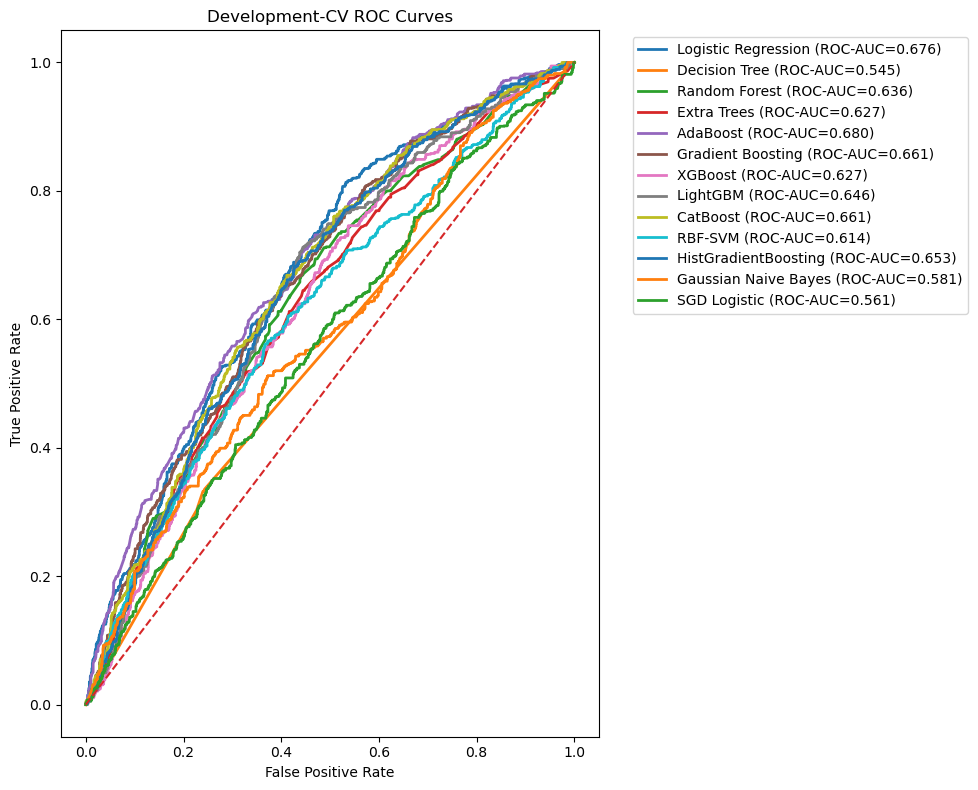


✓ ROC curves are based on PSU-grouped development cross-validation predictions.
✓ Final test data are not used in Step-17.


In [34]:
# ==========================================================
# Step-17 : Development-CV ROC Curves
#           NO FINAL TEST DATA
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

print("=" * 70)
print("DEVELOPMENT-CV ROC CURVES")
print("=" * 70)


plt.figure(
    figsize=(
        10,
        8
    )
)


for name, probability in default_cv_predictions.items():
    # ------------------------------------------------------
    # Weighted ROC curve
    # ------------------------------------------------------

    fpr, tpr, _ = roc_curve(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    # ------------------------------------------------------
    # Weighted ROC-AUC
    # ------------------------------------------------------

    roc_auc_value = roc_auc_score(

        y_train,

        probability,

        sample_weight=
            weights_train
    )


    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------

    plt.plot(

        fpr,

        tpr,

        linewidth=2,

        label=
            f"{name} "
            f"(ROC-AUC={roc_auc_value:.3f})"
    )


# ==========================================================
# Reference diagonal
# ==========================================================

plt.plot(

    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle="--"
)


# ==========================================================
# Figure formatting
# ==========================================================

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Development-CV ROC Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc="upper left"
)

plt.tight_layout()

plt.show()


print(
    "\n✓ ROC curves are based on "
    "PSU-grouped development cross-validation predictions."
)

print(
    "✓ Final test data are not used in Step-17."
)

DEVELOPMENT-CV PRECISION-RECALL CURVES


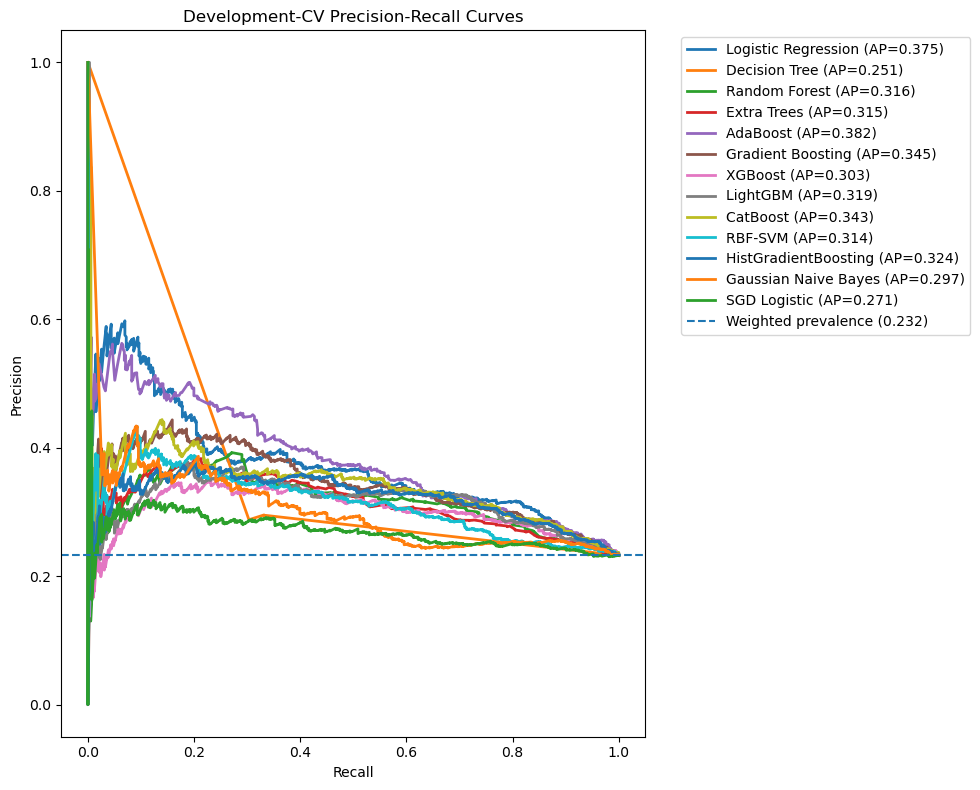


✓ Precision-recall curves are based on PSU-grouped development cross-validation predictions.
✓ Average Precision (AP) is reported.
✓ Final test data are not used in Step-18.


In [35]:
# ==========================================================
# Step-18 : Development-CV Precision-Recall Curves
#           NO FINAL TEST DATA
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

print("=" * 70)
print("DEVELOPMENT-CV PRECISION-RECALL CURVES")
print("=" * 70)


plt.figure(
    figsize=(
        10,
        8
    )
)


for name, probability in default_cv_predictions.items():
    
    # ------------------------------------------------------
    # Weighted Precision-Recall Curve
    # ------------------------------------------------------

    precision, recall, _ = (

        precision_recall_curve(

            y_train,

            probability,

            sample_weight=
                weights_train

        )

    )


    # ------------------------------------------------------
    # Weighted Average Precision
    # ------------------------------------------------------

    ap = average_precision_score(

        y_train,

        probability,

        sample_weight=
            weights_train

    )


    # ------------------------------------------------------
    # Plot
    # ------------------------------------------------------

    plt.plot(

        recall,

        precision,

        linewidth=2,

        label=
            f"{name} "
            f"(AP={ap:.3f})"

    )


# ==========================================================
# Weighted prevalence reference line
# ==========================================================

weighted_prevalence = np.average(

    np.asarray(
        y_train,
        dtype=float
    ),

    weights=
        weights_train

)


plt.axhline(

    weighted_prevalence,

    linestyle="--",

    label=
        f"Weighted prevalence "
        f"({weighted_prevalence:.3f})"

)


# ==========================================================
# Figure formatting
# ==========================================================

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Development-CV Precision-Recall Curves"
)

plt.legend(

    bbox_to_anchor=(
        1.05,
        1
    ),

    loc="upper left"

)

plt.tight_layout()

plt.show()


print(
    "\n✓ Precision-recall curves are based on "
    "PSU-grouped development cross-validation predictions."
)

print(
    "✓ Average Precision (AP) is reported."
)

print(
    "✓ Final test data are not used in Step-18."
)

In [36]:
# ==========================================================
# Step-19 : Lock One Fixed Pipeline
#           + paired ΔAUC uncertainty
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 78)

print(
    "STEP-19 : FIXED-PIPELINE LOCKING "
    "FROM DEVELOPMENT CV ONLY"
)

print("=" * 78)


ranking_df = (

    default_df

    .copy()

    .sort_values(

        "Mean_Fold_AUC",

        ascending=False

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nPrespecified fixed-pipeline comparison:"
)


display(

    ranking_df[
        [
            "Model",
            "Comparison_Label",
            "Mean_Fold_AUC",
            "SD_Fold_AUC",
            "AUC",
            "AUC_CI_Lower",
            "AUC_CI_Upper",
            "Average_Precision",
            "Brier",
            "LogLoss",
            "Threshold_for_Classification_Metrics",
            "Accuracy",
            "Balanced_Accuracy",
            "Precision",
            "Recall",
            "Specificity",
            "F1",
            "Kappa",
            "MCC"
        ]
    ]

    .round(4)

)


best_model_name = str(

    ranking_df.loc[
        0,
        "Model"
    ]

)


best_model_template = (

    models_default[
        best_model_name
    ]

)


best_model_params = (

    best_model_template
    .get_params()

)


print(
    "\nLocked pipeline:",
    best_model_name
)

print(
    best_model_params
)


# ==========================================================
# Paired top-vs-runner-up ΔAUC uncertainty
# ==========================================================

model_selection_uncertainty_df = (
    pd.DataFrame()
)


if len(
    ranking_df
) >= 2:

    runner_up_name = str(

        ranking_df.loc[
            1,
            "Model"
        ]

    )


    a = np.asarray(

        default_fold_auc_values[
            best_model_name
        ],

        dtype=float

    )


    b = np.asarray(

        default_fold_auc_values[
            runner_up_name
        ],

        dtype=float

    )


    if len(a) != len(b):

        raise RuntimeError(

            "Paired fold AUC arrays "
            "have unequal lengths."

        )


    delta = (
        a - b
    )


    rng = np.random.default_rng(
        19019
    )


    boot_delta = np.empty(

        10000,

        dtype=float

    )


    for i in range(
        len(
            boot_delta
        )
    ):

        idx = rng.choice(

            len(delta),

            size=
                len(delta),

            replace=True

        )


        boot_delta[i] = float(

            np.mean(

                delta[
                    idx
                ]

            )

        )


    delta_mean = float(
        np.mean(
            delta
        )
    )


    delta_low, delta_high = (

        np.quantile(

            boot_delta,

            [
                0.025,
                0.975
            ]

        )

    )


    model_selection_uncertainty_df = pd.DataFrame([{

        "Locked_Pipeline":
            best_model_name,

        "Runner_Up":
            runner_up_name,

        "Mean_Paired_Delta_AUC":
            delta_mean,

        "Bootstrap_CI_Lower":
            float(
                delta_low
            ),

        "Bootstrap_CI_Upper":
            float(
                delta_high
            ),

        "N_Paired_Outer_Folds":
            len(delta),

        "Interpretation":

            (
                "Small/overlapping differences are "
                "treated cautiously; this does not "
                "establish universal algorithmic "
                "superiority."
            )

    }])


    print(
        "\nPaired top-vs-runner-up ΔAUC:"
    )


    display(

        model_selection_uncertainty_df

        .round(4)

    )


print(
    "\nMETHOD NOTE"
)

print(
    "• Candidate algorithms are prespecified fixed pipelines."
)

print(
    "• No nested hyperparameter optimization is claimed."
)

print(
    "• Therefore do NOT write 'universally best algorithm'."
)

print(
    "• Development classification metrics use threshold=0.50 "
    "and are descriptive only."
)

STEP-19 : FIXED-PIPELINE LOCKING FROM DEVELOPMENT CV ONLY

Prespecified fixed-pipeline comparison:


,Model,Comparison_Label,Mean_Fold_AUC,SD_Fold_AUC,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,LogLoss,Threshold_for_Classification_Metrics,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC
0,AdaBoost,Prespecified fixed pipeline,0.6812,0.0292,0.6799,0.6493,0.7109,0.3818,0.1933,0.5760,0.5,0.7706,0.5253,0.5518,0.0670,0.9835,0.1194,0.0728,0.1289
1,Logistic Regression,Prespecified fixed pipeline,0.6783,0.0214,0.6756,0.6464,0.7061,0.3748,0.1675,0.5108,0.5,0.7662,0.5427,0.4874,0.1252,0.9602,0.1992,0.1152,0.1522
2,CatBoost,Prespecified fixed pipeline,0.6637,0.0259,0.6614,0.6317,0.6895,0.3426,0.1734,0.5292,0.5,0.7551,0.5261,0.3923,0.0984,0.9538,0.1574,0.0708,0.0942
3,Gradient Boosting,Prespecified fixed pipeline,0.6618,0.0312,0.6614,0.6317,0.6908,0.3451,0.1727,0.5259,0.5,0.7580,0.5314,0.4195,0.1081,0.9547,0.1719,0.0848,0.1118
4,HistGradientBoosting,Prespecified fixed pipeline,0.6549,0.0186,0.6530,0.6233,0.6826,0.3239,0.1874,0.5951,0.5,0.7373,0.5342,0.3516,0.1547,0.9136,0.2149,0.0849,0.0953
5,LightGBM,Prespecified fixed pipeline,0.6449,0.0288,0.6455,0.6163,0.6744,0.3194,0.1890,0.6030,0.5,0.7402,0.5345,0.3589,0.1503,0.9187,0.2119,0.0866,0.0984
6,Random Forest,Prespecified fixed pipeline,0.6406,0.0317,0.6362,0.6064,0.6663,0.3159,0.1759,0.5344,0.5,0.7491,0.5139,0.3254,0.0745,0.9533,0.1212,0.0380,0.0523
7,Extra Trees,Prespecified fixed pipeline,0.6300,0.0085,0.6274,0.5969,0.6591,0.3151,0.1826,0.5696,0.5,0.7406,0.5394,0.3687,0.1635,0.9153,0.2266,0.0977,0.1094
8,RBF-SVM,Prespecified fixed pipeline,0.6275,0.0152,0.6136,0.5835,0.6445,0.3136,0.1758,0.5341,0.5,0.7613,0.5062,0.3420,0.0296,0.9828,0.0544,0.0181,0.0372
9,XGBoost,Prespecified fixed pipeline,0.6274,0.0308,0.6271,0.5969,0.6565,0.3031,0.2069,0.7135,0.5,0.7283,0.5355,0.3372,0.1754,0.8956,0.2308,0.0853,0.0921



Locked pipeline: AdaBoost
{'algorithm': 'deprecated', 'estimator': None, 'learning_rate': 1.0, 'n_estimators': 50, 'random_state': 42}

Paired top-vs-runner-up ΔAUC:


,Locked_Pipeline,Runner_Up,Mean_Paired_Delta_AUC,Bootstrap_CI_Lower,Bootstrap_CI_Upper,N_Paired_Outer_Folds,Interpretation
0,AdaBoost,Logistic Regression,0.0029,-0.0104,0.0178,5,Small/overlapping differences are treated caut...



METHOD NOTE
• Candidate algorithms are prespecified fixed pipelines.
• No nested hyperparameter optimization is claimed.
• Therefore do NOT write 'universally best algorithm'.
• Development classification metrics use threshold=0.50 and are descriptive only.


In [37]:
# ==========================================================
# Step-20 : Calibration / Threshold Development
#           REVIEWER-FIXED
# ==========================================================

import warnings
import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.linear_model import (
    LogisticRegression
)

from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    brier_score_loss,
    roc_curve
)

from sklearn.model_selection import (
    StratifiedGroupKFold
)


print("=" * 78)

print(
    "STEP-20 : LEAKAGE-SAFE CALIBRATION "
    "+ OOF THRESHOLD LOCKING"
)

print("=" * 78)


# ==========================================================
# 1. Weighting sensitivity
#    Feature selection NOT repeated
# ==========================================================

weight_sensitivity_rows = []

weight_sensitivity_cv_predictions = {}


for strategy in WEIGHT_STRATEGIES:

    cv_prob = np.full(

        len(
            y_train
        ),

        np.nan,

        dtype=float

    )


    fold_auc = []


    for fold in development_fold_cache:

        model_fold = clone(
            best_model_template
        )


        fit_w = make_training_fit_weights(

            fold[
                "y_train"
            ],

            fold[
                "survey_weight_train"
            ],

            strategy=
                strategy

        )


        model_fold.fit(

            fold[
                "X_train_scaled"
            ],

            fold[
                "y_train"
            ],

            sample_weight=
                fit_w

        )


        p = (

            model_fold

            .predict_proba(

                fold[
                    "X_valid_scaled"
                ]

            )[:, 1]

        )


        cv_prob[
            fold[
                "local_valid_idx"
            ]
        ] = p


        fold_auc.append(

            roc_auc_score(

                fold[
                    "y_valid"
                ],

                p,

                sample_weight=
                    fold[
                        "survey_weight_valid"
                    ]

            )

        )


    if np.isnan(
        cv_prob
    ).any():

        raise RuntimeError(

            f"Missing CV probabilities "
            f"for strategy {strategy}."

        )


    m = weighted_binary_metrics(

        y_train,

        (
            cv_prob
            >=
            0.50
        ).astype(int),

        cv_prob,

        weights_train

    )


    weight_sensitivity_cv_predictions[
        strategy
    ] = cv_prob.copy()


    weight_sensitivity_rows.append({

        "Strategy":
            strategy,

        "Mean_CV_AUC":
            float(
                np.mean(
                    fold_auc
                )
            ),

        "SD_CV_AUC":
            float(
                np.std(
                    fold_auc,
                    ddof=1
                )
            ),

        "AUC":
            m["AUC"],

        "Average_Precision":
            m[
                "Average_Precision"
            ],

        "Brier":
            m["Brier"],

        "LogLoss":
            m["LogLoss"]

    })


weight_sensitivity_df = pd.DataFrame(
    weight_sensitivity_rows
)


print(
    "\nWeighting sensitivity "
    "(feature selection NOT repeated):"
)


display(
    weight_sensitivity_df.round(4)
)


print(
    "NOTE: alternative weighting is a refitting "
    "sensitivity conditional on the feature "
    "representation selected under SurveyWeightOnly."
)


best_weight_strategy = (
    "SurveyWeightOnly"
)


# ==========================================================
# 2. Final grouped SFS + preprocessing
#    DEVELOPMENT DATA ONLY
# ==========================================================

calibration_prepared = prepare_spatial_fold(

    global_train_indices=
        np.asarray(
            train_idx,
            dtype=int
        ),

    global_valid_indices=
        np.asarray(
            calibration_idx,
            dtype=int
        ),

    random_state=
        4242

)


# ==========================================================
# 3. Locked transformation
# ==========================================================

def transform_with_locked_preprocessing(

    global_train_indices,

    global_valid_indices,

    reference_prepared

):

    global_train_indices = np.asarray(
        global_train_indices,
        dtype=int
    )


    global_valid_indices = np.asarray(
        global_valid_indices,
        dtype=int
    )


    train_clusters_locked = np.unique(

        df

        .iloc[
            global_train_indices
        ]

        ["dhsclust"]

        .to_numpy()

    )


    valid_clusters_locked = np.unique(

        df

        .iloc[
            global_valid_indices
        ]

        ["dhsclust"]

        .to_numpy()

    )


    if np.intersect1d(

        train_clusters_locked,
        valid_clusters_locked

    ).size:

        raise RuntimeError(

            "DHS spatial-cluster leakage "
            "in locked transformation."

        )


    wx_locked = build_inductive_wx(

        data=
            df,

        train_clusters=
            train_clusters_locked,

        test_clusters=
            valid_clusters_locked,

        lag_vars=
            env_vars,

        k=
            K_NEIGHBORS

    )


    locked_df = (

        df

        .drop(

            columns=
                wx_vars,

            errors="ignore"

        )

        .copy()

    )


    locked_df[
        "_row_order"
    ] = np.arange(
        len(
            locked_df
        )
    )


    locked_df = (

        locked_df

        .merge(

            wx_locked,

            on=
                "dhsclust",

            how=
                "left",

            validate=
                "many_to_one",

            sort=False

        )

        .sort_values(
            "_row_order"
        )

        .drop(
            columns=
                "_row_order"
        )

        .reset_index(
            drop=True
        )

    )


    categorical = list(
        nominal_socio_vars
    )


    continuous = list(
        non_nominal_socio_vars
    )


    encoder = (
        reference_prepared[
            "encoder"
        ]
    )


    encoded_names = list(

        reference_prepared[
            "encoded_names"
        ]

    )


    selected_encoded = list(

        reference_prepared[
            "selected_vars"
        ]

    )


    locked_features = list(

        reference_prepared[
            "model_features"
        ]

    )


    locked_scaler = (

        reference_prepared[
            "scaler"
        ]

    )


    # Use EXACT category universe of fitted encoder

    encoder_level_map = {

        v:

            list(
                map(
                    str,
                    cats.tolist()
                )
            )

        for v, cats
        in zip(

            categorical,
            encoder.categories_

        )

    }


    valid_cat, other_report = (

        _normalize_categorical_frame(

            locked_df

            .iloc[
                global_valid_indices
            ]

            [categorical],

            categorical,

            levels_map=
                encoder_level_map

        )

    )


    encoded_valid = (

        encoder.transform(
            valid_cat
        )

    )


    encoded_valid_df = pd.DataFrame(

        encoded_valid,

        columns=
            encoded_names

    )


    base_names = (

        continuous

        +

        env_vars

        +

        wx_vars

    )


    valid_base = (

        locked_df

        .iloc[
            global_valid_indices
        ]

        [base_names]

        .reset_index(
            drop=True
        )

        .astype(float)

    )


    X_candidate = pd.concat(

        [
            valid_base,
            encoded_valid_df
        ],

        axis=1

    )


    missing = [

        f

        for f
        in selected_encoded

        if f not in
        X_candidate.columns

    ]


    if missing:

        raise RuntimeError(

            f"Locked selected predictors "
            f"missing: {missing}"

        )


    coords = (

        locked_df

        .iloc[
            global_valid_indices
        ]

        [
            [
                "lat",
                "lon"
            ]
        ]

        .reset_index(
            drop=True
        )

        .astype(float)

    )


    X_raw = pd.concat(

        [

            X_candidate[
                selected_encoded
            ]

            .reset_index(
                drop=True
            ),

            coords

        ],

        axis=1

    )


    X_raw = (
        X_raw[
            locked_features
        ]
    )


    X_scaled = pd.DataFrame(

        locked_scaler.transform(
            X_raw
        ),

        columns=
            locked_features

    )


    return {

        "X_valid_raw":
            X_raw,

        "X_valid_scaled":
            X_scaled,

        "y_valid":

            locked_df

            .iloc[
                global_valid_indices
            ]

            [target]

            .astype(int)

            .to_numpy(),

        "survey_weight_valid":

            locked_df

            .iloc[
                global_valid_indices
            ]

            ["survey_weight"]

            .astype(float)

            .to_numpy(),

        "groups_valid":

            locked_df

            .iloc[
                global_valid_indices
            ]

            ["psu"]

            .to_numpy(),

        "strata_valid":

            locked_df

            .iloc[
                global_valid_indices
            ]

            ["analysis_strata"]

            .to_numpy(),

        "spatial_clusters_valid":

            locked_df

            .iloc[
                global_valid_indices
            ]

            ["dhsclust"]

            .to_numpy(),

        "unseen_category_report":
            other_report

    }


# ==========================================================
# 4. Locked FINAL TEST transformation
# ==========================================================

final_test_locked = (

    transform_with_locked_preprocessing(

        global_train_indices=
            np.asarray(
                train_idx,
                dtype=int
            ),

        global_valid_indices=
            np.asarray(
                test_idx,
                dtype=int
            ),

        reference_prepared=
            calibration_prepared

    )

)


if final_test_locked[
    "unseen_category_report"
]:

    print(

        "\nMapped test categories to __OTHER__:",

        final_test_locked[
            "unseen_category_report"
        ]

    )


# ==========================================================
# 5. Expose final objects
# ==========================================================

selected_vars = list(

    calibration_prepared[
        "selected_vars"
    ]

)


selected_groups = list(

    calibration_prepared[
        "selected_groups"
    ]

)


sfs_group_df = (

    calibration_prepared[
        "sfs_group_df"
    ]
    .copy()

)


sfs_path_df = (

    calibration_prepared[
        "sfs_path_df"
    ]
    .copy()

)


group_to_columns = dict(

    calibration_prepared[
        "group_to_columns"
    ]

)


model_features = list(

    calibration_prepared[
        "model_features"
    ]

)


sfs_df = (

    calibration_prepared[
        "sfs_df"
    ]
    .copy()

)


onehot_encoder = (

    calibration_prepared[
        "encoder"
    ]

)


encoded_nominal_columns = list(

    calibration_prepared[
        "encoded_names"
    ]

)


socio_encoded_features = list(

    calibration_prepared[
        "socio_feature_names"
    ]

)


scaler = (

    calibration_prepared[
        "scaler"
    ]

)


# ----------------------------------------------------------
# Development
# ----------------------------------------------------------

X_train_raw = (

    calibration_prepared[
        "X_train_raw"
    ]
    .copy()

)


X_train = (

    calibration_prepared[
        "X_train_scaled"
    ]
    .copy()

)


y_train = pd.Series(

    calibration_prepared[
        "y_train"
    ],

    name=
        target

)


weights_train = np.asarray(

    calibration_prepared[
        "survey_weight_train"
    ],

    dtype=float

)


groups_train = np.asarray(

    calibration_prepared[
        "groups_train"
    ]

)


strata_train = np.asarray(

    calibration_prepared[
        "strata_train"
    ]

)


spatial_clusters_train = np.asarray(

    calibration_prepared[
        "spatial_clusters_train"
    ]

)


# ----------------------------------------------------------
# Calibration
# ----------------------------------------------------------

X_calibration_raw = (

    calibration_prepared[
        "X_valid_raw"
    ]

    .copy()

)


X_calibration = (

    calibration_prepared[
        "X_valid_scaled"
    ]

    .copy()

)


y_calibration = pd.Series(

    calibration_prepared[
        "y_valid"
    ],

    name=
        target

)


weights_calibration = np.asarray(

    calibration_prepared[
        "survey_weight_valid"
    ],

    dtype=float

)


groups_calibration = np.asarray(

    calibration_prepared[
        "groups_valid"
    ]

)


strata_calibration = np.asarray(

    calibration_prepared[
        "strata_valid"
    ]

)


spatial_clusters_calibration = np.asarray(

    calibration_prepared[
        "spatial_clusters_valid"
    ]

)


# ----------------------------------------------------------
# Test
# ----------------------------------------------------------

X_test_raw = (

    final_test_locked[
        "X_valid_raw"
    ]

    .copy()

)


X_test = (

    final_test_locked[
        "X_valid_scaled"
    ]

    .copy()

)


y_test = pd.Series(

    final_test_locked[
        "y_valid"
    ],

    name=
        target

)


weights_test = np.asarray(

    final_test_locked[
        "survey_weight_valid"
    ],

    dtype=float

)


groups_test = np.asarray(

    final_test_locked[
        "groups_valid"
    ]

)


strata_test = np.asarray(

    final_test_locked[
        "strata_valid"
    ]

)


spatial_clusters_test = np.asarray(

    final_test_locked[
        "spatial_clusters_valid"
    ]

)


# Coordinates use lon, lat order downstream

coords_train = (

    df.iloc[
        np.asarray(
            train_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )

)


coords_calibration = (

    df.iloc[
        np.asarray(
            calibration_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )

)


coords_test = (

    df.iloc[
        np.asarray(
            test_idx,
            dtype=int
        )
    ][
        [
            "lon",
            "lat"
        ]
    ]

    .to_numpy(
        dtype=float
    )

)


# ==========================================================
# 6. Predictor definition table
# ==========================================================

final_predictor_definition_df = (

    predictor_definition_df

    .copy()

)


final_predictor_definition_df[
    "Reference_Group"
] = (

    final_predictor_definition_df

    .apply(

        lambda r:

            (
                "No dropped reference category; "
                "full one-hot encoding was used"

                if r[
                    "Type"
                ]
                !=
                "Continuous/count"

                else
                "Not applicable"
            ),

        axis=1

    )

)


print(
    "\nSelected conceptual groups:",
    len(
        selected_groups
    )
)


print(
    "Expanded selected encoded columns:",
    len(
        selected_vars
    )
)


print(
    "Final model columns including coordinates:",
    len(
        model_features
    )
)


print(
    "Selected groups:",
    selected_groups
)


# ==========================================================
# 7. Fit locked BASE MODEL
# ==========================================================

final_fit_weights = (

    make_training_fit_weights(

        y_train,

        weights_train,

        strategy=
            best_weight_strategy

    )

)


combined_train_weights = (
    final_fit_weights.copy()
)


final_model = clone(
    best_model_template
)


final_model.fit(

    X_train,

    y_train,

    sample_weight=
        final_fit_weights

)


# ==========================================================
# 8. Raw calibration probabilities
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    p = np.clip(

        np.asarray(
            probability,
            dtype=float
        ),

        EPS,

        1 - EPS

    )


    return np.log(

        p
        /
        (
            1 - p
        )

    )


calibration_probability_raw = (

    final_model

    .predict_proba(
        X_calibration
    )[:, 1]

)


calibration_y_array = np.asarray(

    y_calibration,

    dtype=int

)


calibration_weight_array = np.asarray(

    weights_calibration,

    dtype=float

)


calibration_group_array = np.asarray(

    groups_calibration

)


# ==========================================================
# 9. OOF probability calibration
# ==========================================================

N_CALIBRATION_FOLDS = 5


if (

    len(
        np.unique(
            calibration_group_array
        )
    )

    <

    N_CALIBRATION_FOLDS

):

    raise RuntimeError(

        "Not enough calibration PSUs "
        "for grouped calibration."

    )


cal_cv = StratifiedGroupKFold(

    n_splits=
        N_CALIBRATION_FOLDS,

    shuffle=True,

    random_state=
        4242

)


calibration_probability_oof = np.full(

    len(
        calibration_y_array
    ),

    np.nan,

    dtype=float

)


for fold_no, (

    fit_idx,
    val_idx

) in enumerate(

    cal_cv.split(

        np.zeros(
            len(
                calibration_y_array
            )
        ),

        calibration_y_array,

        groups=
            calibration_group_array

    ),

    start=1

):

    fit_idx = np.asarray(
        fit_idx,
        dtype=int
    )


    val_idx = np.asarray(
        val_idx,
        dtype=int
    )


    if np.intersect1d(

        calibration_group_array[
            fit_idx
        ],

        calibration_group_array[
            val_idx
        ]

    ).size:

        raise RuntimeError(

            f"PSU leakage in "
            f"calibration fold {fold_no}."

        )


    if np.unique(

        calibration_y_array[
            fit_idx
        ]

    ).size < 2:

        raise RuntimeError(

            f"Calibration fold {fold_no} "
            "contains one class."

        )


    fold_calibrator = LogisticRegression(

        C=
            1e6,

        solver=
            "lbfgs",

        max_iter=
            2000,

        random_state=
            42

    )


    fold_calibrator.fit(

        probability_to_logit(

            calibration_probability_raw[
                fit_idx
            ]

        ).reshape(
            -1,
            1
        ),

        calibration_y_array[
            fit_idx
        ],

        sample_weight=
            calibration_weight_array[
                fit_idx
            ]

    )


    calibration_probability_oof[
        val_idx
    ] = (

        fold_calibrator

        .predict_proba(

            probability_to_logit(

                calibration_probability_raw[
                    val_idx
                ]

            ).reshape(
                -1,
                1
            )

        )[:, 1]

    )


if np.isnan(

    calibration_probability_oof

).any():

    raise RuntimeError(

        "Missing OOF calibrated probabilities."

    )


print(
    "\nRaw calibration Brier:",
    round(

        brier_score_loss(

            calibration_y_array,

            calibration_probability_raw,

            sample_weight=
                calibration_weight_array

        ),

        4

    )
)


print(
    "OOF calibrated Brier:",
    round(

        brier_score_loss(

            calibration_y_array,

            calibration_probability_oof,

            sample_weight=
                calibration_weight_array

        ),

        4

    )
)


# ==========================================================
# 10. MCC threshold FROM OOF calibrated probability only
# ==========================================================

_, _, candidate_thresholds = roc_curve(

    calibration_y_array,

    calibration_probability_oof,

    sample_weight=
        calibration_weight_array,

    drop_intermediate=False

)


candidate_thresholds = (

    candidate_thresholds[

        np.isfinite(
            candidate_thresholds
        )

        &

        (
            candidate_thresholds
            >=
            0
        )

        &

        (
            candidate_thresholds
            <=
            1
        )

    ]

)


threshold_rows = []


for t in candidate_thresholds:

    pred = (

        calibration_probability_oof
        >=
        t

    ).astype(int)


    tn, fp, fn, tp = (

        confusion_matrix(

            calibration_y_array,

            pred,

            labels=[
                0,
                1
            ],

            sample_weight=
                calibration_weight_array

        )

        .ravel()

    )


    den = np.sqrt(

        (tp + fp)
        *
        (tp + fn)
        *
        (tn + fp)
        *
        (tn + fn)

    )


    mcc = (

        (
            tp * tn
            -
            fp * fn
        )

        /
        den

        if den > 0

        else np.nan

    )


    sensitivity = (

        tp
        /
        (tp + fn)

        if (tp + fn) > 0

        else np.nan

    )


    specificity = (

        tn
        /
        (tn + fp)

        if (tn + fp) > 0

        else np.nan

    )


    threshold_rows.append({

        "Threshold":
            float(t),

        "MCC":
            float(mcc),

        "Sensitivity":
            float(
                sensitivity
            ),

        "Specificity":
            float(
                specificity
            ),

        "Balanced_Accuracy":
            float(
                (
                    sensitivity
                    +
                    specificity
                )
                /
                2
            )

    })


mcc_threshold_df = (

    pd.DataFrame(
        threshold_rows
    )

    .dropna(
        subset=[
            "MCC"
        ]
    )

    .reset_index(
        drop=True
    )

)


if len(
    mcc_threshold_df
) == 0:

    raise RuntimeError(

        "No valid MCC threshold found."

    )


best_threshold_row = (

    mcc_threshold_df

    .loc[

        mcc_threshold_df[
            "MCC"
        ].idxmax()

    ]

)


final_threshold = float(

    best_threshold_row[
        "Threshold"
    ]

)


print(
    "\nLocked OOF MCC threshold:",
    round(
        final_threshold,
        4
    )
)


display(

    best_threshold_row

    .to_frame(
        name="Value"
    )

    .round(4)

)


THRESHOLD_INTENDED_USE = (

    "Statistical operating-point description for "
    "internal model evaluation; not a clinical or "
    "public-health treatment/screening decision rule."

)


print(
    "Threshold intended use:",
    THRESHOLD_INTENDED_USE
)


# ==========================================================
# 11. AFTER threshold development,
#     fit final calibrator on ALL reserved calibration data
# ==========================================================

probability_calibrator = LogisticRegression(

    C=
        1e6,

    solver=
        "lbfgs",

    max_iter=
        2000,

    random_state=
        42

)


probability_calibrator.fit(

    probability_to_logit(

        calibration_probability_raw

    ).reshape(
        -1,
        1
    ),

    calibration_y_array,

    sample_weight=
        calibration_weight_array

)


def apply_probability_calibration(

    raw_probability

):

    z = (

        probability_to_logit(

            raw_probability

        )

        .reshape(
            -1,
            1
        )

    )


    return (

        probability_calibrator

        .predict_proba(
            z
        )[:, 1]

    )


calibration_probability = (

    apply_probability_calibration(

        calibration_probability_raw

    )

)


print(
    "\nAUDIT"
)

print(
    "✓ Grouped SFS/encoder/scaler fitted "
    "on development data only."
)

print(
    "✓ Calibration and test use locked preprocessing."
)

print(
    "✓ Threshold selected from OOF calibrated "
    "probabilities only."
)

print(
    "✓ Final calibrator fitted on complete calibration "
    "set only AFTER OOF threshold development."
)

print(
    "✓ Final-test outcomes have not been used."
)

STEP-20 : LEAKAGE-SAFE CALIBRATION + OOF THRESHOLD LOCKING

Weighting sensitivity (feature selection NOT repeated):


,Strategy,Mean_CV_AUC,SD_CV_AUC,AUC,Average_Precision,Brier,LogLoss
0,SurveyWeightOnly,0.6812,0.0292,0.6799,0.3818,0.1933,0.576
1,SurveyWeight_ClassBalanced,0.6814,0.0289,0.6807,0.3897,0.2275,0.647


NOTE: alternative weighting is a refitting sensitivity conditional on the feature representation selected under SurveyWeightOnly.
  grouped-SFS step 01: removed=Contraceptive_decision_maker | groups=49 | mean inner AUC=0.6674
  grouped-SFS step 02: removed=Wealth | groups=48 | mean inner AUC=0.6728
  grouped-SFS step 03: removed=Maternal_age_group | groups=47 | mean inner AUC=0.6784
  grouped-SFS step 04: removed=Division | groups=46 | mean inner AUC=0.6831
  grouped-SFS step 05: removed=pop_density | groups=45 | mean inner AUC=0.6854
  grouped-SFS step 06: removed=Water_source | groups=44 | mean inner AUC=0.6875
  grouped-SFS step 07: removed=Who_make_decision_about_health | groups=43 | mean inner AUC=0.6890
  grouped-SFS step 08: removed=Religion | groups=42 | mean inner AUC=0.6909
  grouped-SFS step 09: removed=Child_sex | groups=41 | mean inner AUC=0.6918
  grouped-SFS step 10: removed=wx_pdsi_drought_index | groups=40 | mean inner AUC=0.6926
  grouped-SFS step 11: removed=wx_relat

,Value
Threshold,0.2233
MCC,0.2130
Sensitivity,0.6764
Specificity,0.5804
Balanced_Accuracy,0.6284


Threshold intended use: Statistical operating-point description for internal model evaluation; not a clinical or public-health treatment/screening decision rule.

AUDIT
✓ Grouped SFS/encoder/scaler fitted on development data only.
✓ Calibration and test use locked preprocessing.
✓ Threshold selected from OOF calibrated probabilities only.
✓ Final calibrator fitted on complete calibration set only AFTER OOF threshold development.
✓ Final-test outcomes have not been used.


In [38]:
# ==========================================================
# Step-21 : FIRST evaluation on HELD-OUT INTERNAL TEST
# ==========================================================

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


print("=" * 78)

print(
    "STEP-21 : FIRST PERFORMANCE EVALUATION "
    "ON HELD-OUT INTERNAL TEST"
)

print("=" * 78)


# Base-model raw probability

y_prob_raw = (

    final_model

    .predict_proba(
        X_test
    )[:, 1]

)


# Apply calibrator learned only from calibration subset

y_prob = (

    apply_probability_calibration(

        y_prob_raw

    )

)


final_test_auc = roc_auc_score(

    y_test,
    y_prob,

    sample_weight=
        weights_test

)


final_test_ap = average_precision_score(

    y_test,
    y_prob,

    sample_weight=
        weights_test

)


final_test_brier = brier_score_loss(

    y_test,
    y_prob,

    sample_weight=
        weights_test

)


print(
    "Weighted ROC-AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "Weighted Average Precision:",
    round(
        final_test_ap,
        4
    )
)


print(
    "Weighted Brier score:",
    round(
        final_test_brier,
        4
    )
)


print(
    "\n✓ Held-out INTERNAL evaluation."
)

print(
    "✓ Same BDHS 2022 survey; no external-validation claim."
)

print(
    "✓ Test outcomes were not used for fitting, "
    "SFS, calibration or threshold selection."
)

print(
    "✓ All CIs are calculated ONCE in Step-22."
)

STEP-21 : FIRST PERFORMANCE EVALUATION ON HELD-OUT INTERNAL TEST
Weighted ROC-AUC: 0.6773
Weighted Average Precision: 0.3994
Weighted Brier score: 0.1617

✓ Held-out INTERNAL evaluation.
✓ Same BDHS 2022 survey; no external-validation claim.
✓ Test outcomes were not used for fitting, SFS, calibration or threshold selection.
✓ All CIs are calculated ONCE in Step-22.


STEP-22 : FINAL INTERNAL TEST METRICS + 2,000-REPLICATE PSU BOOTSTRAP

FINAL TEST POINT ESTIMATES


,Model,Validation_Type,Threshold,Accuracy,Balanced_Accuracy,Precision,Recall,Specificity,F1,Kappa,MCC,AUC,Average_Precision,Brier,LogLoss,Calibration_Intercept,Calibration_Slope
0,AdaBoost,Held-out internal validation,0.2233,0.6347,0.6131,0.3206,0.5743,0.652,0.4115,0.1764,0.1922,0.6773,0.3994,0.1617,0.4977,0.4659,1.2663



95% STRATIFIED PSU-BOOTSTRAP CI


,Metric,Estimate,CI_Lower,CI_Upper,Valid_Bootstrap_Replicates,Requested_Bootstrap_Replicates,Variance_Method
0,Accuracy,0.6347,0.5993,0.6691,2000,2000,Stratified cluster/PSU bootstrap
1,Balanced_Accuracy,0.6131,0.5673,0.6600,2000,2000,Stratified cluster/PSU bootstrap
2,Precision,0.3206,0.2660,0.3704,2000,2000,Stratified cluster/PSU bootstrap
3,Sensitivity,0.5743,0.4791,0.6694,2000,2000,Stratified cluster/PSU bootstrap
4,Specificity,0.6520,0.6051,0.6985,2000,2000,Stratified cluster/PSU bootstrap
5,F1,0.4115,0.3480,0.4675,2000,2000,Stratified cluster/PSU bootstrap
6,Kappa,0.1764,0.1054,0.2449,2000,2000,Stratified cluster/PSU bootstrap
7,MCC,0.1922,0.1146,0.2684,2000,2000,Stratified cluster/PSU bootstrap
8,AUC,0.6773,0.6276,0.7259,2000,2000,Stratified cluster/PSU bootstrap
9,Average_Precision,0.3994,0.3298,0.4778,2000,2000,Stratified cluster/PSU bootstrap


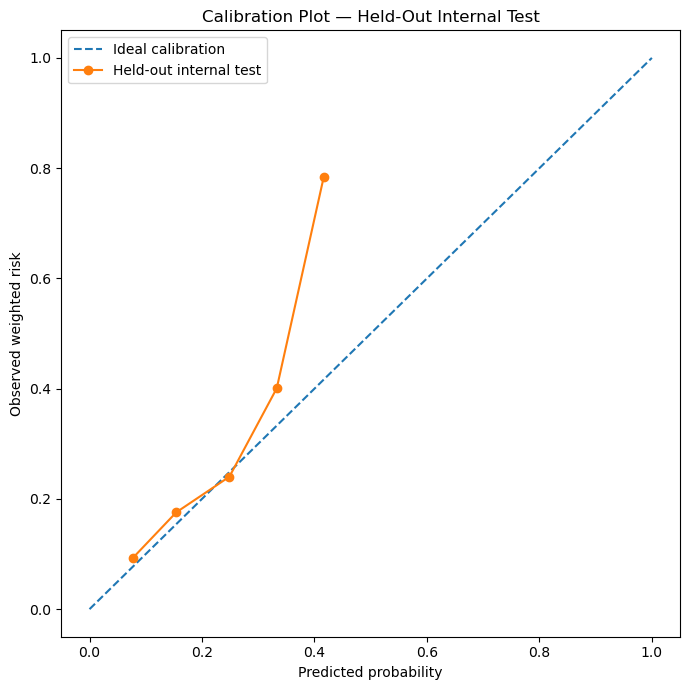


Calibration intercept: 0.4659 95% CI (-0.0757, 1.0225)
Calibration slope: 1.2663 95% CI (0.8875, 1.7378)

✓ Same bootstrap resamples used for all principal metrics.
✓ Valid bootstrap replicate count reported.
✓ Method = stratified cluster/PSU bootstrap.


In [39]:
# ==========================================================
# Step-22 : Final Held-Out Internal Evaluation
#           One stratified PSU bootstrap for all metrics
# ==========================================================

import numpy as np
import pandas as pd

import statsmodels.api as sm

import matplotlib.pyplot as plt

from pathlib import Path


print("=" * 78)

print(
    "STEP-22 : FINAL INTERNAL TEST METRICS "
    "+ 2,000-REPLICATE PSU BOOTSTRAP"
)

print("=" * 78)


OUTPUT_DIR = globals().get(

    "OUTPUT_DIR",

    Path(
        PROJECT_ROOT
    )
    /
    "Reviewer_Final_Outputs"

)


OUTPUT_DIR = Path(
    OUTPUT_DIR
)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ==========================================================
# 1. Point estimates
# ==========================================================

y_test_arr = np.asarray(
    y_test,
    dtype=int
)


y_prob_arr = np.asarray(
    y_prob,
    dtype=float
)


w_test_arr = np.asarray(
    weights_test,
    dtype=float
)


psu_test_arr = np.asarray(
    groups_test
)


strata_test_arr = np.asarray(
    strata_test
)


y_pred = (

    y_prob_arr
    >=
    final_threshold

).astype(int)


final_test_metrics = (

    weighted_binary_metrics(

        y_test_arr,
        y_pred,
        y_prob_arr,
        w_test_arr

    )

)


def calibration_intercept_slope(

    y_true,
    prob,
    weight

):

    prob = np.clip(

        np.asarray(
            prob,
            dtype=float
        ),

        1e-6,

        1 - 1e-6

    )


    logit_p = np.log(

        prob
        /
        (
            1 - prob
        )

    )


    X = sm.add_constant(
        logit_p
    )


    fit = sm.GLM(

        np.asarray(
            y_true,
            dtype=float
        ),

        X,

        family=
            sm.families.Binomial(),

        freq_weights=
            np.asarray(
                weight,
                dtype=float
            )

    ).fit(
        disp=0
    )


    return (

        float(
            fit.params[0]
        ),

        float(
            fit.params[1]
        )

    )


(
    calibration_intercept_test,
    calibration_slope_test

) = calibration_intercept_slope(

    y_test_arr,
    y_prob_arr,
    w_test_arr

)


# ==========================================================
# 2. ONE bootstrap for ALL principal metrics
# ==========================================================

def stratified_psu_bootstrap_all_metrics(

    y_true,
    y_prob,
    threshold,
    psu,
    strata,
    sample_weight,

    n_bootstrap=2000,

    random_state=22022

):

    y_true = np.asarray(
        y_true,
        dtype=int
    )

    y_prob = np.asarray(
        y_prob,
        dtype=float
    )

    psu = np.asarray(
        psu
    )

    strata = np.asarray(
        strata
    )

    sample_weight = np.asarray(
        sample_weight,
        dtype=float
    )


    rng = np.random.default_rng(
        random_state
    )


    unique_strata = pd.unique(
        strata
    )


    rows = []


    for b in range(

        int(
            n_bootstrap
        )

    ):

        sampled_indices = []


        for s in unique_strata:

            smask = (
                strata
                ==
                s
            )


            stratum_psus = pd.unique(

                psu[
                    smask
                ]

            )


            if len(
                stratum_psus
            ) == 0:

                continue


            sampled_psus = rng.choice(

                stratum_psus,

                size=
                    len(
                        stratum_psus
                    ),

                replace=True

            )


            for p in sampled_psus:

                sampled_indices.extend(

                    np.flatnonzero(

                        smask

                        &

                        (
                            psu == p
                        )

                    )

                    .tolist()

                )


        idx = np.asarray(
            sampled_indices,
            dtype=int
        )


        if (

            len(idx) == 0

            or

            np.unique(
                y_true[
                    idx
                ]
            ).size < 2

        ):

            continue


        yb = y_true[
            idx
        ]

        pb = y_prob[
            idx
        ]

        wb = sample_weight[
            idx
        ]


        pred_b = (

            pb
            >=
            threshold

        ).astype(int)


        try:

            m = weighted_binary_metrics(

                yb,
                pred_b,
                pb,
                wb

            )

        except Exception:

            continue


        try:

            cal_i, cal_s = (

                calibration_intercept_slope(

                    yb,
                    pb,
                    wb

                )

            )

        except Exception:

            cal_i = np.nan
            cal_s = np.nan


        rows.append({

            "Bootstrap_Replicate":
                b + 1,

            "Accuracy":
                m["Accuracy"],

            "Balanced_Accuracy":
                m[
                    "Balanced_Accuracy"
                ],

            "Precision":
                m["Precision"],

            "Sensitivity":
                m["Recall"],

            "Specificity":
                m["Specificity"],

            "F1":
                m["F1"],

            "Kappa":
                m["Kappa"],

            "MCC":
                m["MCC"],

            "AUC":
                m["AUC"],

            "Average_Precision":
                m[
                    "Average_Precision"
                ],

            "Brier":
                m["Brier"],

            "LogLoss":
                m["LogLoss"],

            "Calibration_Intercept":
                cal_i,

            "Calibration_Slope":
                cal_s

        })


    if not rows:

        raise RuntimeError(

            "No valid stratified PSU "
            "bootstrap replicates."

        )


    return pd.DataFrame(
        rows
    )


bootstrap_metric_values_df = (

    stratified_psu_bootstrap_all_metrics(

        y_true=
            y_test_arr,

        y_prob=
            y_prob_arr,

        threshold=
            final_threshold,

        psu=
            psu_test_arr,

        strata=
            strata_test_arr,

        sample_weight=
            w_test_arr,

        n_bootstrap=
            N_BOOTSTRAP_FINAL,

        random_state=
            22022

    )

)


point_values = {

    "Accuracy":
        final_test_metrics[
            "Accuracy"
        ],

    "Balanced_Accuracy":
        final_test_metrics[
            "Balanced_Accuracy"
        ],

    "Precision":
        final_test_metrics[
            "Precision"
        ],

    "Sensitivity":
        final_test_metrics[
            "Recall"
        ],

    "Specificity":
        final_test_metrics[
            "Specificity"
        ],

    "F1":
        final_test_metrics[
            "F1"
        ],

    "Kappa":
        final_test_metrics[
            "Kappa"
        ],

    "MCC":
        final_test_metrics[
            "MCC"
        ],

    "AUC":
        final_test_metrics[
            "AUC"
        ],

    "Average_Precision":
        final_test_metrics[
            "Average_Precision"
        ],

    "Brier":
        final_test_metrics[
            "Brier"
        ],

    "LogLoss":
        final_test_metrics[
            "LogLoss"
        ],

    "Calibration_Intercept":
        calibration_intercept_test,

    "Calibration_Slope":
        calibration_slope_test

}


ci_rows = []


for metric, point in point_values.items():

    values = (

        bootstrap_metric_values_df[
            metric
        ]

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )

        .dropna()

    )


    if len(values) == 0:

        low = np.nan
        high = np.nan

    else:

        low, high = np.quantile(

            values.to_numpy(
                dtype=float
            ),

            [
                0.025,
                0.975
            ]

        )


    ci_rows.append({

        "Metric":
            metric,

        "Estimate":
            float(
                point
            ),

        "CI_Lower":

            float(low)
            if np.isfinite(low)
            else np.nan,

        "CI_Upper":

            float(high)
            if np.isfinite(high)
            else np.nan,

        "Valid_Bootstrap_Replicates":
            int(
                len(values)
            ),

        "Requested_Bootstrap_Replicates":
            int(
                N_BOOTSTRAP_FINAL
            ),

        "Variance_Method":
            "Stratified cluster/PSU bootstrap"

    })


final_metric_ci_df = pd.DataFrame(
    ci_rows
)


def _ci(
    metric
):

    row = (

        final_metric_ci_df

        .loc[

            final_metric_ci_df[
                "Metric"
            ]
            ==
            metric

        ]

        .iloc[0]

    )


    return (

        float(
            row[
                "CI_Lower"
            ]
        ),

        float(
            row[
                "CI_Upper"
            ]
        )

    )


final_auc_ci_lower, final_auc_ci_upper = (
    _ci(
        "AUC"
    )
)


sensitivity_ci_lower, sensitivity_ci_upper = (
    _ci(
        "Sensitivity"
    )
)


specificity_ci_lower, specificity_ci_upper = (
    _ci(
        "Specificity"
    )
)


ppv_ci_lower, ppv_ci_upper = (
    _ci(
        "Precision"
    )
)


f1_ci_lower, f1_ci_upper = (
    _ci(
        "F1"
    )
)


mcc_ci_lower, mcc_ci_upper = (
    _ci(
        "MCC"
    )
)


ap_ci_lower, ap_ci_upper = (
    _ci(
        "Average_Precision"
    )
)


brier_ci_lower, brier_ci_upper = (
    _ci(
        "Brier"
    )
)


cal_intercept_ci_lower, cal_intercept_ci_upper = (
    _ci(
        "Calibration_Intercept"
    )
)


cal_slope_ci_lower, cal_slope_ci_upper = (
    _ci(
        "Calibration_Slope"
    )
)


final_test_metrics_df = pd.DataFrame([{

    "Model":
        best_model_name,

    "Validation_Type":
        "Held-out internal validation",

    "Threshold":
        final_threshold,

    "Accuracy":
        final_test_metrics[
            "Accuracy"
        ],

    "Balanced_Accuracy":
        final_test_metrics[
            "Balanced_Accuracy"
        ],

    "Precision":
        final_test_metrics[
            "Precision"
        ],

    "Recall":
        final_test_metrics[
            "Recall"
        ],

    "Specificity":
        final_test_metrics[
            "Specificity"
        ],

    "F1":
        final_test_metrics[
            "F1"
        ],

    "Kappa":
        final_test_metrics[
            "Kappa"
        ],

    "MCC":
        final_test_metrics[
            "MCC"
        ],

    "AUC":
        final_test_metrics[
            "AUC"
        ],

    "Average_Precision":
        final_test_metrics[
            "Average_Precision"
        ],

    "Brier":
        final_test_metrics[
            "Brier"
        ],

    "LogLoss":
        final_test_metrics[
            "LogLoss"
        ],

    "Calibration_Intercept":
        calibration_intercept_test,

    "Calibration_Slope":
        calibration_slope_test

}])


print(
    "\nFINAL TEST POINT ESTIMATES"
)

display(
    final_test_metrics_df.round(4)
)


print(
    "\n95% STRATIFIED PSU-BOOTSTRAP CI"
)

display(
    final_metric_ci_df.round(4)
)


# ==========================================================
# 3. Weighted calibration plot
# ==========================================================

calibration_plot_df = pd.DataFrame({

    "y":
        y_test_arr,

    "p":
        y_prob_arr,

    "w":
        w_test_arr

})


calibration_plot_df[
    "bin"
] = pd.cut(

    calibration_plot_df[
        "p"
    ],

    bins=
        np.linspace(
            0,
            1,
            11
        ),

    include_lowest=True,

    duplicates="drop"

)


calibration_bins = []


for bin_label, g in (

    calibration_plot_df

    .groupby(
        "bin",
        observed=True
    )

):

    if (

        len(g) == 0

        or

        g[
            "w"
        ].sum() <= 0

    ):

        continue


    calibration_bins.append({

        "Probability_Bin":
            str(
                bin_label
            ),

        "N":
            int(
                len(g)
            ),

        "Weighted_Mean_Predicted":

            float(

                np.average(

                    g["p"],

                    weights=
                        g["w"]

                )

            ),

        "Weighted_Observed_Risk":

            float(

                np.average(

                    g["y"],

                    weights=
                        g["w"]

                )

            ),

        "Survey_Weight_Sum":
            float(
                g["w"].sum()
            )

    })


calibration_bins_df = pd.DataFrame(
    calibration_bins
)


plt.figure(
    figsize=(
        7,
        7
    )
)


plt.plot(

    [
        0,
        1
    ],

    [
        0,
        1
    ],

    linestyle="--",

    label=
        "Ideal calibration"

)


if len(
    calibration_bins_df
):

    plt.plot(

        calibration_bins_df[
            "Weighted_Mean_Predicted"
        ],

        calibration_bins_df[
            "Weighted_Observed_Risk"
        ],

        marker="o",

        label=
            "Held-out internal test"

    )


plt.xlabel(
    "Predicted probability"
)

plt.ylabel(
    "Observed weighted risk"
)

plt.title(
    "Calibration Plot — Held-Out Internal Test"
)

plt.legend()

plt.tight_layout()


plt.savefig(

    OUTPUT_DIR
    /
    "final_test_calibration_plot.png",

    dpi=300,

    bbox_inches="tight"

)


plt.savefig(

    OUTPUT_DIR
    /
    "final_test_calibration_plot.pdf",

    bbox_inches="tight"

)


plt.show()


# ==========================================================
# SAVE
# ==========================================================

final_test_metrics_df.to_csv(

    OUTPUT_DIR
    /
    "final_test_point_estimates.csv",

    index=False

)


final_metric_ci_df.to_csv(

    OUTPUT_DIR
    /
    "final_test_bootstrap_CI.csv",

    index=False

)


bootstrap_metric_values_df.to_csv(

    OUTPUT_DIR
    /
    "final_test_bootstrap_replicates.csv",

    index=False

)


calibration_bins_df.to_csv(

    OUTPUT_DIR
    /
    "final_test_calibration_plot_data.csv",

    index=False

)


print(
    "\nCalibration intercept:",
    round(
        calibration_intercept_test,
        4
    ),
    f"95% CI "
    f"({cal_intercept_ci_lower:.4f}, "
    f"{cal_intercept_ci_upper:.4f})"
)


print(
    "Calibration slope:",
    round(
        calibration_slope_test,
        4
    ),
    f"95% CI "
    f"({cal_slope_ci_lower:.4f}, "
    f"{cal_slope_ci_upper:.4f})"
)


print(
    "\n✓ Same bootstrap resamples used for "
    "all principal metrics."
)

print(
    "✓ Valid bootstrap replicate count reported."
)

print(
    "✓ Method = stratified cluster/PSU bootstrap."
)

In [40]:
# ==========================================================
# REVIEWER AUDIT A
# Sample size + split comparability + subgroup performance
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.preprocessing import (
    OneHotEncoder
)

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)


print("=" * 78)

print(
    "REVIEWER AUDIT A : "
    "SAMPLE SIZE / SPLIT COMPARABILITY / SUBGROUPS"
)

print("=" * 78)


# ==========================================================
# 1. Sample/event counts
# ==========================================================

def _split_summary(
    name,
    indices
):

    d = df.iloc[

        np.asarray(
            indices,
            dtype=int
        )

    ]


    yv = (

        d[target]

        .astype(int)

        .to_numpy()

    )


    wv = (

        d[
            "survey_weight"
        ]

        .astype(float)

        .to_numpy()

    )


    return {

        "Partition":
            name,

        "N":
            len(d),

        "Events_Stunted":
            int(
                (
                    yv == 1
                ).sum()
            ),

        "NonEvents":
            int(
                (
                    yv == 0
                ).sum()
            ),

        "Unique_PSU":
            int(
                d["psu"]
                .nunique()
            ),

        "Unique_DHS_Clusters":
            int(
                d["dhsclust"]
                .nunique()
            ),

        "Weighted_Stunting_Prevalence":

            float(

                np.average(
                    yv,
                    weights=wv
                )

            )

    }


sample_size_reporting_df = pd.DataFrame([

    _split_summary(
        "Model development",
        train_idx
    ),

    _split_summary(
        "Calibration / threshold",
        calibration_idx
    ),

    _split_summary(
        "Held-out internal test",
        test_idx
    )

])


minority_dev = min(

    sample_size_reporting_df.loc[
        0,
        "Events_Stunted"
    ],

    sample_size_reporting_df.loc[
        0,
        "NonEvents"
    ]

)


sample_size_reporting_df[
    "Minority_Outcome_per_Selected_Group"
] = np.nan


sample_size_reporting_df.loc[
    0,
    "Minority_Outcome_per_Selected_Group"
] = (

    minority_dev

    /

    max(
        1,
        len(
            selected_groups
        )
    )

)


print(
    "\nSample/event counts:"
)

display(
    sample_size_reporting_df.round(4)
)


print(
    "NOTE: this is descriptive sample-size reporting. "
    "A formal prospective Riley/pmsampsize calculation "
    "requires assumptions not available in the supplied data."
)


# ==========================================================
# 2. Weighted split comparability / SMD
# ==========================================================

def weighted_mean_var(
    x,
    w
):

    x = np.asarray(
        x,
        dtype=float
    )


    w = np.asarray(
        w,
        dtype=float
    )


    ok = (

        np.isfinite(x)
        &
        np.isfinite(w)
        &
        (
            w > 0
        )

    )


    if ok.sum() == 0:

        return (
            np.nan,
            np.nan
        )


    x = x[
        ok
    ]

    w = w[
        ok
    ]


    mu = np.average(
        x,
        weights=w
    )


    var = np.average(

        (
            x - mu
        )
        **
        2,

        weights=w

    )


    return (
        float(mu),
        float(var)
    )


audit_numeric = list(

    dict.fromkeys(

        non_nominal_socio_vars

        +

        env_vars

        +

        [
            "lat",
            "lon"
        ]

    )

)


audit_cat = list(
    nominal_socio_vars
)


all_cat_norm, _ = (

    _normalize_categorical_frame(

        df[
            audit_cat
        ],

        audit_cat

    )

)


audit_encoder = OneHotEncoder(

    categories=[

        CATEGORY_CODEBOOK_LEVELS[v]

        for v
        in audit_cat

    ],

    handle_unknown="error",

    drop=None,

    sparse_output=False,

    dtype=float

)


audit_encoder.fit(

    all_cat_norm.iloc[

        np.asarray(
            train_idx,
            dtype=int
        )

    ]

)


audit_encoded = pd.DataFrame(

    audit_encoder.transform(
        all_cat_norm
    ),

    columns=
        audit_encoder
        .get_feature_names_out(
            audit_cat
        )

)


audit_matrix = pd.concat(

    [

        df[
            audit_numeric
        ]

        .reset_index(
            drop=True
        )

        .astype(float),

        audit_encoded

        .reset_index(
            drop=True
        )

    ],

    axis=1

)


split_map = {

    "Development":
        np.asarray(
            train_idx,
            dtype=int
        ),

    "Calibration":
        np.asarray(
            calibration_idx,
            dtype=int
        ),

    "Test":
        np.asarray(
            test_idx,
            dtype=int
        )

}


comparability_rows = []


for feature in audit_matrix.columns:

    stats = {}


    for split_name, idx in split_map.items():

        mu, var = weighted_mean_var(

            audit_matrix

            .iloc[
                idx
            ]

            [feature]

            .to_numpy(),

            df

            .iloc[
                idx
            ]

            ["survey_weight"]

            .to_numpy(
                dtype=float
            )

        )


        stats[
            split_name
        ] = (
            mu,
            var
        )


    dev_mu, dev_var = (

        stats[
            "Development"
        ]

    )


    for other in [

        "Calibration",
        "Test"

    ]:

        other_mu, other_var = (

            stats[
                other
            ]

        )


        pooled_sd = (

            np.sqrt(

                (
                    dev_var
                    +
                    other_var
                )
                /
                2

            )

            if np.isfinite(
                dev_var
                +
                other_var
            )

            else np.nan

        )


        smd = (

            (
                dev_mu
                -
                other_mu
            )
            /
            pooled_sd

            if (
                np.isfinite(
                    pooled_sd
                )
                and
                pooled_sd > 0
            )

            else np.nan

        )


        comparability_rows.append({

            "Feature":
                feature,

            "Comparison":
                f"Development vs {other}",

            "Development_Weighted_Mean":
                dev_mu,

            f"{other}_Weighted_Mean":
                other_mu,

            "Standardized_Mean_Difference":
                smd,

            "Abs_SMD":

                abs(smd)

                if np.isfinite(
                    smd
                )

                else np.nan

        })


split_comparability_df = (

    pd.DataFrame(
        comparability_rows
    )

    .sort_values(

        "Abs_SMD",

        ascending=False,

        na_position="last"

    )

)


print(
    "\nLargest weighted SMDs:"
)


display(

    split_comparability_df

    .head(30)

    .round(4)

)


# ==========================================================
# 3. Exploratory subgroup performance
# ==========================================================

def subgroup_bootstrap_auc_brier(

    yv,
    pv,
    wv,
    psu_v,
    strata_v,

    n_boot=1000,

    seed=47047

):

    yv = np.asarray(
        yv,
        dtype=int
    )

    pv = np.asarray(
        pv,
        dtype=float
    )

    wv = np.asarray(
        wv,
        dtype=float
    )

    psu_v = np.asarray(
        psu_v
    )

    strata_v = np.asarray(
        strata_v
    )


    rng = np.random.default_rng(
        seed
    )


    aucs = []

    briers = []


    for _ in range(
        n_boot
    ):

        idx_all = []


        for s in pd.unique(
            strata_v
        ):

            mask = (
                strata_v
                ==
                s
            )


            psus = pd.unique(

                psu_v[
                    mask
                ]

            )


            if len(
                psus
            ) == 0:

                continue


            samp = rng.choice(

                psus,

                size=
                    len(psus),

                replace=True

            )


            for p in samp:

                idx_all.extend(

                    np.flatnonzero(

                        mask

                        &

                        (
                            psu_v == p
                        )

                    )

                    .tolist()

                )


        idx_all = np.asarray(
            idx_all,
            dtype=int
        )


        if (

            len(idx_all) == 0

            or

            np.unique(
                yv[
                    idx_all
                ]
            ).size < 2

        ):

            continue


        aucs.append(

            roc_auc_score(

                yv[
                    idx_all
                ],

                pv[
                    idx_all
                ],

                sample_weight=
                    wv[
                        idx_all
                    ]

            )

        )


        briers.append(

            brier_score_loss(

                yv[
                    idx_all
                ],

                pv[
                    idx_all
                ],

                sample_weight=
                    wv[
                        idx_all
                    ]

            )

        )


    def ci(
        vals
    ):

        if not vals:

            return (
                np.nan,
                np.nan
            )


        return tuple(

            map(

                float,

                np.quantile(

                    np.asarray(
                        vals
                    ),

                    [
                        0.025,
                        0.975
                    ]

                )

            )

        )


    return (

        ci(
            aucs
        ),

        ci(
            briers
        ),

        len(
            aucs
        )

    )


subgroup_rows = []


test_frame_for_subgroups = (

    df

    .iloc[

        np.asarray(
            test_idx,
            dtype=int
        )

    ]

    .reset_index(
        drop=True
    )

)


for subgroup_var in [

    v

    for v in [

        "Child_sex",
        "Residence",
        "Division"

    ]

    if v in
    test_frame_for_subgroups.columns

]:

    for level, idx_level in (

        test_frame_for_subgroups

        .groupby(

            subgroup_var,

            dropna=False

        )

        .groups

        .items()

    ):

        idx_level = np.asarray(

            list(
                idx_level
            ),

            dtype=int

        )


        yv = y_test_arr[
            idx_level
        ]

        pv = y_prob_arr[
            idx_level
        ]

        wv = w_test_arr[
            idx_level
        ]

        psuv = psu_test_arr[
            idx_level
        ]

        strv = strata_test_arr[
            idx_level
        ]


        if (

            len(
                idx_level
            ) < 30

            or

            np.unique(
                yv
            ).size < 2

        ):

            subgroup_rows.append({

                "Subgroup":
                    subgroup_var,

                "Level":
                    level,

                "N":
                    len(
                        idx_level
                    ),

                "Events":
                    int(
                        (
                            yv == 1
                        ).sum()
                    ),

                "AUC":
                    np.nan,

                "Brier":
                    np.nan,

                "Note":

                    (
                        "Too small or single-class "
                        "for stable subgroup evaluation"
                    )

            })


            continue


        auc = roc_auc_score(

            yv,
            pv,

            sample_weight=
                wv

        )


        ap = average_precision_score(

            yv,
            pv,

            sample_weight=
                wv

        )


        brier = brier_score_loss(

            yv,
            pv,

            sample_weight=
                wv

        )


        (
            (
                auc_lo,
                auc_hi
            ),

            (
                br_lo,
                br_hi
            ),

            valid_reps

        ) = subgroup_bootstrap_auc_brier(

            yv,
            pv,
            wv,
            psuv,
            strv,

            n_boot=1000,

            seed=
                47047
                +
                len(
                    subgroup_rows
                )

        )


        subgroup_rows.append({

            "Subgroup":
                subgroup_var,

            "Level":
                level,

            "N":
                len(
                    idx_level
                ),

            "Events":
                int(
                    (
                        yv == 1
                    ).sum()
                ),

            "Weighted_Prevalence":

                float(

                    np.average(
                        yv,
                        weights=wv
                    )

                ),

            "AUC":
                float(
                    auc
                ),

            "AUC_CI_Lower":
                auc_lo,

            "AUC_CI_Upper":
                auc_hi,

            "Average_Precision":
                float(
                    ap
                ),

            "Brier":
                float(
                    brier
                ),

            "Brier_CI_Lower":
                br_lo,

            "Brier_CI_Upper":
                br_hi,

            "Valid_Bootstrap_Reps":
                valid_reps,

            "Note":

                (
                    "Exploratory subgroup "
                    "internal-evaluation result"
                )

        })


subgroup_performance_df = pd.DataFrame(
    subgroup_rows
)


print(
    "\nExploratory subgroup performance:"
)


display(
    subgroup_performance_df.round(4)
)


sample_size_reporting_df.to_csv(

    OUTPUT_DIR
    /
    "sample_size_event_reporting.csv",

    index=False

)


split_comparability_df.to_csv(

    OUTPUT_DIR
    /
    "weighted_split_comparability_SMD.csv",

    index=False

)


subgroup_performance_df.to_csv(

    OUTPUT_DIR
    /
    "subgroup_performance_internal_test.csv",

    index=False

)


print(
    "\n✓ Weighted SMD used instead of significance tests."
)

print(
    "✓ Subgroup results include sample sizes and uncertainty."
)

print(
    "✓ Subgroup analysis is exploratory only."
)

REVIEWER AUDIT A : SAMPLE SIZE / SPLIT COMPARABILITY / SUBGROUPS

Sample/event counts:


,Partition,N,Events_Stunted,NonEvents,Unique_PSU,Unique_DHS_Clusters,Weighted_Stunting_Prevalence,Minority_Outcome_per_Selected_Group
0,Model development,2340,548,1792,427,427,0.2323,36.5333
1,Calibration / threshold,564,131,433,105,105,0.2202,NaN
2,Held-out internal test,716,163,553,134,134,0.2224,NaN


NOTE: this is descriptive sample-size reporting. A formal prospective Riley/pmsampsize calculation requires assumptions not available in the supplied data.

Largest weighted SMDs:


,Feature,Comparison,Development_Weighted_Mean,Calibration_Weighted_Mean,Standardized_Mean_Difference,Abs_SMD,Test_Weighted_Mean
33,climatic_water_deficit_mm,Development vs Test,21.5552,NaN,0.2255,0.2255,20.8994
69,Division_7,Development vs Test,0.1276,NaN,0.1843,0.1843,0.0725
22,elevation_m,Development vs Calibration,17.7027,14.8439,0.1820,0.1820,NaN
60,Division_3,Development vs Calibration,0.0851,0.1425,-0.1814,0.1814,NaN
71,Division_8,Development vs Test,0.1008,NaN,0.1749,0.1749,0.0542
24,slope_degrees,Development vs Calibration,0.1370,0.0942,0.1679,0.1679,NaN
17,soil_moisture,Development vs Test,0.3018,NaN,-0.1586,0.1586,0.3071
106,Religion_3,Development vs Calibration,0.0120,0.0000,0.1561,0.1561,NaN
76,Residence_2,Development vs Calibration,0.7498,0.6810,0.1529,0.1529,NaN
74,Residence_1,Development vs Calibration,0.2502,0.3190,-0.1529,0.1529,NaN



Exploratory subgroup performance:


,Subgroup,Level,N,Events,Weighted_Prevalence,AUC,AUC_CI_Lower,AUC_CI_Upper,Average_Precision,Brier,Brier_CI_Lower,Brier_CI_Upper,Valid_Bootstrap_Reps,Note
0,Child_sex,1.0,372,84,0.2233,0.7150,0.6514,0.7739,0.4580,0.1581,0.1346,0.1842,1000,Exploratory subgroup internal-evaluation result
1,Child_sex,2.0,344,79,0.2214,0.6399,0.5560,0.7196,0.3536,0.1655,0.1397,0.1914,1000,Exploratory subgroup internal-evaluation result
2,Residence,1.0,202,44,0.2402,0.7106,0.6217,0.7962,0.4867,0.1683,0.1282,0.2079,1000,Exploratory subgroup internal-evaluation result
3,Residence,2.0,514,119,0.2160,0.6691,0.6048,0.7306,0.3747,0.1594,0.1382,0.1796,1000,Exploratory subgroup internal-evaluation result
4,Division,1.0,111,27,0.2588,0.7509,0.6468,0.8559,0.5438,0.1748,0.1316,0.2138,1000,Exploratory subgroup internal-evaluation result
5,Division,2.0,125,24,0.1745,0.6570,0.5240,0.7925,0.3259,0.1382,0.0991,0.1764,1000,Exploratory subgroup internal-evaluation result
6,Division,3.0,79,14,0.1725,0.6330,0.4571,0.7781,0.3371,0.1357,0.0964,0.1813,1000,Exploratory subgroup internal-evaluation result
7,Division,4.0,68,11,0.1518,0.5622,0.2768,0.8149,0.3721,0.1233,0.0717,0.1795,1000,Exploratory subgroup internal-evaluation result
8,Division,5.0,110,23,0.2250,0.5026,0.4159,0.7064,0.2265,0.1832,0.1124,0.2458,1000,Exploratory subgroup internal-evaluation result
9,Division,6.0,111,41,0.3754,0.6635,0.5564,0.7612,0.5918,0.2357,0.1860,0.2928,1000,Exploratory subgroup internal-evaluation result



✓ Weighted SMD used instead of significance tests.
✓ Subgroup results include sample sizes and uncertainty.
✓ Subgroup analysis is exploratory only.


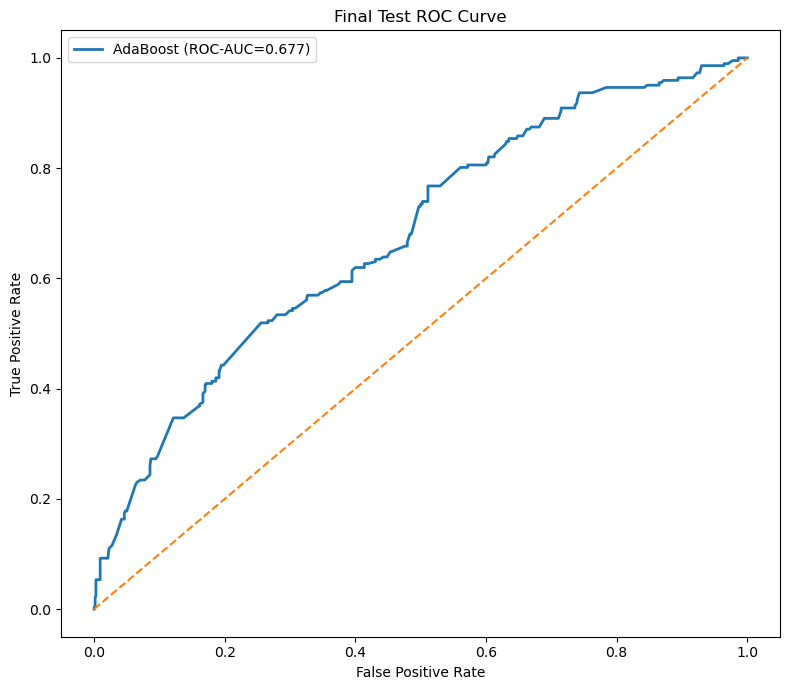

In [41]:
# ==========================================================
# Step-23 : Final Test ROC Curve
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    roc_auc_score
)

fpr_test, tpr_test, _ = roc_curve(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

roc_auc_test = roc_auc_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test
)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    fpr_test,

    tpr_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(ROC-AUC={roc_auc_test:.3f})"
)

plt.plot(
    [
        0,
        1
    ],
    [
        0,
        1
    ],
    linestyle="--"
)

plt.xlabel(
    "False Positive Rate"
)

plt.ylabel(
    "True Positive Rate"
)

plt.title(
    "Final Test ROC Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

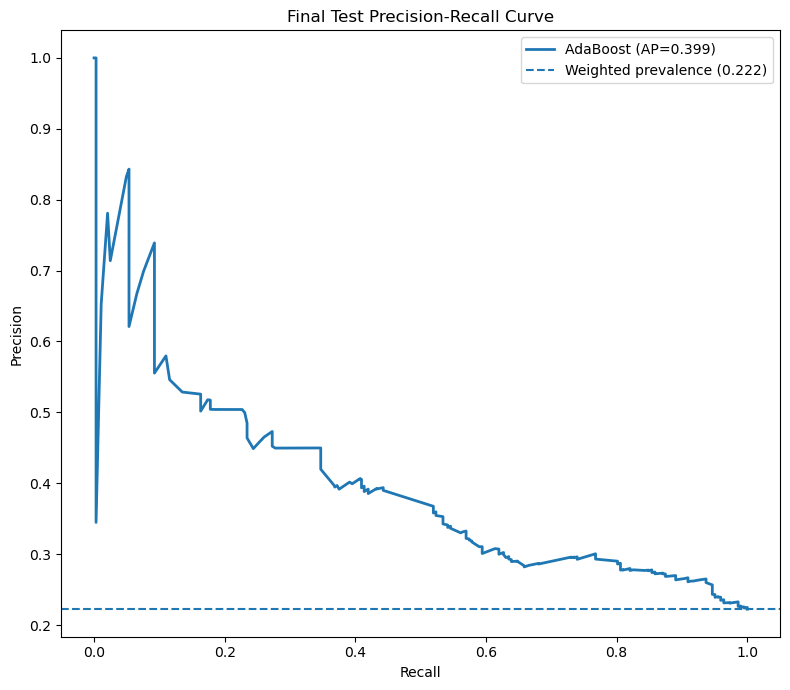

In [42]:
# ==========================================================
# Step-24 : FINAL TEST PRECISION-RECALL CURVE
# ==========================================================

import matplotlib.pyplot as plt

from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision_test, recall_test, _ = (

    precision_recall_curve(

        y_test,

        y_prob,

        sample_weight=
            weights_test

    )

)

ap_test = average_precision_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)

weighted_test_prevalence = np.average(

    np.asarray(
        y_test,
        dtype=float
    ),

    weights=
        weights_test

)

plt.figure(
    figsize=(
        8,
        7
    )
)

plt.plot(

    recall_test,

    precision_test,

    linewidth=2,

    label=
        f"{best_model_name} "
        f"(AP={ap_test:.3f})"

)

plt.axhline(

    weighted_test_prevalence,

    linestyle="--",

    label=
        f"Weighted prevalence "
        f"({weighted_test_prevalence:.3f})"

)

plt.xlabel(
    "Recall"
)

plt.ylabel(
    "Precision"
)

plt.title(
    "Final Test Precision-Recall Curve"
)

plt.legend()

plt.tight_layout()

plt.show()

In [43]:
# ==========================================================
# Step-25 : POST HOC residual spatial diagnostics
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.neighbors import (
    BallTree
)

from libpysal.weights import (
    W
)

from esda.moran import (
    Moran,
    Moran_Local
)

from statsmodels.stats.multitest import (
    multipletests
)


print("=" * 78)

print(
    "STEP-25 : POST HOC RESIDUAL "
    "SPATIAL DIAGNOSTICS"
)

print("=" * 78)


print(
    "Exploratory only — these analyses "
    "do not modify the locked model."
)


# ==========================================================
# 1. Weighted cluster residuals
# ==========================================================

residual_df = pd.DataFrame({

    "dhsclust":
        np.asarray(
            spatial_clusters_test
        ),

    "lon":
        np.asarray(
            coords_test
        )[:, 0],

    "lat":
        np.asarray(
            coords_test
        )[:, 1],

    "residual":

        np.asarray(
            y_test,
            dtype=float
        )

        -

        np.asarray(
            y_prob,
            dtype=float
        ),

    "survey_weight":
        np.asarray(
            weights_test,
            dtype=float
        )

})


cluster_rows = []


for cluster_id, g in (

    residual_df

    .groupby(
        "dhsclust",
        sort=False
    )

):

    valid = (

        np.isfinite(
            g[
                "residual"
            ]
        )

        &

        np.isfinite(
            g[
                "survey_weight"
            ]
        )

        &

        (
            g[
                "survey_weight"
            ]
            >
            0
        )

    )


    if not valid.any():

        continue


    cluster_rows.append({

        "dhsclust":
            cluster_id,

        "lon":
            float(
                g[
                    "lon"
                ].iloc[0]
            ),

        "lat":
            float(
                g[
                    "lat"
                ].iloc[0]
            ),

        "residual":

            float(

                np.average(

                    g.loc[
                        valid,
                        "residual"
                    ],

                    weights=
                        g.loc[
                            valid,
                            "survey_weight"
                        ]

                )

            )

    })


cluster_residual = pd.DataFrame(
    cluster_rows
).reset_index(
    drop=True
)


# ==========================================================
# 2. Symmetrized Haversine KNN
# ==========================================================

def build_symmetrized_knn_w(

    cluster_frame,

    k

):

    if len(
        cluster_frame
    ) <= k:

        raise ValueError(

            f"Need more than {k} clusters."

        )


    coords_rad = np.radians(

        cluster_frame[
            [
                "lat",
                "lon"
            ]
        ]

        .to_numpy(
            dtype=float
        )

    )


    tree = BallTree(

        coords_rad,

        metric=
            "haversine"

    )


    candidate = tree.query(

        coords_rad,

        k=
            k + 1,

        return_distance=False

    )


    directed = {

        i:

            set(

                int(j)

                for j
                in row

                if int(j) != i

            )

        for i, row
        in enumerate(
            candidate
        )

    }


    directed = {

        i:
            set(
                list(neigh)[:k]
            )

        for i, neigh
        in directed.items()

    }


    sym = {

        i:
            set()

        for i
        in range(
            len(
                cluster_frame
            )
        )

    }


    for i, neigh in directed.items():

        for j in neigh:

            sym[i].add(
                j
            )

            sym[j].add(
                i
            )


    neighbors = {

        i:
            sorted(v)

        for i, v
        in sym.items()

    }


    weights = {

        i:

            [
                1.0
            ]
            *
            len(v)

        for i, v
        in neighbors.items()

    }


    w = W(

        neighbors,
        weights,

        silence_warnings=True

    )


    w.transform = (
        "R"
    )


    return (
        w,
        directed
    )


# ==========================================================
# 3. K sensitivity
# ==========================================================

spatial_k_rows = []

primary_objects = {}


for k in K_SENSITIVITY_VALUES:

    if len(
        cluster_residual
    ) <= k:

        continue


    w_k, directed_k = (

        build_symmetrized_knn_w(

            cluster_residual,
            k

        )

    )


    np.random.seed(

        GLOBAL_MORAN_SEED
        +
        int(k)

    )


    moran_k = Moran(

        cluster_residual[
            "residual"
        ].to_numpy(
            dtype=float
        ),

        w_k,

        permutations=
            MORAN_PERMUTATIONS

    )


    spatial_k_rows.append({

        "K":
            int(k),

        "Symmetrized":
            True,

        "Connected_Components":
            int(
                w_k.n_components
            ),

        "Moran_I":
            float(
                moran_k.I
            ),

        "Expected_I":
            float(
                moran_k.EI
            ),

        "Permutation_p":
            float(
                moran_k.p_sim
            ),

        "Permutations":
            int(
                MORAN_PERMUTATIONS
            ),

        "Seed":

            int(

                GLOBAL_MORAN_SEED
                +
                int(k)

            )

    })


    if int(k) == int(
        K_NEIGHBORS
    ):

        primary_objects = {

            "w":
                w_k,

            "moran":
                moran_k,

            "directed":
                directed_k

        }


spatial_k_sensitivity_df = pd.DataFrame(
    spatial_k_rows
)


print(
    "\nGlobal Moran's I sensitivity:"
)


display(

    spatial_k_sensitivity_df

    .round(4)

)


if not primary_objects:

    raise RuntimeError(

        "Primary K unavailable."

    )


w_residual = (
    primary_objects[
        "w"
    ]
)


moran_residual = (
    primary_objects[
        "moran"
    ]
)


print(
    "\nPrimary K:",
    K_NEIGHBORS
)


print(
    "Connected components:",
    int(
        w_residual.n_components
    )
)


print(
    "Moran I:",
    round(
        float(
            moran_residual.I
        ),
        4
    )
)


print(
    "Permutation p:",
    round(
        float(
            moran_residual.p_sim
        ),
        4
    )
)


if moran_residual.p_sim < 0.05:

    print(
        "Residual global spatial autocorrelation "
        "remains significant and must be reported."
    )

else:

    print(
        "No significant global residual spatial "
        "autocorrelation at primary K."
    )


# ==========================================================
# 4. Local Moran + FDR
# ==========================================================

local_moran_residual = Moran_Local(

    cluster_residual[
        "residual"
    ].to_numpy(
        dtype=float
    ),

    w_residual,

    permutations=
        MORAN_PERMUTATIONS,

    geoda_quads=False,

    seed=
        GLOBAL_MORAN_SEED

)


local_p_raw = np.asarray(

    local_moran_residual.p_sim,

    dtype=float

)


(
    local_reject_fdr,
    local_p_fdr,
    _,
    _

) = multipletests(

    local_p_raw,

    alpha=0.05,

    method=
        "fdr_bh"

)


cluster_residual[
    "Local_Moran_I"
] = np.asarray(

    local_moran_residual.Is,

    dtype=float

)


cluster_residual[
    "Local_Moran_p_raw"
] = local_p_raw


cluster_residual[
    "Local_Moran_p_FDR"
] = local_p_fdr


cluster_residual[
    "Local_Moran_FDR_Significant"
] = local_reject_fdr


print(
    "FDR-significant local clusters:",
    int(
        local_reject_fdr.sum()
    )
)


# ==========================================================
# 5. DHS GPS displacement stress test
# ==========================================================

def _perturb_coords_km(

    lat,
    lon,
    radius_km,
    rng

):

    r = (

        radius_km

        *

        np.sqrt(
            rng.random(
                len(lat)
            )
        )

    )


    theta = (

        2
        *
        np.pi
        *
        rng.random(
            len(lat)
        )

    )


    dlat = (

        r
        *
        np.cos(
            theta
        )

        /
        111.32

    )


    dlon = (

        r
        *
        np.sin(
            theta
        )

        /

        (

            111.32

            *

            np.maximum(

                np.cos(

                    np.radians(
                        lat
                    )

                ),

                0.2

            )

        )

    )


    return (

        lat + dlat,

        lon + dlon

    )


coords_orig = (

    cluster_residual[
        [
            "lat",
            "lon"
        ]
    ]

    .to_numpy(
        dtype=float
    )

)


_, original_directed = (

    build_symmetrized_knn_w(

        cluster_residual,

        K_NEIGHBORS

    )

)


GPS_STRESS_RADIUS_KM = 5.0

GPS_STRESS_REPLICATES = 100


rng = np.random.default_rng(
    18018
)


retention = []


for _ in range(
    GPS_STRESS_REPLICATES
):

    plat, plon = (

        _perturb_coords_km(

            coords_orig[
                :,
                0
            ],

            coords_orig[
                :,
                1
            ],

            GPS_STRESS_RADIUS_KM,

            rng

        )

    )


    temp = (
        cluster_residual.copy()
    )


    temp[
        "lat"
    ] = plat


    temp[
        "lon"
    ] = plon


    _, perturbed_directed = (

        build_symmetrized_knn_w(

            temp,

            K_NEIGHBORS

        )

    )


    cluster_scores = []


    for i in original_directed:

        a = set(
            original_directed[i]
        )

        b = set(
            perturbed_directed[i]
        )


        cluster_scores.append(

            len(
                a & b
            )

            /

            max(
                1,
                len(a)
            )

        )


    retention.append(

        float(
            np.mean(
                cluster_scores
            )
        )

    )


gps_displacement_sensitivity_summary = pd.DataFrame([{

    "Stress_Radius_km":
        GPS_STRESS_RADIUS_KM,

    "Replicates":
        GPS_STRESS_REPLICATES,

    "Mean_Neighbor_Retention":

        float(
            np.mean(
                retention
            )
        ),

    "P2_5":

        float(
            np.quantile(
                retention,
                0.025
            )
        ),

    "P97_5":

        float(
            np.quantile(
                retention,
                0.975
            )
        ),

    "Scope":

        (
            "KNN-neighbor identity only; "
            "not environmental raster re-extraction"
        )

}])


print(
    "\nDHS coordinate displacement stress test:"
)


display(

    gps_displacement_sensitivity_summary

    .round(4)

)


print(
    "NOTE: full exposure displacement sensitivity "
    "requires original environmental raster/products."
)


# ==========================================================
# SAVE
# ==========================================================

cluster_residual.to_csv(

    OUTPUT_DIR
    /
    "residual_spatial_cluster_results.csv",

    index=False

)


spatial_k_sensitivity_df.to_csv(

    OUTPUT_DIR
    /
    "residual_moran_K_sensitivity.csv",

    index=False

)


gps_displacement_sensitivity_summary.to_csv(

    OUTPUT_DIR
    /
    "gps_displacement_neighbor_sensitivity.csv",

    index=False

)


print(
    "\n✓ deterministic Moran seed"
)

print(
    "✓ K sensitivity"
)

print(
    "✓ symmetrized KNN"
)

print(
    "✓ connectivity reported"
)

print(
    "✓ GPS displacement stress test"
)

STEP-25 : POST HOC RESIDUAL SPATIAL DIAGNOSTICS
Exploratory only — these analyses do not modify the locked model.

Global Moran's I sensitivity:


,K,Symmetrized,Connected_Components,Moran_I,Expected_I,Permutation_p,Permutations,Seed
0,3,True,3,0.1524,-0.0075,0.011,999,45
1,5,True,2,0.0536,-0.0075,0.099,999,47
2,7,True,1,0.0358,-0.0075,0.124,999,49
3,10,True,1,0.0340,-0.0075,0.116,999,52



Primary K: 5
Connected components: 2
Moran I: 0.0536
Permutation p: 0.099
No significant global residual spatial autocorrelation at primary K.
FDR-significant local clusters: 0


C:\Users\Tc\AppData\Roaming\Python\Python313\site-packages\esda\crand.py:142: DeprecationWarning: The alternative hypothesis for conditional randomization is changing in the next major release of esda. We recommend setting alternative='two-sided', which will generally double the p-value returned. To retain the current behavior, set alternative='directed'. We strongly recommend moving to alternative='two-sided'.
  warnings.warn(



DHS coordinate displacement stress test:


,Stress_Radius_km,Replicates,Mean_Neighbor_Retention,P2_5,P97_5,Scope
0,5.0,100,0.9158,0.8985,0.9314,KNN-neighbor identity only; not environmental ...


NOTE: full exposure displacement sensitivity requires original environmental raster/products.

✓ deterministic Moran seed
✓ K sensitivity
✓ symmetrized KNN
✓ connectivity reported
✓ GPS displacement stress test


In [44]:
# ==========================================================
# Step-26 : Conditional Post Hoc Domain Ablation
#           + paired PSU-bootstrap ΔAUC CI
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    roc_auc_score
)


print("=" * 78)

print(
    "STEP-26 : CONDITIONAL POST HOC DOMAIN ABLATION"
)

print("=" * 78)


print(
    "Feature selection is NOT repeated. "
    "Therefore this is conditional post hoc ablation, "
    "not total domain predictive contribution."
)


socio_domain = [

    f
    for f in model_features

    if f in
    socio_encoded_features

]


env_domain = [

    f
    for f in model_features

    if f in
    env_vars

]


wx_domain = [

    f
    for f in model_features

    if f in
    wx_vars

]


coord_domain = [

    f
    for f in [
        "lat",
        "lon"
    ]

    if f in
    model_features

]


ablation_sets = {

    "Full locked model":
        model_features.copy(),

    "Without socioeconomic predictors":

        [
            f
            for f in model_features

            if f not in
            socio_domain
        ],

    "Without direct environmental predictors":

        [
            f
            for f in model_features

            if f not in
            env_domain
        ],

    "Without WX-derived environmental predictors":

        [
            f
            for f in model_features

            if f not in
            wx_domain
        ],

    "Without all environmental information (direct + WX)":

        [
            f
            for f in model_features

            if f not in
            set(
                env_domain
                +
                wx_domain
            )
        ],

    "Without coordinates":

        [
            f
            for f in model_features

            if f not in
            coord_domain
        ]

}


ablation_probabilities = {

    "Full locked model":
        np.asarray(
            y_prob,
            dtype=float
        )

}


ablation_rows = [{

    "Analysis":
        "Full locked model",

    "N_Features":
        len(
            model_features
        ),

    "ROC_AUC":

        float(

            roc_auc_score(

                y_test,
                y_prob,

                sample_weight=
                    weights_test

            )

        ),

    "Ablation_Type":
        "Locked primary model"

}]


for label, features in (
    ablation_sets.items()
):

    if (

        label
        ==
        "Full locked model"

        or

        len(features) == 0

    ):

        continue


    scaler_ab = StandardScaler()


    scaler_ab.fit(

        X_train_raw[
            features
        ],

        sample_weight=
            weights_train

    )


    X_train_ab = (

        scaler_ab.transform(

            X_train_raw[
                features
            ]

        )

    )


    X_test_ab = (

        scaler_ab.transform(

            X_test_raw[
                features
            ]

        )

    )


    model_ab = clone(
        best_model_template
    )


    model_ab.fit(

        X_train_ab,
        y_train,

        sample_weight=
            combined_train_weights

    )


    prob_ab = (

        model_ab

        .predict_proba(
            X_test_ab
        )[:, 1]

    )


    ablation_probabilities[
        label
    ] = np.asarray(

        prob_ab,

        dtype=float

    )


    ablation_rows.append({

        "Analysis":
            label,

        "N_Features":
            len(
                features
            ),

        "ROC_AUC":

            float(

                roc_auc_score(

                    y_test,
                    prob_ab,

                    sample_weight=
                        weights_test

                )

            ),

        "Ablation_Type":

            (
                "Conditional post hoc; "
                "selection not repeated"
            )

    })


ablation_df = pd.DataFrame(
    ablation_rows
)


full_auc = float(

    ablation_df

    .loc[

        ablation_df[
            "Analysis"
        ]
        ==
        "Full locked model",

        "ROC_AUC"

    ]

    .iloc[0]

)


ablation_df[
    "Delta_ROC_AUC_vs_Full"
] = (

    ablation_df[
        "ROC_AUC"
    ]

    -

    full_auc

)


# ==========================================================
# Paired PSU bootstrap ΔAUC
# ==========================================================

rng = np.random.default_rng(
    26026
)


labels = [

    x
    for x in
    ablation_probabilities

    if x !=
    "Full locked model"

]


delta_store = {

    label:
        []

    for label
    in labels

}


for _ in range(
    N_BOOTSTRAP_FINAL
):

    sampled_indices = []


    for s in pd.unique(
        strata_test
    ):

        smask = (

            np.asarray(
                strata_test
            )
            ==
            s

        )


        psus = pd.unique(

            np.asarray(
                groups_test
            )[smask]

        )


        sampled_psus = rng.choice(

            psus,

            size=
                len(psus),

            replace=True

        )


        for p in sampled_psus:

            sampled_indices.extend(

                np.flatnonzero(

                    smask

                    &

                    (
                        np.asarray(
                            groups_test
                        )
                        ==
                        p
                    )

                )

                .tolist()

            )


    idx = np.asarray(
        sampled_indices,
        dtype=int
    )


    if (

        len(idx) == 0

        or

        np.unique(

            np.asarray(
                y_test
            )[idx]

        ).size < 2

    ):

        continue


    yb = np.asarray(
        y_test,
        dtype=int
    )[idx]


    wb = np.asarray(
        weights_test,
        dtype=float
    )[idx]


    full_auc_b = roc_auc_score(

        yb,

        ablation_probabilities[
            "Full locked model"
        ][idx],

        sample_weight=
            wb

    )


    for label in labels:

        try:

            ab_auc_b = roc_auc_score(

                yb,

                ablation_probabilities[
                    label
                ][idx],

                sample_weight=
                    wb

            )


            delta_store[
                label
            ].append(

                float(

                    ab_auc_b
                    -
                    full_auc_b

                )

            )


        except Exception:

            pass


ci_low = []

ci_high = []

valid_n = []


for _, row in (

    ablation_df.iterrows()

):

    label = row[
        "Analysis"
    ]


    if label == (
        "Full locked model"
    ):

        ci_low.append(
            0.0
        )

        ci_high.append(
            0.0
        )

        valid_n.append(
            N_BOOTSTRAP_FINAL
        )


    else:

        vals = np.asarray(

            delta_store[
                label
            ],

            dtype=float

        )


        if len(vals):

            lo, hi = np.quantile(

                vals,

                [
                    0.025,
                    0.975
                ]

            )

        else:

            lo = np.nan
            hi = np.nan


        ci_low.append(

            float(lo)

            if np.isfinite(lo)

            else np.nan

        )


        ci_high.append(

            float(hi)

            if np.isfinite(hi)

            else np.nan

        )


        valid_n.append(
            int(
                len(vals)
            )
        )


ablation_df[
    "Delta_AUC_CI_Lower"
] = ci_low


ablation_df[
    "Delta_AUC_CI_Upper"
] = ci_high


ablation_df[
    "Valid_Paired_Bootstrap_Reps"
] = valid_n


print(
    "\nConditional post hoc ablation:"
)


display(
    ablation_df.round(4)
)


ablation_df.to_csv(

    OUTPUT_DIR
    /
    "conditional_ablation_paired_delta_auc.csv",

    index=False

)


print(
    "\n✓ Direct environmental and WX information "
    "are distinguished."
)

print(
    "✓ Separate direct+WX removal included."
)

print(
    "✓ Paired PSU-bootstrap ΔAUC CI included."
)

print(
    "✓ No model redesign based on final test."
)

STEP-26 : CONDITIONAL POST HOC DOMAIN ABLATION
Feature selection is NOT repeated. Therefore this is conditional post hoc ablation, not total domain predictive contribution.

Conditional post hoc ablation:


,Analysis,N_Features,ROC_AUC,Ablation_Type,Delta_ROC_AUC_vs_Full,Delta_AUC_CI_Lower,Delta_AUC_CI_Upper,Valid_Paired_Bootstrap_Reps
0,Full locked model,26,0.6773,Locked primary model,0.0000,0.0000,0.0000,2000
1,Without socioeconomic predictors,11,0.5366,Conditional post hoc; selection not repeated,-0.1407,-0.2094,-0.0781,2000
2,Without direct environmental predictors,21,0.6770,Conditional post hoc; selection not repeated,-0.0004,-0.0189,0.0187,2000
3,Without WX-derived environmental predictors,22,0.6937,Conditional post hoc; selection not repeated,0.0164,-0.0077,0.0432,2000
4,Without all environmental information (direct ...,17,0.6914,Conditional post hoc; selection not repeated,0.0141,-0.0102,0.0392,2000
5,Without coordinates,24,0.6662,Conditional post hoc; selection not repeated,-0.0111,-0.0229,0.0002,2000



✓ Direct environmental and WX information are distinguished.
✓ Separate direct+WX removal included.
✓ Paired PSU-bootstrap ΔAUC CI included.
✓ No model redesign based on final test.


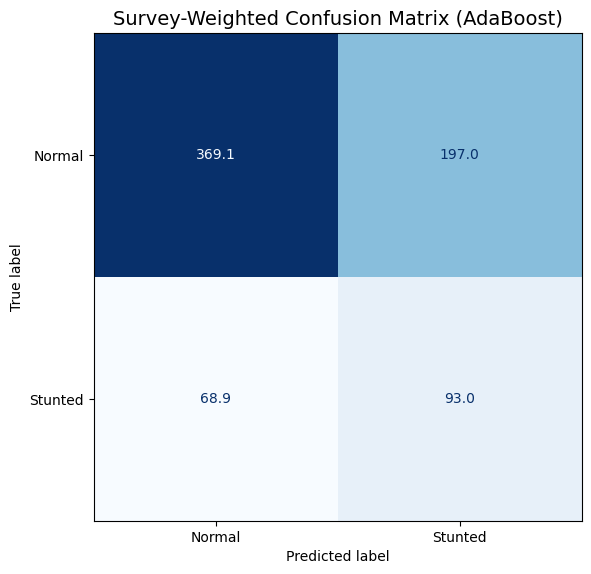

In [45]:
# ==========================================================
# Step-27 : Survey-Weighted Confusion Matrix
# ==========================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

cm = confusion_matrix(

    y_test,

    y_pred,

    labels=[
        0,
        1
    ],

    sample_weight=
        weights_test

)

disp = ConfusionMatrixDisplay(

    confusion_matrix=
        cm,

    display_labels=[
        "Normal",
        "Stunted"
    ]

)

fig, ax = plt.subplots(
    figsize=(6, 6)
)

disp.plot(

    cmap="Blues",

    ax=ax,

    colorbar=False,

    values_format=".1f"

)

plt.title(

    f"Survey-Weighted Confusion Matrix "
    f"({best_model_name})",

    fontsize=14

)

plt.tight_layout()

plt.show()

In [46]:
# ==========================================================
# Step-28 : Survey-Weighted Classification Report
# ==========================================================

from sklearn.metrics import classification_report

print("=" * 70)
print("SURVEY-WEIGHTED CLASSIFICATION REPORT")
print("=" * 70)

print(

    classification_report(

        y_test,

        y_pred,

        target_names=[

            "Normal",

            "Stunted"

        ],

        sample_weight=
            weights_test,

        digits=4,

        zero_division=0

    )

)

SURVEY-WEIGHTED CLASSIFICATION REPORT
              precision    recall  f1-score   support

      Normal     0.8427    0.6520    0.7352 566.149248999999
     Stunted     0.3206    0.5743    0.4115 161.87757000000002

    accuracy                         0.6347 728.026818999999
   macro avg     0.5816    0.6131    0.5733 728.026818999999
weighted avg     0.7266    0.6347    0.6632 728.026818999999



In [48]:
# ============================================================
# FIX BEFORE STEP-29
# Create final_prediction_components required by workspace save
# ============================================================

final_prediction_components = {

    "model_name":
        best_model_name,

    "training_weight_strategy":
        best_weight_strategy,

    "final_threshold":
        float(final_threshold),

    "probability_output":
        "calibrated probability",

    "raw_probability_available":
        True,

    "calibrated_probability_available":
        True,

    "prediction_rule":
        "calibrated probability >= locked final threshold",

    "threshold_source":
        "OOF calibrated development predictions",

    "threshold_metric":
        "weighted MCC",

    "calibration_method":
        type(probability_calibrator).__name__,

    "feature_selection":
        "grouped backward sequential feature selection",

    "selected_groups":
        list(selected_groups),

    "n_selected_groups":
        int(len(selected_groups)),

    "n_expanded_model_features":
        int(len(model_features)),

    "validation_scope":
        "held-out comparative internal test set",

    "test_n":
        int(len(y_test)),

    "test_positive_n":
        int(np.sum(np.asarray(y_test) == 1)),

    "test_negative_n":
        int(np.sum(np.asarray(y_test) == 0)),

    "final_prediction_n":
        int(len(y_pred)),

    "final_probability_n":
        int(len(y_prob)),

    "final_raw_probability_n":
        int(len(y_prob_raw)),
}


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------

assert len(y_pred) == len(y_test)
assert len(y_prob) == len(y_test)
assert len(y_prob_raw) == len(y_test)

assert np.isfinite(
    np.asarray(y_prob, dtype=float)
).all()

assert np.isfinite(
    np.asarray(y_prob_raw, dtype=float)
).all()


print("=" * 78)
print("FINAL PREDICTION COMPONENTS CREATED")
print("=" * 78)

for key, value in final_prediction_components.items():

    if key != "selected_groups":

        print(
            f"{key}: {value}"
        )

print(
    "\nSelected groups:",
    final_prediction_components[
        "selected_groups"
    ]
)

print(
    "\n✓ final_prediction_components is now available."
)

FINAL PREDICTION COMPONENTS CREATED
model_name: AdaBoost
training_weight_strategy: SurveyWeightOnly
final_threshold: 0.22331067913309996
probability_output: calibrated probability
raw_probability_available: True
calibrated_probability_available: True
prediction_rule: calibrated probability >= locked final threshold
threshold_source: OOF calibrated development predictions
threshold_metric: weighted MCC
calibration_method: LogisticRegression
feature_selection: grouped backward sequential feature selection
n_selected_groups: 15
n_expanded_model_features: 26
validation_scope: held-out comparative internal test set
test_n: 716
test_positive_n: 163
test_negative_n: 553
final_prediction_n: 716
final_probability_n: 716
final_raw_probability_n: 716

Selected groups: ['Maternal_Height', 'BMI', 'Child_age_months', 'Father_education', 'Multiple_birth_status', 'Short_rapid_breaths', 'temperature_celsius', 'relative_humidity_pct', 'soil_moisture', 'flood_occurrence_pct', 'pet_mm', 'wx_temperature_ce

In [49]:
print(
    "final_prediction_components ->",
    "final_prediction_components" in globals()
)

final_prediction_components -> True


In [50]:
# ==========================================================
# Step-29 : Save Final Reviewer-Aligned Spatial ML Workspace
#
# IMPORTANT:
# - Clears old/stale saved workspace first
# - Saves every object required by Step-31
# - Uses Reviewer_Final_Outputs/SpatialML_Saved
# - Does NOT refit any model
# - Does NOT rerun SFS
# ==========================================================

import os
import shutil
import joblib
import numpy as np
from pathlib import Path


print("=" * 78)
print("STEP-29 : SAVING FINAL SPATIAL ML WORKSPACE")
print("=" * 78)


# ==========================================================
# 0. OUTPUT PATH
# ==========================================================

if "OUTPUT_DIR" not in globals():

    if "PROJECT_ROOT" not in globals():

        raise RuntimeError(
            "Neither OUTPUT_DIR nor PROJECT_ROOT exists. "
            "Run the setup cells first."
        )

    OUTPUT_DIR = (
        Path(PROJECT_ROOT)
        /
        "Reviewer_Final_Outputs"
    )


OUTPUT_DIR = Path(
    OUTPUT_DIR
)


OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


save_path = (
    OUTPUT_DIR
    /
    "SpatialML_Saved"
)


print(
    "Workspace destination:",
    save_path
)


# ==========================================================
# 1. CHECK THAT REQUIRED OBJECTS EXIST IN MEMORY
# ==========================================================
#
# If any of these are missing, do NOT create a partial
# workspace. This prevents Step-31 from restoring a
# corrupted or incomplete run.
# ==========================================================

required_objects = [

    # Final model
    "final_model",
    "best_model_name",
    "models_default",
    "best_weight_strategy",
    "final_threshold",
    "final_prediction_components",

    # Calibration
    "probability_calibrator",
    "calibration_probability_raw",
    "calibration_probability",

    # Preprocessing
    "scaler",
    "onehot_encoder",
    "nominal_socio_vars",
    "encoded_nominal_columns",
    "cv",

    # Feature selection
    "model_features",
    "selected_vars",
    "selected_groups",
    "group_to_columns",
    "sfs_df",
    "sfs_group_df",
    "sfs_path_df",
    "sfs_feature_count_sensitivity_df",

    # Feature groups
    "wx_vars",
    "env_vars",
    "socio_vars",
    "socio_vars_raw",
    "final_predictor_definition_df",
    "CATEGORY_CODEBOOK_LEVELS",
    "category_codebook_df",

    # Model-selection / uncertainty
    "model_selection_uncertainty_df",
    "final_metric_ci_df",

    # Development data
    "X_train_raw",
    "X_train",
    "y_train",

    # Calibration data
    "X_calibration_raw",
    "X_calibration",
    "y_calibration",

    # Test data
    "X_test_raw",
    "X_test",
    "y_test",

    # Survey design
    "groups_train",
    "groups_calibration",
    "groups_test",
    "groups",

    "weights_train",
    "weights_calibration",
    "weights_test",
    "final_fit_weights",
    "survey_weights",

    "strata_train",
    "strata_calibration",
    "strata_test",
    "strata",

    # Spatial design
    "spatial_clusters_train",
    "spatial_clusters_calibration",
    "spatial_clusters_test",
    "spatial_clusters",

    "coords_train",
    "coords_calibration",
    "coords_test",
    "coordinates",

    # Split indices
    "development_pool_idx",
    "train_idx",
    "calibration_idx",
    "test_idx",

    # Predictions
    "y_pred",
    "y_prob",
    "y_prob_raw",

    # Tables
    "default_df",
    "ranking_df",
    "weight_sensitivity_df",
    "final_test_metrics_df",

    # Data / settings
    "df",
    "y",
    "K_NEIGHBORS",
    "target",
    "spatial_interpretation_note",
    "child_age_status",
    "child_age_candidates",
]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()

]


if missing_objects:

    print(
        "\nMISSING OBJECTS:"
    )

    for name in missing_objects:

        print(
            " -",
            name
        )


    raise RuntimeError(

        "\nStep-29 was NOT allowed to save a partial workspace.\n"
        "The objects listed above are missing from the current "
        "kernel session.\n\n"
        "Do NOT run Step-31 yet."
    )


print(
    "\n✓ All required in-memory objects are available."
)


# ==========================================================
# 2. OPTIONAL / COMPATIBILITY OBJECTS
# ==========================================================

# ----------------------------------------------------------
# Reviewer-final analysis stratum
# ----------------------------------------------------------

if "analysis_strata" in df.columns:

    strata_all_for_save = np.asarray(
        df["analysis_strata"]
    )

else:

    strata_all_for_save = np.asarray(
        strata
    )


# ----------------------------------------------------------
# V022 retained separately for audit
# ----------------------------------------------------------

if "strata_v022" in df.columns:

    strata_v022_all_for_save = np.asarray(
        df["strata_v022"]
    )

elif "strata_v022_all" in globals():

    strata_v022_all_for_save = np.asarray(
        strata_v022_all
    )

else:

    strata_v022_all_for_save = (
        strata_all_for_save.copy()
    )


# ----------------------------------------------------------
# Current reviewer-final design settings
# ----------------------------------------------------------

SURVEY_STRATA_VAR_TO_SAVE = globals().get(
    "SURVEY_STRATA_VAR",
    "strata_v022"
)


STRATA_AUDIT_STATUS_TO_SAVE = globals().get(

    "STRATA_AUDIT_STATUS",

    "VERIFIED_RELEASED_BDHS2022_V022_16_VARIANCE_STRATA"

)


VALIDATION_TERMINOLOGY_TO_SAVE = globals().get(

    "VALIDATION_TERMINOLOGY",

    "held-out internal validation"

)


GEOSHAPLEY_BACKGROUND_SIZE_TO_SAVE = globals().get(
    "GEOSHAPLEY_BACKGROUND_SIZE",
    100
)


K_SENSITIVITY_VALUES_TO_SAVE = globals().get(
    "K_SENSITIVITY_VALUES",
    [3, 5, 7, 10]
)


N_BOOTSTRAP_FINAL_TO_SAVE = globals().get(
    "N_BOOTSTRAP_FINAL",
    2000
)


N_BOOTSTRAP_DEVELOPMENT_TO_SAVE = globals().get(
    "N_BOOTSTRAP_DEVELOPMENT",
    2000
)


MORAN_PERMUTATIONS_TO_SAVE = globals().get(
    "MORAN_PERMUTATIONS",
    999
)


GLOBAL_MORAN_SEED_TO_SAVE = globals().get(
    "GLOBAL_MORAN_SEED",
    42
)


# ==========================================================
# 3. SANITY CHECKS BEFORE WRITING ANY FILE
# ==========================================================

if len(
    X_train
) != len(
    y_train
):

    raise RuntimeError(
        "X_train and y_train length mismatch."
    )


if len(
    X_calibration
) != len(
    y_calibration
):

    raise RuntimeError(
        "X_calibration and y_calibration length mismatch."
    )


if len(
    X_test
) != len(
    y_test
):

    raise RuntimeError(
        "X_test and y_test length mismatch."
    )


if len(
    y_prob
) != len(
    y_test
):

    raise RuntimeError(
        "y_prob and y_test length mismatch."
    )


if len(
    y_prob_raw
) != len(
    y_test
):

    raise RuntimeError(
        "y_prob_raw and y_test length mismatch."
    )


if len(
    model_features
) != X_train.shape[1]:

    raise RuntimeError(

        "model_features count does not match "
        "X_train column count."

    )


if not isinstance(
    final_metric_ci_df,
    __import__("pandas").DataFrame
):

    raise TypeError(
        "final_metric_ci_df must be a pandas DataFrame."
    )


required_ci_columns = {

    "Metric",
    "Estimate",
    "CI_Lower",
    "CI_Upper"

}


if not required_ci_columns.issubset(

    set(
        final_metric_ci_df.columns
    )

):

    raise RuntimeError(

        "final_metric_ci_df does not have "
        "the reviewer-final Step-22 structure."
    )


# ==========================================================
# 4. DELETE OLD/STale WORKSPACE ONLY AFTER VALIDATION
# ==========================================================

if save_path.exists():

    print(
        "\nRemoving old saved workspace..."
    )

    shutil.rmtree(
        save_path
    )


save_path.mkdir(
    parents=True,
    exist_ok=True
)


print(
    "✓ Clean workspace folder created."
)


# ==========================================================
# 5. FINAL PREDICTION COMPONENT DESCRIPTION
# ==========================================================
#
# Preserve existing object, but add reviewer-final metadata
# when it is a dictionary.
# ==========================================================

if isinstance(
    final_prediction_components,
    dict
):

    final_prediction_components = dict(
        final_prediction_components
    )


    final_prediction_components.update({

        "validation_type":
            VALIDATION_TERMINOLOGY_TO_SAVE,

        "survey_strata_variable":
            SURVEY_STRATA_VAR_TO_SAVE,

        "strata_audit_status":
            STRATA_AUDIT_STATUS_TO_SAVE,

        "calibration":
            "reserved calibration subset",

        "threshold_selection":
            "OOF calibrated probabilities",

        "threshold_metric":
            "weighted MCC",

        "feature_selection":
            (
                "strict nested grouped backward SFS "
                "using Logistic Regression"
            ),

        "geoshapley_scope":
            (
                "reduced uncalibrated post-hoc "
                "explanatory/surrogate model"
            )

    })


# ==========================================================
# 6. COMPLETE OBJECT DICTIONARY
# ==========================================================

objects_to_save = {

    # ======================================================
    # Final model
    # ======================================================

    "final_base_model.pkl":
        final_model,

    "best_model_name.pkl":
        best_model_name,

    "fixed_model_templates.pkl":
        models_default,

    "best_weight_strategy.pkl":
        best_weight_strategy,

    "final_threshold.pkl":
        final_threshold,

    "final_prediction_components.pkl":
        final_prediction_components,


    # ======================================================
    # Calibration
    # ======================================================

    "probability_calibrator.pkl":
        probability_calibrator,

    "calibration_probability_raw.pkl":
        calibration_probability_raw,

    "calibration_probability.pkl":
        calibration_probability,


    # ======================================================
    # Preprocessing
    # ======================================================

    "final_scaler.pkl":
        scaler,

    "final_onehot_encoder.pkl":
        onehot_encoder,

    "nominal_socio_vars.pkl":
        nominal_socio_vars,

    "encoded_nominal_columns.pkl":
        encoded_nominal_columns,

    "cv.pkl":
        cv,


    # ======================================================
    # Feature selection
    # ======================================================

    "model_features.pkl":
        model_features,

    "selected_variables.pkl":
        selected_vars,

    "selected_groups.pkl":
        selected_groups,

    "group_to_columns.pkl":
        group_to_columns,

    "sfs_results.pkl":
        sfs_df,

    "sfs_group_results.pkl":
        sfs_group_df,

    "sfs_path_results.pkl":
        sfs_path_df,

    "sfs_feature_count_sensitivity.pkl":
        sfs_feature_count_sensitivity_df,


    # ======================================================
    # Predictor groups / metadata
    # ======================================================

    "wx_variables.pkl":
        wx_vars,

    "environment_variables.pkl":
        env_vars,

    "socioeconomic_variables.pkl":
        socio_vars,

    "socioeconomic_variables_raw.pkl":
        socio_vars_raw,

    "predictor_definition.pkl":
        final_predictor_definition_df,

    "category_codebook_levels.pkl":
        CATEGORY_CODEBOOK_LEVELS,

    "category_codebook_table.pkl":
        category_codebook_df,


    # ======================================================
    # Development/model-selection results
    # ======================================================

    "model_selection_uncertainty.pkl":
        model_selection_uncertainty_df,

    "final_metric_ci.pkl":
        final_metric_ci_df,


    # ======================================================
    # Raw matrices
    # ======================================================

    "X_model_development_raw.pkl":
        X_train_raw,

    "X_calibration_raw.pkl":
        X_calibration_raw,

    "X_final_test_raw.pkl":
        X_test_raw,


    # ======================================================
    # Scaled matrices
    # ======================================================

    "X_model_development.pkl":
        X_train,

    "X_calibration.pkl":
        X_calibration,

    "X_final_test.pkl":
        X_test,


    # ======================================================
    # Outcomes
    # ======================================================

    "y_model_development.pkl":
        y_train,

    "y_calibration.pkl":
        y_calibration,

    "y_final_test.pkl":
        y_test,


    # ======================================================
    # PSU groups
    # ======================================================

    "groups_model_development.pkl":
        groups_train,

    "groups_calibration.pkl":
        groups_calibration,

    "groups_final_test.pkl":
        groups_test,

    "all_groups.pkl":
        groups,


    # ======================================================
    # Survey weights
    # ======================================================

    "weights_model_development.pkl":
        weights_train,

    "weights_calibration.pkl":
        weights_calibration,

    "weights_final_test.pkl":
        weights_test,

    "final_fit_weights.pkl":
        final_fit_weights,

    "all_survey_weights.pkl":
        survey_weights,


    # ======================================================
    # Survey strata
    # ======================================================

    "strata_model_development.pkl":
        strata_train,

    "strata_calibration.pkl":
        strata_calibration,

    "strata_final_test.pkl":
        strata_test,

    "all_strata.pkl":
        strata_all_for_save,

    "all_strata_v022.pkl":
        strata_v022_all_for_save,

    "survey_strata_variable.pkl":
        SURVEY_STRATA_VAR_TO_SAVE,

    "strata_audit_status.pkl":
        STRATA_AUDIT_STATUS_TO_SAVE,


    # ======================================================
    # Spatial clusters
    # ======================================================

    "spatial_clusters_model_development.pkl":
        spatial_clusters_train,

    "spatial_clusters_calibration.pkl":
        spatial_clusters_calibration,

    "spatial_clusters_final_test.pkl":
        spatial_clusters_test,

    "all_spatial_clusters.pkl":
        spatial_clusters,


    # ======================================================
    # Coordinates
    # ======================================================

    "coords_model_development.pkl":
        coords_train,

    "coords_calibration.pkl":
        coords_calibration,

    "coords_final_test.pkl":
        coords_test,

    "all_coordinates.pkl":
        coordinates,


    # ======================================================
    # Split indices
    # ======================================================

    "development_pool_idx.pkl":
        development_pool_idx,

    "model_development_idx.pkl":
        train_idx,

    "calibration_idx.pkl":
        calibration_idx,

    "final_test_idx.pkl":
        test_idx,


    # ======================================================
    # Final test predictions
    # ======================================================

    "y_pred.pkl":
        y_pred,

    "y_prob_calibrated.pkl":
        y_prob,

    "y_prob_raw.pkl":
        y_prob_raw,


    # ======================================================
    # Results
    # ======================================================

    "development_cv_results.pkl":
        default_df,

    "ranking_results.pkl":
        ranking_df,

    "weight_sensitivity_results.pkl":
        weight_sensitivity_df,

    "final_test_metrics.pkl":
        final_test_metrics_df,


    # ======================================================
    # Complete analysis data / settings
    # ======================================================

    "final_dataset.pkl":
        df,

    "target_vector.pkl":
        y,

    "K_NEIGHBORS.pkl":
        K_NEIGHBORS,

    "target_name.pkl":
        target,

    "spatial_interpretation_note.pkl":
        spatial_interpretation_note,

    "child_age_status.pkl":
        child_age_status,

    "child_age_candidates.pkl":
        child_age_candidates,


    # ======================================================
    # Reviewer-final scalar settings
    # ======================================================

    "validation_terminology.pkl":
        VALIDATION_TERMINOLOGY_TO_SAVE,

    "geoshapley_background_size.pkl":
        GEOSHAPLEY_BACKGROUND_SIZE_TO_SAVE,

    "K_sensitivity_values.pkl":
        K_SENSITIVITY_VALUES_TO_SAVE,

    "n_bootstrap_final.pkl":
        N_BOOTSTRAP_FINAL_TO_SAVE,

    "n_bootstrap_development.pkl":
        N_BOOTSTRAP_DEVELOPMENT_TO_SAVE,

    "moran_permutations.pkl":
        MORAN_PERMUTATIONS_TO_SAVE,

    "global_moran_seed.pkl":
        GLOBAL_MORAN_SEED_TO_SAVE,
}


# ==========================================================
# 7. SAVE ALL OBJECTS
# ==========================================================

saved_files = []


for filename, obj in objects_to_save.items():

    output_file = (
        save_path
        /
        filename
    )


    joblib.dump(
        obj,
        output_file
    )


    if not output_file.exists():

        raise RuntimeError(

            f"Save operation did not create:\n"
            f"{output_file}"

        )


    saved_files.append(
        output_file
    )


# ==========================================================
# 8. CRITICAL FILE CHECK
# ==========================================================

critical_files = [

    "final_base_model.pkl",
    "best_model_name.pkl",
    "fixed_model_templates.pkl",
    "probability_calibrator.pkl",
    "final_scaler.pkl",
    "final_onehot_encoder.pkl",
    "model_features.pkl",
    "final_metric_ci.pkl",
    "X_model_development.pkl",
    "X_calibration.pkl",
    "X_final_test.pkl",
    "y_model_development.pkl",
    "y_calibration.pkl",
    "y_final_test.pkl",
    "y_prob_calibrated.pkl",
    "final_test_metrics.pkl",
]


missing_saved_files = [

    filename

    for filename in critical_files

    if not (
        save_path
        /
        filename
    ).exists()

]


if missing_saved_files:

    raise RuntimeError(

        "Workspace save is incomplete.\n"
        f"Missing files: {missing_saved_files}"

    )


# ==========================================================
# 9. SAVE HUMAN-READABLE INVENTORY
# ==========================================================

inventory_rows = []


for path in sorted(
    saved_files
):

    inventory_rows.append({

        "File":
            path.name,

        "Bytes":
            int(
                path.stat().st_size
            )

    })


import pandas as pd


workspace_inventory_df = pd.DataFrame(
    inventory_rows
)


workspace_inventory_df.to_csv(

    save_path
    /
    "workspace_inventory.csv",

    index=False

)


# ==========================================================
# 10. FINAL AUDIT
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "WORKSPACE SAVE AUDIT"
)

print(
    "=" * 78
)


print(
    "Saved folder:",
    save_path
)


print(
    "Total saved objects:",
    len(
        objects_to_save
    )
)


print(
    "Critical files present:",
    len(
        critical_files
    )
)


print(
    "\nFirst saved files:"
)


display(
    workspace_inventory_df.head(20)
)


print(
    "\n✓ Old/stale saved artifacts were removed."
)


print(
    "✓ final_base_model.pkl saved."
)


print(
    "✓ probability_calibrator.pkl saved."
)


print(
    "✓ grouped-SFS objects saved."
)


print(
    "✓ reviewer-final final_metric_ci.pkl saved."
)


print(
    "✓ development / calibration / test objects "
    "saved separately."
)


print(
    "✓ survey weights, PSU and strata saved."
)


print(
    "✓ spatial clusters and coordinates saved."
)


print(
    "✓ final predictions and metrics saved."
)


print(
    "✓ workspace_inventory.csv created."
)


print(
    "\nSTEP-29 COMPLETE."
)

STEP-29 : SAVING FINAL SPATIAL ML WORKSPACE
Workspace destination: F:\Thesis\Reviewer_Final_Outputs\SpatialML_Saved

✓ All required in-memory objects are available.

Removing old saved workspace...
✓ Clean workspace folder created.

WORKSPACE SAVE AUDIT
Saved folder: F:\Thesis\Reviewer_Final_Outputs\SpatialML_Saved
Total saved objects: 89
Critical files present: 16

First saved files:


,File,Bytes
0,all_coordinates.pkl,58161
1,all_groups.pkl,29185
2,all_spatial_clusters.pkl,29185
3,all_strata.pkl,29185
4,all_strata_v022.pkl,29185
5,all_survey_weights.pkl,29185
6,best_model_name.pkl,23
7,best_weight_strategy.pkl,31
8,calibration_idx.pkl,4737
9,calibration_probability.pkl,4737



✓ Old/stale saved artifacts were removed.
✓ final_base_model.pkl saved.
✓ probability_calibrator.pkl saved.
✓ grouped-SFS objects saved.
✓ reviewer-final final_metric_ci.pkl saved.
✓ development / calibration / test objects saved separately.
✓ survey weights, PSU and strata saved.
✓ spatial clusters and coordinates saved.
✓ final predictions and metrics saved.
✓ workspace_inventory.csv created.

STEP-29 COMPLETE.


In [51]:
# ==========================================================
# Step-30 : Reproducibility Manifest
# ==========================================================

import os
import sys
import json
import hashlib
import platform
import subprocess

from pathlib import Path

import pandas as pd

from importlib.metadata import (
    version,
    PackageNotFoundError
)


print("=" * 78)

print(
    "STEP-30 : REPRODUCIBILITY MANIFEST"
)

print("=" * 78)


OUTPUT_DIR = Path(
    OUTPUT_DIR
)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


save_path = str(

    OUTPUT_DIR
    /
    "SpatialML_Saved"

)


Path(
    save_path
).mkdir(

    parents=True,

    exist_ok=True

)


packages_to_record = [

    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "statsmodels",
    "scikit-learn",
    "xgboost",
    "lightgbm",
    "catboost",
    "geoshapley",
    "geopandas",
    "libpysal",
    "esda",
    "pyreadstat",
    "joblib",
    "psutil"

]


environment_rows = [{

    "Package":
        "Python",

    "Version":
        platform.python_version()

}]


for package_name in packages_to_record:

    try:

        package_version = version(
            package_name
        )

    except PackageNotFoundError:

        package_version = (
            "NOT INSTALLED"
        )


    environment_rows.append({

        "Package":
            package_name,

        "Version":
            package_version

    })


environment_versions_df = pd.DataFrame(
    environment_rows
)


display(
    environment_versions_df
)


# ==========================================================
# Full package lock
# ==========================================================

try:

    pip_freeze = subprocess.check_output(

        [
            sys.executable,
            "-m",
            "pip",
            "freeze"
        ],

        text=True,

        stderr=
            subprocess.STDOUT

    )

except Exception as exc:

    pip_freeze = (

        f"# pip freeze unavailable: "
        f"{exc}\n"

    )


(
    Path(
        save_path
    )
    /
    "requirements_lock.txt"

).write_text(

    pip_freeze,

    encoding="utf-8"

)


environment_versions_df.to_csv(

    Path(
        save_path
    )
    /
    "package_versions.csv",

    index=False

)


# ==========================================================
# SHA-256
# ==========================================================

def sha256_file(

    path,

    chunk_size=
        1024
        *
        1024

):

    path = Path(
        path
    )


    h = hashlib.sha256()


    with path.open(
        "rb"
    ) as f:

        while True:

            chunk = f.read(
                chunk_size
            )


            if not chunk:

                break


            h.update(
                chunk
            )


    return h.hexdigest()


input_paths = [

    BDHS_FILE,
    ENV_FILE,
    GPS_FILE

]


if DIVISION_BOUNDARY_FILE.exists():

    input_paths.append(
        DIVISION_BOUNDARY_FILE
    )


for shp in [

    GPS_FILE,
    DIVISION_BOUNDARY_FILE

]:

    shp = Path(
        shp
    )


    if (

        shp.exists()

        and

        shp.suffix.lower()
        ==
        ".shp"

    ):

        for ext in [

            ".dbf",
            ".shx",
            ".prj",
            ".cpg",
            ".qix"

        ]:

            sidecar = (
                shp.with_suffix(
                    ext
                )
            )


            if sidecar.exists():

                input_paths.append(
                    sidecar
                )


hash_rows = []


for p in list(

    dict.fromkeys(

        map(
            Path,
            input_paths
        )

    )

):

    if (

        p.exists()
        and
        p.is_file()

    ):

        hash_rows.append({

            "File":
                str(p),

            "Bytes":
                int(
                    p.stat().st_size
                ),

            "SHA256":
                sha256_file(
                    p
                )

        })


input_hashes_df = pd.DataFrame(
    hash_rows
)


input_hashes_df.to_csv(

    Path(
        save_path
    )
    /
    "input_file_sha256.csv",

    index=False

)


# ==========================================================
# Git commit where available
# ==========================================================

try:

    git_commit = (

        subprocess.check_output(

            [
                "git",
                "-C",
                str(
                    PROJECT_ROOT
                ),
                "rev-parse",
                "HEAD"
            ],

            text=True,

            stderr=
                subprocess.STDOUT

        )

        .strip()

    )

except Exception:

    git_commit = (
        "NOT_AVAILABLE"
    )


manifest = {

    "python":
        platform.python_version(),

    "implementation":
        platform.python_implementation(),

    "platform":
        platform.platform(),

    "system":
        platform.system(),

    "release":
        platform.release(),

    "machine":
        platform.machine(),

    "processor":
        platform.processor(),

    "git_commit":
        git_commit,

    "project_root":
        str(
            PROJECT_ROOT
        ),

    "output_dir":
        str(
            OUTPUT_DIR
        ),

    "validation_terminology":

        globals().get(

            "VALIDATION_TERMINOLOGY",

            "held-out internal validation"

        ),

    "strata_audit_status":

        globals().get(

            "STRATA_AUDIT_STATUS",

            "not recorded"

        )

}


(
    Path(
        save_path
    )
    /
    "environment_manifest.json"

).write_text(

    json.dumps(

        manifest,

        indent=2

    ),

    encoding="utf-8"

)


print(
    "\nEnvironment manifest:"
)

print(
    json.dumps(
        manifest,
        indent=2
    )
)


print(
    "\nInput hashes:"
)

display(
    input_hashes_df
)


print(
    "\n✓ environment lock"
)

print(
    "✓ OS/platform metadata"
)

print(
    "✓ git commit when available"
)

print(
    "✓ SHA-256 hashes"
)

STEP-30 : REPRODUCIBILITY MANIFEST


,Package,Version
0,Python,3.13.9
1,numpy,2.3.5
2,pandas,2.3.3
3,scipy,1.16.3
4,matplotlib,3.10.6
5,statsmodels,0.14.5
6,scikit-learn,1.7.2
7,xgboost,3.2.0
8,lightgbm,4.6.0
9,catboost,1.2.10



Environment manifest:
{
  "python": "3.13.9",
  "implementation": "CPython",
  "platform": "Windows-10-10.0.19045-SP0",
  "system": "Windows",
  "release": "10",
  "machine": "AMD64",
  "processor": "Intel64 Family 6 Model 142 Stepping 11, GenuineIntel",
  "git_commit": "NOT_AVAILABLE",
  "project_root": "F:\\Thesis",
  "output_dir": "F:\\Thesis\\Reviewer_Final_Outputs",
  "validation_terminology": "held-out internal validation",
  "strata_audit_status": "UNRESOLVED_REQUIRES_ORIGINAL_BDHS_KR_VERIFICATION"
}

Input hashes:


,File,Bytes,SHA256
0,F:\Thesis\Stunting_Final .SAV,1109458,f6991f03a7f0d45720d541964ec4870061ff9273370644...
1,F:\Thesis\GPS DATA\bdhs_env_2022.csv,109171,48d8a2fccfd1fa74b78d0e85697f6897a6060b2d4b4566...
2,F:\Thesis\GPS DATA\Division\BDGE81FL.shp,18972,926b157aa75c83ce39274f0253a785239f6f79a7f38209...
3,F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gad...,5740048,43efaf4d13dde9d605d1dbc84f27de2f59d55ce1aa5496...
4,F:\Thesis\GPS DATA\Division\BDGE81FL.dbf,2158148,d1fcf10a379636bd1e2de65518050dfbb77a908b93b69e...
5,F:\Thesis\GPS DATA\Division\BDGE81FL.shx,5492,beb4fcb435a6eeff012d584182e462b0a97f4751ace2d8...
6,F:\Thesis\GPS DATA\Division\BDGE81FL.prj,145,a02a27b1d1982c8516d83398e85a3c8b1aef1713c13ef4...
7,F:\Thesis\GPS DATA\Division\BDGE81FL.cpg,5,3ad3031f5503a4404af825262ee8232cc04d4ea6683d42...
8,F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gad...,1450,379b79de1c66c38ee4916c8900ec4134f50dc748e04209...
9,F:\Thesis\GPS DATA\Division\gadm41_BGD_shp\gad...,164,466a9129357b26892dd81d07989707ff08250687884f2d...



✓ environment lock
✓ OS/platform metadata
✓ git commit when available
✓ SHA-256 hashes


In [52]:
# ==========================================================
# Step-31 : Restore Final Survey-Aware Spatial ML Workspace
#           REVIEWER-FINAL VERSION
#
# - Restores locked model / preprocessing / splits
# - Restores reviewer-final bootstrap CI table
# - Compatible with new Step-22 long-format CI structure
# - Recreates downstream compatibility variables
# - No hyperparameter-tuning objects
# ==========================================================

import os
import joblib
import numpy as np
import pandas as pd

from pathlib import Path

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss,
)


print("=" * 78)
print("RESTORING FINAL SPATIAL ML WORKSPACE")
print("=" * 78)


# ==========================================================
# 0. LOCATE SAVED WORKSPACE
# ==========================================================

if "OUTPUT_DIR" in globals():

    OUTPUT_DIR = Path(
        OUTPUT_DIR
    )

    preferred_save_path = (
        OUTPUT_DIR
        /
        "SpatialML_Saved"
    )

else:

    preferred_save_path = (
        Path("SpatialML_Saved")
    )


# ----------------------------------------------------------
# Backward-compatible fallback
# ----------------------------------------------------------

fallback_save_path = (
    Path("SpatialML_Saved")
)


if preferred_save_path.exists():

    save_path = str(
        preferred_save_path
    )

elif fallback_save_path.exists():

    save_path = str(
        fallback_save_path
    )

else:

    raise FileNotFoundError(

        "Could not locate the saved SpatialML workspace.\n\n"
        f"Checked:\n"
        f"1. {preferred_save_path}\n"
        f"2. {fallback_save_path}\n\n"
        "Run the workspace-saving step first."
    )


print(
    "Saved workspace:",
    save_path
)


# ==========================================================
# 1. HELPER FUNCTIONS
# ==========================================================

def load_saved(
    filename
):

    filepath = os.path.join(
        save_path,
        filename
    )


    if not os.path.exists(
        filepath
    ):

        raise FileNotFoundError(

            "Missing saved object:\n"
            f"{filepath}"

        )


    return joblib.load(
        filepath
    )


def load_saved_optional(
    filename,
    default=None
):

    filepath = os.path.join(
        save_path,
        filename
    )


    if os.path.exists(
        filepath
    ):

        return joblib.load(
            filepath
        )


    return default


# ==========================================================
# 2. FINAL FITTED MODEL
#    + FIXED MODEL TEMPLATES
# ==========================================================

final_model = load_saved(
    "final_base_model.pkl"
)


best_model_name = load_saved(
    "best_model_name.pkl"
)


models_default = load_saved(
    "fixed_model_templates.pkl"
)


best_weight_strategy = load_saved(
    "best_weight_strategy.pkl"
)


final_threshold = load_saved(
    "final_threshold.pkl"
)


final_prediction_components = load_saved(
    "final_prediction_components.pkl"
)


# ----------------------------------------------------------
# Recreate locked model template for later GeoShapley /
# conditional post-hoc analyses.
# ----------------------------------------------------------

if best_model_name not in models_default:

    raise RuntimeError(

        f"Locked model '{best_model_name}' "
        "is missing from fixed_model_templates.pkl."

    )


best_model_template = (
    models_default[
        best_model_name
    ]
)


# ==========================================================
# 3. PROBABILITY CALIBRATION
# ==========================================================

probability_calibrator = load_saved(
    "probability_calibrator.pkl"
)


calibration_probability_raw = load_saved(
    "calibration_probability_raw.pkl"
)


calibration_probability = load_saved(
    "calibration_probability.pkl"
)


# ==========================================================
# 4. PREPROCESSING
# ==========================================================

scaler = load_saved(
    "final_scaler.pkl"
)


onehot_encoder = load_saved(
    "final_onehot_encoder.pkl"
)


nominal_socio_vars = load_saved(
    "nominal_socio_vars.pkl"
)


encoded_nominal_columns = load_saved(
    "encoded_nominal_columns.pkl"
)


cv = load_saved(
    "cv.pkl"
)


# ==========================================================
# 5. FEATURE-SELECTION OBJECTS
# ==========================================================

model_features = load_saved(
    "model_features.pkl"
)


selected_vars = load_saved(
    "selected_variables.pkl"
)


selected_groups = load_saved(
    "selected_groups.pkl"
)


group_to_columns = load_saved(
    "group_to_columns.pkl"
)


sfs_df = load_saved(
    "sfs_results.pkl"
)


sfs_group_df = load_saved(
    "sfs_group_results.pkl"
)


sfs_path_df = load_saved(
    "sfs_path_results.pkl"
)


sfs_feature_count_sensitivity_df = load_saved(
    "sfs_feature_count_sensitivity.pkl"
)


wx_vars = load_saved(
    "wx_variables.pkl"
)


env_vars = load_saved(
    "environment_variables.pkl"
)


socio_vars = load_saved(
    "socioeconomic_variables.pkl"
)


socio_vars_raw = load_saved(
    "socioeconomic_variables_raw.pkl"
)


final_predictor_definition_df = load_saved(
    "predictor_definition.pkl"
)


CATEGORY_CODEBOOK_LEVELS = load_saved(
    "category_codebook_levels.pkl"
)


category_codebook_df = load_saved(
    "category_codebook_table.pkl"
)


model_selection_uncertainty_df = load_saved(
    "model_selection_uncertainty.pkl"
)


# ==========================================================
# 6. REVIEWER-FINAL PERFORMANCE CI TABLE
# ==========================================================

final_metric_ci_df = load_saved_optional(
    "final_metric_ci.pkl",
    default=None
)


# ----------------------------------------------------------
# CSV fallback if PKL is unavailable
# ----------------------------------------------------------

if (
    final_metric_ci_df is None
    or
    len(final_metric_ci_df) == 0
):

    ci_csv_candidates = []


    if "OUTPUT_DIR" in globals():

        ci_csv_candidates.append(

            Path(OUTPUT_DIR)
            /
            "final_test_bootstrap_CI.csv"

        )


    ci_csv_candidates.append(

        Path(
            save_path
        ).parent
        /
        "final_test_bootstrap_CI.csv"

    )


    ci_csv_file = next(

        (
            p
            for p in ci_csv_candidates
            if p.exists()
        ),

        None

    )


    if ci_csv_file is None:

        raise FileNotFoundError(

            "Could not restore reviewer-final "
            "bootstrap CI results.\n\n"
            "Neither final_metric_ci.pkl nor "
            "final_test_bootstrap_CI.csv was found.\n"
            "Run Step-22 and the workspace-save step first."

        )


    final_metric_ci_df = pd.read_csv(
        ci_csv_file
    )


# ----------------------------------------------------------
# Validate NEW Step-22 structure
# ----------------------------------------------------------

required_ci_columns = [

    "Metric",
    "Estimate",
    "CI_Lower",
    "CI_Upper"

]


missing_ci_columns = [

    column

    for column
    in required_ci_columns

    if column
    not in
    final_metric_ci_df.columns

]


if missing_ci_columns:

    raise RuntimeError(

        "final_metric_ci_df does not have the "
        "reviewer-final Step-22 structure.\n"
        f"Missing columns: {missing_ci_columns}\n"
        f"Available columns: "
        f"{final_metric_ci_df.columns.tolist()}"

    )


print(
    "\n✓ Reviewer-final performance CI table restored."
)


# ==========================================================
# 7. MODEL-DEVELOPMENT / CALIBRATION /
#    HELD-OUT INTERNAL TEST MATRICES
# ==========================================================

X_train_raw = load_saved(
    "X_model_development_raw.pkl"
)


X_calibration_raw = load_saved(
    "X_calibration_raw.pkl"
)


X_test_raw = load_saved(
    "X_final_test_raw.pkl"
)


X_train = load_saved(
    "X_model_development.pkl"
)


X_calibration = load_saved(
    "X_calibration.pkl"
)


X_test = load_saved(
    "X_final_test.pkl"
)


y_train = load_saved(
    "y_model_development.pkl"
)


y_calibration = load_saved(
    "y_calibration.pkl"
)


y_test = load_saved(
    "y_final_test.pkl"
)


# ==========================================================
# 8. SURVEY-DESIGN OBJECTS
# ==========================================================

groups_train = load_saved(
    "groups_model_development.pkl"
)


groups_calibration = load_saved(
    "groups_calibration.pkl"
)


groups_test = load_saved(
    "groups_final_test.pkl"
)


groups = load_saved(
    "all_groups.pkl"
)


weights_train = load_saved(
    "weights_model_development.pkl"
)


weights_calibration = load_saved(
    "weights_calibration.pkl"
)


weights_test = load_saved(
    "weights_final_test.pkl"
)


final_fit_weights = load_saved(
    "final_fit_weights.pkl"
)


combined_train_weights = np.asarray(
    final_fit_weights,
    dtype=float
).copy()


survey_weights = load_saved(
    "all_survey_weights.pkl"
)


strata_train = load_saved(
    "strata_model_development.pkl"
)


strata_calibration = load_saved(
    "strata_calibration.pkl"
)


strata_test = load_saved(
    "strata_final_test.pkl"
)


strata = load_saved(
    "all_strata.pkl"
)


strata_v022_all = load_saved(
    "all_strata_v022.pkl"
)


# ==========================================================
# 9. SPATIAL-DESIGN OBJECTS
# ==========================================================

spatial_clusters_train = load_saved(
    "spatial_clusters_model_development.pkl"
)


spatial_clusters_calibration = load_saved(
    "spatial_clusters_calibration.pkl"
)


spatial_clusters_test = load_saved(
    "spatial_clusters_final_test.pkl"
)


spatial_clusters = load_saved(
    "all_spatial_clusters.pkl"
)


coords_train = load_saved(
    "coords_model_development.pkl"
)


coords_calibration = load_saved(
    "coords_calibration.pkl"
)


coords_test = load_saved(
    "coords_final_test.pkl"
)


coordinates = load_saved(
    "all_coordinates.pkl"
)


# ==========================================================
# 10. SPLIT INDICES
# ==========================================================

development_pool_idx = load_saved(
    "development_pool_idx.pkl"
)


train_idx = load_saved(
    "model_development_idx.pkl"
)


calibration_idx = load_saved(
    "calibration_idx.pkl"
)


test_idx = load_saved(
    "final_test_idx.pkl"
)


# ==========================================================
# 11. FINAL-TEST PREDICTIONS
# ==========================================================

y_pred = load_saved(
    "y_pred.pkl"
)


y_prob = load_saved(
    "y_prob_calibrated.pkl"
)


y_prob_raw = load_saved(
    "y_prob_raw.pkl"
)


# ==========================================================
# 12. DEVELOPMENT /
#     MODEL-SELECTION RESULTS
# ==========================================================

default_df = load_saved(
    "development_cv_results.pkl"
)


ranking_df = load_saved(
    "ranking_results.pkl"
)


weight_sensitivity_df = load_saved(
    "weight_sensitivity_results.pkl"
)


final_test_metrics_df = load_saved(
    "final_test_metrics.pkl"
)


# ==========================================================
# 13. DATA / SETTINGS / DOCUMENTATION
# ==========================================================

df = load_saved(
    "final_dataset.pkl"
)


y = load_saved(
    "target_vector.pkl"
)


K_NEIGHBORS = load_saved(
    "K_NEIGHBORS.pkl"
)


target = load_saved(
    "target_name.pkl"
)


spatial_interpretation_note = load_saved(
    "spatial_interpretation_note.pkl"
)


child_age_status = load_saved(
    "child_age_status.pkl"
)


child_age_candidates = load_saved(
    "child_age_candidates.pkl"
)


# ==========================================================
# 14. RESTORE REVIEWER-FINAL SETTINGS
# ==========================================================
# These values are the reviewer-final settings used in
# the corresponding development/evaluation cells.
#
# They are recreated here because the earlier save step
# did not serialize every scalar setting.
# ==========================================================

N_BOOTSTRAP_FINAL = globals().get(
    "N_BOOTSTRAP_FINAL",
    2000
)


N_BOOTSTRAP_DEVELOPMENT = globals().get(
    "N_BOOTSTRAP_DEVELOPMENT",
    2000
)


K_SENSITIVITY_VALUES = globals().get(
    "K_SENSITIVITY_VALUES",
    [
        3,
        5,
        7,
        10
    ]
)


MORAN_PERMUTATIONS = globals().get(
    "MORAN_PERMUTATIONS",
    999
)


GLOBAL_MORAN_SEED = globals().get(
    "GLOBAL_MORAN_SEED",
    42
)


GEOSHAPLEY_BACKGROUND_SIZE = globals().get(
    "GEOSHAPLEY_BACKGROUND_SIZE",
    100
)


VALIDATION_TERMINOLOGY = globals().get(

    "VALIDATION_TERMINOLOGY",

    "held-out internal validation"

)


GEOGRAPHIC_EXTRAPOLATION_CLAIM = globals().get(
    "GEOGRAPHIC_EXTRAPOLATION_CLAIM",
    False
)


# ==========================================================
# 15. RECREATE PROBABILITY-CALIBRATION FUNCTIONS
# ==========================================================

EPS = 1e-6


def probability_to_logit(
    probability
):

    probability = np.clip(

        np.asarray(
            probability,
            dtype=float
        ),

        EPS,

        1 - EPS

    )


    return np.log(

        probability

        /

        (
            1
            -
            probability
        )

    )


def apply_probability_calibration(
    raw_probability
):

    calibration_input = (

        probability_to_logit(
            raw_probability
        )

        .reshape(
            -1,
            1
        )

    )


    return (

        probability_calibrator

        .predict_proba(
            calibration_input
        )[:, 1]

    )


# ==========================================================
# 16. HELPER:
#     EXTRACT POINT ESTIMATE + CI
#     FROM NEW STEP-22 FORMAT
# ==========================================================

def _metric_row(
    metric_name
):

    match = (

        final_metric_ci_df

        .loc[

            final_metric_ci_df[
                "Metric"
            ]
            .astype(str)
            ==
            str(
                metric_name
            )

        ]

    )


    if len(
        match
    ) == 0:

        raise KeyError(

            f"Metric '{metric_name}' is not present "
            "in final_metric_ci_df.\n"
            f"Available metrics: "
            f"{final_metric_ci_df['Metric'].tolist()}"

        )


    return match.iloc[0]


def _metric_estimate(
    metric_name
):

    row = _metric_row(
        metric_name
    )


    return float(
        row[
            "Estimate"
        ]
    )


def _metric_ci(
    metric_name
):

    row = _metric_row(
        metric_name
    )


    return (

        float(
            row[
                "CI_Lower"
            ]
        ),

        float(
            row[
                "CI_Upper"
            ]
        )

    )


# ==========================================================
# 17. RECREATE FINAL-TEST POINT STATISTICS
# ==========================================================

# ----------------------------------------------------------
# Recalculate directly from restored predictions
# ----------------------------------------------------------

final_test_auc_direct = roc_auc_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)


final_test_ap_direct = average_precision_score(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)


final_test_brier_direct = brier_score_loss(

    y_test,

    y_prob,

    sample_weight=
        weights_test

)


# ----------------------------------------------------------
# Reviewer-final stored estimates
# ----------------------------------------------------------

final_test_auc = _metric_estimate(
    "AUC"
)


final_test_ap = _metric_estimate(
    "Average_Precision"
)


final_test_brier = _metric_estimate(
    "Brier"
)


calibration_intercept_test = _metric_estimate(
    "Calibration_Intercept"
)


calibration_slope_test = _metric_estimate(
    "Calibration_Slope"
)


# ==========================================================
# 18. RESTORE ALL PRINCIPAL 95% CIs
# ==========================================================

(
    final_auc_ci_lower,
    final_auc_ci_upper

) = _metric_ci(
    "AUC"
)


(
    sensitivity_ci_lower,
    sensitivity_ci_upper

) = _metric_ci(
    "Sensitivity"
)


(
    specificity_ci_lower,
    specificity_ci_upper

) = _metric_ci(
    "Specificity"
)


(
    ppv_ci_lower,
    ppv_ci_upper

) = _metric_ci(
    "Precision"
)


(
    f1_ci_lower,
    f1_ci_upper

) = _metric_ci(
    "F1"
)


(
    mcc_ci_lower,
    mcc_ci_upper

) = _metric_ci(
    "MCC"
)


(
    ap_ci_lower,
    ap_ci_upper

) = _metric_ci(
    "Average_Precision"
)


(
    brier_ci_lower,
    brier_ci_upper

) = _metric_ci(
    "Brier"
)


(
    cal_intercept_ci_lower,
    cal_intercept_ci_upper

) = _metric_ci(
    "Calibration_Intercept"
)


(
    cal_slope_ci_lower,
    cal_slope_ci_upper

) = _metric_ci(
    "Calibration_Slope"
)


# ----------------------------------------------------------
# Optional additional metrics
# ----------------------------------------------------------

if (
    "Accuracy"
    in
    final_metric_ci_df[
        "Metric"
    ].values
):

    (
        accuracy_ci_lower,
        accuracy_ci_upper

    ) = _metric_ci(
        "Accuracy"
    )


if (
    "Balanced_Accuracy"
    in
    final_metric_ci_df[
        "Metric"
    ].values
):

    (
        balanced_accuracy_ci_lower,
        balanced_accuracy_ci_upper

    ) = _metric_ci(
        "Balanced_Accuracy"
    )


if (
    "Kappa"
    in
    final_metric_ci_df[
        "Metric"
    ].values
):

    (
        kappa_ci_lower,
        kappa_ci_upper

    ) = _metric_ci(
        "Kappa"
    )


if (
    "LogLoss"
    in
    final_metric_ci_df[
        "Metric"
    ].values
):

    (
        logloss_ci_lower,
        logloss_ci_upper

    ) = _metric_ci(
        "LogLoss"
    )


# ==========================================================
# 19. BACKWARD-COMPATIBILITY COLUMNS
# ==========================================================
#
# Some old downstream cells may still expect:
#
# final_test_metrics_df["AUC_CI_Lower"]
#
# The new Step-22 stores CIs separately in
# final_metric_ci_df.
#
# We recreate the old columns only for downstream
# compatibility. The authoritative CI source remains
# final_metric_ci_df.
# ==========================================================

if not isinstance(
    final_test_metrics_df,
    pd.DataFrame
):

    raise TypeError(

        "final_test_metrics_df must be a pandas DataFrame."

    )


if len(
    final_test_metrics_df
) == 0:

    raise RuntimeError(

        "Restored final_test_metrics_df is empty."

    )


final_test_metrics_df[
    "AUC_CI_Lower"
] = final_auc_ci_lower


final_test_metrics_df[
    "AUC_CI_Upper"
] = final_auc_ci_upper


final_test_metrics_df[
    "Sensitivity_CI_Lower"
] = sensitivity_ci_lower


final_test_metrics_df[
    "Sensitivity_CI_Upper"
] = sensitivity_ci_upper


final_test_metrics_df[
    "Recall_CI_Lower"
] = sensitivity_ci_lower


final_test_metrics_df[
    "Recall_CI_Upper"
] = sensitivity_ci_upper


final_test_metrics_df[
    "Specificity_CI_Lower"
] = specificity_ci_lower


final_test_metrics_df[
    "Specificity_CI_Upper"
] = specificity_ci_upper


final_test_metrics_df[
    "Precision_CI_Lower"
] = ppv_ci_lower


final_test_metrics_df[
    "Precision_CI_Upper"
] = ppv_ci_upper


final_test_metrics_df[
    "PPV_CI_Lower"
] = ppv_ci_lower


final_test_metrics_df[
    "PPV_CI_Upper"
] = ppv_ci_upper


final_test_metrics_df[
    "F1_CI_Lower"
] = f1_ci_lower


final_test_metrics_df[
    "F1_CI_Upper"
] = f1_ci_upper


final_test_metrics_df[
    "MCC_CI_Lower"
] = mcc_ci_lower


final_test_metrics_df[
    "MCC_CI_Upper"
] = mcc_ci_upper


final_test_metrics_df[
    "Average_Precision_CI_Lower"
] = ap_ci_lower


final_test_metrics_df[
    "Average_Precision_CI_Upper"
] = ap_ci_upper


final_test_metrics_df[
    "AP_CI_Lower"
] = ap_ci_lower


final_test_metrics_df[
    "AP_CI_Upper"
] = ap_ci_upper


final_test_metrics_df[
    "Brier_CI_Lower"
] = brier_ci_lower


final_test_metrics_df[
    "Brier_CI_Upper"
] = brier_ci_upper


final_test_metrics_df[
    "Calibration_Intercept_CI_Lower"
] = cal_intercept_ci_lower


final_test_metrics_df[
    "Calibration_Intercept_CI_Upper"
] = cal_intercept_ci_upper


final_test_metrics_df[
    "Calibration_Slope_CI_Lower"
] = cal_slope_ci_lower


final_test_metrics_df[
    "Calibration_Slope_CI_Upper"
] = cal_slope_ci_upper


# ==========================================================
# 20. INTEGRITY CHECKS
# ==========================================================

if len(
    X_train
) != len(
    y_train
):

    raise RuntimeError(

        "Restored model-development "
        "X/y lengths do not match."

    )


if len(
    X_calibration
) != len(
    y_calibration
):

    raise RuntimeError(

        "Restored calibration "
        "X/y lengths do not match."

    )


if len(
    X_test
) != len(
    y_test
):

    raise RuntimeError(

        "Restored held-out internal-test "
        "X/y lengths do not match."

    )


if len(
    y_prob
) != len(
    y_test
):

    raise RuntimeError(

        "Restored calibrated test probabilities "
        "do not match y_test."

    )


if len(
    y_prob_raw
) != len(
    y_test
):

    raise RuntimeError(

        "Restored raw test probabilities "
        "do not match y_test."

    )


if len(
    y_pred
) != len(
    y_test
):

    raise RuntimeError(

        "Restored test predictions "
        "do not match y_test."

    )


if len(
    weights_test
) != len(
    y_test
):

    raise RuntimeError(

        "Restored test survey weights "
        "do not match y_test."

    )


if len(
    groups_test
) != len(
    y_test
):

    raise RuntimeError(

        "Restored test PSU vector "
        "does not match y_test."

    )


if len(
    strata_test
) != len(
    y_test
):

    raise RuntimeError(

        "Restored test stratum vector "
        "does not match y_test."

    )


if len(
    spatial_clusters_test
) != len(
    y_test
):

    raise RuntimeError(

        "Restored test DHS-cluster vector "
        "does not match y_test."

    )


if len(
    model_features
) != X_train.shape[1]:

    raise RuntimeError(

        "Restored model-feature count does not match "
        "the development matrix."

    )


if X_train.shape[1] != X_calibration.shape[1]:

    raise RuntimeError(

        "Development and calibration matrices "
        "have different numbers of columns."

    )


if X_train.shape[1] != X_test.shape[1]:

    raise RuntimeError(

        "Development and test matrices "
        "have different numbers of columns."

    )


# ==========================================================
# 21. FEATURE-ORDER CHECK
# ==========================================================

if hasattr(
    X_train,
    "columns"
):

    if list(
        X_train.columns
    ) != list(
        model_features
    ):

        raise RuntimeError(

            "Development feature order does not "
            "match restored model_features."

        )


if hasattr(
    X_calibration,
    "columns"
):

    if list(
        X_calibration.columns
    ) != list(
        model_features
    ):

        raise RuntimeError(

            "Calibration feature order does not "
            "match restored model_features."

        )


if hasattr(
    X_test,
    "columns"
):

    if list(
        X_test.columns
    ) != list(
        model_features
    ):

        raise RuntimeError(

            "Test feature order does not "
            "match restored model_features."

        )


# ==========================================================
# 22. PARTITION-LEAKAGE CHECK
# ==========================================================

shared_train_calibration_psu = set(
    np.asarray(
        groups_train
    )
).intersection(
    set(
        np.asarray(
            groups_calibration
        )
    )
)


shared_train_test_psu = set(
    np.asarray(
        groups_train
    )
).intersection(
    set(
        np.asarray(
            groups_test
        )
    )
)


shared_calibration_test_psu = set(
    np.asarray(
        groups_calibration
    )
).intersection(
    set(
        np.asarray(
            groups_test
        )
    )
)


if (
    shared_train_calibration_psu
    or
    shared_train_test_psu
    or
    shared_calibration_test_psu
):

    raise RuntimeError(

        "Restored partitions contain PSU overlap."

    )


shared_train_calibration_cluster = set(
    np.asarray(
        spatial_clusters_train
    )
).intersection(
    set(
        np.asarray(
            spatial_clusters_calibration
        )
    )
)


shared_train_test_cluster = set(
    np.asarray(
        spatial_clusters_train
    )
).intersection(
    set(
        np.asarray(
            spatial_clusters_test
        )
    )
)


shared_calibration_test_cluster = set(
    np.asarray(
        spatial_clusters_calibration
    )
).intersection(
    set(
        np.asarray(
            spatial_clusters_test
        )
    )
)


if (
    shared_train_calibration_cluster
    or
    shared_train_test_cluster
    or
    shared_calibration_test_cluster
):

    raise RuntimeError(

        "Restored partitions contain "
        "DHS-cluster overlap."

    )


# ==========================================================
# 23. STORED-vs-RECALCULATED METRIC CHECK
# ==========================================================

metric_tolerance = 1e-10


if not np.isclose(

    final_test_auc,

    final_test_auc_direct,

    rtol=0,

    atol=
        metric_tolerance

):

    raise RuntimeError(

        "Stored reviewer-final AUC does not match "
        "the AUC recalculated from restored predictions."

    )


if not np.isclose(

    final_test_ap,

    final_test_ap_direct,

    rtol=0,

    atol=
        metric_tolerance

):

    raise RuntimeError(

        "Stored reviewer-final Average Precision "
        "does not match the recalculated value."

    )


if not np.isclose(

    final_test_brier,

    final_test_brier_direct,

    rtol=0,

    atol=
        metric_tolerance

):

    raise RuntimeError(

        "Stored reviewer-final Brier score "
        "does not match the recalculated value."

    )


# ==========================================================
# 24. CI VALIDITY CHECK
# ==========================================================

ci_pairs_to_check = {

    "AUC":
        (
            final_test_auc,
            final_auc_ci_lower,
            final_auc_ci_upper
        ),

    "Average Precision":
        (
            final_test_ap,
            ap_ci_lower,
            ap_ci_upper
        ),

    "Brier":
        (
            final_test_brier,
            brier_ci_lower,
            brier_ci_upper
        ),

    "Calibration Intercept":
        (
            calibration_intercept_test,
            cal_intercept_ci_lower,
            cal_intercept_ci_upper
        ),

    "Calibration Slope":
        (
            calibration_slope_test,
            cal_slope_ci_lower,
            cal_slope_ci_upper
        ),

}


for metric_name, (
    point,
    low,
    high
) in ci_pairs_to_check.items():

    if not (
        np.isfinite(point)
        and
        np.isfinite(low)
        and
        np.isfinite(high)
    ):

        raise RuntimeError(

            f"{metric_name} contains a non-finite "
            "point estimate or CI."

        )


    if low > high:

        raise RuntimeError(

            f"{metric_name} CI lower bound "
            "is greater than the upper bound."

        )


# ==========================================================
# 25. FINAL RESTORE AUDIT TABLE
# ==========================================================

restore_metric_summary_df = pd.DataFrame([

    {
        "Metric":
            "ROC-AUC",

        "Estimate":
            final_test_auc,

        "CI_Lower":
            final_auc_ci_lower,

        "CI_Upper":
            final_auc_ci_upper
    },

    {
        "Metric":
            "Average Precision",

        "Estimate":
            final_test_ap,

        "CI_Lower":
            ap_ci_lower,

        "CI_Upper":
            ap_ci_upper
    },

    {
        "Metric":
            "Brier Score",

        "Estimate":
            final_test_brier,

        "CI_Lower":
            brier_ci_lower,

        "CI_Upper":
            brier_ci_upper
    },

    {
        "Metric":
            "Calibration Intercept",

        "Estimate":
            calibration_intercept_test,

        "CI_Lower":
            cal_intercept_ci_lower,

        "CI_Upper":
            cal_intercept_ci_upper
    },

    {
        "Metric":
            "Calibration Slope",

        "Estimate":
            calibration_slope_test,

        "CI_Lower":
            cal_slope_ci_lower,

        "CI_Upper":
            cal_slope_ci_upper
    }

])


print(
    "\n"
    +
    "=" * 78
)

print(
    "FINAL RESTORE AUDIT"
)

print(
    "=" * 78
)


print(
    "Model:",
    best_model_name
)


print(
    "Training weighting strategy:",
    best_weight_strategy
)


print(
    "Candidate fixed pipelines:",
    len(
        models_default
    )
)


print(
    "Model-development observations:",
    len(
        y_train
    )
)


print(
    "Calibration observations:",
    len(
        y_calibration
    )
)


print(
    "Held-out internal-test observations:",
    len(
        y_test
    )
)


print(
    "Selected conceptual predictor groups:",
    len(
        selected_groups
    )
)


print(
    "Expanded final model columns:",
    len(
        model_features
    )
)


print(
    "Locked OOF MCC threshold:",
    round(
        float(
            final_threshold
        ),
        4
    )
)


print(
    "\nReviewer-final held-out internal "
    "evaluation:"
)


display(
    restore_metric_summary_df.round(4)
)


# ==========================================================
# 26. FULL CI TABLE
# ==========================================================

print(
    "\nComplete reviewer-final "
    "bootstrap CI table:"
)


display(
    final_metric_ci_df.round(4)
)


# ==========================================================
# 27. FINAL STATUS
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "STEP-31 RESTORE STATUS"
)

print(
    "=" * 78
)


print(
    "✓ Final fitted predictive model restored."
)


print(
    "✓ Fixed candidate-model templates restored."
)


print(
    "✓ Locked model template recreated for "
    "post-hoc downstream analyses."
)


print(
    "✓ Probability calibrator restored."
)


print(
    "✓ Development / calibration / held-out "
    "internal-test partitions restored."
)


print(
    "✓ Survey weights, PSU and strata restored."
)


print(
    "✓ Spatial clusters and coordinates restored."
)


print(
    "✓ Grouped SFS results restored."
)


print(
    "✓ Reviewer-final CI table restored from "
    "final_metric_ci_df."
)


print(
    "✓ AUC_CI_Lower / AUC_CI_Upper compatibility "
    "columns recreated."
)


print(
    "✓ AP, Brier, sensitivity, specificity, "
    "F1, MCC and calibration CIs restored."
)


print(
    "✓ Stored metrics agree with probabilities "
    "recalculated from the restored test set."
)


print(
    "✓ PSU and DHS-cluster disjointness "
    "confirmed across partitions."
)


print(
    "✓ No hyperparameter-tuning objects restored."
)


print(
    "✓ Validation terminology = "
    "held-out internal validation."
)


print(
    "✓ Workspace is ready for Step-32 "
    "post-hoc GeoShapley analysis."
)


print(
    "\nSTEP-31 COMPLETE."
)

RESTORING FINAL SPATIAL ML WORKSPACE
Saved workspace: F:\Thesis\Reviewer_Final_Outputs\SpatialML_Saved

✓ Reviewer-final performance CI table restored.

FINAL RESTORE AUDIT
Model: AdaBoost
Training weighting strategy: SurveyWeightOnly
Candidate fixed pipelines: 13
Model-development observations: 2340
Calibration observations: 564
Held-out internal-test observations: 716
Selected conceptual predictor groups: 15
Expanded final model columns: 26
Locked OOF MCC threshold: 0.2233

Reviewer-final held-out internal evaluation:


,Metric,Estimate,CI_Lower,CI_Upper
0,ROC-AUC,0.6773,0.6276,0.7259
1,Average Precision,0.3994,0.3298,0.4778
2,Brier Score,0.1617,0.1434,0.1806
3,Calibration Intercept,0.4659,-0.0757,1.0225
4,Calibration Slope,1.2663,0.8875,1.7378



Complete reviewer-final bootstrap CI table:


,Metric,Estimate,CI_Lower,CI_Upper,Valid_Bootstrap_Replicates,Requested_Bootstrap_Replicates,Variance_Method
0,Accuracy,0.6347,0.5993,0.6691,2000,2000,Stratified cluster/PSU bootstrap
1,Balanced_Accuracy,0.6131,0.5673,0.6600,2000,2000,Stratified cluster/PSU bootstrap
2,Precision,0.3206,0.2660,0.3704,2000,2000,Stratified cluster/PSU bootstrap
3,Sensitivity,0.5743,0.4791,0.6694,2000,2000,Stratified cluster/PSU bootstrap
4,Specificity,0.6520,0.6051,0.6985,2000,2000,Stratified cluster/PSU bootstrap
5,F1,0.4115,0.3480,0.4675,2000,2000,Stratified cluster/PSU bootstrap
6,Kappa,0.1764,0.1054,0.2449,2000,2000,Stratified cluster/PSU bootstrap
7,MCC,0.1922,0.1146,0.2684,2000,2000,Stratified cluster/PSU bootstrap
8,AUC,0.6773,0.6276,0.7259,2000,2000,Stratified cluster/PSU bootstrap
9,Average_Precision,0.3994,0.3298,0.4778,2000,2000,Stratified cluster/PSU bootstrap



STEP-31 RESTORE STATUS
✓ Final fitted predictive model restored.
✓ Fixed candidate-model templates restored.
✓ Locked model template recreated for post-hoc downstream analyses.
✓ Probability calibrator restored.
✓ Development / calibration / held-out internal-test partitions restored.
✓ Survey weights, PSU and strata restored.
✓ Spatial clusters and coordinates restored.
✓ Grouped SFS results restored.
✓ Reviewer-final CI table restored from final_metric_ci_df.
✓ AUC_CI_Lower / AUC_CI_Upper compatibility columns recreated.
✓ AP, Brier, sensitivity, specificity, F1, MCC and calibration CIs restored.
✓ Stored metrics agree with probabilities recalculated from the restored test set.
✓ PSU and DHS-cluster disjointness confirmed across partitions.
✓ No hyperparameter-tuning objects restored.
✓ Validation terminology = held-out internal validation.
✓ Workspace is ready for Step-32 post-hoc GeoShapley analysis.

STEP-31 COMPLETE.


In [53]:
# ==========================================================
# Step-32 : Reduced Post Hoc Explanatory Model
#           for GeoShapley
# ==========================================================

import numpy as np
import pandas as pd

from sklearn.base import clone

from sklearn.pipeline import (
    Pipeline
)

from sklearn.preprocessing import (
    StandardScaler
)

from sklearn.metrics import (
    roc_auc_score
)


print("=" * 78)

print(
    "STEP-32 : REDUCED POST HOC "
    "EXPLANATORY MODEL FOR GEOSHAPLEY"
)

print("=" * 78)


N_TOP_FEATURES = 10


coord_cols = [
    "lat",
    "lon"
]


# ==========================================================
# IMPORTANT:
# Importance = absolute survey-weighted LR coefficient
# NOT Random Forest impurity importance
# ==========================================================

ranked_feature_df = (

    sfs_df

    .loc[
        sfs_df[
            "Selected"
        ]
        ==
        True
    ]

    .copy()

    .sort_values(

        "Importance",

        ascending=False

    )

)


ranked_feature_df = (

    ranked_feature_df[

        ranked_feature_df[
            "Feature"
        ]

        .isin(
            model_features
        )

        &

        ~ranked_feature_df[
            "Feature"
        ]

        .isin(
            coord_cols
        )

    ]

)


top_features = (

    ranked_feature_df[
        "Feature"
    ]

    .head(
        N_TOP_FEATURES
    )

    .tolist()

)


geo_feature_list = (

    top_features

    +

    [

        c
        for c in coord_cols

        if c in
        model_features

    ]

)


geo_feature_ranking_df = (

    ranked_feature_df[

        [

            c

            for c in [

                "Feature",
                "Raw_Group",
                "Importance"

            ]

            if c in
            ranked_feature_df.columns

        ]

    ]

    .head(
        N_TOP_FEATURES
    )

    .reset_index(
        drop=True
    )

)


print(
    "\nGeoShapley encoded feature ranking:"
)


display(
    geo_feature_ranking_df
)


print(
    "Coordinates appended:",
    [
        c
        for c in coord_cols

        if c in
        model_features
    ]
)


print(
    "Total explanatory columns:",
    len(
        geo_feature_list
    )
)


print(
    "IMPORTANT: categorical dummy features "
    "are LEVEL-SPECIFIC effects."
)


# ==========================================================
# Grouped variable-level summary
# ==========================================================

if "Raw_Group" in (
    ranked_feature_df.columns
):

    geo_variable_level_ranking_df = (

        ranked_feature_df

        .groupby(

            "Raw_Group",

            as_index=False

        )

        .agg(

            Group_Coefficient_Norm=(

                "Importance",

                lambda x:

                    float(

                        np.sqrt(

                            np.nansum(

                                np.square(
                                    x
                                )

                            )

                        )

                    )

            ),

            N_Selected_Encoded_Columns=(
                "Feature",
                "count"
            )

        )

        .sort_values(

            "Group_Coefficient_Norm",

            ascending=False

        )

        .reset_index(
            drop=True
        )

    )


    print(
        "\nGrouped variable-level ranking:"
    )


    display(

        geo_variable_level_ranking_df

        .head(15)

        .round(4)

    )


else:

    geo_variable_level_ranking_df = (
        pd.DataFrame()
    )


# ==========================================================
# Reduced post-hoc explanatory model
# ==========================================================

X_train_geo = (

    X_train_raw[
        geo_feature_list
    ]

    .copy()

)


X_test_geo = (

    X_test_raw[
        geo_feature_list
    ]

    .copy()

)


reduced_geo_pipeline = Pipeline([

    (
        "scaler",
        StandardScaler()
    ),

    (
        "model",
        clone(
            best_model_template
        )
    )

])


reduced_geo_pipeline.fit(

    X_train_geo,

    y_train,

    scaler__sample_weight=
        weights_train,

    model__sample_weight=
        final_fit_weights

)


geo_test_prob = (

    reduced_geo_pipeline

    .predict_proba(
        X_test_geo
    )[:, 1]

)


geo_test_auc = roc_auc_score(

    y_test,
    geo_test_prob,

    sample_weight=
        weights_test

)


auc_gap = (

    geo_test_auc

    -

    final_test_auc

)


print(
    "\nLocked CALIBRATED final-model AUC:",
    round(
        final_test_auc,
        4
    )
)


print(
    "Reduced UNCALIBRATED explanatory-model AUC:",
    round(
        geo_test_auc,
        4
    )
)


print(
    "Post hoc ΔAUC:",
    round(
        auc_gap,
        4
    )
)


X_train_real_coords = pd.DataFrame({

    "real_lat":
        coords_train[
            :,
            1
        ],

    "real_lon":
        coords_train[
            :,
            0
        ]

})


X_test_real_coords = pd.DataFrame({

    "real_lat":
        coords_test[
            :,
            1
        ],

    "real_lon":
        coords_test[
            :,
            0
        ]

})


background = (

    X_train_geo

    .sample(

        n=
            min(

                GEOSHAPLEY_BACKGROUND_SIZE,

                len(
                    X_train_geo
                )

            ),

        weights=
            np.asarray(
                weights_train,
                dtype=float
            ),

        random_state=
            42

    )

    .to_numpy()

)


print(
    "Background shape:",
    background.shape
)


print(
    "\n✓ Ranking = absolute survey-weighted "
    "Logistic Regression coefficient magnitude."
)

print(
    "✓ NOT Random-Forest impurity importance."
)

print(
    "✓ GeoShapley explains a reduced, uncalibrated, "
    "post hoc explanatory/surrogate model."
)

print(
    "✓ It does NOT explain the complete calibrated "
    "final predictive pipeline."
)


geo_feature_ranking_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_encoded_feature_ranking.csv",

    index=False

)


if len(
    geo_variable_level_ranking_df
):

    geo_variable_level_ranking_df.to_csv(

        OUTPUT_DIR
        /
        "geoshapley_grouped_variable_ranking.csv",

        index=False

    )

STEP-32 : REDUCED POST HOC EXPLANATORY MODEL FOR GEOSHAPLEY

GeoShapley encoded feature ranking:


,Feature,Raw_Group,Importance
0,wx_temperature_celsius,wx_temperature_celsius,0.695791
1,Maternal_Height,Maternal_Height,0.542582
2,pet_mm,pet_mm,0.432259
3,temperature_celsius,temperature_celsius,0.425694
4,BMI,BMI,0.279087
5,relative_humidity_pct,relative_humidity_pct,0.258194
6,Father_education_3,Father_education,0.233430
7,wx_soil_moisture,wx_soil_moisture,0.224995
8,wx_slope_degrees,wx_slope_degrees,0.211932
9,flood_occurrence_pct,flood_occurrence_pct,0.206912


Coordinates appended: ['lat', 'lon']
Total explanatory columns: 12
IMPORTANT: categorical dummy features are LEVEL-SPECIFIC effects.

Grouped variable-level ranking:


,Raw_Group,Group_Coefficient_Norm,N_Selected_Encoded_Columns
0,wx_temperature_celsius,0.6958,1
1,Maternal_Height,0.5426,1
2,pet_mm,0.4323,1
3,temperature_celsius,0.4257,1
4,BMI,0.2791,1
5,Father_education,0.2783,5
6,relative_humidity_pct,0.2582,1
7,wx_soil_moisture,0.2250,1
8,wx_slope_degrees,0.2119,1
9,flood_occurrence_pct,0.2069,1



Locked CALIBRATED final-model AUC: 0.6773
Reduced UNCALIBRATED explanatory-model AUC: 0.6578
Post hoc ΔAUC: -0.0195
Background shape: (100, 12)

✓ Ranking = absolute survey-weighted Logistic Regression coefficient magnitude.
✓ NOT Random-Forest impurity importance.
✓ GeoShapley explains a reduced, uncalibrated, post hoc explanatory/surrogate model.
✓ It does NOT explain the complete calibrated final predictive pipeline.


In [54]:
# ==========================================================
# Step-33 : Reduced-Model GeoShapley Explainer
# ==========================================================

from geoshapley import GeoShapleyExplainer

print("=" * 70)
print("BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER")
print("=" * 70)

def predict_probability(data):

    if isinstance(
        data,
        np.ndarray
    ):

        data = pd.DataFrame(
            data,
            columns=geo_feature_list
        )

    return (

        reduced_geo_pipeline

        .predict_proba(
            data[geo_feature_list]
        )[:, 1]

    )


geo_explainer = GeoShapleyExplainer(

    predict_f=predict_probability,

    background=background,

    g=2,

    exact=False
)

print(
    "GeoShapley Explainer created successfully."
)

BUILDING REDUCED-MODEL GEOSHAPLEY EXPLAINER
GeoShapley Explainer created successfully.


In [55]:
# ==========================================================
# Step-34 : Compute GeoShapley Values
#           + Smoke Test
#           + Prespecified Final Run
#           + Background-Size Stability
#
# REVIEWER-FINAL VERSION
# ==========================================================

import numpy as np
import pandas as pd

from pathlib import Path

from geoshapley import (
    GeoShapleyExplainer
)


print("=" * 78)

print(
    "STEP-34 : GEOSHAPLEY EXPLANATION "
    "+ BACKGROUND-SIZE STABILITY"
)

print("=" * 78)


# ==========================================================
# 0. REQUIRED OBJECT CHECK
# ==========================================================

required_objects = [

    "X_train_geo",
    "X_test_geo",

    "X_test_real_coords",

    "weights_train",

    "spatial_clusters_test",

    "geo_feature_list",
    "top_features",
    "coord_cols",

    "predict_probability",
    "geo_explainer",

]


missing_objects = [

    name

    for name in required_objects

    if name not in globals()

]


if missing_objects:

    raise RuntimeError(

        "The following objects are missing:\n"
        f"{missing_objects}\n\n"
        "Run Step-32 and Step-33 successfully "
        "before Step-34."

    )


# ==========================================================
# 1. OUTPUT DIRECTORY
# ==========================================================

if "OUTPUT_DIR" not in globals():

    if "PROJECT_ROOT" not in globals():

        raise RuntimeError(

            "OUTPUT_DIR and PROJECT_ROOT "
            "are both unavailable."

        )


    OUTPUT_DIR = (

        Path(PROJECT_ROOT)

        /

        "Reviewer_Final_Outputs"

    )


OUTPUT_DIR = Path(
    OUTPUT_DIR
)


OUTPUT_DIR.mkdir(

    parents=True,

    exist_ok=True

)


# ==========================================================
# 2. CREATE FINAL GEOSHAPLEY TEST SAMPLE
# ==========================================================
#
# GeoShapley explanation uses the reduced,
# uncalibrated, post-hoc explanatory model.
#
# It does NOT represent the complete calibrated
# final predictive pipeline.
# ==========================================================

X_geo_sample = (

    X_test_geo

    .reset_index(
        drop=True
    )

    .copy()

)


real_coords_sample = (

    X_test_real_coords

    .reset_index(
        drop=True
    )

    .copy()

)


cluster_ids_sample = (

    pd.Series(

        spatial_clusters_test,

        name=
            "dhsclust"

    )

    .reset_index(
        drop=True
    )

)


# ==========================================================
# 3. BASIC INTEGRITY CHECKS
# ==========================================================

if len(
    X_geo_sample
) == 0:

    raise RuntimeError(

        "X_geo_sample is empty."

    )


if len(
    real_coords_sample
) != len(
    X_geo_sample
):

    raise RuntimeError(

        "Real-coordinate sample length does "
        "not match GeoShapley sample."

    )


if len(
    cluster_ids_sample
) != len(
    X_geo_sample
):

    raise RuntimeError(

        "Spatial-cluster ID length does "
        "not match GeoShapley sample."

    )


if list(
    X_geo_sample.columns
) != list(
    geo_feature_list
):

    raise RuntimeError(

        "X_geo_sample feature order does not "
        "match geo_feature_list."

    )


if list(
    X_train_geo.columns
) != list(
    geo_feature_list
):

    raise RuntimeError(

        "X_train_geo feature order does not "
        "match geo_feature_list."

    )


if len(
    weights_train
) != len(
    X_train_geo
):

    raise RuntimeError(

        "weights_train length does not match "
        "X_train_geo."

    )


print(
    "\nGeoShapley sample size:",
    len(
        X_geo_sample
    )
)


print(
    "GeoShapley feature count:",
    X_geo_sample.shape[1]
)


print(
    "Unique DHS spatial clusters:",
    cluster_ids_sample.nunique()
)


print(
    "Features:"
)


print(
    geo_feature_list
)


# ==========================================================
# 4. REVIEWER-REQUESTED SMOKE TEST
# ==========================================================
#
# 10-20 observations before expensive full run
# ==========================================================

SMOKE_TEST_N = 20


smoke_test_n = min(

    SMOKE_TEST_N,

    len(
        X_geo_sample
    )

)


if smoke_test_n < 10:

    raise RuntimeError(

        "GeoShapley smoke test requires "
        "at least 10 observations."

    )


X_geo_smoke = (

    X_geo_sample

    .iloc[
        :smoke_test_n
    ]

    .copy()

)


print(
    "\n"
    +
    "=" * 78
)

print(
    "GEOSHAPLEY SMOKE TEST"
)

print(
    "=" * 78
)


print(
    "Smoke-test observations:",
    smoke_test_n
)


geo_smoke_results = (

    geo_explainer

    .explain(

        X_geo_smoke,

        n_jobs=1

    )

)


if geo_smoke_results is None:

    raise RuntimeError(

        "GeoShapley smoke test returned None."

    )


print(
    "✓ GeoShapley smoke test completed successfully."
)


# ==========================================================
# 5. PRESPECIFIED FINAL GEOSHAPLEY RUN
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "PRESPECIFIED FINAL GEOSHAPLEY RUN"
)

print(
    "=" * 78
)


print(
    "Observations:",
    len(
        X_geo_sample
    )
)


print(
    "This may take time."
)


geo_results = (

    geo_explainer

    .explain(

        X_geo_sample,

        n_jobs=1

    )

)


if geo_results is None:

    raise RuntimeError(

        "Final GeoShapley explanation returned None."

    )


print(
    "\n✓ Final GeoShapley explanation completed."
)


# ==========================================================
# 6. SAVE GEOSHAPLEY SAMPLE METADATA
# ==========================================================

geoshapley_sample_audit_df = pd.DataFrame({

    "Row":
        np.arange(
            len(
                X_geo_sample
            )
        ),

    "dhsclust":
        cluster_ids_sample
        .to_numpy(),

    "real_lat":
        real_coords_sample[
            "real_lat"
        ]
        .to_numpy(),

    "real_lon":
        real_coords_sample[
            "real_lon"
        ]
        .to_numpy(),

})


geoshapley_sample_audit_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_sample_audit.csv",

    index=False

)


# ==========================================================
# 7. REVIEWER BACKGROUND-SIZE STABILITY
# ==========================================================
#
# Expensive full explanation is NOT repeated.
#
# Only the same fixed 20-observation smoke sample
# is used to compare several background sizes.
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "GEOSHAPLEY BACKGROUND-SIZE STABILITY "
    "— SMOKE SAMPLE"
)

print(
    "=" * 78
)


# ----------------------------------------------------------
# Background-size choices
# ----------------------------------------------------------

GEOSHAPLEY_BACKGROUND_SIZE = int(

    globals().get(

        "GEOSHAPLEY_BACKGROUND_SIZE",

        100

    )

)


requested_background_sizes = [

    30,
    60,
    GEOSHAPLEY_BACKGROUND_SIZE

]


background_sizes = []


for size in requested_background_sizes:

    size = int(
        size
    )


    if size <= 0:

        continue


    bounded_size = min(

        size,

        len(
            X_train_geo
        )

    )


    background_sizes.append(
        bounded_size
    )


background_sizes = sorted(

    set(
        background_sizes
    )

)


if len(
    background_sizes
) == 0:

    raise RuntimeError(

        "No valid GeoShapley "
        "background size available."

    )


print(
    "Background sizes:",
    background_sizes
)


# ==========================================================
# 8. WEIGHTED BACKGROUND-SAMPLING AUDIT
# ==========================================================

background_weights = np.asarray(

    weights_train,

    dtype=float

)


if not np.all(

    np.isfinite(
        background_weights
    )

):

    raise RuntimeError(

        "weights_train contains "
        "non-finite values."

    )


if np.any(

    background_weights
    <=
    0

):

    raise RuntimeError(

        "weights_train contains "
        "non-positive values."

    )


background_sampling_weights = (

    background_weights

    /

    background_weights.sum()

)


# ==========================================================
# 9. SELECT FEATURES FOR LIGHTWEIGHT STABILITY TEST
# ==========================================================
#
# Only top 3 non-coordinate predictors.
# ==========================================================

noncoordinate_geo_features = [

    feature

    for feature
    in geo_feature_list

    if feature not in
    coord_cols

]


stability_features = [

    feature

    for feature
    in top_features

    if (

        feature not in
        coord_cols

        and

        feature in
        noncoordinate_geo_features

    )

][
    :3
]


if len(
    stability_features
) == 0:

    raise RuntimeError(

        "No non-coordinate GeoShapley "
        "features available for stability analysis."

    )


print(
    "Stability features:",
    stability_features
)


# ==========================================================
# 10. RUN BACKGROUND-SIZE STABILITY
# ==========================================================

background_stability_records = []


background_svc_store = {}


for background_size in background_sizes:

    print(
        "\n"
        +
        "-" * 70
    )


    print(
        f"Testing background size = "
        f"{background_size}"
    )


    # ------------------------------------------------------
    # Weighted sample from development data
    # ------------------------------------------------------

    background_df = (

        X_train_geo

        .sample(

            n=
                background_size,

            replace=False,

            weights=
                background_sampling_weights,

            random_state=
                41000
                +
                int(
                    background_size
                )

        )

        .copy()

    )


    background_array = (

        background_df

        .to_numpy(
            dtype=float
        )

    )


    # ------------------------------------------------------
    # New explainer for this background size
    # ------------------------------------------------------

    stability_explainer = (

        GeoShapleyExplainer(

            predict_f=
                predict_probability,

            background=
                background_array,

            g=2,

            exact=False

        )

    )


    # ------------------------------------------------------
    # Explain ONLY smoke sample
    # ------------------------------------------------------

    stability_result = (

        stability_explainer

        .explain(

            X_geo_smoke,

            n_jobs=1

        )

    )


    if stability_result is None:

        raise RuntimeError(

            "Background stability explanation "
            f"failed at size {background_size}."

        )


    # ------------------------------------------------------
    # Extract SVCs
    # ------------------------------------------------------

    for feature in stability_features:

        feature_index = (

            noncoordinate_geo_features

            .index(
                feature
            )

        )


        try:

            svc_values = np.asarray(

                stability_result.get_svc(

                    [
                        feature_index
                    ],

                    coef_type=
                        "gwr"

                ),

                dtype=float

            ).ravel()


        except Exception as exc:

            raise RuntimeError(

                "Could not extract GeoShapley SVC "
                f"for feature '{feature}' "
                f"at background size "
                f"{background_size}.\n"
                f"Original error: {exc}"

            )


        if len(
            svc_values
        ) == 0:

            raise RuntimeError(

                f"Empty SVC values for {feature}."

            )


        background_svc_store[

            (
                background_size,
                feature
            )

        ] = svc_values.copy()


        background_stability_records.append({

            "Background_Size":
                int(
                    background_size
                ),

            "Feature":
                feature,

            "Smoke_N":
                int(
                    smoke_test_n
                ),

            "Mean_SVC":

                float(

                    np.nanmean(
                        svc_values
                    )

                ),

            "Mean_Abs_SVC":

                float(

                    np.nanmean(

                        np.abs(
                            svc_values
                        )

                    )

                ),

            "SD_SVC":

                float(

                    np.nanstd(

                        svc_values,

                        ddof=1

                    )

                )

                if len(
                    svc_values
                ) > 1

                else np.nan

        })


    print(
        "✓ Completed."
    )


# ==========================================================
# 11. COMPARE WITH LARGEST BACKGROUND
# ==========================================================

reference_background_size = max(
    background_sizes
)


for row in background_stability_records:

    current_size = int(

        row[
            "Background_Size"
        ]

    )


    feature = row[
        "Feature"
    ]


    current_values = np.asarray(

        background_svc_store[

            (
                current_size,
                feature
            )

        ],

        dtype=float

    )


    reference_values = np.asarray(

        background_svc_store[

            (
                reference_background_size,
                feature
            )

        ],

        dtype=float

    )


    valid_mask = (

        np.isfinite(
            current_values
        )

        &

        np.isfinite(
            reference_values
        )

    )


    if valid_mask.sum() >= 3:

        current_valid = (

            current_values[
                valid_mask
            ]

        )


        reference_valid = (

            reference_values[
                valid_mask
            ]

        )


        # --------------------------------------------------
        # Correlation
        # --------------------------------------------------

        if (

            np.std(
                current_valid
            ) > 0

            and

            np.std(
                reference_valid
            ) > 0

        ):

            correlation = float(

                np.corrcoef(

                    current_valid,
                    reference_valid

                )[0, 1]

            )

        else:

            correlation = np.nan


        # --------------------------------------------------
        # Mean absolute difference
        # --------------------------------------------------

        mean_absolute_difference = float(

            np.mean(

                np.abs(

                    current_valid

                    -

                    reference_valid

                )

            )

        )


    else:

        correlation = np.nan

        mean_absolute_difference = np.nan


    row[
        "Correlation_with_Largest_Background"
    ] = correlation


    row[
        "Mean_Absolute_Difference_vs_Largest"
    ] = mean_absolute_difference


    row[
        "Reference_Background_Size"
    ] = int(
        reference_background_size
    )


# ==========================================================
# 12. DETAILED STABILITY TABLE
# ==========================================================

geoshapley_background_sensitivity_df = (

    pd.DataFrame(

        background_stability_records

    )

    .sort_values(

        [
            "Feature",
            "Background_Size"
        ]

    )

    .reset_index(
        drop=True
    )

)


print(
    "\nDetailed background-size stability:"
)


display(

    geoshapley_background_sensitivity_df

    .round(4)

)


# ==========================================================
# 13. SUMMARY STABILITY TABLE
# ==========================================================

geoshapley_background_summary_df = (

    geoshapley_background_sensitivity_df

    .groupby(

        "Background_Size",

        as_index=False

    )

    .agg(

        Mean_Abs_SVC=(

            "Mean_Abs_SVC",

            "mean"

        ),

        Mean_Correlation_with_Largest=(

            "Correlation_with_Largest_Background",

            "mean"

        ),

        Mean_Absolute_Difference_vs_Largest=(

            "Mean_Absolute_Difference_vs_Largest",

            "mean"

        )

    )

)


print(
    "\nSummary across stability features:"
)


display(

    geoshapley_background_summary_df

    .round(4)

)


# ==========================================================
# 14. SAVE BACKGROUND-STABILITY RESULTS
# ==========================================================

geoshapley_background_sensitivity_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_background_size_sensitivity.csv",

    index=False

)


geoshapley_background_summary_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_background_size_sensitivity_summary.csv",

    index=False

)


# ==========================================================
# 15. CREATE ANALYSIS-METADATA TABLE
# ==========================================================

geoshapley_analysis_metadata_df = pd.DataFrame([

    {

        "Item":
            "Explanation target",

        "Value":

            (
                "Reduced uncalibrated post-hoc "
                "explanatory/surrogate model"
            )

    },

    {

        "Item":
            "Full GeoShapley observations",

        "Value":
            int(
                len(
                    X_geo_sample
                )
            )

    },

    {

        "Item":
            "Full explanatory columns",

        "Value":
            int(
                X_geo_sample.shape[1]
            )

    },

    {

        "Item":
            "Smoke-test observations",

        "Value":
            int(
                smoke_test_n
            )

    },

    {

        "Item":
            "Primary background size",

        "Value":
            int(
                GEOSHAPLEY_BACKGROUND_SIZE
            )

    },

    {

        "Item":
            "Background stability sizes",

        "Value":

            ", ".join(

                map(

                    str,

                    background_sizes

                )

            )

    },

    {

        "Item":
            "Background stability feature count",

        "Value":
            int(
                len(
                    stability_features
                )
            )

    },

    {

        "Item":
            "Coordinates",

        "Value":
            "DHS displaced GPS coordinates"

    },

])


geoshapley_analysis_metadata_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_analysis_metadata.csv",

    index=False

)


# ==========================================================
# 16. FINAL INTEGRITY CHECKS
# ==========================================================

if not hasattr(

    geo_results,

    "get_svc"

):

    print(

        "\nNOTE: geo_results does not expose "
        "get_svc directly according to hasattr(). "
        "Step-35 will inspect available attributes."

    )


if len(
    X_geo_sample
) != len(
    cluster_ids_sample
):

    raise RuntimeError(

        "GeoShapley sample / cluster-ID mismatch."

    )


if len(
    X_geo_sample
) != len(
    real_coords_sample
):

    raise RuntimeError(

        "GeoShapley sample / coordinate mismatch."

    )


# ==========================================================
# 17. FINAL AUDIT
# ==========================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "STEP-34 REVIEWER AUDIT STATUS"
)

print(
    "=" * 78
)


print(
    "✓ X_geo_sample created inside Step-34."
)


print(
    "✓ Real DHS coordinates aligned with "
    "the explanatory sample."
)


print(
    "✓ DHS spatial-cluster IDs aligned with "
    "the explanatory sample."
)


print(
    f"✓ Smoke test completed on "
    f"{smoke_test_n} observations."
)


print(
    "✓ Prespecified full GeoShapley "
    "explanation completed once."
)


print(
    "✓ Full explanation was NOT repeated "
    "for background sensitivity."
)


print(
    "✓ Background-size sensitivity used "
    "the fixed smoke sample only."
)


print(
    "✓ Survey-weighted development observations "
    "were used to sample backgrounds."
)


print(
    "✓ Background sizes:",
    background_sizes
)


print(
    "✓ Background stability evaluated for:",
    stability_features
)


print(
    "✓ Detailed stability results saved to:"
)


print(

    OUTPUT_DIR
    /
    "geoshapley_background_size_sensitivity.csv"

)


print(
    "✓ Analysis metadata saved."
)


print(
    "\nIMPORTANT INTERPRETATION:"
)


print(

    "GeoShapley results explain the reduced, "
    "uncalibrated, post-hoc explanatory/surrogate "
    "model only. They are not explanations of the "
    "complete calibrated final predictive pipeline."

)


print(
    "\nSTEP-34 COMPLETE."
)

STEP-34 : GEOSHAPLEY EXPLANATION + BACKGROUND-SIZE STABILITY

GeoShapley sample size: 716
GeoShapley feature count: 12
Unique DHS spatial clusters: 134
Features:
['wx_temperature_celsius', 'Maternal_Height', 'pet_mm', 'temperature_celsius', 'BMI', 'relative_humidity_pct', 'Father_education_3', 'wx_soil_moisture', 'wx_slope_degrees', 'flood_occurrence_pct', 'lat', 'lon']

GEOSHAPLEY SMOKE TEST
Smoke-test observations: 20


  0%|          | 0/20 [00:00<?, ?it/s]

✓ GeoShapley smoke test completed successfully.

PRESPECIFIED FINAL GEOSHAPLEY RUN
Observations: 716
This may take time.


  0%|          | 0/716 [00:00<?, ?it/s]


✓ Final GeoShapley explanation completed.

GEOSHAPLEY BACKGROUND-SIZE STABILITY — SMOKE SAMPLE
Background sizes: [30, 60, 100]
Stability features: ['wx_temperature_celsius', 'Maternal_Height', 'pet_mm']

----------------------------------------------------------------------
Testing background size = 30


...

✓ Completed.

Detailed background-size stability:


,Background_Size,Feature,Smoke_N,Mean_SVC,Mean_Abs_SVC,SD_SVC,Correlation_with_Largest_Background,Mean_Absolute_Difference_vs_Largest,Reference_Background_Size
0,30,Maternal_Height,20,-0.0015,0.0015,0.0000,0.8822,0.0002,100
1,60,Maternal_Height,20,-0.0012,0.0012,0.0000,0.9532,0.0000,100
2,100,Maternal_Height,20,-0.0012,0.0012,0.0000,1.0000,0.0000,100
3,30,pet_mm,20,-0.0000,0.0000,0.0000,0.9997,0.0000,100
4,60,pet_mm,20,-0.0000,0.0001,0.0000,0.9987,0.0000,100
5,100,pet_mm,20,-0.0001,0.0001,0.0000,1.0000,0.0000,100
6,30,wx_temperature_celsius,20,-0.0003,0.0003,0.0002,0.9999,0.0000,100
7,60,wx_temperature_celsius,20,-0.0002,0.0002,0.0001,1.0000,0.0001,100
8,100,wx_temperature_celsius,20,-0.0002,0.0003,0.0001,1.0000,0.0000,100



Summary across stability features:


,Background_Size,Mean_Abs_SVC,Mean_Correlation_with_Largest,Mean_Absolute_Difference_vs_Largest
0,30,0.0006,0.9606,0.0001
1,60,0.0005,0.9840,0.0000
2,100,0.0005,1.0000,0.0000



STEP-34 REVIEWER AUDIT STATUS
✓ X_geo_sample created inside Step-34.
✓ Real DHS coordinates aligned with the explanatory sample.
✓ DHS spatial-cluster IDs aligned with the explanatory sample.
✓ Smoke test completed on 20 observations.
✓ Prespecified full GeoShapley explanation completed once.
✓ Full explanation was NOT repeated for background sensitivity.
✓ Background-size sensitivity used the fixed smoke sample only.
✓ Survey-weighted development observations were used to sample backgrounds.
✓ Background sizes: [30, 60, 100]
✓ Background stability evaluated for: ['wx_temperature_celsius', 'Maternal_Height', 'pet_mm']
✓ Detailed stability results saved to:
F:\Thesis\Reviewer_Final_Outputs\geoshapley_background_size_sensitivity.csv
✓ Analysis metadata saved.

IMPORTANT INTERPRETATION:
GeoShapley results explain the reduced, uncalibrated, post-hoc explanatory/surrogate model only. They are not explanations of the complete calibrated final predictive pipeline.

STEP-34 COMPLETE.


In [56]:
# ==========================================================
# Step-35 : Inspect GeoShapley Results
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY RESULTS")
print("=" * 70)

print(type(geo_results))

print("\nAvailable Attributes:\n")

print(dir(geo_results))

GEOSHAPLEY RESULTS
<class 'geoshapley.geoshapley.GeoShapleyResults'>

Available Attributes:

['M', 'X_geo', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__', 'background', 'base_value', 'check_additivity', 'contribution_bar_plot', 'explainer', 'g', 'geo', 'geo_intera', 'geoshap_to_shap', 'get_svc', 'partial_dependence_plots', 'predict_f', 'primary', 'summary_plot', 'summary_statistics']


GEOSHAPLEY SUMMARY PLOT


C:\Users\Tc\AppData\Roaming\Python\Python313\site-packages\geoshapley\geoshapley.py:435: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(total, names, show=False, **kwargs)


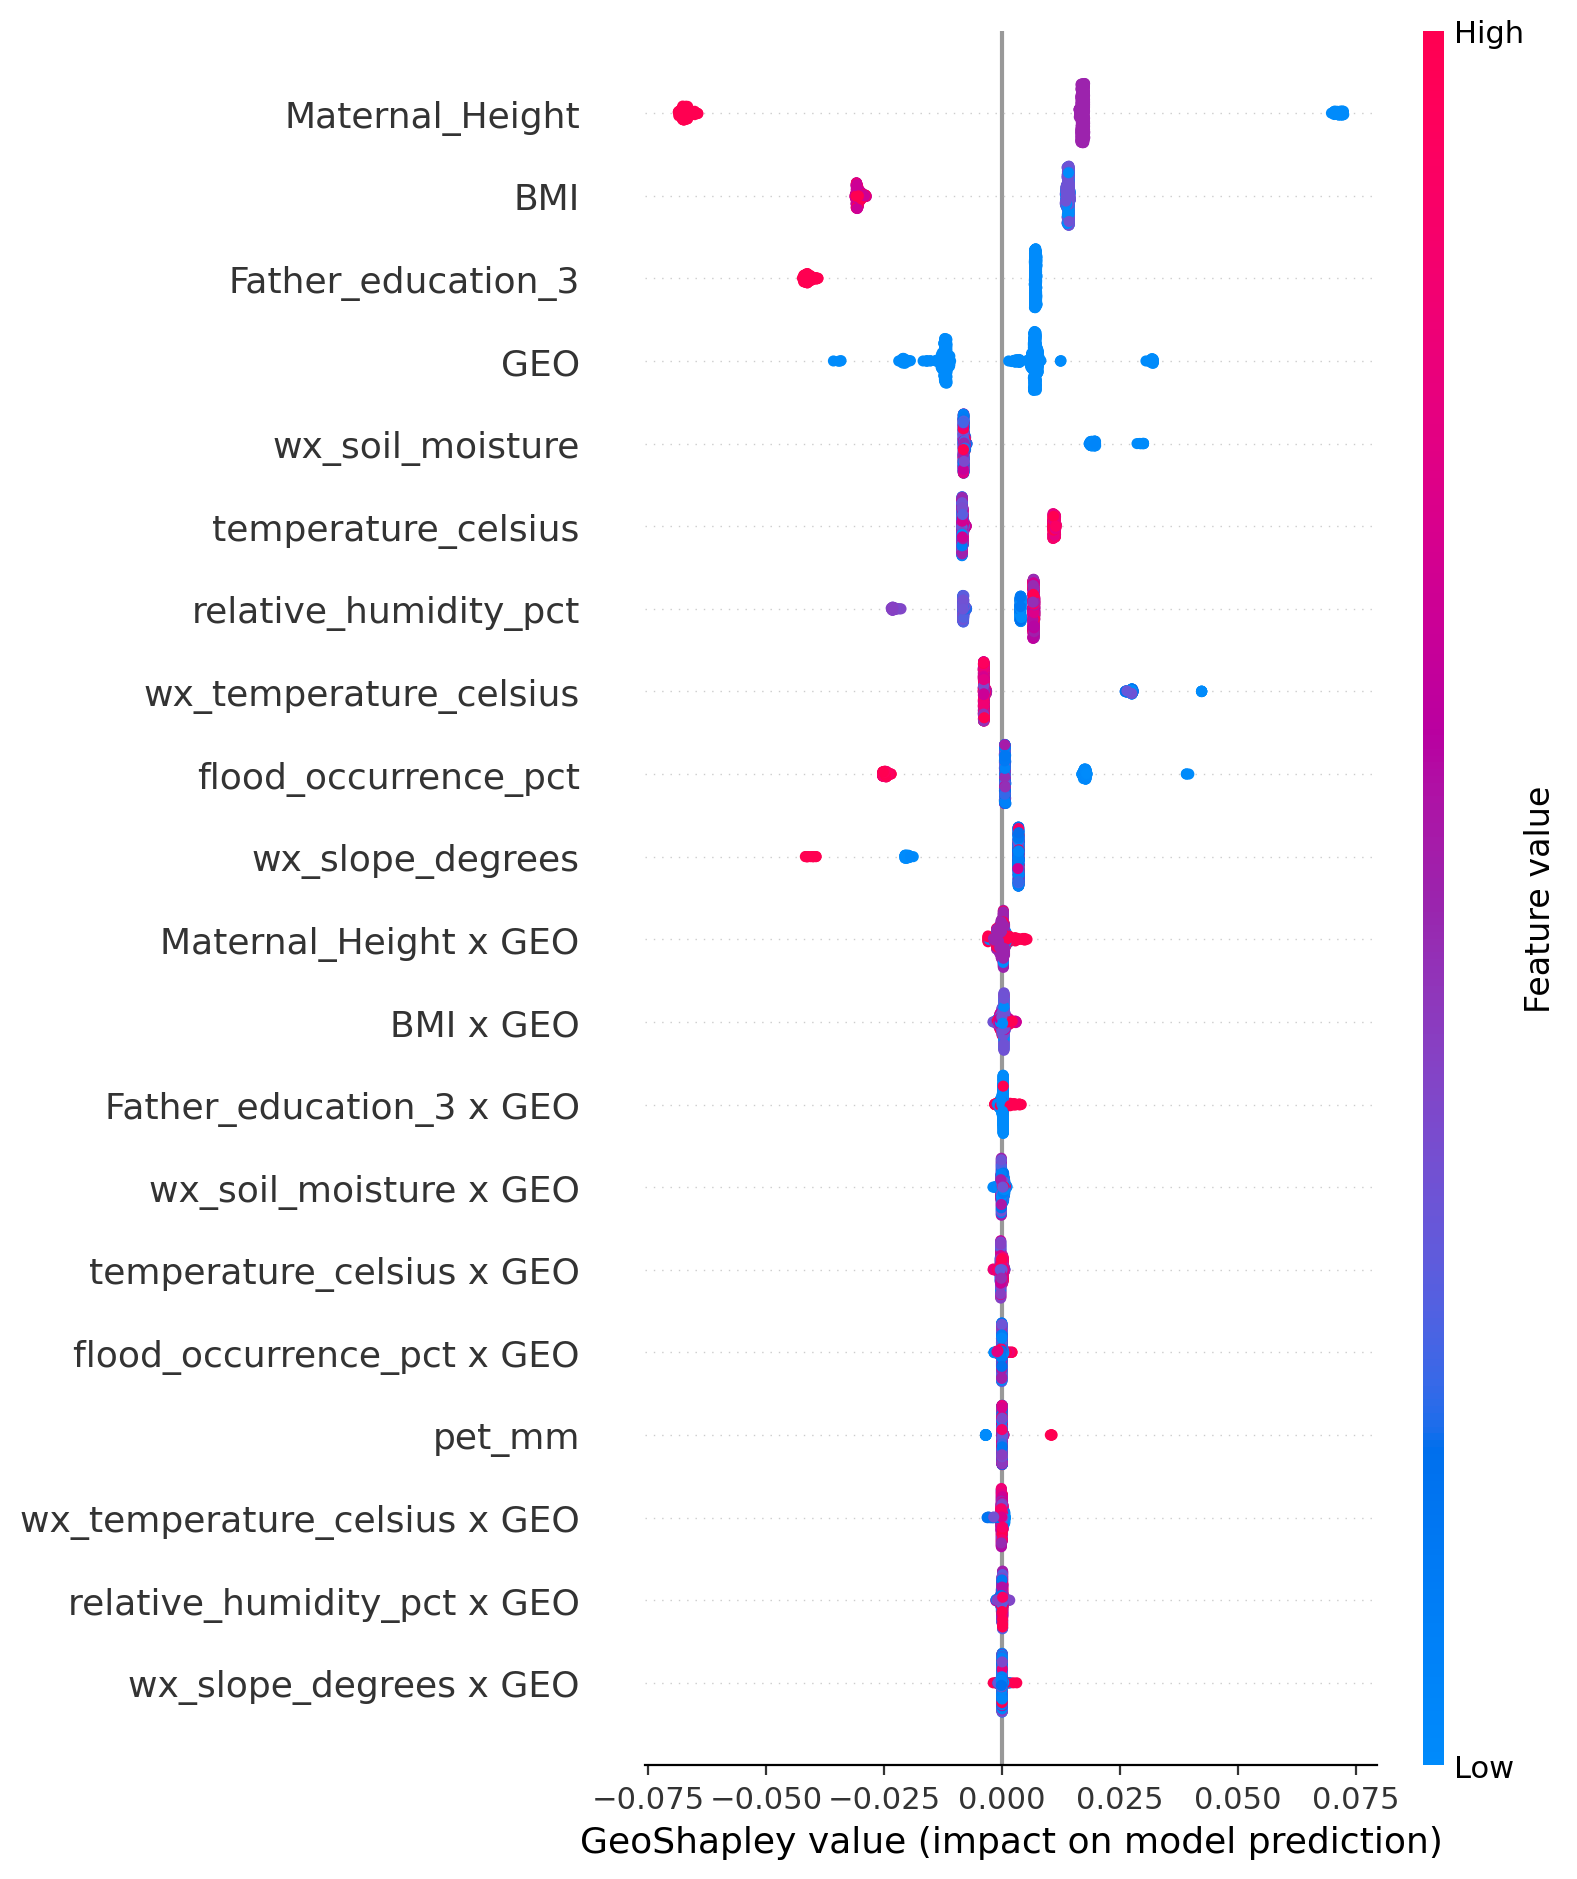

In [57]:
# ==========================================================
# Step-36 : GeoShapley Summary Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY SUMMARY PLOT")
print("=" * 70)

geo_results.summary_plot()

GEOSHAPLEY CONTRIBUTION BAR PLOT


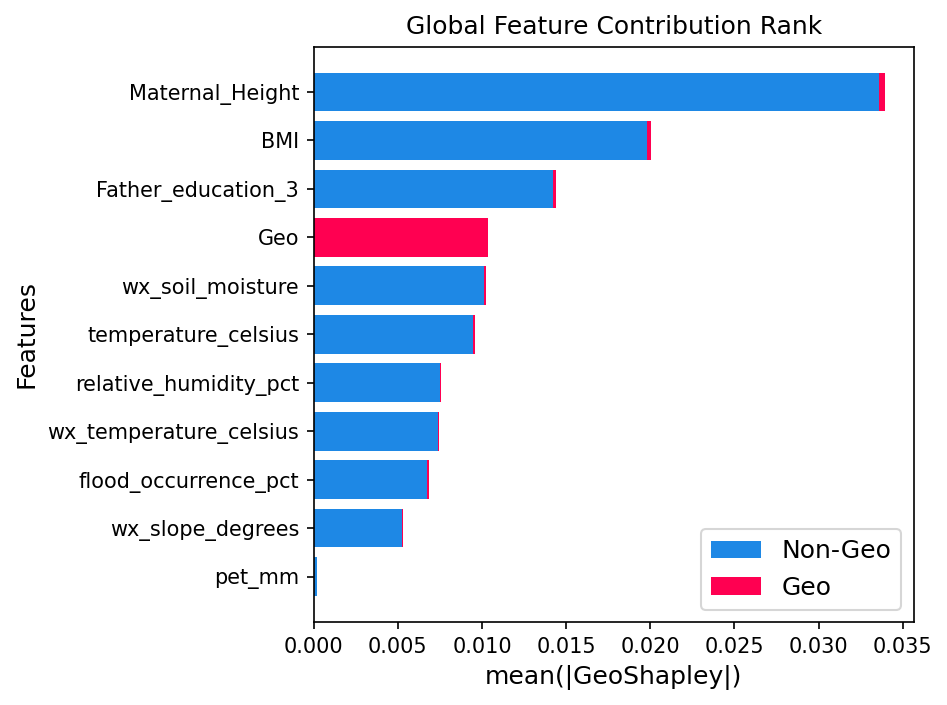

In [58]:
# ==========================================================
# Step-37 : GeoShapley Ranked Contribution Bar Plot
# ==========================================================

print("=" * 70)
print("GEOSHAPLEY CONTRIBUTION BAR PLOT")
print("=" * 70)

geo_results.contribution_bar_plot()

STEP-38 : DEPENDENCE / ICE DIAGNOSTICS
Highly correlated explanatory features:


,Feature_1,Feature_2,Pearson_r
0,wx_temperature_celsius,pet_mm,0.825
1,wx_temperature_celsius,temperature_celsius,0.967
2,pet_mm,temperature_celsius,0.816


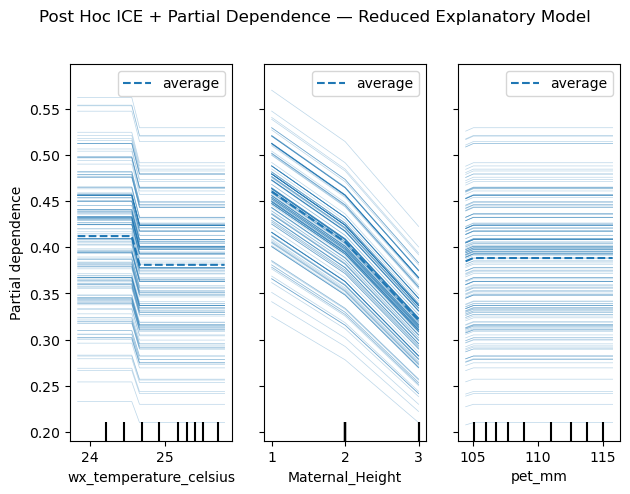


LIMITATION:
PDP/ICE are post hoc descriptive diagnostics. Strongly correlated or geographically constrained predictors may produce unrealistic marginal combinations. No causal interpretation is made.


In [59]:
# ==========================================================
# Step-38 : Post Hoc Dependence / ICE Diagnostics
# ==========================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.inspection import (
    PartialDependenceDisplay
)


print("=" * 78)

print(
    "STEP-38 : DEPENDENCE / ICE "
    "DIAGNOSTICS"
)

print("=" * 78)


noncoord_geo_features = [

    f

    for f
    in geo_feature_list

    if f not in
    coord_cols

]


correlation_matrix_geo = (

    X_train_geo[
        noncoord_geo_features
    ]

    .corr(
        numeric_only=True
    )

)


high_corr_pairs = []


for i, a in enumerate(

    correlation_matrix_geo.columns

):

    for j in range(

        i + 1,

        len(
            correlation_matrix_geo.columns
        )

    ):

        b = (

            correlation_matrix_geo
            .columns[j]

        )


        r = (

            correlation_matrix_geo
            .loc[
                a,
                b
            ]

        )


        if (

            np.isfinite(
                r
            )

            and

            abs(r) >= 0.70

        ):

            high_corr_pairs.append({

                "Feature_1":
                    a,

                "Feature_2":
                    b,

                "Pearson_r":
                    float(r)

            })


high_corr_pairs_df = pd.DataFrame(
    high_corr_pairs
)


if len(
    high_corr_pairs_df
):

    print(
        "Highly correlated explanatory features:"
    )


    display(

        high_corr_pairs_df

        .round(3)

    )

else:

    print(
        "No |r| >= 0.70 pair."
    )


# ICE + PDP together

ice_features = (

    noncoord_geo_features[

        :
        min(
            3,
            len(
                noncoord_geo_features
            )
        )

    ]

)


if ice_features:

    PartialDependenceDisplay.from_estimator(

        reduced_geo_pipeline,

        X_train_geo,

        features=
            ice_features,

        kind=
            "both",

        subsample=
            min(
                200,
                len(
                    X_train_geo
                )
            ),

        grid_resolution=
            20,

        random_state=
            42

    )


    plt.suptitle(

        "Post Hoc ICE + Partial Dependence "
        "— Reduced Explanatory Model",

        y=1.02

    )


    plt.tight_layout()


    plt.savefig(

        OUTPUT_DIR
        /
        "geoshapley_reduced_model_ICE_PDP.png",

        dpi=300,

        bbox_inches="tight"

    )


    plt.savefig(

        OUTPUT_DIR
        /
        "geoshapley_reduced_model_ICE_PDP.pdf",

        bbox_inches="tight"

    )


    plt.show()


correlation_matrix_geo.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_feature_correlation_matrix.csv"

)


high_corr_pairs_df.to_csv(

    OUTPUT_DIR
    /
    "geoshapley_high_correlation_pairs.csv",

    index=False

)


print(
    "\nLIMITATION:"
)

print(
    "PDP/ICE are post hoc descriptive diagnostics. "
    "Strongly correlated or geographically constrained "
    "predictors may produce unrealistic marginal combinations. "
    "No causal interpretation is made."
)

In [62]:
# ==========================================================
# Step-39 : Spatially Varying Coefficients (SVC)
#           Top GeoShapley Features
# ==========================================================

import numpy as np
import pandas as pd


print("=" * 70)
print("SPATIALLY VARYING COEFFICIENTS (TOP FEATURES)")
print("=" * 70)


# ==========================================================
# 1. IDENTIFY NON-COORDINATE TOP FEATURES
# ==========================================================

svc_features = [
    f
    for f in top_features
    if f not in coord_cols
]


feature_names_geo = list(
    X_geo_sample.columns[
        :-len(coord_cols)
    ]
)


if len(svc_features) == 0:
    raise RuntimeError(
        "No non-coordinate GeoShapley features "
        "are available for SVC calculation."
    )


missing_svc_features = [
    feature
    for feature in svc_features
    if feature not in feature_names_geo
]


if missing_svc_features:
    raise RuntimeError(
        "SVC feature(s) not found in "
        "GeoShapley feature matrix: "
        f"{missing_svc_features}"
    )


print("Computing SVC for features:")
print(svc_features)


# ==========================================================
# 2. OBTAIN CHILD-LEVEL SVC VALUES
# ==========================================================

svc_dict = {}


for feat in svc_features:

    idx = feature_names_geo.index(
        feat
    )

    svc_values = geo_results.get_svc(
        [idx],
        coef_type="gwr"
    )

    svc_values = np.asarray(
        svc_values,
        dtype=float
    ).ravel()


    if len(svc_values) != len(X_geo_sample):

        raise RuntimeError(
            "SVC length mismatch "
            f"for feature: {feat}"
        )


    svc_dict[feat] = svc_values


# ==========================================================
# 3. ALIGNMENT AUDIT
# ==========================================================

if not (
    len(X_geo_sample)
    ==
    len(cluster_ids_sample)
    ==
    len(real_coords_sample)
    ==
    len(weights_test)
):

    raise RuntimeError(
        "GeoShapley rows, DHS clusters, "
        "coordinates, and survey weights "
        "are not aligned."
    )


print(
    "\nGeoShapley observations:",
    len(X_geo_sample)
)

print(
    "DHS cluster IDs:",
    len(cluster_ids_sample)
)

print(
    "Survey weights:",
    len(weights_test)
)


# ==========================================================
# 4. CHILD-LEVEL SVC TABLE
# ==========================================================

cluster_geo_child = pd.DataFrame({

    "dhsclust":
        np.asarray(
            cluster_ids_sample
        ),

    "lat":
        real_coords_sample[
            "real_lat"
        ].to_numpy(
            dtype=float
        ),

    "lon":
        real_coords_sample[
            "real_lon"
        ].to_numpy(
            dtype=float
        ),

    "survey_weight":
        np.asarray(
            weights_test,
            dtype=float
        )
})


for feat in svc_features:

    cluster_geo_child[
        feat
    ] = svc_dict[
        feat
    ]


# ==========================================================
# 5. BASIC CHILD-LEVEL AUDIT
# ==========================================================

if (
    cluster_geo_child[
        ["lat", "lon"]
    ]
    .isna()
    .any()
    .any()
):

    raise RuntimeError(
        "Missing GeoShapley coordinates detected."
    )


if (
    cluster_geo_child[
        "survey_weight"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Missing survey weights detected "
        "in GeoShapley sample."
    )


if (
    cluster_geo_child[
        "survey_weight"
    ]
    <= 0
).any():

    raise RuntimeError(
        "Non-positive survey weights detected "
        "in GeoShapley sample."
    )


# ==========================================================
# 6. SAFE SURVEY-WEIGHTED MEAN
# ==========================================================

def weighted_mean_safe(
    values,
    weights
):

    values = np.asarray(
        values,
        dtype=float
    )

    weights = np.asarray(
        weights,
        dtype=float
    )


    valid = (
        np.isfinite(values)
        &
        np.isfinite(weights)
        &
        (weights > 0)
    )


    if not np.any(valid):
        return np.nan


    return float(
        np.average(
            values[valid],
            weights=weights[valid]
        )
    )


# ==========================================================
# 7. SURVEY-WEIGHTED DHS-CLUSTER AGGREGATION
# ==========================================================

cluster_rows = []


for cluster_id, group in (
    cluster_geo_child
    .groupby(
        "dhsclust",
        sort=False
    )
):


    # ------------------------------------------------------
    # GPS coordinate consistency check
    # ------------------------------------------------------

    coordinate_pairs = (
        group[
            ["lat", "lon"]
        ]
        .drop_duplicates()
    )


    if len(coordinate_pairs) != 1:

        raise RuntimeError(
            "More than one coordinate pair found "
            "within DHS cluster "
            f"{cluster_id}."
        )


    # ------------------------------------------------------
    # Cluster-level row
    # ------------------------------------------------------

    row = {

        "dhsclust":
            cluster_id,

        "lat":
            float(
                group[
                    "lat"
                ].iloc[0]
            ),

        "lon":
            float(
                group[
                    "lon"
                ].iloc[0]
            ),

        "n_children":
            int(
                len(group)
            ),

        "cluster_survey_weight":
            float(
                np.sum(
                    group[
                        "survey_weight"
                    ].to_numpy(
                        dtype=float
                    )
                )
            )
    }


    # ------------------------------------------------------
    # Survey-weighted SVC mean
    # ------------------------------------------------------

    for feat in svc_features:

        row[feat] = weighted_mean_safe(

            group[
                feat
            ].to_numpy(
                dtype=float
            ),

            group[
                "survey_weight"
            ].to_numpy(
                dtype=float
            )
        )


    cluster_rows.append(
        row
    )


cluster_geo = pd.DataFrame(
    cluster_rows
)


# ==========================================================
# 8. FINAL CLUSTER-LEVEL AUDIT
# ==========================================================

if (
    cluster_geo[
        "dhsclust"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate DHS clusters remain "
        "after SVC aggregation."
    )


if (
    cluster_geo[
        svc_features
    ]
    .isna()
    .all(
        axis=1
    )
    .any()
):

    raise RuntimeError(
        "At least one DHS cluster has "
        "no valid SVC values."
    )


# ==========================================================
# 9. SUMMARY
# ==========================================================

print(
    "\nCluster-level SVC table:"
)

display(
    cluster_geo.head()
)


print(
    "\nChild-level GeoShapley rows:",
    len(
        cluster_geo_child
    )
)


print(
    "Unique DHS clusters:",
    cluster_geo[
        "dhsclust"
    ].nunique()
)


print(
    "Cluster-level rows:",
    len(
        cluster_geo
    )
)


print(
    "\nChildren per DHS cluster:"
)

display(
    cluster_geo[
        "n_children"
    ].describe()
)


print(
    "\nCluster survey-weight summary:"
)

display(
    cluster_geo[
        "cluster_survey_weight"
    ].describe()
)


print(
    "\nCoordinate summary:"
)

display(
    cluster_geo[
        ["lat", "lon"]
    ].describe()
)


# ==========================================================
# 10. FINAL AUDIT MESSAGE
# ==========================================================

print(
    "\n✓ Same GeoShapley SVC framework retained."
)

print(
    "✓ Same GeoShapley child-level SVC values retained."
)

print(
    "✓ No model retraining or feature-selection "
    "change was made."
)

print(
    "✓ Child-level SVC values were aggregated "
    "to DHS-cluster level using DHS survey weights."
)

print(
    "✓ One unique row now represents each "
    "DHS cluster."
)

# ==========================================================
# Reviewer SVC aggregation estimand + sensitivity
# ==========================================================

SVC_PRIMARY_ESTIMAND = (

    "Survey-weighted mean child-level GeoShapley-derived "
    "local SVC within each DHS cluster. Therefore the "
    "mapped quantity represents a weighted child-population "
    "average within the sampled cluster, not an equal-cluster "
    "estimand."

)


cluster_geo_equal = (

    cluster_geo_child

    .groupby(

        "dhsclust",

        as_index=False

    )

    [svc_features]

    .mean()

)


cluster_geo_compare = (

    cluster_geo[
        [
            "dhsclust"
        ]
        +
        svc_features
    ]

    .merge(

        cluster_geo_equal,

        on=
            "dhsclust",

        how=
            "left",

        suffixes=(

            "_survey_weighted",

            "_equal_child_weight"

        ),

        validate=
            "one_to_one"

    )

)


svc_aggregation_sensitivity_rows = []


for feat in svc_features:

    a = (

        cluster_geo_compare[

            f"{feat}_survey_weighted"

        ]

        .to_numpy(
            dtype=float
        )

    )


    b = (

        cluster_geo_compare[

            f"{feat}_equal_child_weight"

        ]

        .to_numpy(
            dtype=float
        )

    )


    valid = (

        np.isfinite(a)
        &
        np.isfinite(b)

    )


    corr = (

        np.corrcoef(

            a[
                valid
            ],

            b[
                valid
            ]

        )[0, 1]

        if valid.sum() > 2

        else np.nan

    )


    svc_aggregation_sensitivity_rows.append({

        "Feature":
            feat,

        "N_Clusters":
            int(
                valid.sum()
            ),

        "Correlation":

            float(corr)

            if np.isfinite(
                corr
            )

            else np.nan,

        "Mean_Absolute_Difference":

            float(

                np.mean(

                    np.abs(

                        a[
                            valid
                        ]

                        -

                        b[
                            valid
                        ]

                    )

                )

            )

            if valid.any()

            else np.nan

    })


svc_aggregation_sensitivity_df = pd.DataFrame(

    svc_aggregation_sensitivity_rows

)


print(
    "\nPrimary SVC aggregation estimand:"
)

print(
    SVC_PRIMARY_ESTIMAND
)


print(
    "\nWeighted vs equal-child-weight sensitivity:"
)


display(

    svc_aggregation_sensitivity_df

    .round(4)

)


cluster_geo_compare.to_csv(

    OUTPUT_DIR
    /
    "svc_cluster_aggregation_comparison.csv",

    index=False

)


svc_aggregation_sensitivity_df.to_csv(

    OUTPUT_DIR
    /
    "svc_aggregation_sensitivity_summary.csv",

    index=False

)

SPATIALLY VARYING COEFFICIENTS (TOP FEATURES)
Computing SVC for features:
['wx_temperature_celsius', 'Maternal_Height', 'pet_mm', 'temperature_celsius', 'BMI', 'relative_humidity_pct', 'Father_education_3', 'wx_soil_moisture', 'wx_slope_degrees', 'flood_occurrence_pct']

GeoShapley observations: 716
DHS cluster IDs: 716
Survey weights: 716

Cluster-level SVC table:


,dhsclust,lat,lon,n_children,cluster_survey_weight,wx_temperature_celsius,Maternal_Height,pet_mm,temperature_celsius,BMI,relative_humidity_pct,Father_education_3,wx_soil_moisture,wx_slope_degrees,flood_occurrence_pct
0,3,22.713827,90.383011,4,0.633668,0.000087,-0.001484,0.000002,0.000032,-0.000406,0.000009,-0.000382,-0.002631,-0.000488,-0.000006
1,7,22.715451,90.361845,2,0.182650,0.000088,-0.001403,0.000002,0.000018,-0.000426,0.000002,-0.000356,-0.002765,-0.000377,-0.000005
2,11,22.720758,90.328569,6,0.567468,0.000092,-0.001060,0.000002,-0.000006,-0.000481,-0.000009,-0.000289,-0.003175,-0.000235,-0.000003
3,19,22.986983,90.160907,3,1.038723,0.000038,-0.000278,0.000002,0.000038,-0.000098,-0.000188,-0.000147,0.003960,-0.000088,0.000006
4,25,21.985376,90.077147,3,2.119488,0.000083,-0.001270,0.000002,0.000113,-0.000455,0.000032,-0.001149,0.000071,0.002266,-0.000005



Child-level GeoShapley rows: 716
Unique DHS clusters: 134
Cluster-level rows: 134

Children per DHS cluster:


count    134.000000
mean       5.343284
std        2.595845
min        1.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       15.000000
Name: n_children, dtype: float64


Cluster survey-weight summary:


count    134.000000
mean       5.433036
std        3.780501
min        0.182650
25%        2.904400
50%        4.398657
75%        7.307841
max       17.457710
Name: cluster_survey_weight, dtype: float64


Coordinate summary:


,lat,lon
count,134.000000,134.000000
mean,23.883056,90.299570
std,1.059929,1.019776
min,21.761719,88.287634
25%,22.974704,89.465655
50%,23.842481,90.305419
75%,24.727543,91.060123
max,26.270475,92.224194



✓ Same GeoShapley SVC framework retained.
✓ Same GeoShapley child-level SVC values retained.
✓ No model retraining or feature-selection change was made.
✓ Child-level SVC values were aggregated to DHS-cluster level using DHS survey weights.
✓ One unique row now represents each DHS cluster.

Primary SVC aggregation estimand:
Survey-weighted mean child-level GeoShapley-derived local SVC within each DHS cluster. Therefore the mapped quantity represents a weighted child-population average within the sampled cluster, not an equal-cluster estimand.

Weighted vs equal-child-weight sensitivity:


,Feature,N_Clusters,Correlation,Mean_Absolute_Difference
0,wx_temperature_celsius,134,1.0,0.0
1,Maternal_Height,134,1.0,0.0
2,pet_mm,134,1.0,0.0
3,temperature_celsius,134,1.0,0.0
4,BMI,134,1.0,0.0
5,relative_humidity_pct,134,1.0,0.0
6,Father_education_3,134,1.0,0.0
7,wx_soil_moisture,134,1.0,0.0
8,wx_slope_degrees,134,1.0,0.0
9,flood_occurrence_pct,134,1.0,0.0


GEOSHAPLEY-DERIVED SVC MAPS


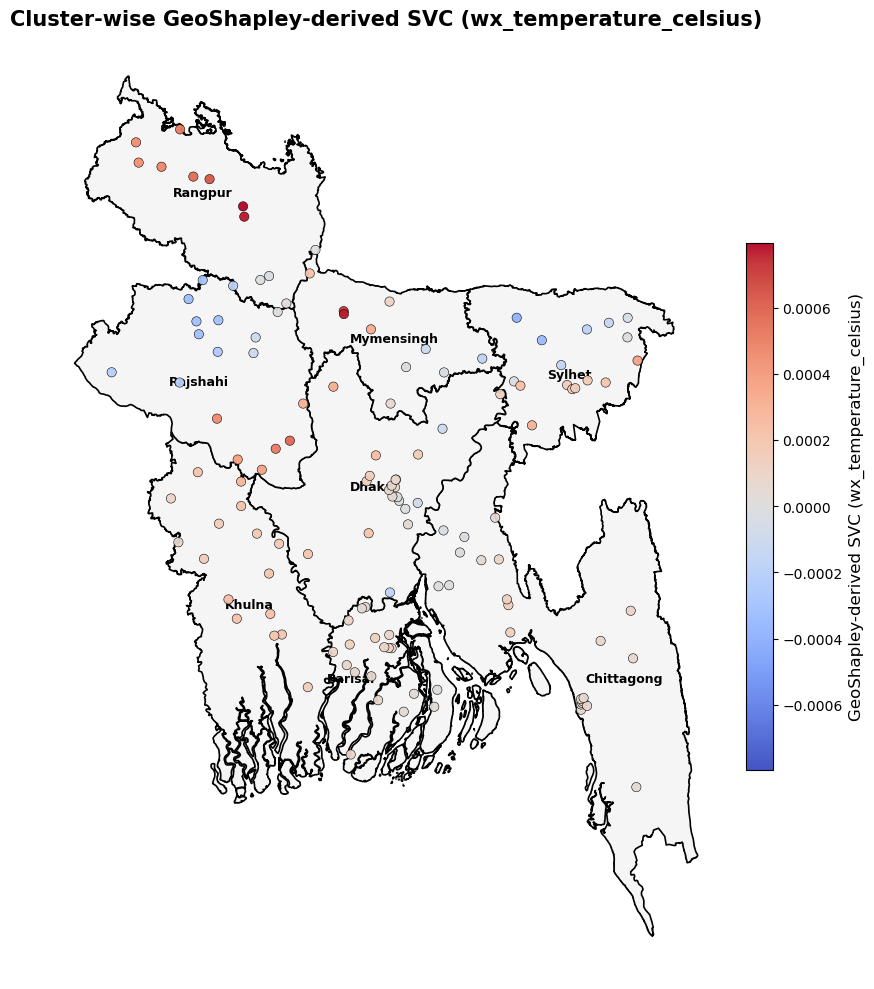

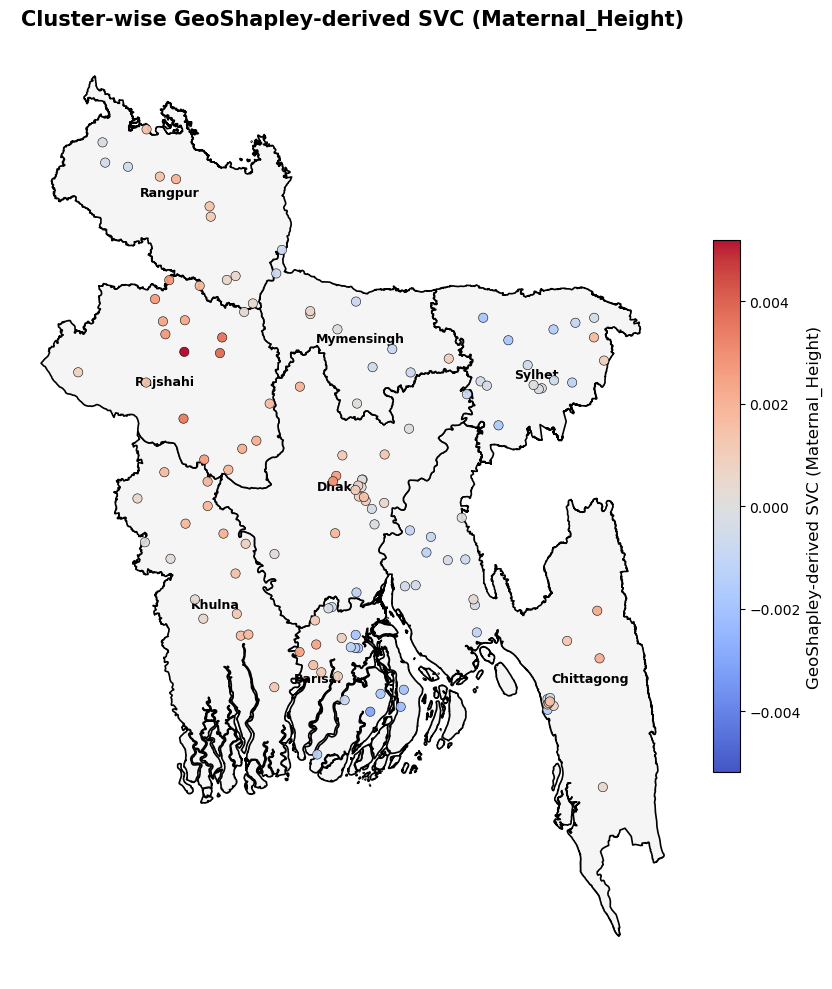

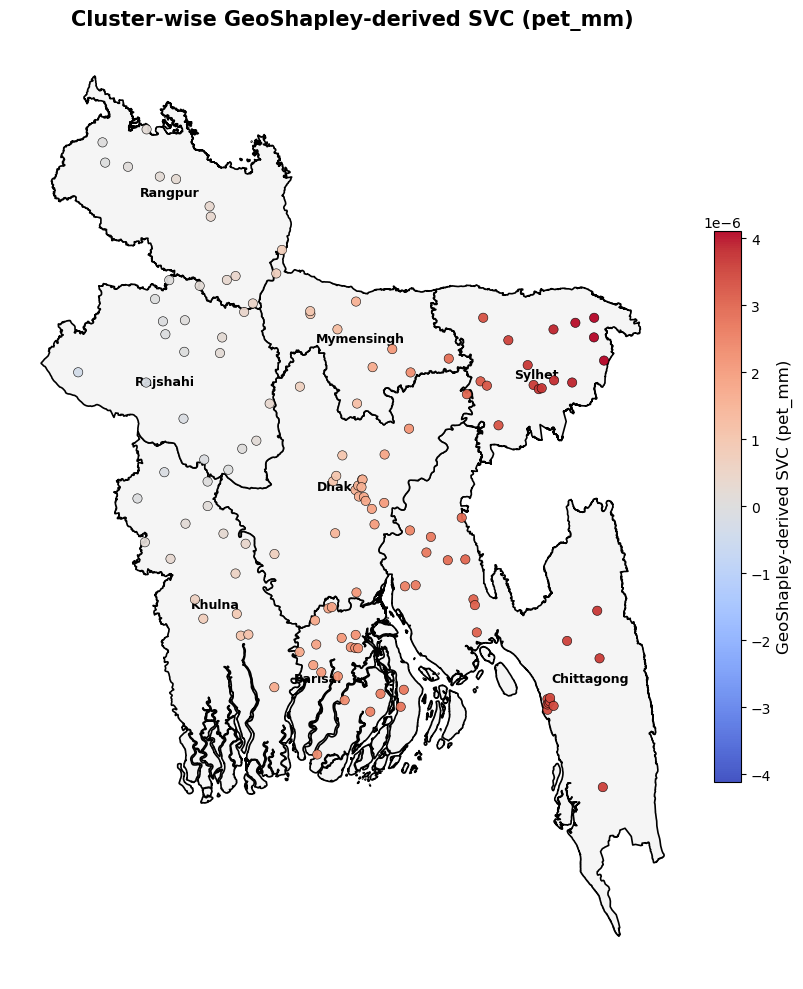

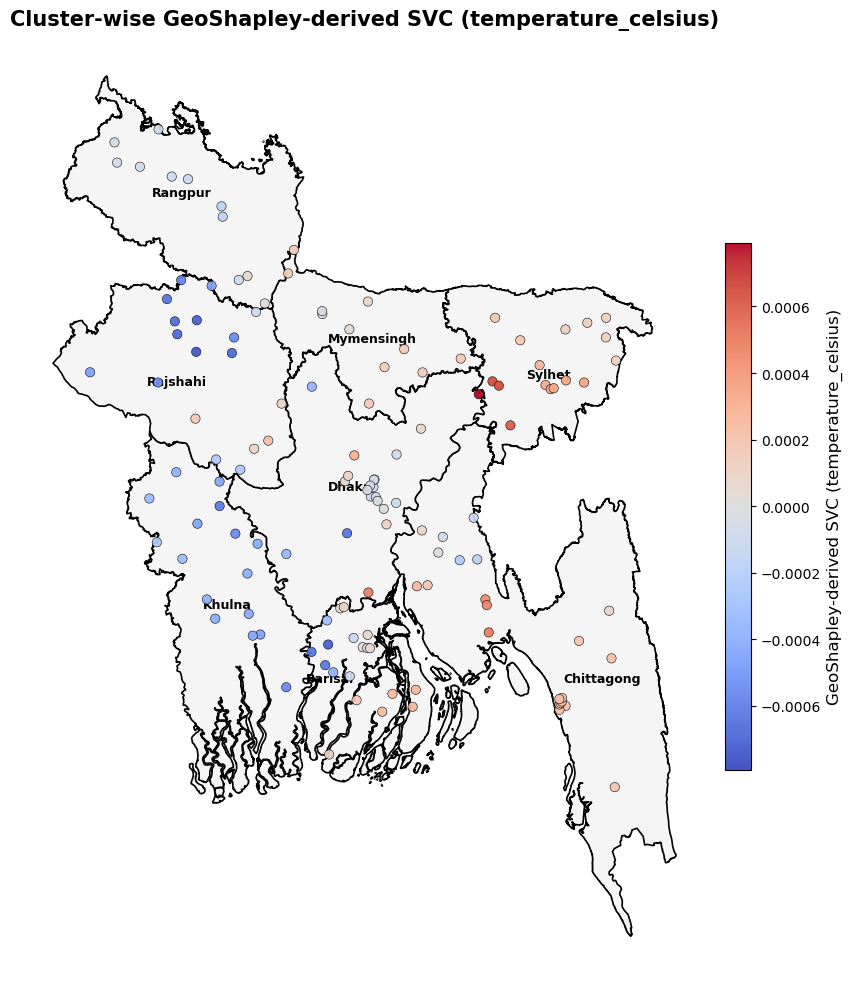

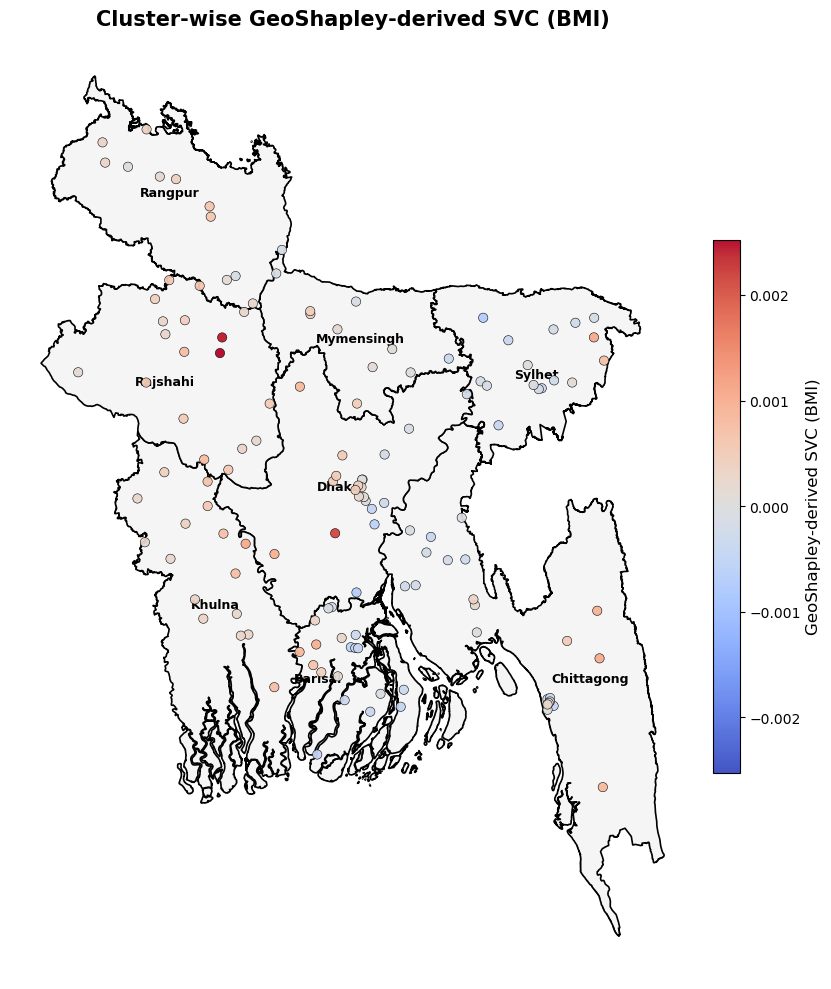

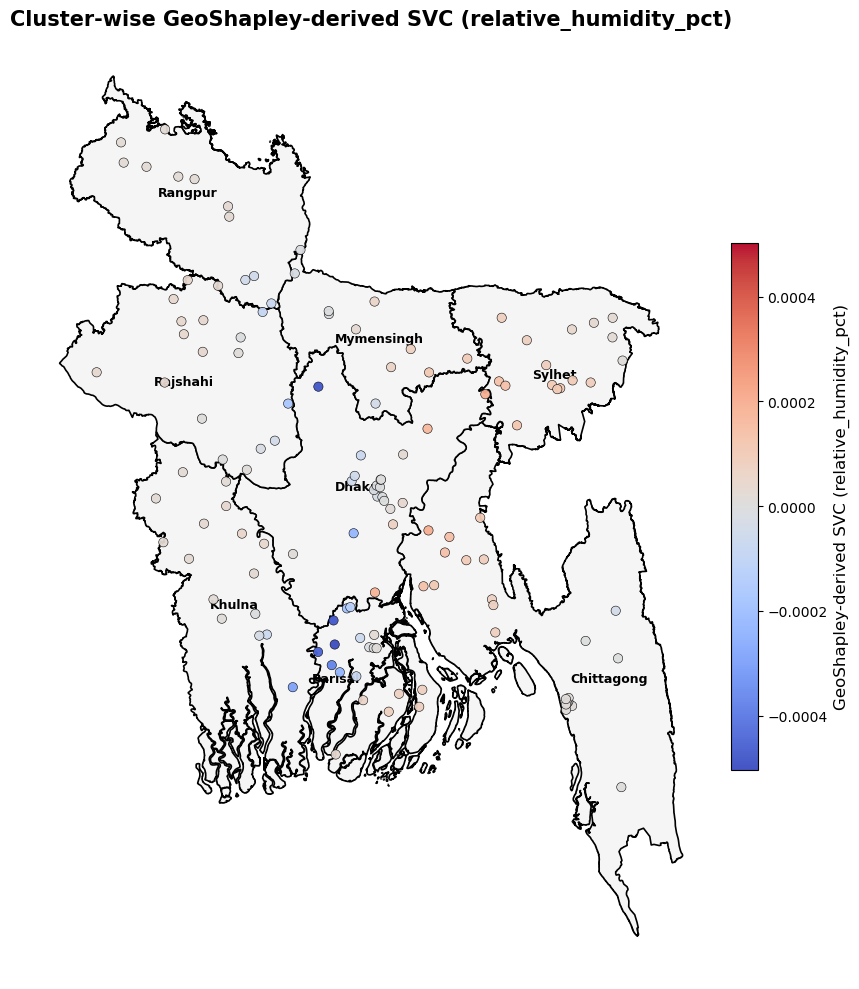

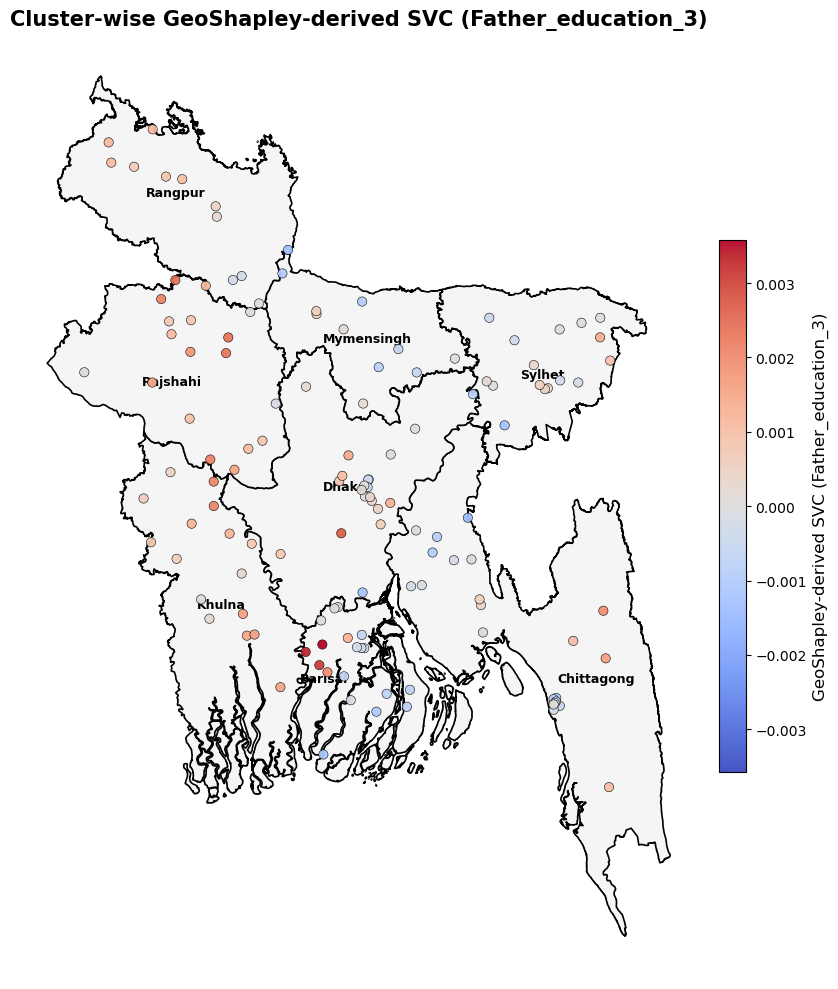

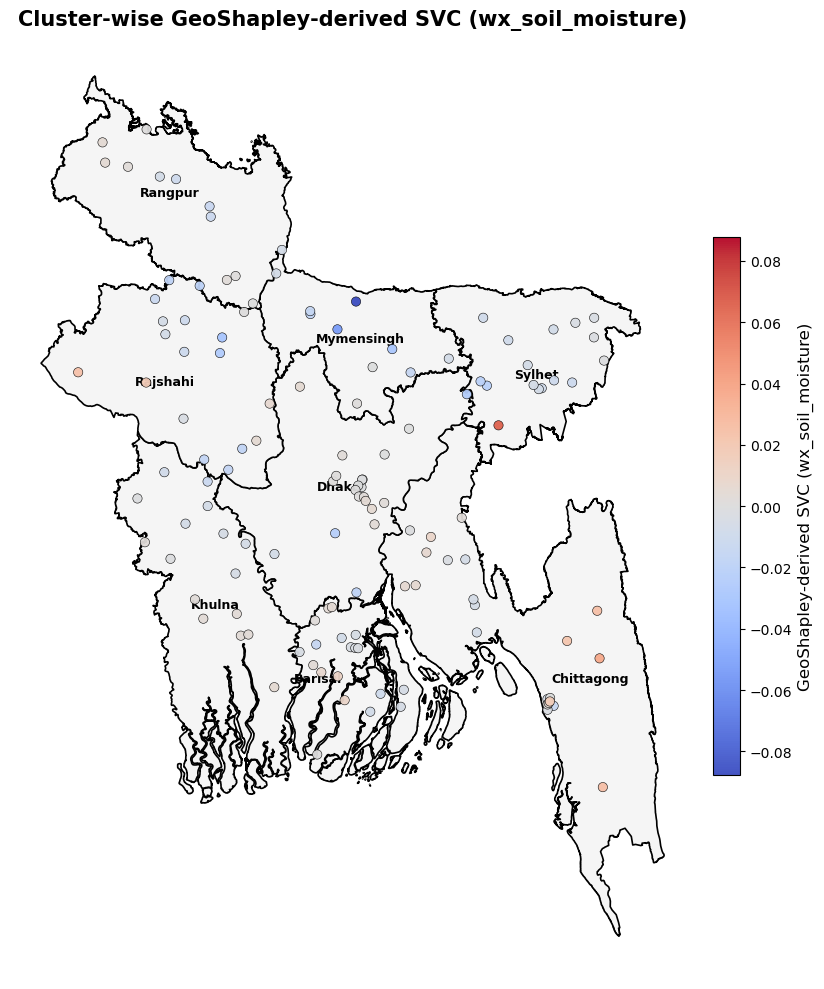

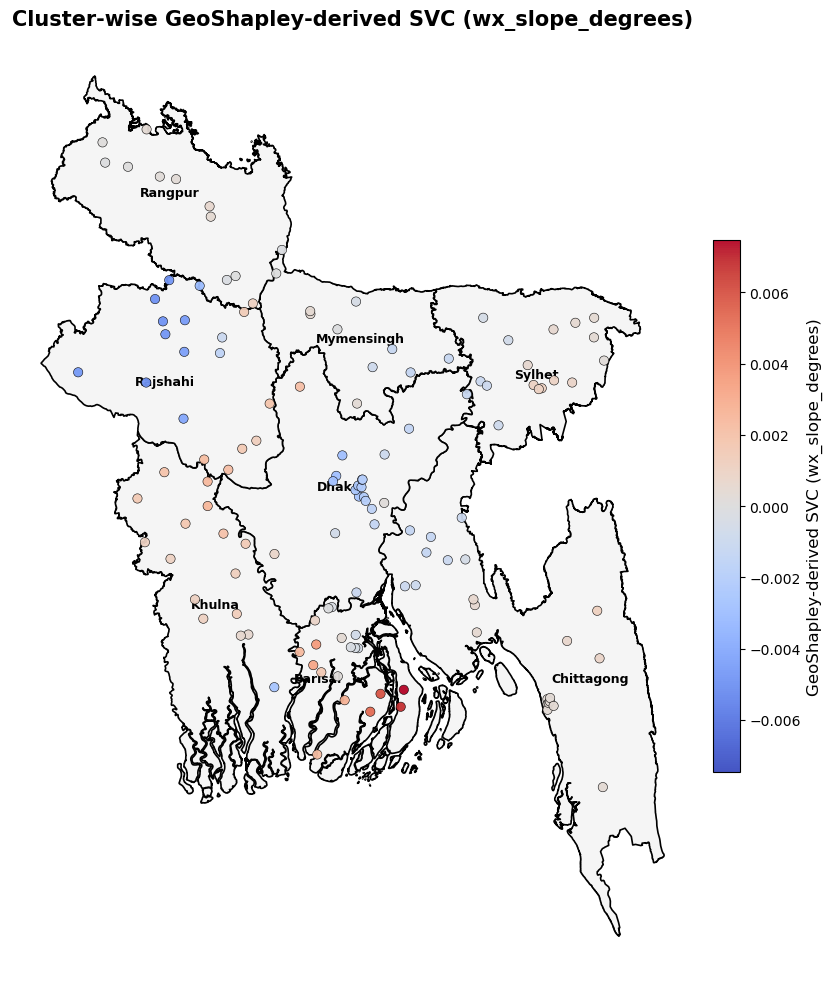

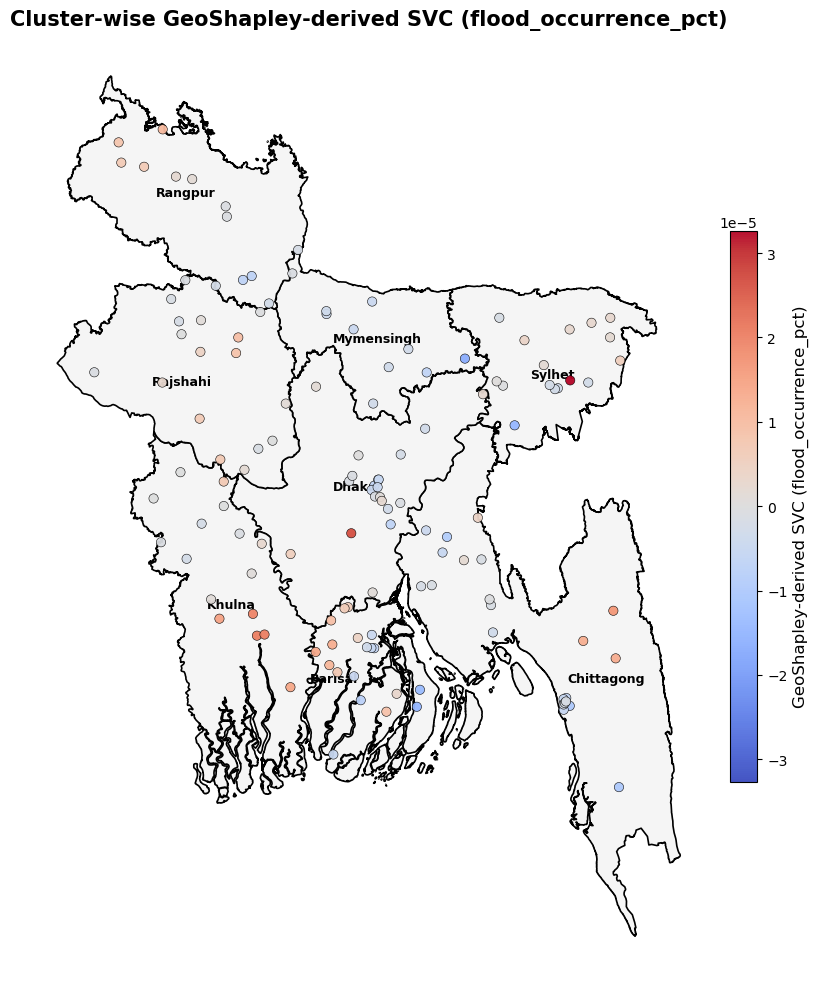


✓ Same GeoShapley SVC values are mapped; only plotting robustness and terminology were cleaned.


In [63]:
# ==========================================================
# Step-40 : Cluster-wise GeoShapley-Derived
#           Spatially Varying Coefficient (SVC) Maps
# ==========================================================

import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("GEOSHAPLEY-DERIVED SVC MAPS")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

DIVISION_BOUNDARY_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "gadm41_BGD_shp"
    / "gadm41_BGD_1.shp"
)

divisions = gpd.read_file(
    str(DIVISION_BOUNDARY_FILE)
)

if divisions.crs is None:

    divisions = divisions.set_crs(

        "EPSG:4326",

        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(

        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. ONE SVC MAP PER FEATURE
# ==========================================================

for best_feature in svc_features:

    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max <= 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    fig, ax = plt.subplots(
        figsize=(
            10,
            10
        )
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=1.2,

        zorder=1
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=45,

        edgecolor="black",

        linewidth=0.4,

        alpha=0.95,

        vmin=
            -abs_max,

        vmax=
            abs_max,

        zorder=3
    )


    cb = plt.colorbar(

        sc,

        ax=ax,

        fraction=0.03,

        pad=0.02
    )


    cb.set_label(

        "GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=12
    )


    for _, row in divisions.iterrows():

        label_point = (
            row.geometry
            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=9,

            fontweight="bold",

            zorder=2
        )


    ax.set_title(

        "Cluster-wise GeoShapley-derived SVC "
        f"({best_feature})",

        fontsize=15,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


    plt.tight_layout()


    safe_feature_name = (

        str(
            best_feature
        )

        .replace(
            "/",
            "_"
        )

        .replace(
            "\\",
            "_"
        )
    )


    plt.savefig(

        f"geoshapley_svc_map_"
        f"{safe_feature_name}.png",

        dpi=300,

        bbox_inches="tight"
    )


    plt.show()


print(
    "\n✓ Same GeoShapley SVC values are mapped; "
    "only plotting robustness and terminology "
    "were cleaned."
)

COMBINED GEOSHAPLEY-DERIVED SVC MAP
SVC features included: 10
Features: ['wx_temperature_celsius', 'Maternal_Height', 'pet_mm', 'temperature_celsius', 'BMI', 'relative_humidity_pct', 'Father_education_3', 'wx_soil_moisture', 'wx_slope_degrees', 'flood_occurrence_pct']
Figure layout: 4 rows × 3 columns


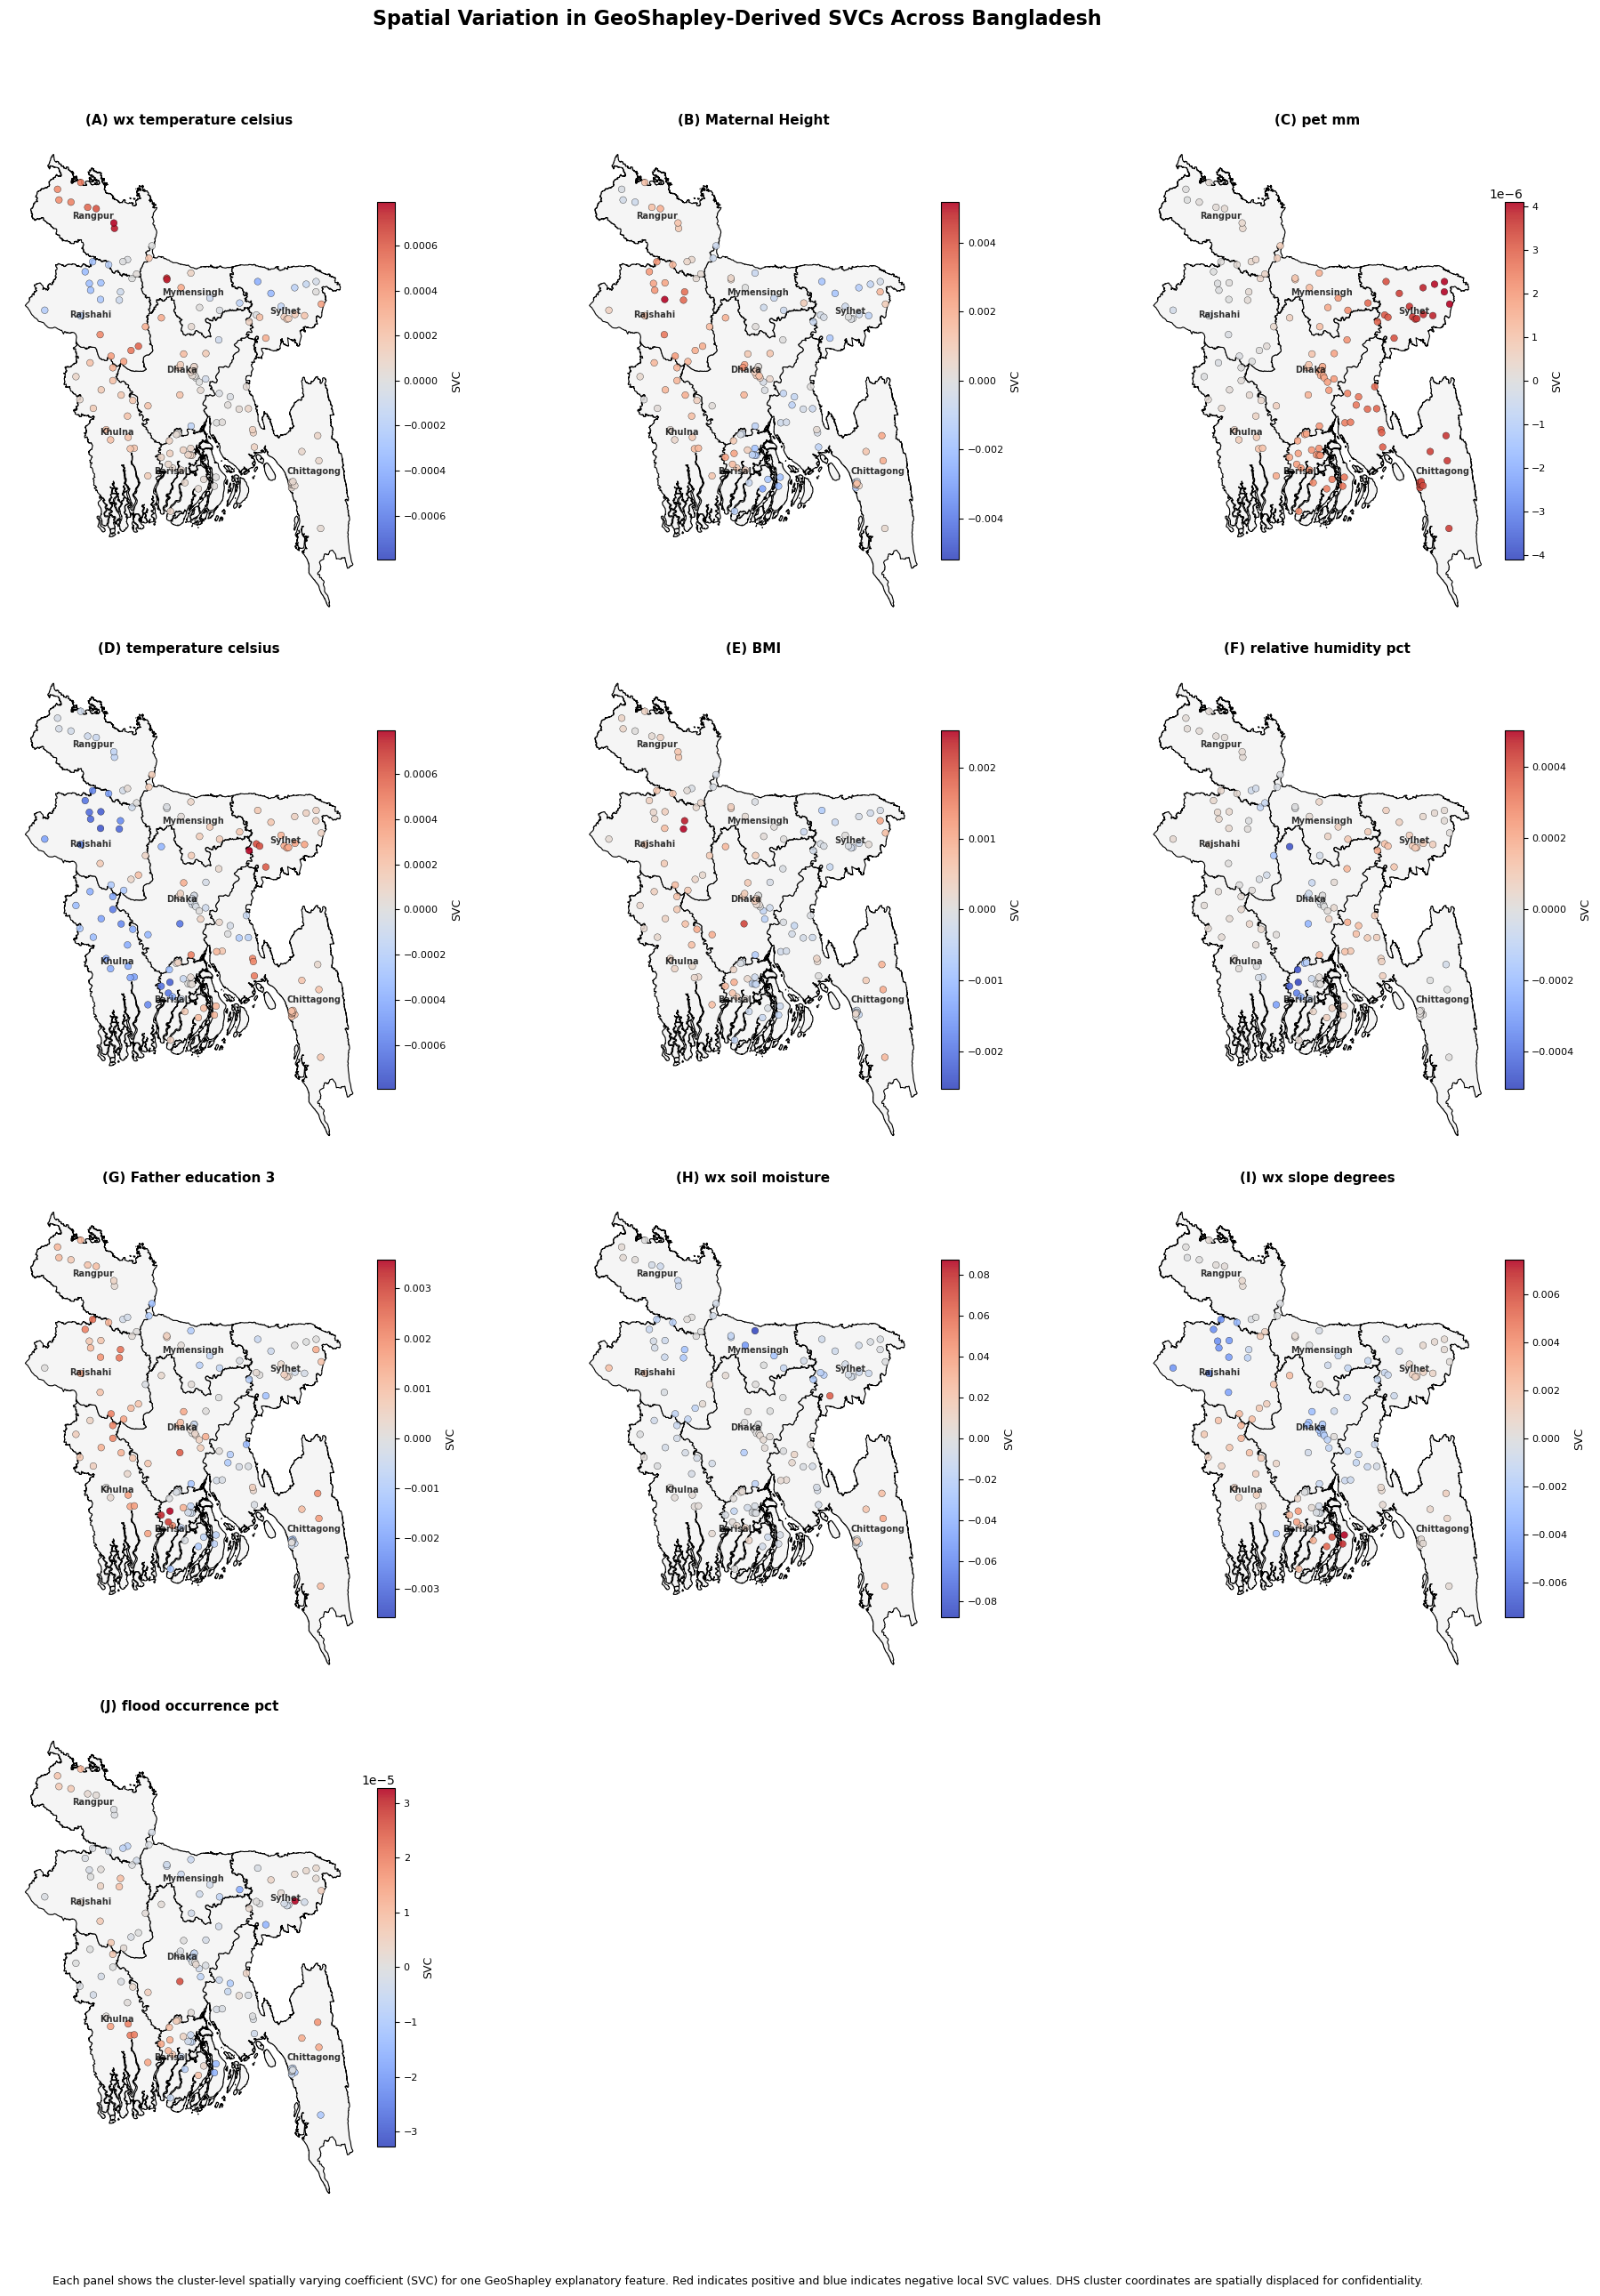


✓ All GeoShapley-derived SVC features are included.
✓ Only ONE combined map figure was generated.
✓ No SVC features were removed from the figure.
✓ Each feature retains its own symmetric SVC scale.
✓ Positive and negative SVC values remain visible.
✓ DHS displaced coordinates are interpreted only as cluster-level spatial approximations.

Saved figure:
geoshapley_combined_svc_map.png


In [64]:
# ==========================================================
# Step-41 : Combined GeoShapley-Derived SVC Map
#           ALL SVC FEATURES IN ONE FIGURE
# ==========================================================

import math
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt


print("=" * 70)
print("COMBINED GEOSHAPLEY-DERIVED SVC MAP")
print("=" * 70)


# ==========================================================
# 1. LOAD BANGLADESH DIVISION BOUNDARY
# ==========================================================

DIVISION_BOUNDARY_FILE = (
    PROJECT_ROOT
    / "GPS DATA"
    / "Division"
    / "gadm41_BGD_shp"
    / "gadm41_BGD_1.shp"
)

divisions = gpd.read_file(
    str(DIVISION_BOUNDARY_FILE)
)

if divisions.crs is None:

    divisions = divisions.set_crs(

        "EPSG:4326",

        allow_override=True
    )

else:

    divisions = divisions.to_crs(
        "EPSG:4326"
    )


name_col = "NAME_1"


if name_col not in divisions.columns:

    raise RuntimeError(

        "Division-name column not found: "
        f"{name_col}"
    )


# ==========================================================
# 2. FIGURE LAYOUT
# ==========================================================

n_features = len(
    svc_features
)


if n_features == 0:

    raise RuntimeError(
        "No SVC features are available for mapping."
    )


if n_features == 1:

    ncols = 1

elif n_features <= 4:

    ncols = 2

else:

    ncols = 3


nrows = math.ceil(

    n_features

    /

    ncols
)


print(
    "SVC features included:",
    n_features
)


print(
    "Features:",
    svc_features
)


print(
    "Figure layout:",
    f"{nrows} rows × {ncols} columns"
)


# ==========================================================
# 3. CREATE FIGURE
# ==========================================================

fig, axes = plt.subplots(

    nrows=nrows,

    ncols=ncols,

    figsize=(
        6.5 * ncols,
        6.5 * nrows
    )
)


axes = np.atleast_1d(
    axes
).ravel()


# ==========================================================
# 4. PLOT ALL SVC FEATURES
# ==========================================================

for panel_idx, best_feature in enumerate(
    svc_features
):

    ax = axes[
        panel_idx
    ]


    vals = (

        cluster_geo[
            best_feature
        ]

        .astype(
            float
        )

        .replace(
            [
                np.inf,
                -np.inf
            ],
            np.nan
        )
    )


    valid_vals = vals.dropna()


    if len(
        valid_vals
    ) == 0:

        abs_max = 1.0

    else:

        abs_max = max(

            abs(
                valid_vals.min()
            ),

            abs(
                valid_vals.max()
            )
        )


    if (
        not np.isfinite(
            abs_max
        )
        or
        abs_max == 0
    ):

        abs_max = 1.0


    cluster_geo_sorted = (

        cluster_geo

        .sort_values(
            by=best_feature
        )

        .copy()
    )


    divisions.plot(

        ax=ax,

        color="#f5f5f5",

        edgecolor="black",

        linewidth=0.8
    )


    sc = ax.scatter(

        cluster_geo_sorted[
            "lon"
        ],

        cluster_geo_sorted[
            "lat"
        ],

        c=
            cluster_geo_sorted[
                best_feature
            ],

        cmap="coolwarm",

        s=30,

        edgecolor="black",

        linewidth=0.25,

        alpha=0.9,

        vmin=
            -abs_max,

        vmax=
            abs_max
    )


    cb = fig.colorbar(

        sc,

        ax=ax,

        fraction=0.035,

        pad=0.015
    )


    cb.set_label(

        "SVC",

        fontsize=9
    )


    cb.ax.tick_params(
        labelsize=8
    )


    for _, row in divisions.iterrows():

        label_point = (

            row.geometry

            .representative_point()
        )


        ax.text(

            label_point.x,

            label_point.y,

            row[
                name_col
            ],

            ha="center",

            va="center",

            fontsize=7,

            fontweight="bold",

            alpha=0.8
        )


    panel_letter = chr(
        65 + panel_idx
    )


    clean_feature_name = (

        str(
            best_feature
        )

        .replace(
            "_",
            " "
        )
    )


    ax.set_title(

        f"({panel_letter}) "
        f"{clean_feature_name}",

        fontsize=11,

        fontweight="bold"
    )


    ax.set_xticks(
        []
    )

    ax.set_yticks(
        []
    )


    for spine in ax.spines.values():

        spine.set_visible(
            False
        )


# ==========================================================
# 5. REMOVE EMPTY PANELS
# ==========================================================

for empty_idx in range(

    n_features,

    len(
        axes
    )
):

    axes[
        empty_idx
    ].axis(
        "off"
    )


# ==========================================================
# 6. TITLE
# ==========================================================

fig.suptitle(

    "Spatial Variation in GeoShapley-Derived "
    "SVCs Across Bangladesh",

    fontsize=16,

    fontweight="bold",

    y=0.995
)


# ==========================================================
# 7. FIGURE NOTE
# ==========================================================

fig.text(

    0.5,

    0.01,

    (
        "Each panel shows the cluster-level "
        "spatially varying coefficient (SVC) "
        "for one GeoShapley explanatory feature. "
        "Red indicates positive and blue indicates "
        "negative local SVC values. DHS cluster "
        "coordinates are spatially displaced "
        "for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=9,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.035,
        1,
        0.97
    ]
)


plt.savefig(

    "geoshapley_combined_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 8. AUDIT
# ==========================================================

print(
    "\n✓ All GeoShapley-derived SVC "
    "features are included."
)

print(
    "✓ Only ONE combined map figure "
    "was generated."
)

print(
    "✓ No SVC features were removed "
    "from the figure."
)

print(
    "✓ Each feature retains its own "
    "symmetric SVC scale."
)

print(
    "✓ Positive and negative SVC values "
    "remain visible."
)

print(
    "✓ DHS displaced coordinates are "
    "interpreted only as cluster-level "
    "spatial approximations."
)

print(
    "\nSaved figure:"
)

print(
    "geoshapley_combined_svc_map.png"
)

ONE READABLE GEOSHAPLEY SVC MAP


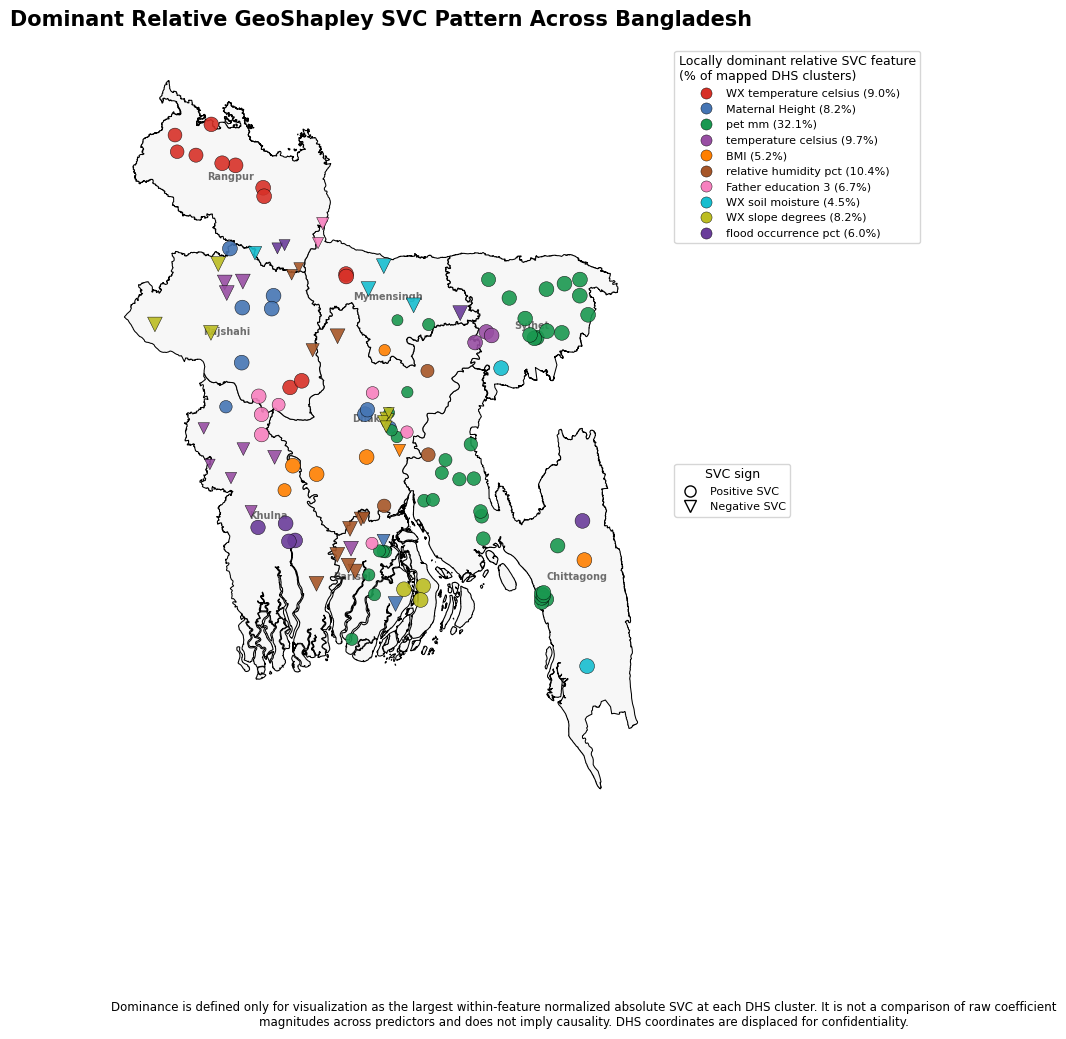


✓ Every SVC feature participates in the relative within-feature comparison.
✓ Raw SVC values are unchanged.
✓ One marker is plotted per DHS cluster.
✓ Map terminology describes a relative SVC pattern, not a causal effect or raw cross-feature ranking.

Saved figure:
geoshapley_dominant_relative_svc_map.png


In [65]:
# ==========================================================
# Step-42 : ONE READABLE GeoShapley Map
#           Dominant Relative GeoShapley SVC Pattern
#           by DHS Cluster
#
# ALL svc_features are included.
#
# Colour = locally dominant relative SVC feature
# Shape  = sign of raw SVC
# Size   = within-feature relative |SVC| strength
#
# IMPORTANT:
# This is a visualization summary.
# It is NOT a causal ranking and does NOT compare
# raw coefficient magnitudes across predictors.
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D


print("=" * 75)
print("ONE READABLE GEOSHAPLEY SVC MAP")
print("=" * 75)


# ==========================================================
# 1. CHECKS
# ==========================================================

if "svc_features" not in globals():

    raise RuntimeError(
        "svc_features not found. Run Step-39 first."
    )


if "cluster_geo" not in globals():

    raise RuntimeError(
        "cluster_geo not found. Run Step-39 first."
    )


if "divisions" not in globals():

    raise RuntimeError(
        "divisions not found. "
        "Run the SVC map step first."
    )


if len(
    svc_features
) == 0:

    raise RuntimeError(
        "No GeoShapley SVC features are available."
    )


for col in [
    "lon",
    "lat"
]:

    if col not in cluster_geo.columns:

        raise RuntimeError(
            f"Missing coordinate column: {col}"
        )


for feature in svc_features:

    if feature not in cluster_geo.columns:

        raise RuntimeError(
            "SVC feature missing from cluster_geo: "
            f"{feature}"
        )


# ==========================================================
# 2. FEATURE COLOURS
# ==========================================================

feature_colors = [

    "#D73027",
    "#4575B4",
    "#1A9850",
    "#984EA3",
    "#FF7F00",
    "#A65628",
    "#F781BF",
    "#17BECF",
    "#BCBD22",
    "#6A3D9A",
    "#1B9E77",
    "#E7298A",
    "#7570B3",
    "#66A61E"
]


if len(
    svc_features
) > len(
    feature_colors
):

    raise RuntimeError(
        "More SVC features than available colours."
    )


feature_color_map = {

    feature:
        feature_colors[
            i
        ]

    for i, feature
    in enumerate(
        svc_features
    )
}


# ==========================================================
# 3. RAW SVC MATRIX
# ==========================================================

svc_raw = (

    cluster_geo[
        svc_features
    ]

    .astype(
        float
    )

    .replace(
        [
            np.inf,
            -np.inf
        ],
        np.nan
    )
)


# ==========================================================
# 4. WITHIN-FEATURE RELATIVE STRENGTH
#
# |SVC| / 95th percentile |SVC|
#
# Capped at 1.
#
# This normalization is ONLY for map visualization.
# Raw SVC values remain unchanged.
# ==========================================================

relative_strength = pd.DataFrame(

    index=
        cluster_geo.index,

    columns=
        svc_features,

    dtype=float
)


feature_scale = {}


for feature in svc_features:

    abs_values = (

        svc_raw[
            feature
        ].abs()
    )


    valid_values = (

        abs_values[
            np.isfinite(
                abs_values
            )
        ]
    )


    if len(
        valid_values
    ) == 0:

        scale = 1.0

    else:

        scale = float(

            np.nanpercentile(
                valid_values,
                95
            )
        )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        if len(
            valid_values
        ) > 0:

            scale = float(

                np.nanmax(
                    valid_values
                )
            )


    if (
        not np.isfinite(
            scale
        )
        or
        scale <= 0
    ):

        scale = 1.0


    feature_scale[
        feature
    ] = scale


    relative_strength[
        feature
    ] = (

        abs_values

        /

        scale

    ).clip(
        lower=0,
        upper=1
    )


# ==========================================================
# 5. LOCALLY DOMINANT RELATIVE SVC FEATURE
# ==========================================================

valid_row = (

    relative_strength

    .notna()

    .any(
        axis=1
    )
)


dominant_feature = pd.Series(

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_feature.loc[
    valid_row
] = (

    relative_strength

    .loc[
        valid_row
    ]

    .idxmax(
        axis=1
    )
)


dominant_raw_svc = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


dominant_strength = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype=float
)


for idx in cluster_geo.index:

    feature = (
        dominant_feature.loc[
            idx
        ]
    )


    if pd.isna(
        feature
    ):

        continue


    dominant_raw_svc.loc[
        idx
    ] = (

        svc_raw.loc[
            idx,
            feature
        ]
    )


    dominant_strength.loc[
        idx
    ] = (

        relative_strength.loc[
            idx,
            feature
        ]
    )


dominant_direction = pd.Series(

    np.nan,

    index=
        cluster_geo.index,

    dtype="object"
)


dominant_direction.loc[
    dominant_raw_svc
    >=
    0
] = "Positive"


dominant_direction.loc[
    dominant_raw_svc
    <
    0
] = "Negative"


# ==========================================================
# 6. SAVE MAPPING VARIABLES
# ==========================================================

cluster_geo[
    "dominant_svc_feature"
] = dominant_feature


cluster_geo[
    "dominant_svc_value"
] = dominant_raw_svc


cluster_geo[
    "dominant_relative_strength"
] = dominant_strength


cluster_geo[
    "dominant_direction"
] = dominant_direction


marker_sizes = (

    24

    +

    90
    *
    dominant_strength
    .fillna(0)
    .to_numpy()
)


# ==========================================================
# 7. MAP
# ==========================================================

fig, ax = plt.subplots(

    figsize=(
        10,
        12
    )
)


divisions.plot(

    ax=ax,

    color="#F7F7F7",

    edgecolor="black",

    linewidth=0.75,

    zorder=1
)


for feature in svc_features:

    feature_color = (

        feature_color_map[
            feature
        ]
    )


    # Positive SVC
    mask_positive = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Positive"
        )
    )


    if (
        mask_positive.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_positive,
                "lon"
            ],

            cluster_geo.loc[
                mask_positive,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_positive.to_numpy()
                ],

            marker="o",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


    # Negative SVC
    mask_negative = (

        (
            dominant_feature
            ==
            feature
        )

        &

        (
            dominant_direction
            ==
            "Negative"
        )
    )


    if (
        mask_negative.sum()
        >
        0
    ):

        ax.scatter(

            cluster_geo.loc[
                mask_negative,
                "lon"
            ],

            cluster_geo.loc[
                mask_negative,
                "lat"
            ],

            s=
                marker_sizes[
                    mask_negative.to_numpy()
                ],

            marker="v",

            facecolor=
                feature_color,

            edgecolor="black",

            linewidth=0.35,

            alpha=0.9,

            zorder=4
        )


# ==========================================================
# 8. DIVISION LABELS
# ==========================================================

if "NAME_1" in divisions.columns:

    for _, row in divisions.iterrows():

        p = (
            row.geometry
            .representative_point()
        )


        ax.text(

            p.x,

            p.y,

            row[
                "NAME_1"
            ],

            fontsize=7,

            fontweight="bold",

            ha="center",

            va="center",

            color="#333333",

            alpha=0.7,

            zorder=2
        )


# ==========================================================
# 9. LEGENDS
# ==========================================================

def clean_feature_name(
    feature
):

    name = (

        str(
            feature
        )

        .replace(
            "_",
            " "
        )
    )


    if name.lower().startswith(
        "wx "
    ):

        name = (
            "WX "
            +
            name[3:]
        )


    return name


valid_dominant = (
    dominant_feature
    .dropna()
)


feature_percentages = (

    valid_dominant

    .value_counts(
        normalize=True
    )

    *
    100
)


feature_handles = []


for feature in svc_features:

    percentage = (

        feature_percentages

        .get(
            feature,
            0.0
        )
    )


    feature_handles.append(

        Line2D(

            [0],
            [0],

            marker="o",

            linestyle="None",

            markerfacecolor=
                feature_color_map[
                    feature
                ],

            markeredgecolor="black",

            markeredgewidth=0.3,

            markersize=8,

            label=(
                f"{clean_feature_name(feature)} "
                f"({percentage:.1f}%)"
            )
        )
    )


feature_legend = ax.legend(

    handles=
        feature_handles,

    title=(
        "Locally dominant relative SVC feature\n"
        "(% of mapped DHS clusters)"
    ),

    loc="upper left",

    bbox_to_anchor=(
        1.01,
        1.0
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


ax.add_artist(
    feature_legend
)


direction_handles = [

    Line2D(

        [0],
        [0],

        marker="o",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Positive SVC"
    ),

    Line2D(

        [0],
        [0],

        marker="v",

        linestyle="None",

        markerfacecolor="white",

        markeredgecolor="black",

        markersize=8,

        label="Negative SVC"
    )
]


ax.legend(

    handles=
        direction_handles,

    title=
        "SVC sign",

    loc=
        "upper left",

    bbox_to_anchor=(
        1.01,
        0.47
    ),

    frameon=True,

    fontsize=8,

    title_fontsize=9
)


# ==========================================================
# 10. FINAL STYLING
# ==========================================================

ax.set_title(

    "Dominant Relative GeoShapley SVC Pattern "
    "Across Bangladesh",

    fontsize=15,

    fontweight="bold",

    pad=14
)


ax.set_xticks(
    []
)

ax.set_yticks(
    []
)


for spine in ax.spines.values():

    spine.set_visible(
        False
    )


fig.text(

    0.5,

    0.02,

    (
        "Dominance is defined only for visualization "
        "as the largest within-feature normalized "
        "absolute SVC at each DHS cluster. It is not "
        "a comparison of raw coefficient magnitudes "
        "across predictors and does not imply causality. "
        "DHS coordinates are displaced for confidentiality."
    ),

    ha="center",

    va="bottom",

    fontsize=8.5,

    wrap=True
)


plt.tight_layout(

    rect=[
        0,
        0.06,
        0.80,
        1
    ]
)


plt.savefig(

    "geoshapley_dominant_relative_svc_map.png",

    dpi=300,

    bbox_inches="tight"
)


plt.show()


# ==========================================================
# 11. AUDIT
# ==========================================================

print(
    "\n✓ Every SVC feature participates in "
    "the relative within-feature comparison."
)


print(
    "✓ Raw SVC values are unchanged."
)


print(
    "✓ One marker is plotted per DHS cluster."
)


print(
    "✓ Map terminology describes a relative "
    "SVC pattern, not a causal effect or raw "
    "cross-feature ranking."
)


print(
    "\nSaved figure:"
)


print(
    "geoshapley_dominant_relative_svc_map.png"
)

In [66]:
# ==========================================================
# FINAL MANUSCRIPT-SAFE INTERPRETATION
# ==========================================================

from pathlib import Path


_auc_row = (

    final_metric_ci_df

    .loc[

        final_metric_ci_df[
            "Metric"
        ]
        ==
        "AUC"

    ]

    .iloc[0]

)


_cal_int_row = (

    final_metric_ci_df

    .loc[

        final_metric_ci_df[
            "Metric"
        ]
        ==
        "Calibration_Intercept"

    ]

    .iloc[0]

)


_cal_slope_row = (

    final_metric_ci_df

    .loc[

        final_metric_ci_df[
            "Metric"
        ]
        ==
        "Calibration_Slope"

    ]

    .iloc[0]

)


final_interpretation_text = (

    "Held-out internal validation showed a "
    "survey-weighted ROC-AUC of "

    f"{float(_auc_row['Estimate']):.3f} "

    "(95% stratified cluster/PSU-bootstrap CI "

    f"{float(_auc_row['CI_Lower']):.3f}-"
    f"{float(_auc_row['CI_Upper']):.3f}). "

    "Calibration was evaluated separately using "
    "the calibration intercept and slope. "

    f"The intercept was "
    f"{float(_cal_int_row['Estimate']):.3f} "

    "and the slope was "

    f"{float(_cal_slope_row['Estimate']):.3f}. "

    "These findings represent internal predictive "
    "performance with uncertainty and should not "
    "be interpreted as evidence of external "
    "transportability, clinical utility, or "
    "deployment readiness. "

    "Residual-spatial, ablation, subgroup and "
    "GeoShapley analyses using the held-out test "
    "set are post hoc/exploratory and do not "
    "modify the locked predictive pipeline."

)


print("=" * 78)

print(
    "MANUSCRIPT-SAFE FINAL INTERPRETATION"
)

print("=" * 78)

print(
    final_interpretation_text
)


(
    Path(
        OUTPUT_DIR
    )
    /
    "manuscript_safe_final_interpretation.txt"

).write_text(

    final_interpretation_text,

    encoding=
        "utf-8"

)

MANUSCRIPT-SAFE FINAL INTERPRETATION
Held-out internal validation showed a survey-weighted ROC-AUC of 0.677 (95% stratified cluster/PSU-bootstrap CI 0.628-0.726). Calibration was evaluated separately using the calibration intercept and slope. The intercept was 0.466 and the slope was 1.266. These findings represent internal predictive performance with uncertainty and should not be interpreted as evidence of external transportability, clinical utility, or deployment readiness. Residual-spatial, ablation, subgroup and GeoShapley analyses using the held-out test set are post hoc/exploratory and do not modify the locked predictive pipeline.


607

In [67]:
check_names = [
    "missingness_variable_df",
    "missingness_by_variable_df",
    "missingness_group_comparison_df",
    "sample_flow_df",
    "analytic_sample_cluster_flow_df",
    "df_excluded_complete_case"
]

for name in check_names:
    print(name, "->", name in globals())

missingness_variable_df -> True
missingness_by_variable_df -> True
missingness_group_comparison_df -> True
sample_flow_df -> True
analytic_sample_cluster_flow_df -> False
df_excluded_complete_case -> True


SFS/AdaBoost — FINAL REVIEWER UPDATE

COMMENT 7 — EXACT SAMPLE ATTRITION RECONSTRUCTION
Raw source records: 4118
Valid HAZ records (-600 to +600): 4105
Prepared analytical records matched: 3633
Excluded before prepared analytical dataset: 472


,Exclusion_source,Flagged_N,Unique_additional_exclusions_N
0,Not a de jure resident (water/toilet code 97),406,406
1,Missing decision/partner-education variables,52,46
2,Missing maternal anthropometry,2,2
3,Don't-know/missing morbidity response,18,18
4,Total unique excluded,472,472


,Variable,Characteristic,Missing_or_invalid_definition,Missing_N_among_4105,Missing_percent_among_4105,Missing_N_in_included_3633,Missing_N_in_excluded_472
0,V113,Water source,Code 97: Not a de jure resident,406,9.890,0,406
1,V116,Toilet facility,Code 97: Not a de jure resident,406,9.890,0,406
2,V632,Decision maker for using contraception,System missing / blank,52,1.267,0,52
3,V701,Husband/partner education,System missing / blank,52,1.267,0,52
4,V743A,Decision maker for respondent health care,System missing / blank,52,1.267,0,52
5,V438,Maternal height,Special/missing anthropometry code,2,0.049,0,2
6,V445,Maternal BMI,System/special missing anthropometry,2,0.049,0,2
7,H11,Recent diarrhea,Code 8/9 or missing: Don't know/missing,5,0.122,0,5
8,H22,Recent fever,Code 8/9 or missing: Don't know/missing,7,0.171,0,7
9,H31,Recent cough,Code 8/9 or missing: Don't know/missing,8,0.195,0,8


,Stage,N
0,Source records,4118
1,Valid HAZ records (-600 to +600),4105
2,Final analytical records matched by CASEID + c...,3633
3,Excluded between valid HAZ and prepared analyt...,472



Included versus excluded comparison:


...


COMMENT 13 — GROUPED-SFS STABILITY


,Predictor_Group,Selected_Folds,Selection_Frequency
0,BMI,5,1.0
1,Maternal_Height,5,1.0
2,Mother_education,4,0.8
3,Multiple_birth_status,4,0.8
4,wx_lst_celsius,4,0.8
5,Child_age_months,3,0.6
6,Relationship_to_household_head,3,0.6
7,Short_rapid_breaths,3,0.6
8,temperature_celsius,3,0.6
9,wx_pop_density,3,0.6



Grouped-SFS Nogueira stability: 0.2381

COMMENT 20 — CALIBRATION UNCERTAINTY


,Metric,Estimate,CI_Lower,CI_Upper,Valid_Bootstrap_Replicates,Requested_Bootstrap_Replicates,Variance_Method
0,Calibration_Intercept,0.4659,-0.0757,1.0225,2000,2000,Stratified cluster/PSU bootstrap
1,Calibration_Slope,1.2663,0.8875,1.7378,2000,2000,Stratified cluster/PSU bootstrap


,Probability_Bin,N,Weighted_Mean_Predicted,Weighted_Observed_Risk,Survey_Weight_Sum
0,"(-0.001, 0.1]",90,0.0766,0.0924,86.7427
1,"(0.1, 0.2]",268,0.1543,0.1757,287.2036
2,"(0.2, 0.3]",259,0.2487,0.2403,266.1642
3,"(0.3, 0.4]",88,0.3330,0.4007,76.8691
4,"(0.4, 0.5]",11,0.4164,0.7836,11.0472


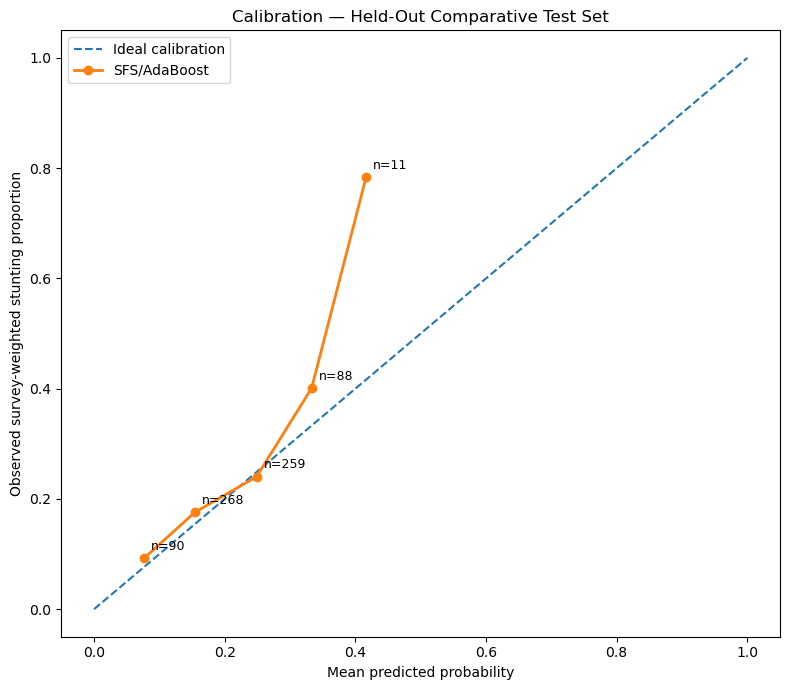


COMMENT 3 — SFS COMPARISON BUNDLE
Saved: F:\Thesis\Reviewer_Additional_Analyses\Comment3_SFS_AdaBoost_comparison_bundle.pkl

COMMENT 3 — THREE-PIPELINE PAIRED PSU BOOTSTRAP
✓ All three pipelines use the same held-out comparative test set.
N = 716
Unique PSUs = 134
Survey strata = 16


,Pipeline,Weighted_ROC_AUC
0,GB/CatBoost,0.663450
1,RFECV/CatBoost,0.648122
2,SFS/AdaBoost,0.677319


,Comparison,AUC_A,AUC_B,Delta_AUC_A_minus_B,CI_95_Lower,CI_95_Upper,Bootstrap_P_two_sided,Valid_Bootstrap_Reps,CI_Includes_Zero
0,SFS/AdaBoost vs GB/CatBoost,0.677319,0.663450,0.013869,-0.020189,0.048187,0.4328,5000,True
1,SFS/AdaBoost vs RFECV/CatBoost,0.677319,0.648122,0.029197,-0.022984,0.083337,0.2844,5000,True
2,GB/CatBoost vs RFECV/CatBoost,0.663450,0.648122,0.015328,-0.041249,0.068059,0.5948,5000,True



COMMENT 3 — INTERPRETATION
Numerically highest weighted ROC-AUC: SFS/AdaBoost (0.6773)

All paired 95% bootstrap CIs include zero.
Reviewer-safe conclusion:
SFS/AdaBoost achieved the numerically highest ROC-AUC on the held-out comparative test set, but was not demonstrably superior to the GB/CatBoost or RFECV/CatBoost pipelines.

SFS/AdaBoost REVIEWER UPDATE COMPLETE
✓ Comment 7: exact 472-case attrition reconstructed.
✓ Comment 12: complete classifier table exported.
✓ Comment 13: grouped-SFS stability exported.
✓ Comment 20: calibration intercept/slope CIs exported.
✓ Comment 25: calibration bin counts/figure exported.
✓ Comment 3: three-pipeline paired PSU-bootstrap completed.

No primary model was retrained by this reviewer cell.
Primary held-out comparative-test predictions therefore remain unchanged.


In [1]:

from pathlib import Path
import shutil

# Existing reviewer analysis folder
SOURCE = Path(r"F:\Thesis\Reviewer_Additional_Analyses")

# Final manuscript supplementary folder
DESTINATION = Path(r"F:\Thesis\Suplementary files")
DESTINATION.mkdir(parents=True, exist_ok=True)

# ONLY confirmed supplementary submission files
SUPPLEMENTARY_FILES = [
    "Supplementary_Table_S1_Final.xlsx",
]

copied = []
missing = []

for filename in SUPPLEMENTARY_FILES:
    src = SOURCE / filename
    dst = DESTINATION / filename

    if src.is_file():
        shutil.copy2(src, dst)
        copied.append(filename)
        print(f"COPIED: {filename}")
    else:
        missing.append(filename)
        print(f"NOT FOUND: {filename}")

print("\n--- Supplementary File Summary ---")
print("Copied:", len(copied))
print("Missing:", len(missing))
print("Location:", DESTINATION)

if missing:
    print("\nFiles requiring attention:")
    for filename in missing:
        print("-", filename)


COPIED: Supplementary_Table_S1_Final.xlsx

--- Supplementary File Summary ---
Copied: 1
Missing: 0
Location: F:\Thesis\Suplementary files
